In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
singlecol = 3.5
plt.rcParams.update({'font.size': 16})
#plt.rcParams.update({'font.sans-serif': 'Helvetica'})
plt.rcParams.update({'lines.linewidth':1.5})
plt.rcParams.update({'axes.linewidth':1})
plt.rcParams.update({'lines.markersize':7})
plt.rcParams.update({'savefig.dpi':200})
plt.rcParams.update({'legend.fontsize': 12})

In [2]:
def convert_dump_file(input_file, output_file, element_map):
    """
    Convert atom types to element names in a LAMMPS dump file.
    
    Parameters:
    input_file (str): Path to the original LAMMPS dump file
    output_file (str): Path to save the modified file
    element_map (dict): Dictionary mapping atom types to element names
    """
    with open(input_file, 'r') as infile, open(output_file, 'w') as outfile:
        in_atoms_section = False
        
        for line in infile:
            line = line.strip()
            
            # Check if we're starting the atoms section
            if line.startswith("ITEM: ATOMS"):
                in_atoms_section = True
                outfile.write(line + '\n')
                continue
            
            # Process atom lines when we're in the atoms section
            if in_atoms_section and not line.startswith("ITEM:"):
                parts = line.split()
                
                if len(parts) >= 2:  # Ensure we have at least atom ID and type
                    # Get the atom type (2nd column in your file)
                    atom_type = int(parts[1])
                    
                    # Replace type number with element name if in our map
                    if atom_type in element_map:
                        parts[1] = element_map[atom_type]
                    
                    # Write the modified line
                    outfile.write(' '.join(parts) + '\n')
                else:
                    # Just write the line unchanged if it doesn't match expected format
                    outfile.write(line + '\n')
            else:
                # If we encounter a new "ITEM:" line, we're leaving the atoms section
                if line.startswith("ITEM:") and not line.startswith("ITEM: ATOMS"):
                    in_atoms_section = False
                
                # Write all non-atom lines unchanged
                outfile.write(line + '\n')

In [3]:
import re

# Function to read and parse LAMMPS log
def parse_lammps_log_diff(file_path):
    data = {'Step': [], 'Temp': [], 'TotEng': [], 'Press': [], 'Volume': [], 'v_nNa': [], 'MSD(PB)' : [], 'MSD(Na)' : []}

    with open(file_path, 'r') as file:
        for line in file:
            # Find thermo output section
            if re.match(r"^\s*Step\s+Temp\s+TotEng", line):
                # Skip header lines
                next(file)
                # Parse the actual data lines
                for data_line in file:
                    if re.match(r"^\s*\d+", data_line) and len(data_line.split())==8:
                        # Extract values (Assuming specific columns order here)
                        values = data_line.split()
                        data['Step'].append(int(values[0]))
                        data['Temp'].append(float(values[1]))
                        data['TotEng'].append(float(values[2]))
                        data['Press'].append(float(values[3]))
                        data['Volume'].append(float(values[4]))
                        data['v_nNa'].append(float(values[5]))
                        data['MSD(PB)'].append(float(values[6]))
                        data['MSD(Na)'].append(float(values[7]))                    
                    else:
                        break
    return data

### parse_lammps_free

In [4]:
import re

# Function to read and parse LAMMPS log
def parse_lammps_free(file_path):
    data = {'Step': [], 'Temp': [], 'TotEng': [], 'Press': [], 'Volume': [], 'v_nNa': [], 'atoms': [], 'v_Utotal': [] }

    with open(file_path, 'r') as file:
        for line in file:
            # Find thermo output section
            if re.match(r"^\s*Step\s+Temp\s+TotEng", line):
                # Skip header lines
                next(file)
                # Parse the actual data lines
                for data_line in file:
                    if re.match(r"^\s*\d+", data_line) and len(data_line.split())==7:
                        # Extract values (Assuming specific columns order here)
                        values = data_line.split()
                        data['Step'].append(int(values[0]))
                        data['Temp'].append(float(values[1]))
                        data['TotEng'].append(float(values[2]))
                        data['Press'].append(float(values[3]))
                        data['Volume'].append(float(values[4]))
                        data['v_nNa'].append(float(values[5]))
                        data['atoms'].append(float(values[6]))
                    elif re.match(r"^\s*\d+", data_line) and len(data_line.split())==8:
                        # Extract values (Assuming specific columns order here)
                        values = data_line.split()
                        data['Step'].append(int(values[0]))
                        data['Temp'].append(float(values[1]))
                        data['TotEng'].append(float(values[2]))
                        data['Press'].append(float(values[3]))
                        data['Volume'].append(float(values[4]))
                        data['v_nNa'].append(float(values[5]))
                        data['atoms'].append(float(values[6]))
                        data['v_Utotal'].append(float(values[7]))
                    else:
                        break
                        
    return data

In [5]:
import re

# Function to read and parse LAMMPS log
def parse_lammps_log(file_path):
    data = {'Step': [], 'Temp': [], 'TotEng': [], 'Press': [], 'Volume': [], 'v_nNa': []}

    with open(file_path, 'r') as file:
        for line in file:
            # Find thermo output section
            if re.match(r"^\s*Step\s+Temp\s+TotEng", line):
                # Skip header lines
                next(file)
                # Parse the actual data lines
                for data_line in file:
                    if re.match(r"^\s*\d+", data_line) and len(data_line.split())==6:
                        # Extract values (Assuming specific columns order here)
                        values = data_line.split()
                        data['Step'].append(int(values[0]))
                        data['Temp'].append(float(values[1]))
                        data['TotEng'].append(float(values[2]))
                        data['Press'].append(float(values[3]))
                        data['Volume'].append(float(values[4]))
                        data['v_nNa'].append(float(values[5]))
                    else:
                        break
    return data

In [6]:
import re

# Function to read and parse LAMMPS log
def parse_lammps_bias(file_path):
    data = {'Step': [], 'Temp': [], 'TotEng': [], 'Press': [], 'Volume': [], 'v_nNa': [], 'Atoms': [], 'v_Utotal': []} 

    with open(file_path, 'r') as file:
        for line in file:
            # Find thermo output section
            if re.match(r"^\s*Step\s+Temp\s+TotEng", line):
                # Skip header lines
                next(file)
                # Parse the actual data lines
                for data_line in file:
                    if re.match(r"^\s*\d+", data_line) and len(data_line.split())==8:
                        # Extract values (Assuming specific columns order here)
                        values = data_line.split()
                        data['Step'].append(int(values[0]))
                        data['Temp'].append(float(values[1]))
                        data['TotEng'].append(float(values[2]))
                        data['Press'].append(float(values[3]))
                        data['Volume'].append(float(values[4]))
                        data['Volume'].append(float(values[4]))
                        data['v_nNa'].append(float(values[5]))
                    else:
                        break
    return data

In [7]:
def plot_log(log_file_path):
    log_data = parse_lammps_log(log_file_path)
    
    #E_Na = -.13023100E+01
    E_Na = -.14023100E+01
    
    my_list = log_data['TotEng'][20:40]
    E_i = sum(my_list) / len(my_list)

    my_list = log_data['TotEng'][-20:]
    E_f = sum(my_list) / len(my_list)

    my_list = log_data['v_nNa'][20:40]
    n_Na_i = sum(my_list) / len(my_list)

    my_list = log_data['v_nNa'][-20:]
    n_Na_f = sum(my_list) / len(my_list)
    
    n_Na = n_Na_i-n_Na_f
    
    V_ave = -(E_i-E_f-n_Na*E_Na)/n_Na
    #-(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])
    # -(Ei-Ef-n_Na*E_Na)/n_Na
    fig, ax1 = plt.subplots(figsize=(10, 6))
    
    # Plot RMS(E/atom) on the first y-axis
    color = 'tab:blue'
    ax1.set_xlabel('Timestep (0.4 fs/step)')
    ax1.set_ylabel('Total E (eV)', color=color)
    ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
    ax1.tick_params(axis='y', labelcolor=color)
    
    # Create the second y-axis and plot RMS(f)
    ax2 = ax1.twinx()
    color = 'tab:orange'
    ax2.set_ylabel('Volume (A^3)', color=color)
    ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
    ax2.tick_params(axis='y', labelcolor=color)
    
    ax3 = ax1.twinx()
    color = 'tab:green'
    ax3.spines['right'].set_position(('outward', 80)) 
    ax3.set_ylabel('Number of Na+', color=color)
    ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
    ax3.tick_params(axis='y', labelcolor=color)
    plt.grid()
    plt.title(log_file_path + f'    Average V = {round(V_ave,3)}')
    plt.savefig(log_file_path+'.jpg', bbox_inches='tight')

In [8]:
def plot_log_no_V(log_file_path):
    log_data = parse_lammps_log(log_file_path)
    
    fig, ax1 = plt.subplots(figsize=(10, 6))
    
    # Plot RMS(E/atom) on the first y-axis
    color = 'tab:blue'
    ax1.set_xlabel('Timestep (0.4 fs/step)')
    ax1.set_ylabel('Total E (eV)', color=color)
    ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
    ax1.tick_params(axis='y', labelcolor=color)
    
    # Create the second y-axis and plot RMS(f)
    ax2 = ax1.twinx()
    color = 'tab:orange'
    ax2.set_ylabel('Volume (A^3)', color=color)
    ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
    ax2.tick_params(axis='y', labelcolor=color)
    
    ax3 = ax1.twinx()
    color = 'tab:green'
    ax3.spines['right'].set_position(('outward', 80)) 
    ax3.set_ylabel('Number of Na+', color=color)
    ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
    ax3.tick_params(axis='y', labelcolor=color)
    plt.grid()
    plt.title(log_file_path)
    plt.savefig(log_file_path+'.jpg', bbox_inches='tight')

In [9]:
def plot_log_free(log_file_path):
    Nt_ls = range(0,505,5)
    log_data = parse_lammps_free(log_file_path)
    
    fig, ax1 = plt.subplots(figsize=(10, 6))
    
    # Plot RMS(E/atom) on the first y-axis
    color = 'tab:blue'
    ax1.set_xlabel('Timestep (0.4 fs/step)')
    ax1.set_ylabel('Total E (eV)', color=color)
    ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
    ax1.tick_params(axis='y', labelcolor=color)
    
    # Create the second y-axis and plot RMS(f)
    ax2 = ax1.twinx()
    color = 'tab:orange'
    ax2.set_ylabel('Volume (A^3)', color=color)
    ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
    ax2.tick_params(axis='y', labelcolor=color)
    
    ax3 = ax1.twinx()
    color = 'tab:green'
    ax3.spines['right'].set_position(('outward', 80)) 
    ax3.set_ylabel('Number of Na+', color=color)
    ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
    ax3.tick_params(axis='y', labelcolor=color)

    nNa = log_data['v_nNa'][-1]
    plt.grid()
    plt.title(log_file_path+f'  final nNa = {nNa}')
    plt.savefig(log_file_path+'.jpg', bbox_inches='tight')

In [10]:
def plot_log_diff(log_file_path):
    log_data = parse_lammps_log_diff(log_file_path)
    #num_Na = int(log_data_2['v_nNa'][0])
    
    fig, ax1 = plt.subplots(figsize=(10, 6))
    
    # Plot RMS(E/atom) on the first y-axis
    color = 'tab:blue'
    ax1.set_xlabel('Timestep (1 fs/step)')
    ax1.set_ylabel('Total E (eV)', color=color)
    ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
    #ax1.plot(log_data_2['Step'], log_data_2['TotEng'], color=color, marker='o', markersize=3)
    ax1.tick_params(axis='y', labelcolor=color)
    
    # Create the second y-axis and plot RMS(f)
    ax2 = ax1.twinx()
    color = 'tab:orange'
    ax2.set_ylabel('Volume (A^3)', color=color)
    ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
    #ax2.plot(log_data_2['Step'][10:], log_data_2['Volume'][10:], color=color, marker='s', markersize=3)
    ax2.tick_params(axis='y', labelcolor=color)
    
    # MSD(PB) (Third y-axis, second right)
    ax3 = ax1.twinx()
    color3 = 'tab:green'
    ax3.spines['right'].set_position(('outward', 80))
    ax3.set_ylabel('MSD A^2', color=color3)
    ax3.plot(log_data['Step'], log_data['MSD(PB)'], color=color3, marker='*', markersize=3)
    ax3.tick_params(axis='y')
    
    # MSD(Na) (Fourth y-axis, third right)
    #data["c_msd_Na[1]"] = [value * num_Na for value in data["c_msd_Na[1]"]]
    color4 = 'tab:red'
    ax3.plot(log_data['Step'], log_data['MSD(Na)'], color=color4, marker='*', markersize=3)

    plt.title(log_file_path)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig(log_file_path+'.jpg', dpi=300, bbox_inches='tight')

# Numeric simulation

In [3]:
import re
import numpy as np
from lammps import lammps
#from mpi4py import MPI

def parse_print_file(file_path):
    data = {'Step': [], 'atoms': []}
    with open(file_path, 'r') as file:
        for line in file:
            if re.match(r"^\s*Step\s+Atoms", line):
                next(file)  # Skip the header line
                for data_line in file:
                    if re.match(r"^\s*\d+", data_line) and len(data_line.split()) == 2:
                        values = data_line.split()
                        data['Step'].append(int(values[0]))
                        data['atoms'].append(float(values[1]))
                    else:
                        break
    return data

def detect_equilibration_from_log(fname, precision=10, window_fraction=0.2):
    """Only called on rank 0."""
    log = parse_print_file(fname)
    step = np.array(log['Step'])
    n_Na = np.array(log['atoms']) - 28672
    w = int(len(step) * window_fraction)
    means, stds = [], []

    for blk in range(int(1 / window_fraction)):
        s, e = blk * w, (blk + 1) * w
        if e > len(n_Na):
            break
        means.append(np.mean(n_Na[s:e]))
        stds.append(np.std(n_Na[s:e]))

    means = np.array(means)
    stds = np.array(stds)
    diffs = np.abs(means[1:] - means[:-1])
    std_sums = stds[:-1] + stds[1:]

    pre1 = np.std(n_Na) > 10
    pre2 = diffs[-1] > 8
    c1 = diffs[-1] < precision
    c2 = std_sums[-1] < 5
    c3 = diffs.argmin() == len(diffs) - 1
    c4 = std_sums.argmin() == len(std_sums) - 1

    if pre1 and pre2:
        if c1 and c2 and c3 and c4:
            skip_loop = 1
            return True, skip_loop
        else:
            skip_loop = 0
            return False, skip_loop
    else:
        skip_loop = 1
        return True, skip_loop

def check_equilibrium_lmp(lammps_ptr):
    """LAMMPS Python interface function to check if a simulation has reached equilibrium."""
    # Write debug log as soon as function is called
    with open('py_function_called.log', 'a') as f:
        f.write(f"check_equilibrium_lmp was called!\n")
    
    # Initialize LAMMPS object and MPI communicator
    lmp = lammps(ptr=lammps_ptr)
    comm = MPI.COMM_WORLD
    rank = comm.Get_rank()
    
    # Write debug log with rank information
    if rank == 0:
        with open('py_output.log', 'a') as f:
            f.write(f"[Python] Function called on rank {rank}\n")
    
    # Default: keep running
    skip_loop = 0
    
    # Get simulation information - with error handling
    try:
        step = lmp.get_thermo("step")
        atoms = lmp.get_thermo("atoms")
        if rank == 0:
            with open('py_output.log', 'a') as f:
                f.write(f"[Python] Current step: {step}, atoms: {atoms}\n")
    except Exception as e:
        if rank == 0:
            with open('py_output.log', 'a') as f:
                f.write(f"[Python][ERROR] Failed to get thermo values: {str(e)}\n")
        return 0
    
    # Try to get the N variable
    try:
        N = int(lmp.extract_variable("N", "all", 0))
        if rank == 0:
            with open('py_output.log', 'a') as f:
                f.write(f"[Python] Current N value: {N+1}\n")
    except Exception as e:
        if rank == 0:
            with open('py_output.log', 'a') as f:
                f.write(f"[Python][ERROR] Failed to extract variable N: {str(e)}\n")
        N = 0
    
    # Try to get the M variable
    try:
        M = int(lmp.extract_variable("M", "all", 0))
        if rank == 0:
            with open('py_output.log', 'a') as f:
                f.write(f"[Python] Current M value: {M+1}\n")
    except Exception as e:
        if rank == 0:
            with open('py_output.log', 'a') as f:
                f.write(f"[Python][ERROR] Failed to extract variable M: {str(e)}\n")
        M = 0
    
    # Define reached before potential early returns
    reached = False
    
    # Early check for step threshold
    if step < 5000:  # Lowered from 10000 for debugging
        if rank == 0:
            with open('py_output.log', 'a') as f:
                f.write(f"[Python] Step {step} < 5000; skipping check.\n")
        # Broadcast the decision
        reached = comm.bcast(reached, root=0)
        return skip_loop
    
    # Rank 0 does file parsing and analysis
    if rank == 0:
        fname = f"./atoms_log_{N+1}.txt"
        with open('py_output.log', 'a') as f:
            f.write(f"[Python] Looking for log file: {fname}\n")
            
        # Check if file exists
        if os.path.exists(fname):
            with open('py_output.log', 'a') as f:
                f.write(f"[Python] File exists: {fname}\n")
        else:
            with open('py_output.log', 'a') as f:
                f.write(f"[Python][WARNING] File not found: {fname}\n")
            
        try:
            reached, skip_loop = detect_equilibration_from_log(fname)
            with open('py_output.log', 'a') as f:
                f.write(f"[Python] Analysis result: reached={reached}, skip_loop={skip_loop}\n")
        except Exception as e:
            reached = False
            skip_loop = 0
            with open('py_output.log', 'a') as f:
                f.write(f"[Python][ERROR] Error analyzing {fname}: {str(e)}\n")
                import traceback
                f.write(traceback.format_exc())
    
    # Broadcast the decision to all ranks
    reached = comm.bcast(reached, root=0)
    skip_loop = comm.bcast(skip_loop, root=0)
    
    if rank == 0:
        with open('py_output.log', 'a') as f:
            f.write(f"[Python] Final decision: reached={reached}, returning skip_loop={skip_loop}\n")
            
    return skip_loop

In [ ]:

plt.figure(figsize=(8, 6))

N_t_ls = np.linspace(1.5,2,6)
fi_ls = [0.2, 1, 2,5]

j=3
min_index_ls = []
min_ls = []
for i in range(len(N_t_ls)):
    G_bias = -x**2 * (1 - 0.25*x**2) - 0.25*x - 1 + fi_ls[j]*(x-N_t_ls[i])**2
    f = sp.lambdify(x, G_bias, 'numpy')
    x_vals = np.linspace(-2, 2, 1000)
    y_vals = f(x_vals)
    plt.plot(x_vals, y_vals, label=r'$N_t = $' +f'{round(N_t_ls[i],2)}, N_min={round(x_vals[y_vals.argmin()],3)}', color=cm.winter(i/len(N_t_ls)))
    plt.scatter(x_vals[y_vals.argmin()], y_vals.min(), color='r')
    
    min_index_ls.append(y_vals.argmin())
    min_ls.append(x_vals[y_vals.argmin()])
    
    bias = fi_ls[j]*(x-N_t_ls[i])**2
    f = sp.lambdify(x, bias, 'numpy')
    x_vals = np.linspace(-2, 2, 1000)
    y_vals = f(x_vals)
    plt.plot(x_vals, y_vals, '--', color=cm.winter(i/len(N_t_ls)))#, label=r'$N_t = $' +f'{round(N_t_ls[i],2)}, N_min={round(x_vals[y_vals.argmin()],3)}', color=cm.winter(i/len(N_t_ls)))
    #plt.scatter(x_vals[y_vals.argmin()], y_vals.min(), color='r')

# Define the function
f_expr = -x**2 * (1 - 0.25*x**2) - 0.25*x - 1

# Compute the derivative symbolically
f_derivative_expr = sp.diff(f_expr, x)

# Convert symbolic expressions to numerical functions
f = sp.lambdify(x, f_expr, 'numpy')
f_derivative = sp.lambdify(x, f_derivative_expr, 'numpy')

# Generate x values
x_vals = np.linspace(-2, 2, 1000)
y_vals = f(x_vals)
y_derivative_vals = f_derivative(x_vals)

# Plot function and its derivative
plt.plot(x_vals, y_vals, label=f'G(x) N_min={round(x_vals[y_vals.argmin()],3)}', color='black')
plt.scatter(x_vals[y_vals.argmin()], y_vals.min(), color='black')
plt.plot(x_vals, y_derivative_vals, label=r"$mu(x)$", color='r', linestyle='--')
plt.scatter(x_vals[min_index_ls], y_derivative_vals[min_index_ls], color='black')

# Axes, grid, and labels
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(bbox_to_anchor=(1, 1))
plt.xlabel("x")
plt.ylabel("Function Value")
plt.ylim(-2.5,2.5)
plt.title(f"Fi = {fi_ls[j]}")

print(min_index_ls)
print(f'mu(N_f): {y_derivative_vals[min_index_ls]}')
print(f'N_f: {min_ls}')

In [ ]:

plt.figure(figsize=(8, 6))

N_t_ls = 1.8
fi_ls = [0.2, 1, 2,5]

min_index_ls = []
min_ls = []
for i in range(len(fi_ls)):
    G_bias = -x**2 * (1 - 0.25*x**2) - 0.25*x - 1 + fi_ls[i]*(x-N_t_ls)**2
    f = sp.lambdify(x, G_bias, 'numpy')
    x_vals = np.linspace(-2, 2, 1000)
    y_vals = f(x_vals)
    plt.plot(x_vals, y_vals, label=r'$fi = $' +f'{round(fi_ls[i],2)}, N_min={round(x_vals[y_vals.argmin()],3)}', color=cm.winter(i/len(fi_ls)))
    plt.scatter(x_vals[y_vals.argmin()], y_vals.min(), color='r')
    
    min_index_ls.append(y_vals.argmin())
    min_ls.append(x_vals[y_vals.argmin()])
    
    bias = fi_ls[i]*(x-N_t_ls)**2
    f = sp.lambdify(x, bias, 'numpy')
    x_vals = np.linspace(-2, 2, 1000)
    y_vals = f(x_vals)
    plt.plot(x_vals, y_vals, '--', color=cm.winter(i/len(fi_ls)))#, label=r'$N_t = $' +f'{round(N_t_ls[i],2)}, N_min={round(x_vals[y_vals.argmin()],3)}', color=cm.winter(i/len(N_t_ls)))
    #plt.scatter(x_vals[y_vals.argmin()], y_vals.min(), color='r')

# Define the function
f_expr = -x**2 * (1 - 0.25*x**2) - 0.25*x - 1

# Compute the derivative symbolically
f_derivative_expr = sp.diff(f_expr, x)

# Convert symbolic expressions to numerical functions
f = sp.lambdify(x, f_expr, 'numpy')
f_derivative = sp.lambdify(x, f_derivative_expr, 'numpy')

# Generate x values
x_vals = np.linspace(-2, 2, 1000)
y_vals = f(x_vals)
y_derivative_vals = f_derivative(x_vals)

# Plot function and its derivative
plt.plot(x_vals, y_vals, label=f'G(x) N_min={round(x_vals[y_vals.argmin()],3)}', color='black')
plt.scatter(x_vals[y_vals.argmin()], y_vals.min(), color='black')
plt.plot(x_vals, y_derivative_vals, label=r"$mu(x)$", color='r', linestyle='--')
plt.scatter(x_vals[min_index_ls], y_derivative_vals[min_index_ls], color='black')

# Axes, grid, and labels
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(bbox_to_anchor=(1, 1))
plt.xlabel("x")
plt.ylabel("Function Value")
plt.ylim(-2.5,2.5)
plt.title(f"Fi = {fi_ls[j]}, Nt={N_t_ls}")

print(f'mu(N_t) = {y_derivative_vals[np.where(abs(x_vals-1.8)<0.001)[0][0]]}')
print(f'mu(N_f): {y_derivative_vals[min_index_ls]}')
print(f'N_f: {min_ls}')

In [ ]:
Nf_Nt = np.array(min_ls)-1.8
fi_ls = np.array(fi_ls)
bias = -2*fi_ls*Nf_Nt
bias

In [ ]:
x_vals[949],y_derivative_vals[np.where(abs(x_vals-1.8)<0.001)[0][0]]

In [ ]:
0.12262375 - 0.8402002 

In [ ]:
def bias_analysis(j, n1, n2, points):
    plt.figure(figsize=(8, 6))
    
    N_t_ls = np.linspace(n1, n2, points)
    fi_ls = [0.2, 1, 2,5]
    
    j=j
    for i in range(len(N_t_ls)):
        G_bias = -x**2 * (1 - 0.25*x**2) - 0.25*x - 1 + fi_ls[j]*(x-N_t_ls[i])**2
        f = sp.lambdify(x, G_bias, 'numpy')
        x_vals = np.linspace(-2, 2, 1000)
        y_vals = f(x_vals)
        plt.plot(x_vals, y_vals, label=r'$N_t = $' +f'{round(N_t_ls[i],2)}, N_min={round(x_vals[y_vals.argmin()],3)}', color=cm.winter(i/len(N_t_ls)))
        plt.scatter(x_vals[y_vals.argmin()], y_vals.min(), color='r')
        
        bias = fi_ls[j]*(x-N_t_ls[i])**2
        f = sp.lambdify(x, bias, 'numpy')
        x_vals = np.linspace(-2, 2, 1000)
        y_vals = f(x_vals)
        plt.plot(x_vals, y_vals, '--', color=cm.winter(i/len(N_t_ls)))#, label=r'$N_t = $' +f'{round(N_t_ls[i],2)}, N_min={round(x_vals[y_vals.argmin()],3)}', color=cm.winter(i/len(N_t_ls)))
        #plt.scatter(x_vals[y_vals.argmin()], y_vals.min(), color='r')
    
    # Define the function
    f_expr = -x**2 * (1 - 0.25*x**2) - 0.25*x - 1
    
    # Compute the derivative symbolically
    f_derivative_expr = sp.diff(f_expr, x)
    
    # Convert symbolic expressions to numerical functions
    f = sp.lambdify(x, f_expr, 'numpy')
    f_derivative = sp.lambdify(x, f_derivative_expr, 'numpy')
    
    # Generate x values
    x_vals = np.linspace(-2, 2, 1000)
    y_vals = f(x_vals)
    y_derivative_vals = f_derivative(x_vals)
    
    # Plot function and its derivative
    plt.plot(x_vals, y_vals, label=f'G(x) N_min={round(x_vals[y_vals.argmin()],3)}', color='black')
    plt.scatter(x_vals[y_vals.argmin()], y_vals.min(), color='black')
    plt.plot(x_vals, y_derivative_vals, label=r"$mu(x)$", color='r', linestyle='--')
    
    # Axes, grid, and labels
    plt.axhline(0, color='black', linewidth=0.5)
    plt.axvline(0, color='black', linewidth=0.5)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(bbox_to_anchor=(1, 1))
    plt.xlabel("x")
    plt.ylabel("Function Value")
    plt.ylim(-2.5,2.5)
    plt.title(f"Fi = {fi_ls[j]}")


In [ ]:
for i in range(4):
    bias_analysis(i,1.5,2,6)

In [ ]:
for i in range(4):
    bias_analysis(i,0,1,6)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

plt.figure(figsize=(8, 6))

N_t_ls = np.linspace(0,1,6)
fi_ls = [0.2, 1, 2]

j=0
for i in range(len(N_t_ls)):
    G_bias = -x**2 * (1 - 0.25*x**2) - 0.25*x - 1 + fi_ls[j]*(x-N_t_ls[i])**2
    f = sp.lambdify(x, G_bias, 'numpy')
    x_vals = np.linspace(-2, 2, 1000)
    y_vals = f(x_vals)
    plt.plot(x_vals, y_vals, label=r'$N_t = $' +f'{round(N_t_ls[i],2)}, N_min={round(x_vals[y_vals.argmin()],3)}', color=cm.winter(i/len(N_t_ls)))
    plt.scatter(x_vals[y_vals.argmin()], y_vals.min(), color='r')

# Define the function
f_expr = -x**2 * (1 - 0.25*x**2) - 0.25*x - 1

# Compute the derivative symbolically
f_derivative_expr = sp.diff(f_expr, x)

# Convert symbolic expressions to numerical functions
f = sp.lambdify(x, f_expr, 'numpy')
f_derivative = sp.lambdify(x, f_derivative_expr, 'numpy')

# Generate x values
x_vals = np.linspace(-2, 2, 1000)
y_vals = f(x_vals)
y_derivative_vals = f_derivative(x_vals)

# Plot function and its derivative
plt.plot(x_vals, y_vals, label=r'$G(x) = -x^2 (1 - x^2) - 0.25x - 0.5$', color='black')
plt.plot(x_vals, y_derivative_vals, label=r"$mu(x)$", color='r', linestyle='--')

# Axes, grid, and labels
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(bbox_to_anchor=(1, 1))
plt.xlabel("x")
plt.ylabel("Function Value")
plt.ylim(-2.5,2.5)
plt.title(f"Fi = {fi_ls[j]}")


In [ ]:
y_vals.argmin()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

plt.figure(figsize=(8, 6))

N_t_ls = np.linspace(1.5,2,9)
fi_ls = [0.2, 1, 2]

j=1
for i in range(len(N_t_ls)):
    G_bias = -x**2 * (1 - 0.25*x**2) - 0.25*x - 1 + fi_ls[j]*(x-N_t_ls[i])**2
    f = sp.lambdify(x, G_bias, 'numpy')
    x_vals = np.linspace(-2, 2, 1000)
    y_vals = f(x_vals)
    plt.plot(x_vals, y_vals, label=r'$N_t = $' +f'{N_t_ls[i]}', color=cm.winter(i/len(N_t_ls)))

# Define the function
f_expr = -x**2 * (1 - 0.25*x**2) - 0.25*x - 1

# Compute the derivative symbolically
f_derivative_expr = sp.diff(f_expr, x)

# Convert symbolic expressions to numerical functions
f = sp.lambdify(x, f_expr, 'numpy')
f_derivative = sp.lambdify(x, f_derivative_expr, 'numpy')

# Generate x values
x_vals = np.linspace(-2, 2, 1000)
y_vals = f(x_vals)
y_derivative_vals = f_derivative(x_vals)

# Plot function and its derivative
plt.plot(x_vals, y_vals, label=r'$G(x) = -x^2 (1 - x^2) - 0.25x - 0.5$', color='black')
plt.plot(x_vals, y_derivative_vals, label=r"$mu(x)$", color='r', linestyle='--')

# Axes, grid, and labels
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(bbox_to_anchor=(1, 1))
plt.xlabel("x")
plt.ylabel("Function Value")
plt.ylim(-2.5,2.5)
plt.title(f"Fi = {fi_ls[j]}")


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

plt.figure(figsize=(8, 6))

N_t_ls = np.linspace(0,1,6)
fi_ls = [0.2, 1, 2]

j=1
for i in range(len(N_t_ls)):
    G_bias = -x**2 * (1 - 0.25*x**2) - 0.25*x - 1 + fi_ls[j]*(x-N_t_ls[i])**2
    f = sp.lambdify(x, G_bias, 'numpy')
    x_vals = np.linspace(-2, 2, 1000)
    y_vals = f(x_vals)
    plt.plot(x_vals, y_vals, label=r'$N_t = $' +f'{N_t_ls[i]}', color=cm.winter(i/len(N_t_ls)))

# Define the function
f_expr = -x**2 * (1 - 0.25*x**2) - 0.25*x - 1

# Compute the derivative symbolically
f_derivative_expr = sp.diff(f_expr, x)

# Convert symbolic expressions to numerical functions
f = sp.lambdify(x, f_expr, 'numpy')
f_derivative = sp.lambdify(x, f_derivative_expr, 'numpy')

# Generate x values
x_vals = np.linspace(-2, 2, 1000)
y_vals = f(x_vals)
y_derivative_vals = f_derivative(x_vals)

# Plot function and its derivative
plt.plot(x_vals, y_vals, label=r'$G(x) = -x^2 (1 - x^2) - 0.25x - 0.5$', color='black')
plt.plot(x_vals, y_derivative_vals, label=r"$mu(x)$", color='r', linestyle='--')

# Axes, grid, and labels
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(bbox_to_anchor=(1, 1))
plt.xlabel("x")
plt.ylabel("Function Value")
plt.ylim(-2.5,2.5)
plt.title(f"Fi = {fi_ls[j]}")


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# Define the symbolic variable
x = sp.symbols('x')

# Define the function
f_expr = -x**2 * (1 - 0.25*x**2) - 0.25*x - 1

# Compute the derivative symbolically
f_derivative_expr = sp.diff(f_expr, x)

# Convert symbolic expressions to numerical functions
f = sp.lambdify(x, f_expr, 'numpy')
f_derivative = sp.lambdify(x, f_derivative_expr, 'numpy')

# Generate x values
x_vals = np.linspace(-2, 2, 1000)
y_vals = f(x_vals)
y_derivative_vals = f_derivative(x_vals)

# Plot function and its derivative
plt.figure(figsize=(8, 6))
plt.plot(x_vals, y_derivative_vals, label=r"$mu(x)$", color='r', linestyle='--')

N_t_ls = np.linspace(-1.75,1.75,8)
fi_ls = [0.2, 1, 2]

j=1
for i in range(len(N_t_ls)):
    G_bias = -x**2 * (1 - 0.25*x**2) - 0.25*x - 1 + fi_ls[j]*(x-N_t_ls[i])**2
    f = sp.lambdify(x, G_bias, 'numpy')
    x_vals = np.linspace(-2, 2, 1000)
    y_vals = f(x_vals)
    plt.plot(x_vals, y_vals, label=r'$N_t = $' +f'{N_t_ls[i]}', color=cm.jet(i/len(N_t_ls)))
plt.plot(x_vals, y_vals, label=r'$G(x) = -x^2 (1 - x^2) - 0.25x - 0.5$', color='black')
# Axes, grid, and labels
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.grid(True, linestyle='--', alpha=0.6)
#plt.legend()
plt.xlabel("x")
plt.ylabel("Function Value")
#plt.ylim(-2.5,0)
plt.title(f"Fi = {fi_ls[j]}")


In [ ]:
np.linspace(0,1,11)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# Define the symbolic variable
x = sp.symbols('x')

# Define the function
f_expr = -x**2 * (1 - 0.25*x**2) - 0.25*x - 1

# Compute the derivative symbolically
f_derivative_expr = sp.diff(f_expr, x)

# Convert symbolic expressions to numerical functions
f = sp.lambdify(x, f_expr, 'numpy')
f_derivative = sp.lambdify(x, f_derivative_expr, 'numpy')

# Generate x values
x_vals = np.linspace(-2, 2, 1000)
y_vals = f(x_vals)
y_derivative_vals = f_derivative(x_vals)

# Plot function and its derivative
plt.figure(figsize=(8, 6))
plt.plot(x_vals, y_vals, label=r'$G(x) = -x^2 (1 - x^2) - 0.25x - 0.5$', color='black')
plt.plot(x_vals, y_derivative_vals, label=r"$mu(x)$", color='r', linestyle='--')

N_t_ls = [0.2, 0.1, 0, -0.1, -0.2]
fi_ls = [0.2, 1, 2]

j=1
for i in range(len(N_t_ls)):
    G_bias = -x**2 * (1 - 0.25*x**2) - 0.25*x - 1 + fi_ls[j]*(x-N_t_ls[i])**2
    f = sp.lambdify(x, G_bias, 'numpy')
    x_vals = np.linspace(-2, 2, 1000)
    y_vals = f(x_vals)
    plt.plot(x_vals, y_vals, label=r'$N_t = $' +f'{N_t_ls[i]}', color=cm.winter(i/len(N_t_ls)))

# Axes, grid, and labels
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.grid(True, linestyle='--', alpha=0.6)
#plt.legend()
plt.xlabel("x")
plt.ylabel("Function Value")
plt.ylim(-2.5,0)
plt.title(f"Fi = {fi_ls[j]}")


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# Define symbolic variable and function
x = sp.symbols('x')
f_expr = -x**2 * (1 - x**2) - 0.25*x - 0.5

# Compute derivative
f_derivative_expr = sp.diff(f_expr, x)

# Solve f'(x) = 0
critical_points = sp.solve(f_derivative_expr, x)
critical_points = [p.evalf() for p in critical_points]  # Convert to numerical values

# Convert symbolic functions to numerical functions
f = sp.lambdify(x, f_expr, 'numpy')

# Generate x values for plotting
x_vals = np.linspace(-2, 2, 400)
y_vals = f(x_vals)

# Compute y-values of critical points
y_critical = [f(xc) for xc in critical_points]

# Plot function
plt.figure(figsize=(8, 6))
plt.plot(x_vals, y_vals, label=r'$f(x)$', color='b')

# Mark critical points
plt.scatter(critical_points, y_critical, color='r', zorder=5, label="Critical Points")
for xc, yc in zip(critical_points, y_critical):
    plt.text(xc, yc, f"  x={xc:.2f}", verticalalignment='bottom', fontsize=10, color='r')

# Axes, grid, and labels
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.xlabel("x")
plt.ylabel("y")
plt.title("Function and Critical Points")

# Show the plot
plt.show()

# Print the critical points
print("Critical points (where f'(x) = 0):", critical_points)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# Define symbolic variable and function
x = sp.symbols('x')
f_expr = -x**2 * (1 - x**2) - 0.25*x - 0.5

# Compute derivative
f_derivative_expr = sp.diff(f_expr, x)

# Convert symbolic expressions to numerical functions
f = sp.lambdify(x, f_expr, 'numpy')
f_derivative = sp.lambdify(x, f_derivative_expr, 'numpy')

# Choose a point x0
x0 = 1  # Change this as needed

# Compute y0 and the slopes
y0 = f(x0)
m_tangent = f_derivative(x0)
m_cotangent = -1 / m_tangent if m_tangent != 0 else np.inf  # Avoid division by zero

# Define tangent and cotangent lines
def tangent_line(x_vals):
    return m_tangent * (x_vals - x0) + y0

def cotangent_line(x_vals):
    return m_cotangent * (x_vals - x0) + y0 if m_cotangent != np.inf else np.full_like(x_vals, y0)

# Generate x values
x_vals = np.linspace(-2, 2, 400)
y_vals = f(x_vals)
y_tangent = tangent_line(x_vals)
y_cotangent = cotangent_line(x_vals)

# Plot function, tangent, and cotangent lines
plt.figure(figsize=(8, 6))
plt.plot(x_vals, y_vals, label=r'$f(x)$', color='b')
plt.plot(x_vals, y_tangent, label="Tangent line", color='g', linestyle='--')
if m_cotangent != np.inf:
    plt.plot(x_vals, y_cotangent, label="Cotangent line", color='r', linestyle=':')

# Mark the point (x0, y0)
plt.scatter([x0], [y0], color='black', zorder=5, label=f'Point ({x0}, {y0:.2f})')

# Axes, grid, and labels
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.xlabel("x")
plt.ylabel("y")
plt.title("Function, Tangent, and Cotangent Lines")

# Show the plot
plt.show()


## LV12 scale by force

In [ ]:
for i in range(8):
    file = f'gcmc_{i+1}.log'
    plot_log_no_V(file)

In [ ]:
for i in range(1,9):
    file = f'gcmc_{i}.log'
    plot_log_no_V(file)

In [ ]:
plot_log('gcmc_4.log')

In [ ]:
plot_log('gcmc_6.log')

# Raise Temp

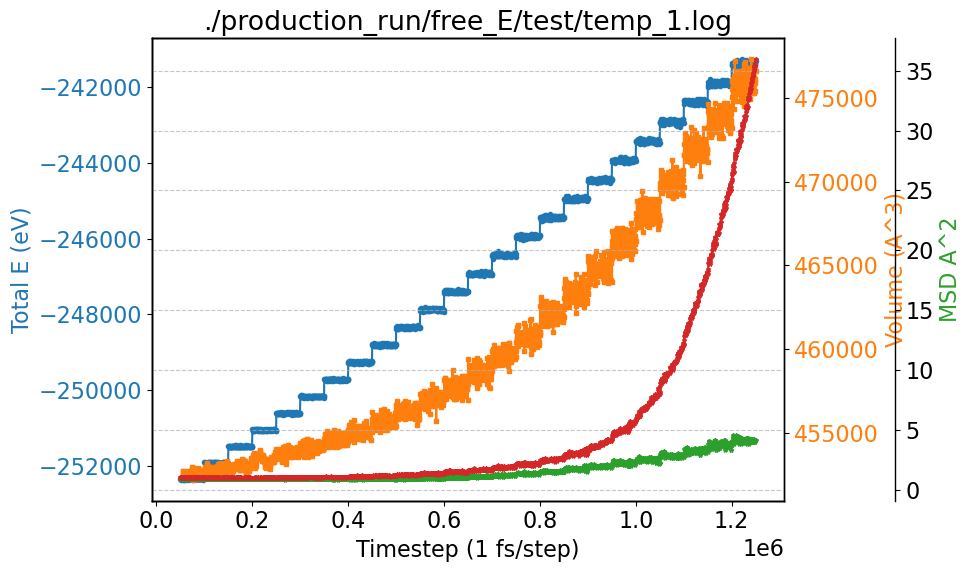

In [11]:
plot_log_diff('./production_run/free_E/test/temp_1.log')

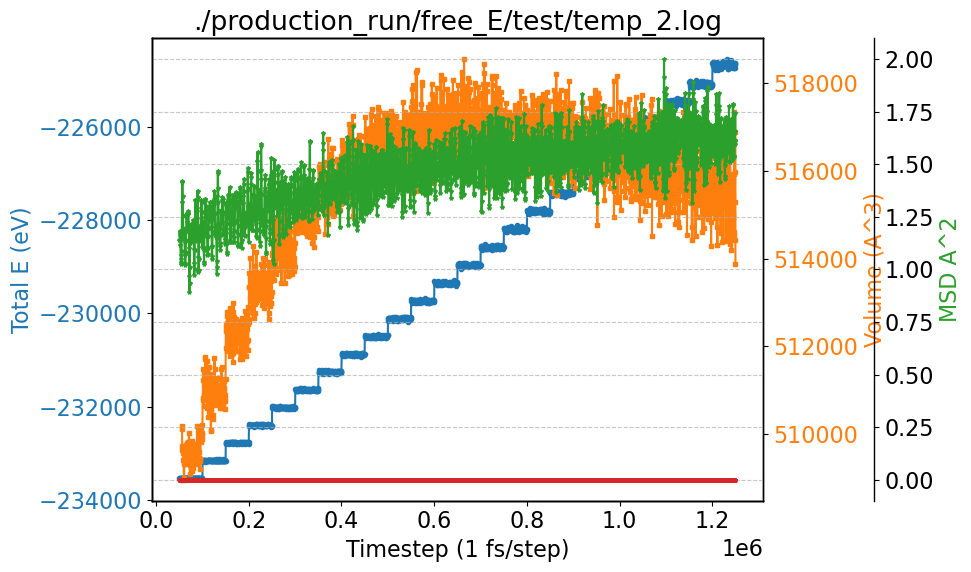

In [12]:
plot_log_diff('./production_run/free_E/test/temp_2.log')

### Prepare data 

In [12]:
a=range(400,4000,400)
a[1]

800

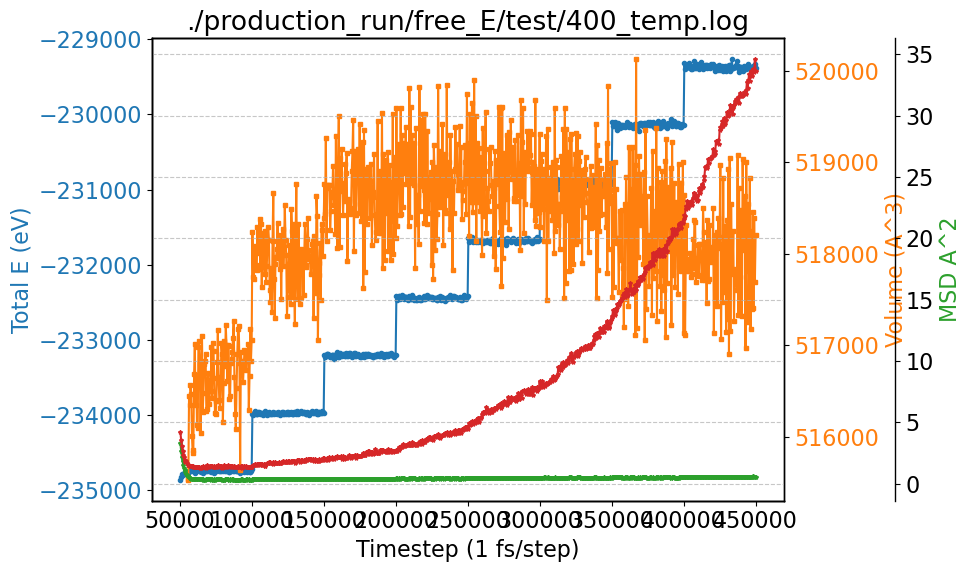

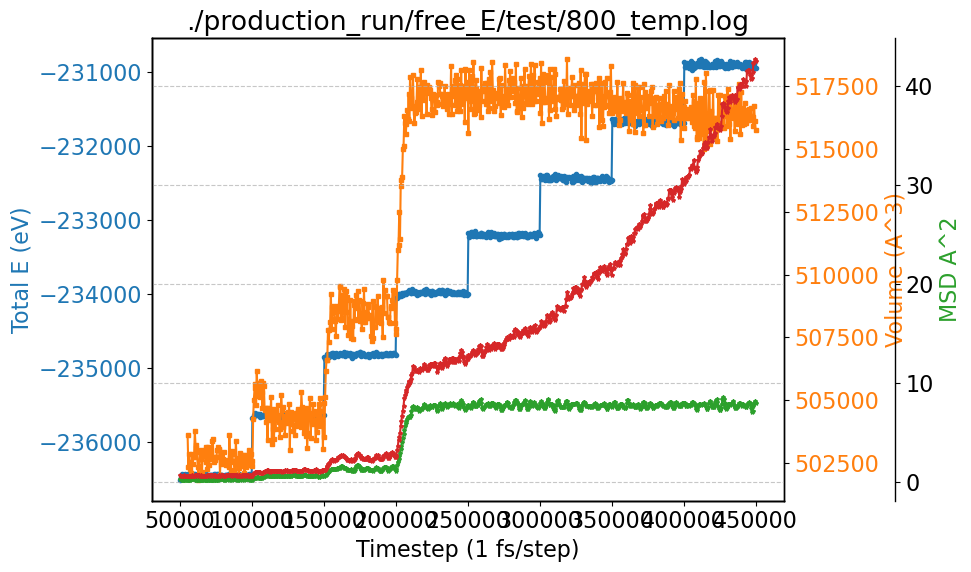

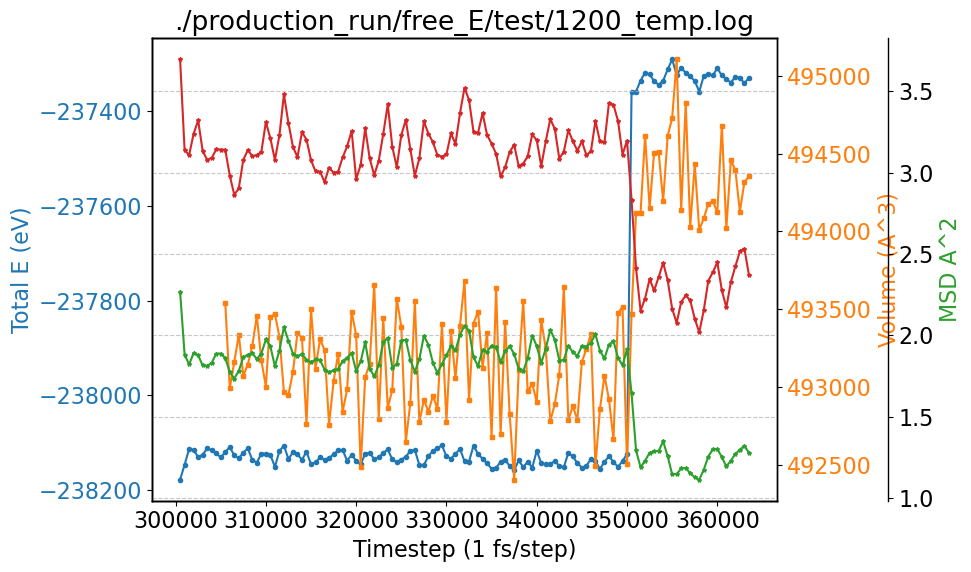

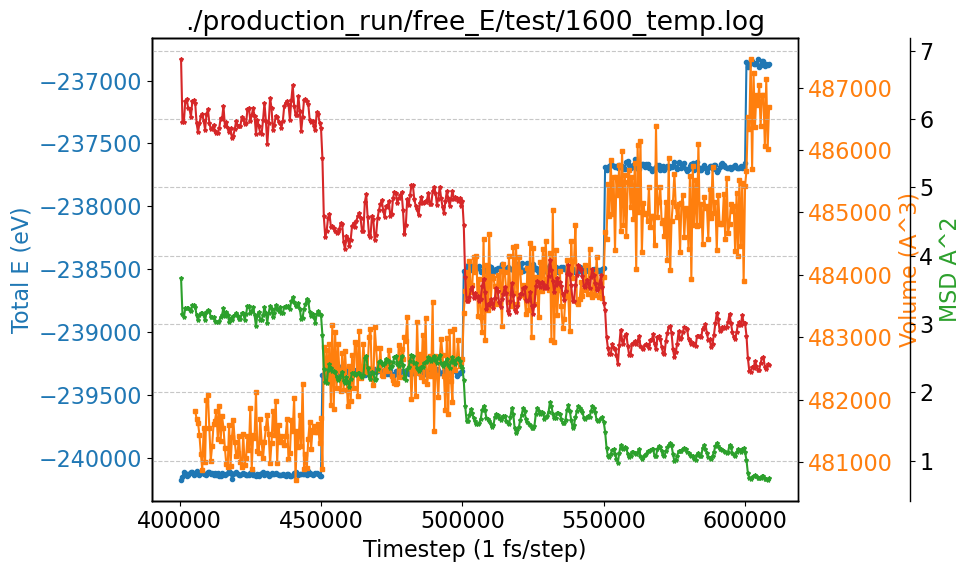

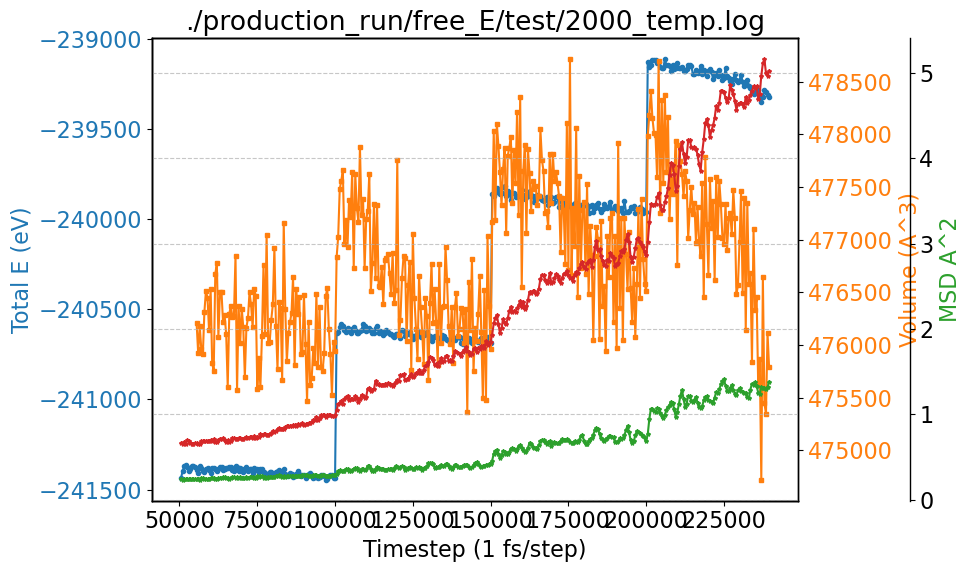

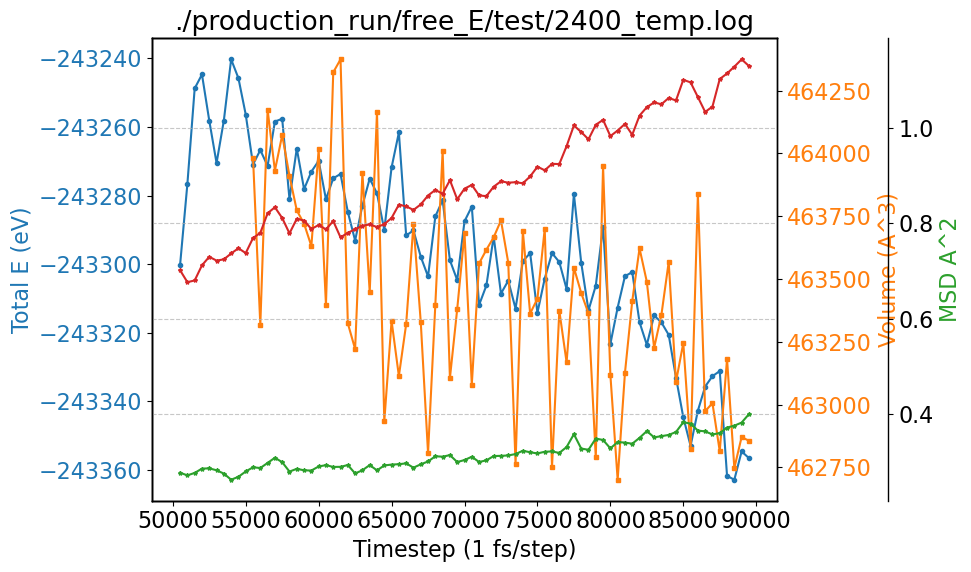

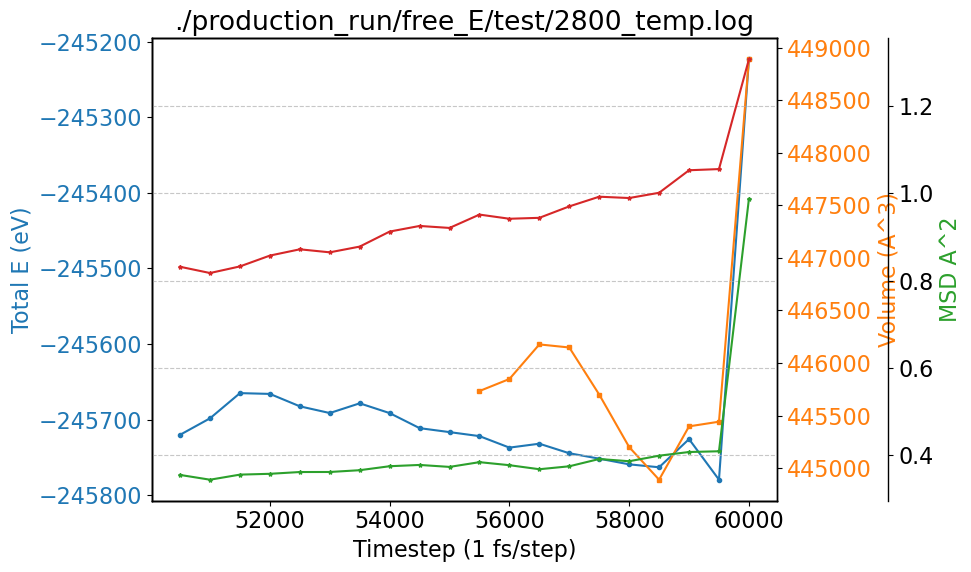

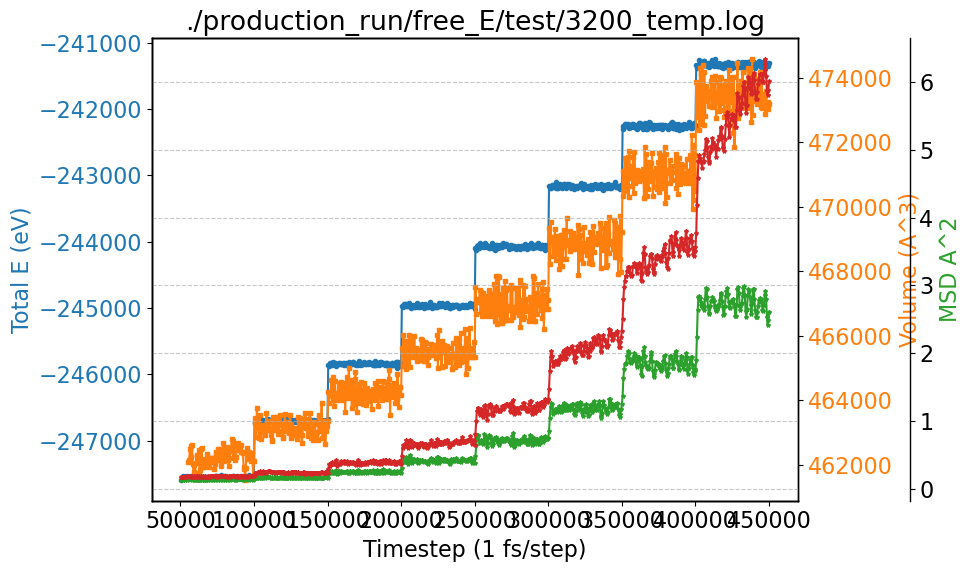

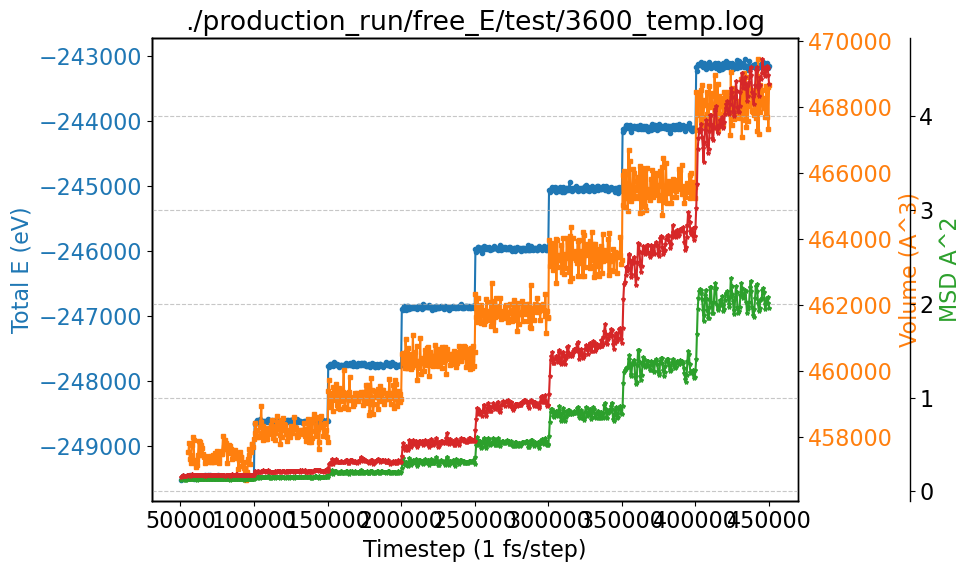

In [11]:
for i in range(400,4000,400):
    file = f'./production_run/free_E/test/{i}_temp.log'
    plot_log_diff(file)

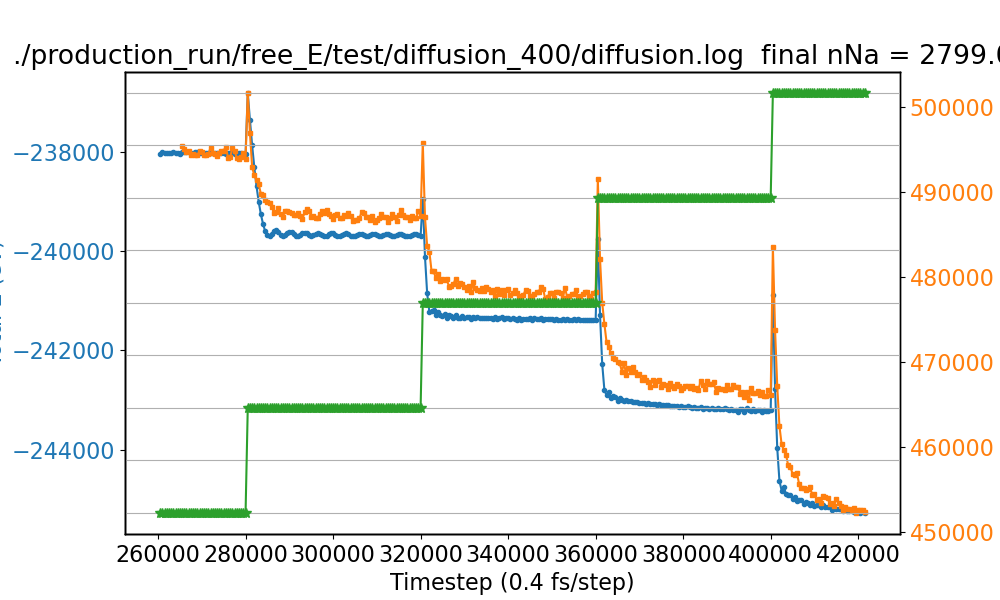

In [29]:
for i in [400]:
    file = f'./production_run/free_E/test/diffusion_{i}/diffusion.log'
    plot_log_free(file)

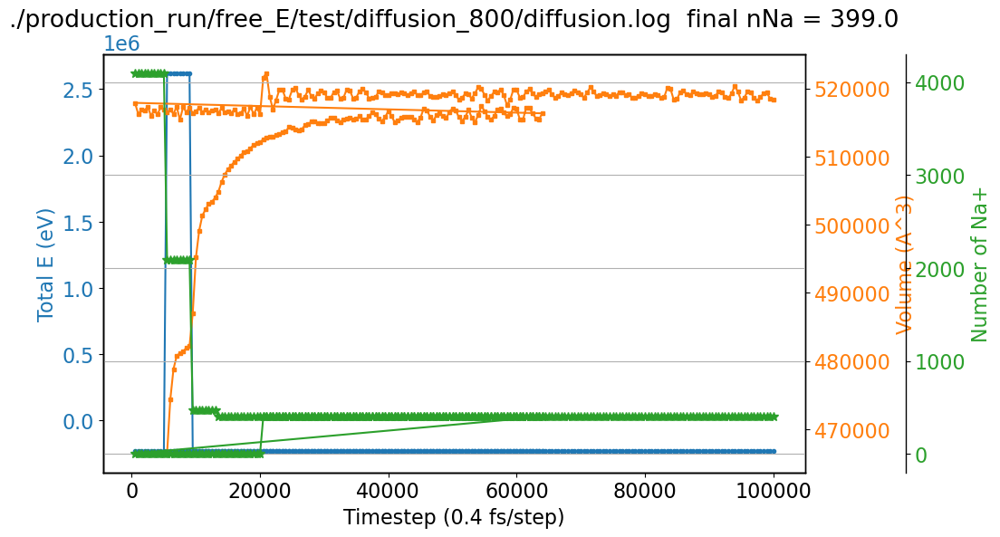

In [15]:
plot_log_free('./production_run/free_E/test/diffusion_800/diffusion.log')

## Free energy

In [ ]:
Nt = 200
mu_ls = [-2.5, -2.5, -2.5, -2.5, 1, 1, 1, 1]
fi_ls = [0.001, 0.002, 0.005, 0.01, 0.001, 0.002, 0.005, 0.01]
Nf_ls = [197, 197, 196, 199, 206, 203, 201, 198]
mu_e_ls_1 = []
mu_e_ls_2 = []

for i in range(8):
    mu = mu_ls[i]
    fi = fi_ls[i]
    Nf = Nf_ls[i]
    mu_e_ls_2.append(-2*fi*(Nf-Nt))

In [ ]:
mu_e_ls_1

In [ ]:
mu_e_ls_2

In [ ]:
for i in range(15):
    file = f'./production_run/free_E/free_{i+1}.log'
    plot_log_free(file)

In [ ]:
for i in range(4,8):
    file = f'./production_run/free_E/gcmc_{i+1}.log'
    plot_log_free(file)

In [ ]:
file = f'./test_lammps/gcmc_8.log'
plot_log(file)

## test

In [ ]:
element_map = {
    1: "C",
    2: "Mn", 
    3: "Fe",
    4: "N",
    5: "Na",
    6: "O",
    7: "H"
}
temp=1100
for i in [104]:
    input_file = f'./production_run/free_E/test/bias_{temp}/dump.bias_{i+1}.trj'
    output_file = f'./dump.bias_{i+1}.trj'
# Convert the file
    convert_dump_file(input_file, output_file, element_map)
    print(f"Conversion complete. Modified file saved as {output_file}")

### plot_Na_profile_bias

In [11]:
def plot_Na_profile_bias(temp, n_1, n_2, mu_1, step, fi, Nt, serie=0):
    plt.rcParams.update({'legend.fontsize': 12})
    fig, ax1 = plt.subplots(figsize=(10, 6))
    temp, n_1, n_2, mu_1,  step = temp, n_1, n_2, mu_1,  step
    
    mu_ls = np.linspace(mu_1, (n_2-n_1-1)*step+mu_1, (n_2-n_1))
    nNa_ls = []
    
    for i in range(n_1, n_2):
        if serie==0:
            file = f'./production_run/free_E/test/bias_{temp}/bias_{i+1}.log'
        elif serie!=0:
            file = f'./production_run/free_E/test/bias_{temp}/bias_{i+1}_{serie}.log'
        log_data = parse_lammps_free(file)

        if len(log_data['atoms']) > 0:
            natom = np.array(log_data['atoms'])-28672
            step = np.array(log_data['Step'])
            nNa=natom[-1]
            ax1.plot(step[:-1], natom[:-1], color=cm.jet((i-n_1)/(n_2-n_1)),
                     label=f'mu_{i+1} = {round(mu_ls[i-n_1],4)}  Na_f = {nNa}')#  V = {round(V_ave,2)}')#, marker='*')
    
    ax1.set_xlabel('Timestep (0.4 fs/step)')
    ax1.set_ylabel('Number of Na+')
    plt.title(f'{temp} K  mu = {mu_1} ~ {mu_ls[-1]}, fi={fi}, Nt={Nt}')
    ax1.legend(bbox_to_anchor=(1, 1))
    plt.tight_layout()
    plt.grid()

In [12]:
def plot_Na_profile_Nt(temp, n_1, n_2, Nt_1, step, fi, mu):
    fig, ax1 = plt.subplots(figsize=(10, 6))
    temp, n_1, n_2, mu_1,  step = temp, n_1, n_2, mu_1,  step
    
    mu_ls = np.linspace(mu_1, (n_2-n_1-1)*step+mu_1, (n_2-n_1))
    nNa_ls = []
    
    for i in range(n_1, n_2):
        file = f'./production_run/free_E/test/bias_{temp}/bias_{i+1}.log'
        log_data = parse_lammps_free(file)
        """
        E_Na = -.14023100E+01
        my_list = log_data['TotEng'][20:40]
        E_i = sum(my_list) / len(my_list)
        my_list = log_data['TotEng'][-20:]
        E_f = sum(my_list) / len(my_list)
        my_list = log_data['v_nNa'][20:40]
        n_Na_i = sum(my_list) / len(my_list)
        my_list = log_data['v_nNa'][-20:]
        n_Na_f = sum(my_list) / len(my_list)   
        n_Na = n_Na_i-n_Na_f
        V_ave = -(E_i-E_f-n_Na*E_Na)/n_Na
        """   
        natom = np.array(log_data['atoms'])-28672
        step = np.array(log_data['Step'])
        nNa=natom[-1]
        ax1.plot(step[:-1], natom[:-1], color=cm.jet((i-n_1)/(n_2-n_1)),
                 label=f'mu_{i+1} = {round(mu_ls[i-n_1],4)}  Na_f = {nNa}')#  V = {round(V_ave,2)}')#, marker='*')
    
    #ax1.hlines(512,0,3e6, linestyle='--', color='black')
    #ax1.hlines(0,0,3e6, linestyle='--', color='black')
    
    ax1.set_xlabel('Timestep (0.4 fs/step)')
    ax1.set_ylabel('Number of Na+')
    #ax1.set_xlim(0,3e6)
    plt.title(f'{temp} K  Nt = {mu_1} ~ {mu_ls[-1]}, fi={fi}, mu={Nt}')
    #ax1.tick_params(axis='y', labelcolor=color)
    #ax1.set_ylim(-5,515)
    ax1.legend(bbox_to_anchor=(1, 1))
    plt.grid()

### plot_Na_profile

In [13]:
def plot_Na_profile(temp, n_1, n_2, mu_1, step):
    fig, ax1 = plt.subplots(figsize=(10, 6))
    temp, n_1, n_2, mu_1,  step = temp, n_1, n_2, mu_1,  step
    
    mu_ls = np.linspace(mu_1, (n_2-n_1-1)*step+mu_1, (n_2-n_1))
    nNa_ls = []
    
    for i in range(n_1, n_2):
        file = f'./production_run/free_E/test/1100/free_{i+1}.log'
        log_data = parse_lammps_free(file)
        """
        E_Na = -.14023100E+01
        my_list = log_data['TotEng'][20:40]
        E_i = sum(my_list) / len(my_list)
        my_list = log_data['TotEng'][-20:]
        E_f = sum(my_list) / len(my_list)
        my_list = log_data['v_nNa'][20:40]
        n_Na_i = sum(my_list) / len(my_list)
        my_list = log_data['v_nNa'][-20:]
        n_Na_f = sum(my_list) / len(my_list)   
        n_Na = n_Na_i-n_Na_f
        V_ave = -(E_i-E_f-n_Na*E_Na)/n_Na
        """   
        natom = np.array(log_data['atoms'])-28672
        step = np.array(log_data['Step'])
        nNa=natom[-1]
        ax1.plot(step[:-1], natom[:-1], color=cm.jet((i-n_1)/(n_2-n_1)),
                 label=f'mu_{i+1} = {round(mu_ls[i-n_1],4)}  Na_f = {nNa}')#  V = {round(V_ave,2)}')#, marker='*')
    
    #ax1.hlines(512,0,3e6, linestyle='--', color='black')
    #ax1.hlines(0,0,3e6, linestyle='--', color='black')
    
    ax1.set_xlabel('Timestep (0.4 fs/step)')
    ax1.set_ylabel('Number of Na+')
    #ax1.set_xlim(0,3e6)
    plt.title(f'{temp} K  mu = {mu_1} ~ {mu_ls[-1]}')
    #ax1.tick_params(axis='y', labelcolor=color)
    #ax1.set_ylim(-5,515)
    ax1.legend(bbox_to_anchor=(1, 1))
    plt.grid()

In [14]:
def plot_Na_profile_from_dump(temp, n_1, n_2, mu_1,  step):
    temp, n_1, n_2, mu_1,  step = temp, n_1, n_2, mu_1,  step
    
    mu_ls = np.linspace(mu_1, (n_2-n_1-1)*step+mu_1, (n_2-n_1))
    timestep_ls = []
    num_atoms_ls = []
    for i in range(n_1, n_2):
        trj_filename = f'./production_run/free_E/test/{temp}/dump.gcmc_{i+1}.trj'  # Replace with your actual file name
        timestep, num_atoms = extract_timestep_and_atom_count(trj_filename)
        timestep_ls.append(timestep)
        num_atoms_ls.append(num_atoms)
        
    fig, ax1 = plt.subplots(figsize=(10, 6))
    for i in range(n_1, n_2):
        nNa=-28672+num_atoms_ls[i-n_1][-1]
        ax1.plot(timestep_ls[i-n_1], -28672+num_atoms_ls[i-n_1], color=cm.jet((i-n_1)/(n_2-n_1)),
                 label=f'mu_{i+1} = {round(mu_ls[i-n_1],4)}  Na_f = {nNa}')#  V = {round(V_ave,2)}')#, marker='*')
    plt.title(f'{temp} K  mu = {mu_1} ~ {mu_ls[-1]}')   
    plt.legend(bbox_to_anchor=(1, 1))
    plt.grid()
    ax1.set_xlabel('Timestep (0.4 fs/step)')
    ax1.set_ylabel('Number of Na+')

In [15]:
def plot_Na_bias_from_dump(temp, n_1, n_2, mu_1, step, fi, Nt):
    temp, n_1, n_2, mu_1,  step = temp, n_1, n_2, mu_1,  step
    
    mu_ls = np.linspace(mu_1, (n_2-n_1-1)*step+mu_1, (n_2-n_1))
    timestep_ls = []
    num_atoms_ls = []
    for i in range(n_1, n_2):
        trj_filename = f'./production_run/free_E/test/bias_{temp}/dump.bias_{i+1}.trj'  # Replace with your actual file name
        timestep, num_atoms = extract_timestep_and_atom_count(trj_filename)
        timestep_ls.append(timestep)
        num_atoms_ls.append(num_atoms)
        
    fig, ax1 = plt.subplots(figsize=(10, 6))
    for i in range(n_1, n_2):
        nNa=-28672+num_atoms_ls[i-n_1][-1]
        ax1.plot(timestep_ls[i-n_1], -28672+num_atoms_ls[i-n_1], color=cm.jet((i-n_1)/(n_2-n_1)),
                 label=f'mu_{i+1} = {round(mu_ls[i-n_1],4)}  Na_f = {nNa}')#  V = {round(V_ave,2)}')#, marker='*')
    plt.title(f'{temp} K  mu = {mu_1} ~ {mu_ls[-1]}, fi={fi}, Nt={Nt}')   
    plt.legend(bbox_to_anchor=(1, 1))
    plt.grid()
    ax1.set_xlabel('Timestep (0.4 fs/step)')
    ax1.set_ylabel('Number of Na+')

In [16]:
def extract_timestep_and_atom_count(trj_file):
    timestep = []
    num_atoms = []
    
    with open(trj_file, 'r') as file:
        for line in file:
            if "ITEM: TIMESTEP" in line:
                timestep.append(int(next(file).strip()))  # Read the next line for TIMESTEP value
            elif "ITEM: NUMBER OF ATOMS" in line:
                num_atoms.append(int(next(file).strip()))  # Read the next line for atom count
    return np.array(timestep), np.array(num_atoms)

In [15]:
extract_to_data_file(f'./production_run/free_E/test/600/dump.gcmc_{i+1}.trj',f'./production_run/free_E/test/600/gcmc_{i+1}.data')

NameError: name 'extract_to_data_file' is not defined

In [ ]:
# Example usage:
timestep_ls = []
num_atoms_ls = []
for i in range(21):
    trj_filename = f'./production_run/free_E/test/dump.gcmc_{i+1}.trj'  # Replace with your actual file name
    timestep, num_atoms = extract_timestep_and_atom_count(trj_filename)
    timestep_ls.append(timestep)
    num_atoms_ls.append(num_atoms)

In [ ]:
mu_ls = np.linspace(mu_1, (n_2-n_1-1)*step+mu_1, (n_2-n_1))
mu_ls

## 1100K

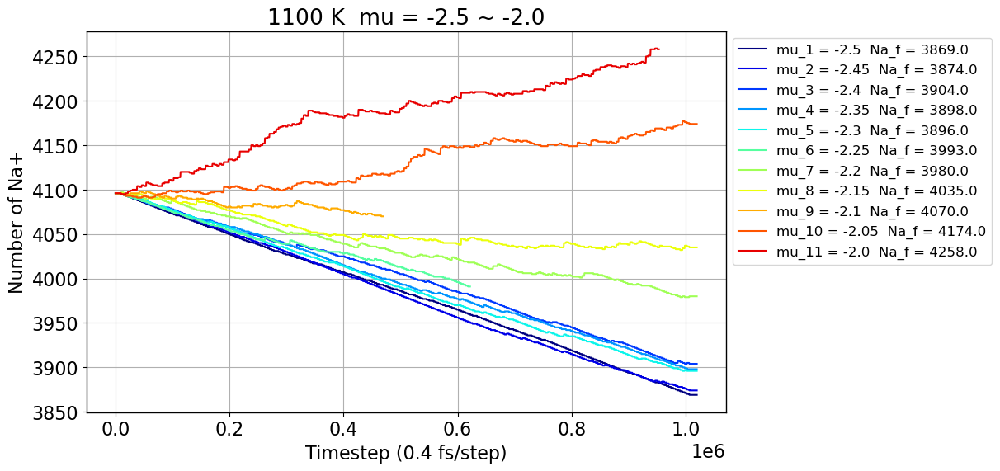

In [22]:
plot_Na_profile(1100, 0, 11, -2.5, 0.05)

In [ ]:
for i in range(40,43):
    file = f'./production_run/free_E/test/1100/free_{i+1}.log'
    plot_log_free(file)

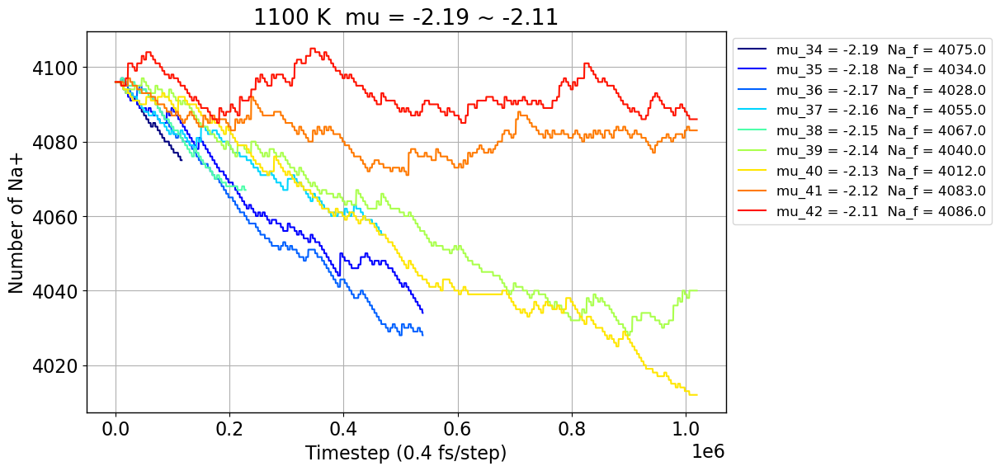

In [19]:
plot_Na_profile(1100, 33, 42, -2.19, 0.01)

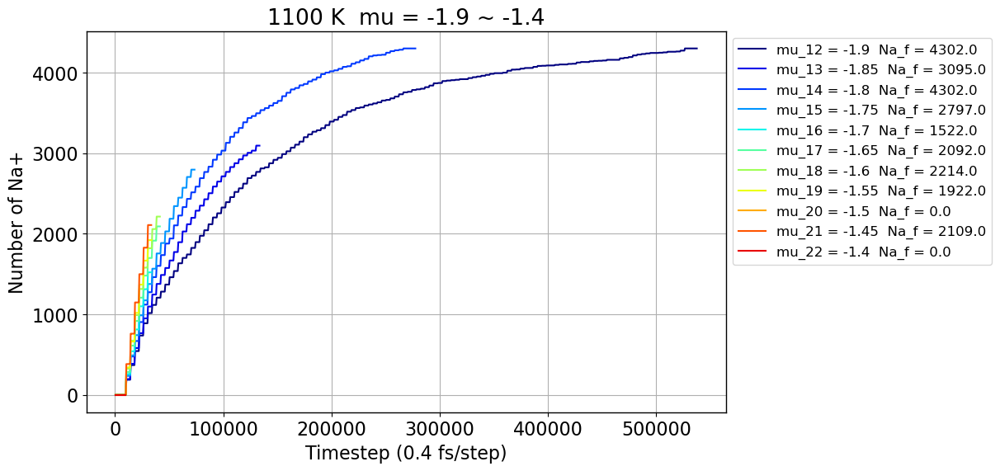

In [20]:
plot_Na_profile(1100, 11, 22, -1.9, 0.05)

In [ ]:
for i in range(11,22):
    file = f'./production_run/free_E/test/1100/free_{i+1}.log'
    plot_log_free(file)

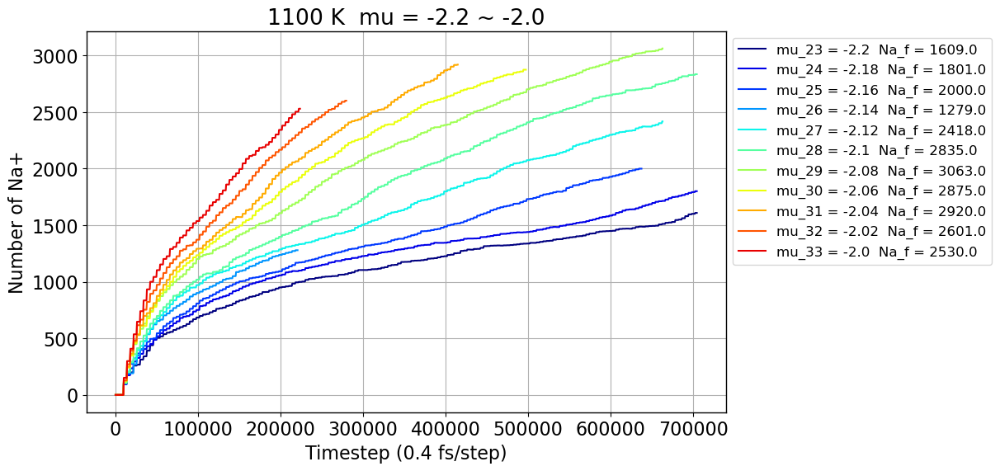

In [23]:
plot_Na_profile(1100, 22, 33, -2.2, 0.02)

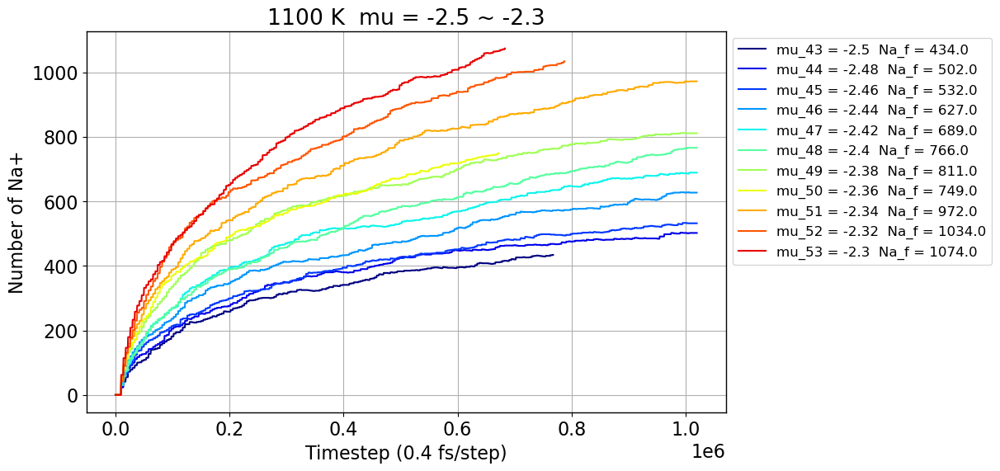

In [24]:
plot_Na_profile(1100, 42, 53, -2.5, 0.02)

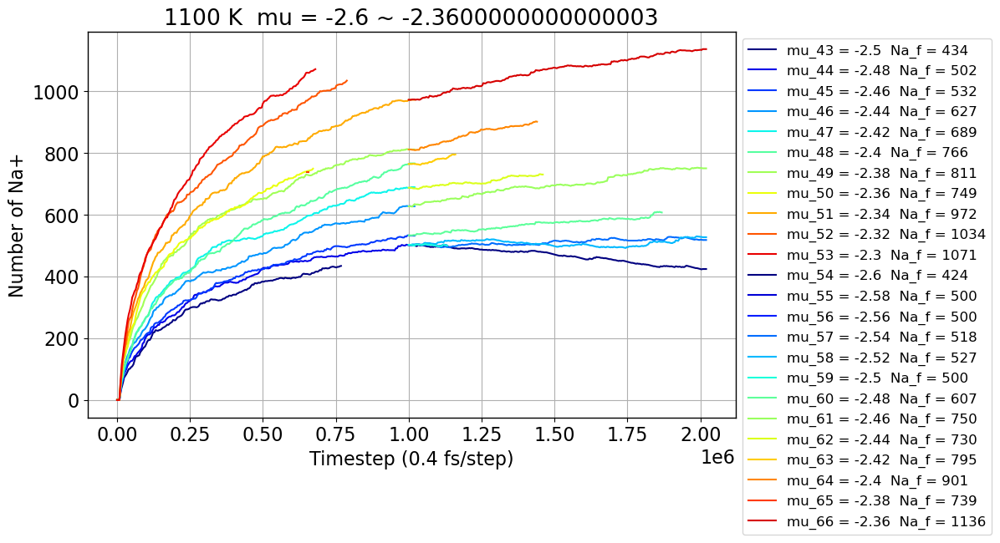

In [53]:
temp, n_1, n_2, mu_1,  step = 1100, 42, 53, -2.5, 0.02

mu_ls = np.linspace(mu_1, (n_2-n_1-1)*step+mu_1, (n_2-n_1))
timestep_ls = []
num_atoms_ls = []
for i in range(n_1, n_2):
    trj_filename = f'./production_run/free_E/test/{temp}/dump.gcmc_{i+1}.trj'  # Replace with your actual file name
    timestep, num_atoms = extract_timestep_and_atom_count(trj_filename)
    timestep_ls.append(timestep)
    num_atoms_ls.append(num_atoms)
    
fig, ax1 = plt.subplots(figsize=(10, 6))
for i in range(n_1, n_2):
    nNa=-28672+num_atoms_ls[i-n_1][-1]
    ax1.plot(timestep_ls[i-n_1], -28672+num_atoms_ls[i-n_1], color=cm.jet((i-n_1)/(n_2-n_1)),
             label=f'mu_{i+1} = {round(mu_ls[i-n_1],4)}  Na_f = {nNa}')#  V = {round(V_ave,2)}')#, marker='*')
plt.title(f'{temp} K  mu = {mu_1} ~ {mu_ls[-1]}')   
plt.legend(bbox_to_anchor=(1, 1))
plt.grid()
ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')

temp, n_1, n_2, mu_1,  step = 1100, 53, 66, -2.6, 0.02

mu_ls = np.linspace(mu_1, (n_2-n_1-1)*step+mu_1, (n_2-n_1))
timestep_ls = []
num_atoms_ls = []
for i in range(n_1, n_2):
    trj_filename = f'./production_run/free_E/test/{temp}/dump.gcmc_{i+1}.trj'  # Replace with your actual file name
    timestep, num_atoms = extract_timestep_and_atom_count(trj_filename)
    timestep_ls.append(timestep)
    num_atoms_ls.append(num_atoms)
for i in range(n_1, n_2):
    nNa=-28672+num_atoms_ls[i-n_1][-1]
    ax1.plot(timestep_ls[i-n_1], -28672+num_atoms_ls[i-n_1], color=cm.jet((i-n_1)/(n_2-n_1)),
             label=f'mu_{i+1} = {round(mu_ls[i-n_1],4)}  Na_f = {nNa}')#  V = {round(V_ave,2)}')#, marker='*')
plt.title(f'{temp} K  mu = {mu_1} ~ {mu_ls[-1]}')   
plt.legend(bbox_to_anchor=(1, 1))

In [ ]:
for i in range(42,45):
    file = f'./production_run/free_E/test/1100/free_{i+1}.log'
    plot_log_free(file)

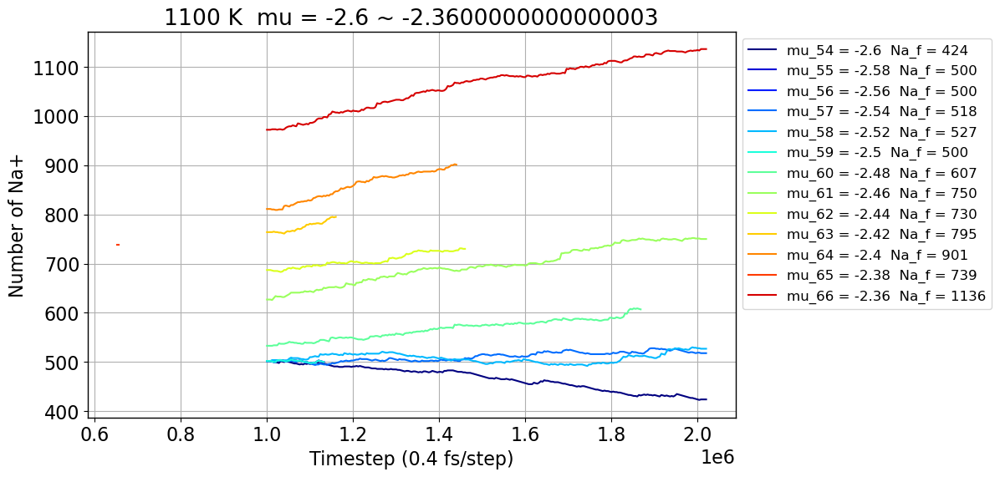

In [25]:
plot_Na_profile_from_dump(1100, 53, 66, -2.6, 0.02)

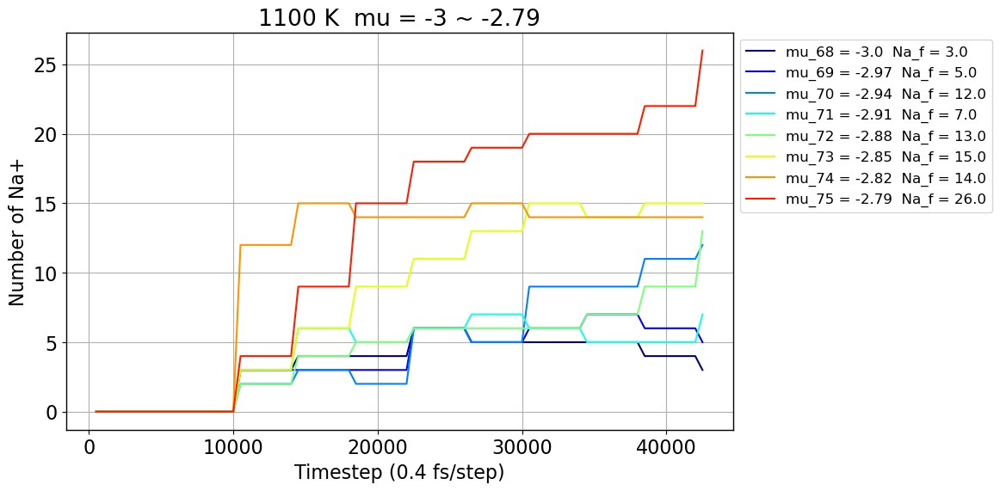

In [26]:
plot_Na_profile(1100, 67, 75, -3, 0.03)

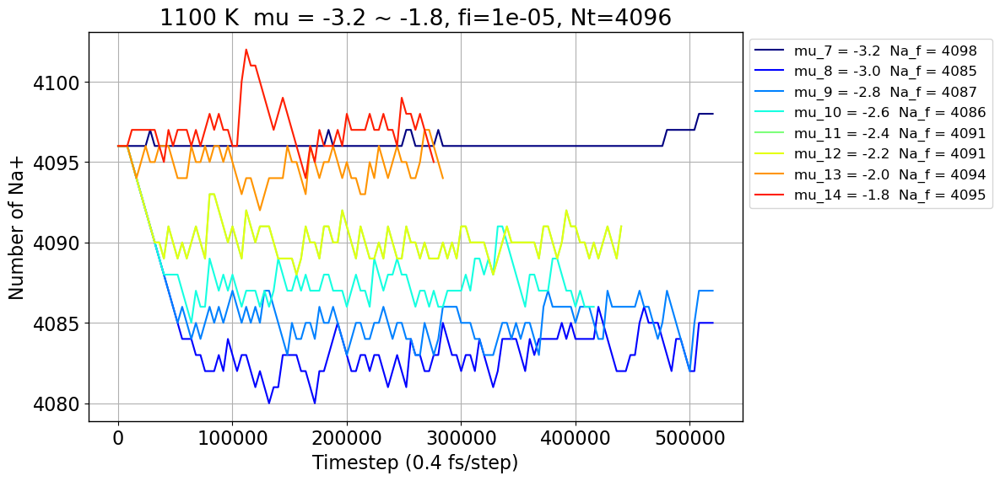

In [50]:
plot_Na_bias_from_dump(1100, 6, 14, -3.2, 0.2, 0.00001, 4096)

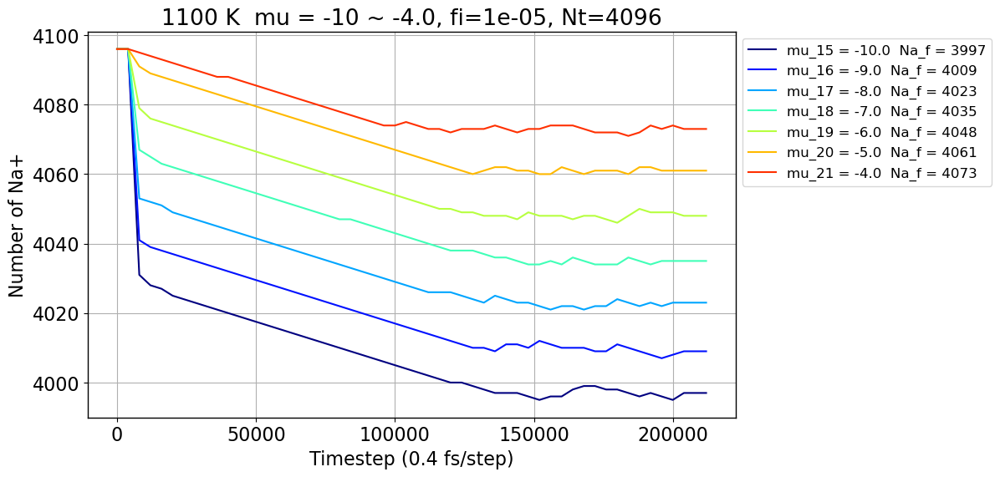

In [40]:
plot_Na_bias_from_dump(1100, 14, 21, -10, 1, 0.00001, 4096)

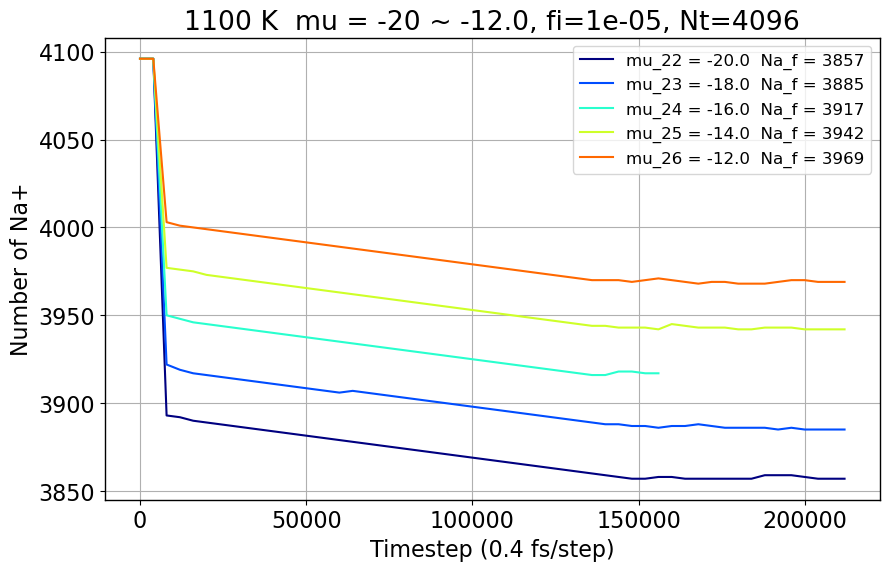

In [41]:
plot_Na_bias_from_dump(1100, 21, 26, -20, 2, 0.00001, 4096)

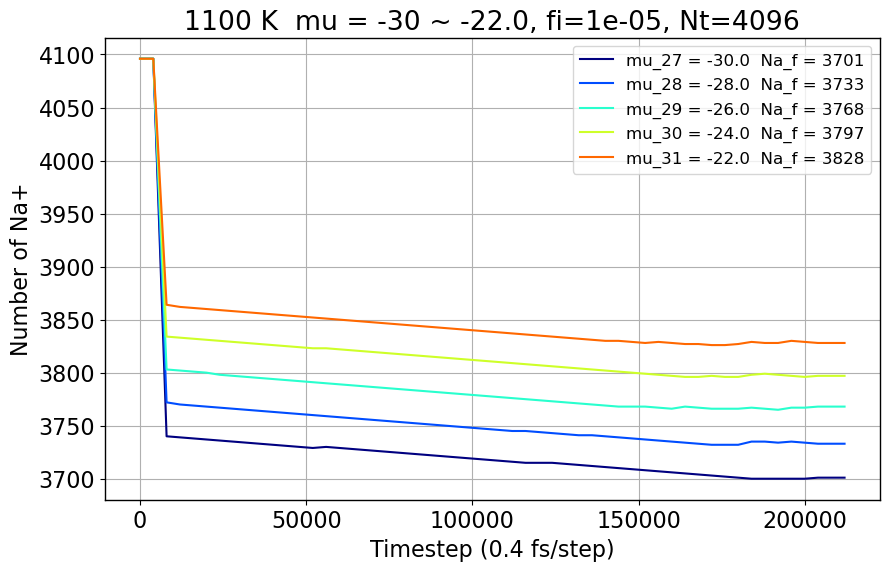

In [42]:
plot_Na_bias_from_dump(1100, 26, 31, -30, 2, 0.00001, 4096)

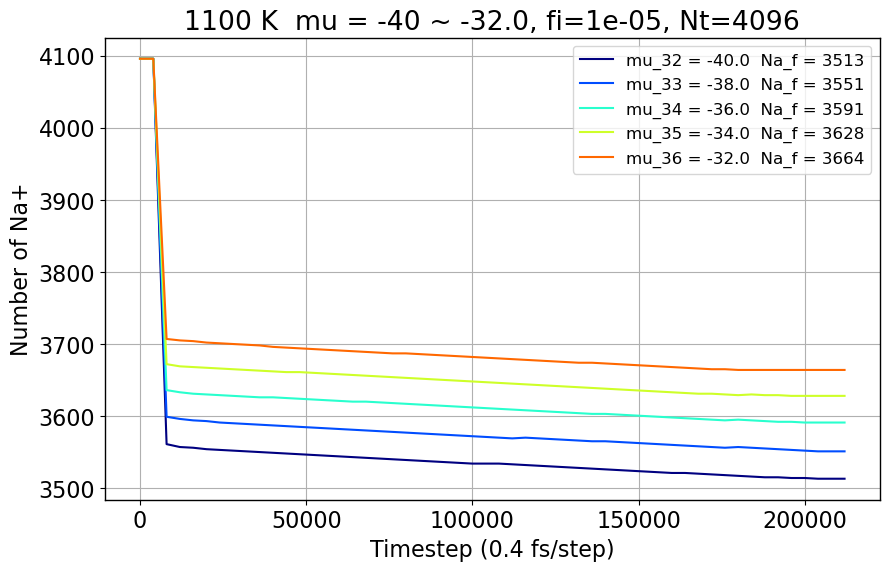

In [43]:
plot_Na_bias_from_dump(1100, 31, 36, -40, 2, 0.00001, 4096)

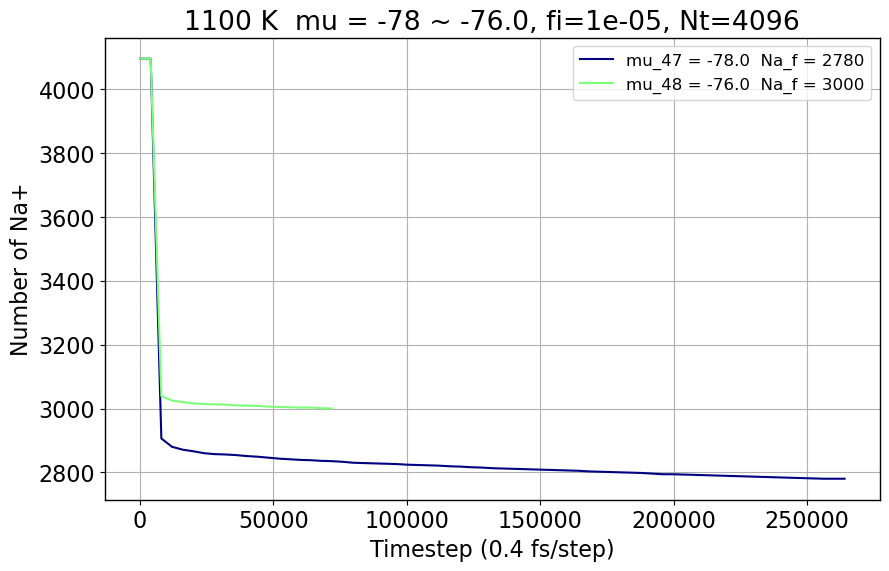

In [44]:
plot_Na_bias_from_dump(1100, 46,48, -78, 2, 0.00001, 4096)

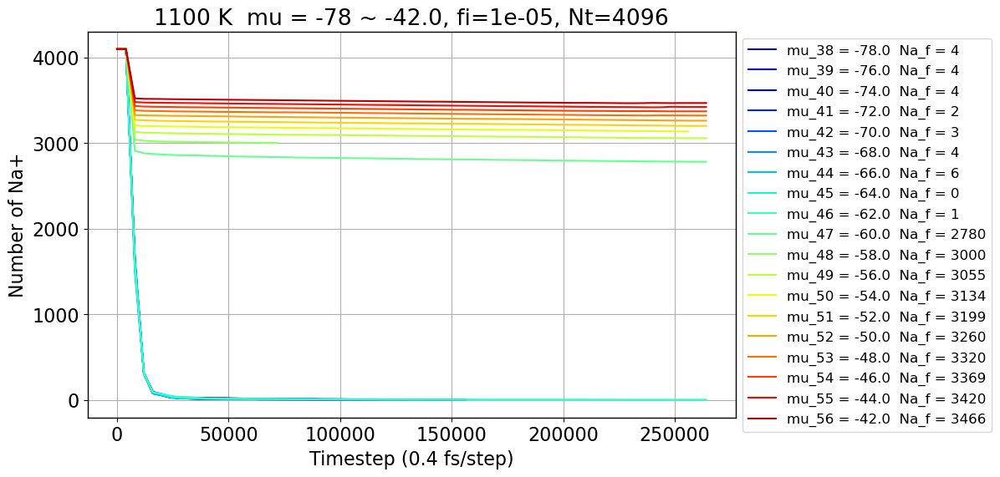

In [45]:
plot_Na_bias_from_dump(1100, 37, 56, -78, 2, 0.00001, 4096)

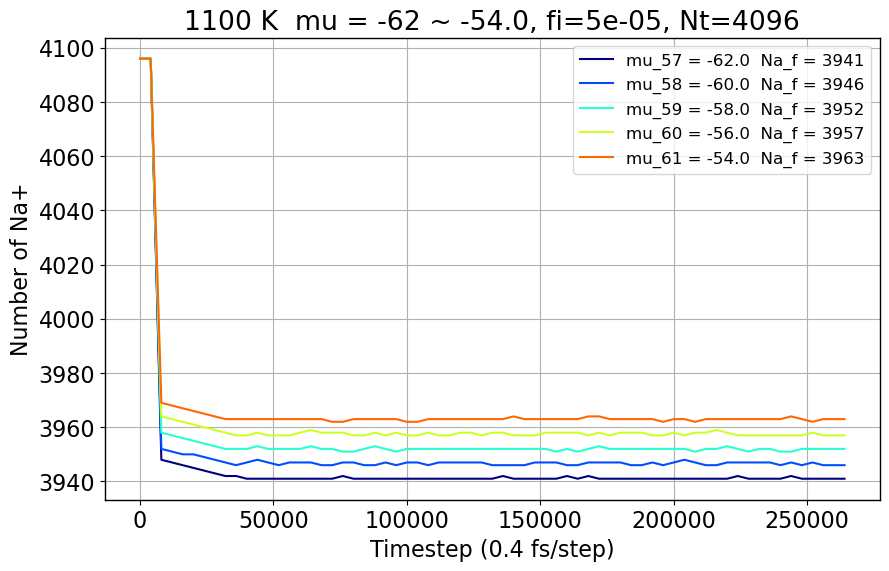

In [46]:
plot_Na_bias_from_dump(1100, 56, 61, -62, 2, 0.00005, 4096)

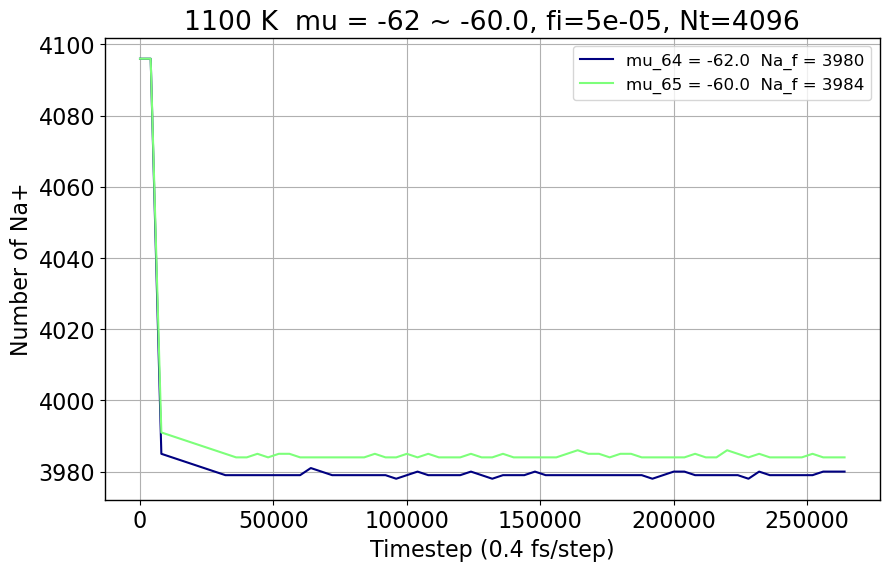

In [47]:
plot_Na_bias_from_dump(1100, 63, 65, -62, 2, 0.00005, 4096)

In [34]:
plot_Na_bias_from_dump(1100, 67, 7, 0, 400, 0.0002, 4096)

ValueError: Number of samples, -60, must be non-negative.

### mu=0.000001

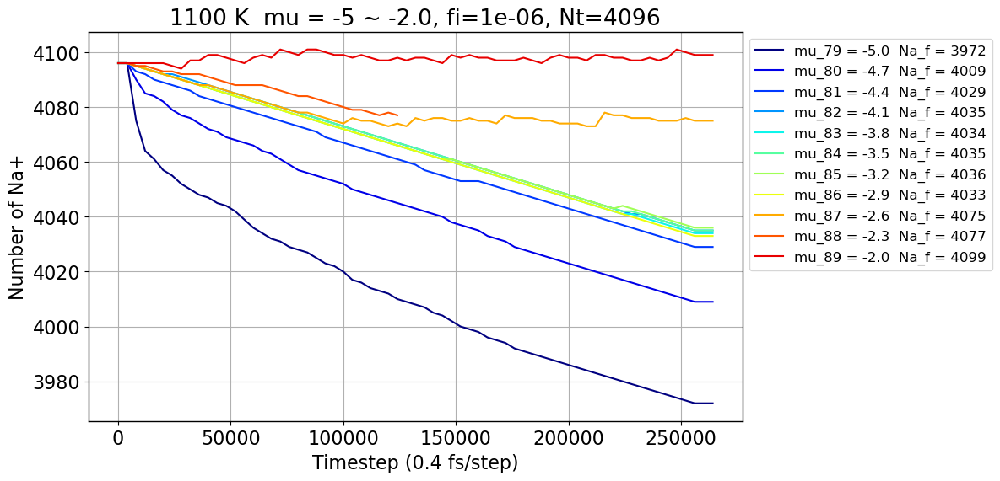

In [35]:
plot_Na_bias_from_dump(1100, 78, 89, -5, 0.3, 0.000001, 4096)

### mu=0.000001

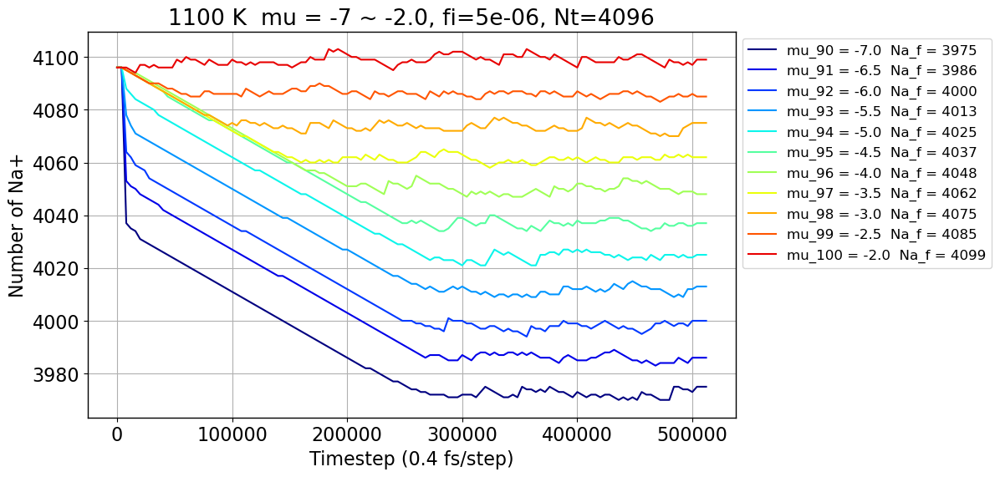

In [35]:
plot_Na_bias_from_dump(1100, 89, 100, -7, 0.5, 0.000005, 4096)

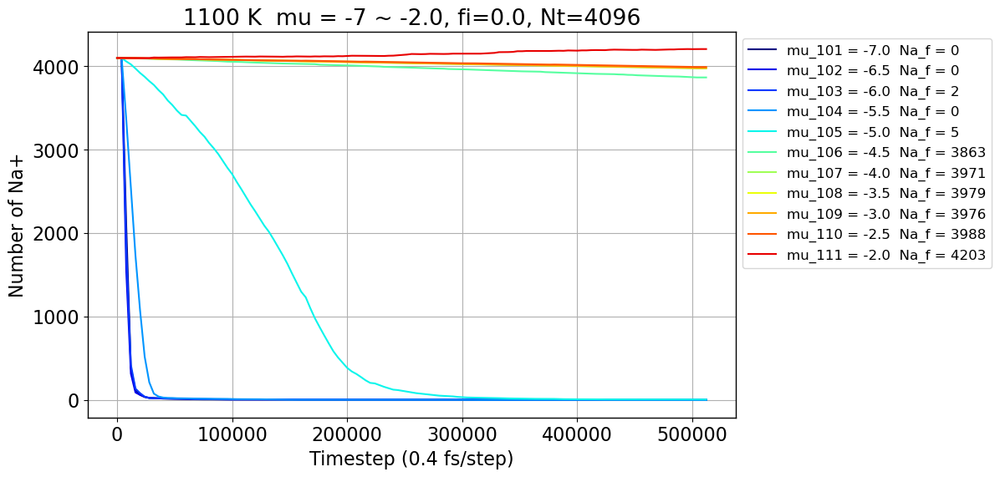

In [36]:
plot_Na_bias_from_dump(1100, 100, 111, -7, 0.5, 0.0, 4096)

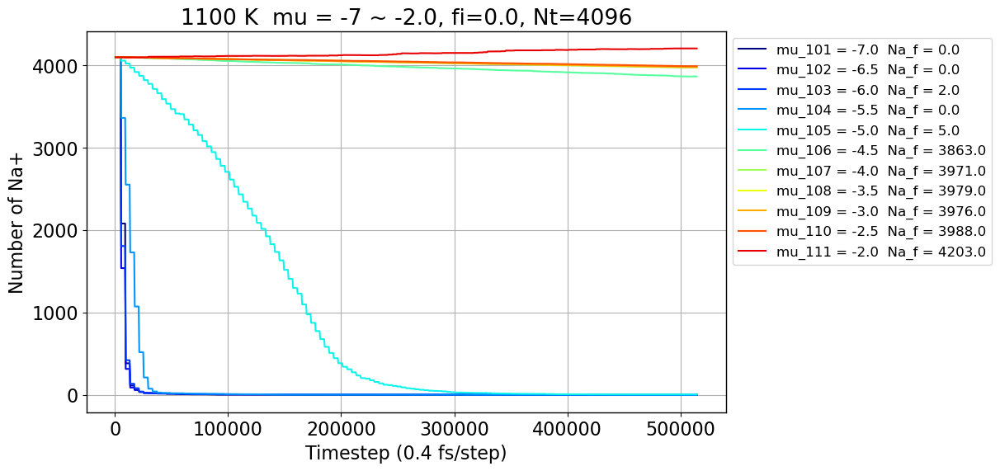

In [24]:
plot_Na_profile(1100, 100, 111, -7, 0.5, 0.0, 4096)

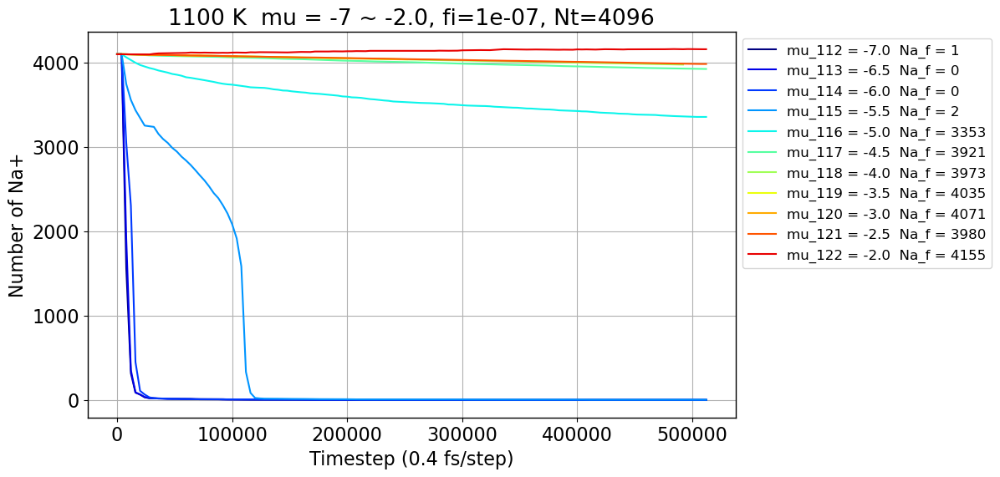

In [34]:
plot_Na_bias_from_dump(1100, 111, 122, -7, 0.5, 0.0000001, 4096)

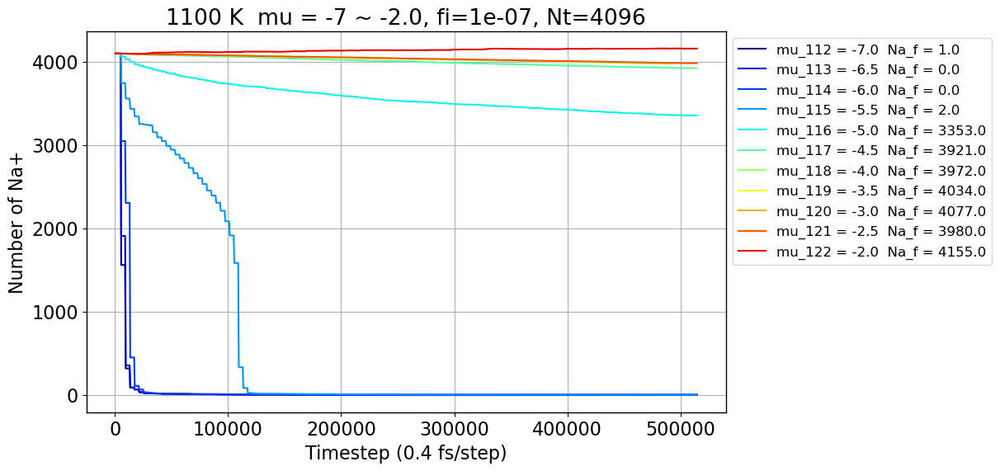

In [23]:
plot_Na_profile(1100, 111, 122, -7, 0.5, 0.0000001, 4096)

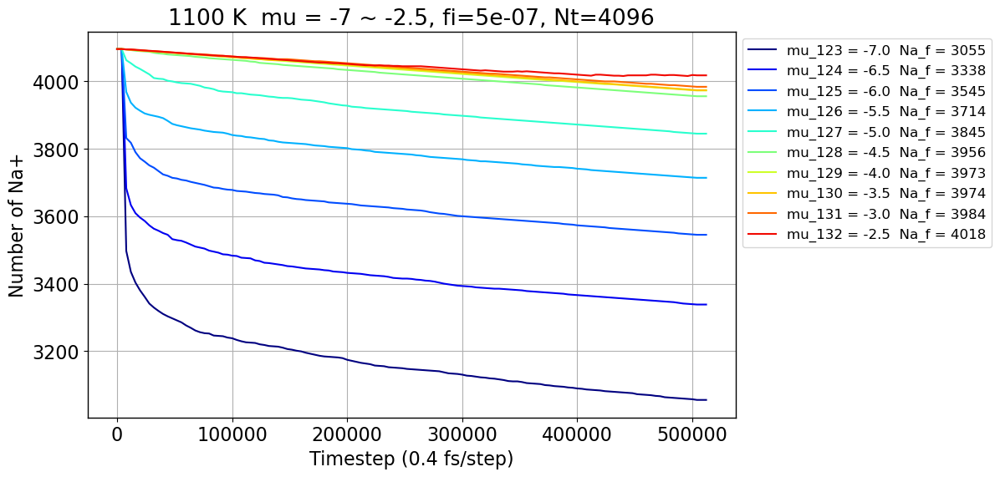

In [16]:
plot_Na_bias_from_dump(1100, 122, 132, -7, 0.5, 0.0000005, 4096)

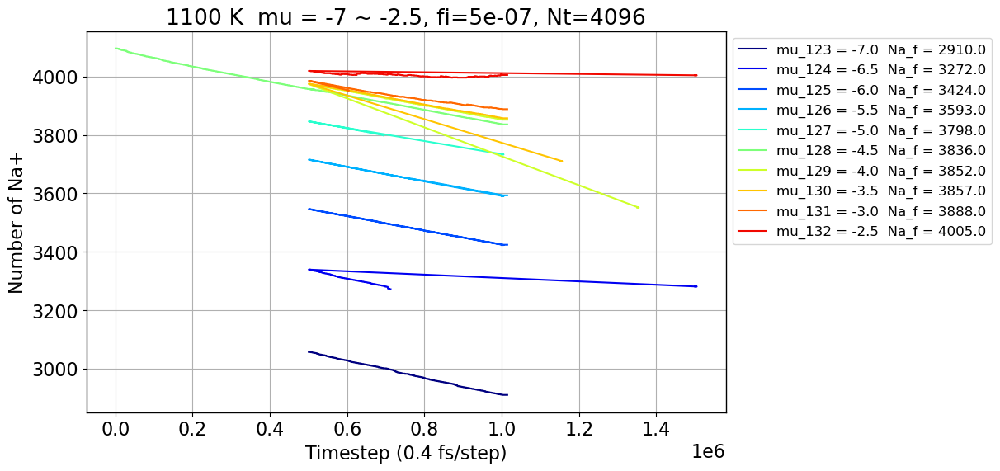

In [31]:
#%matplotlib inline
plot_Na_profile_bias(1100, 122, 132, -7, 0.5, 0.0000005, 4096)

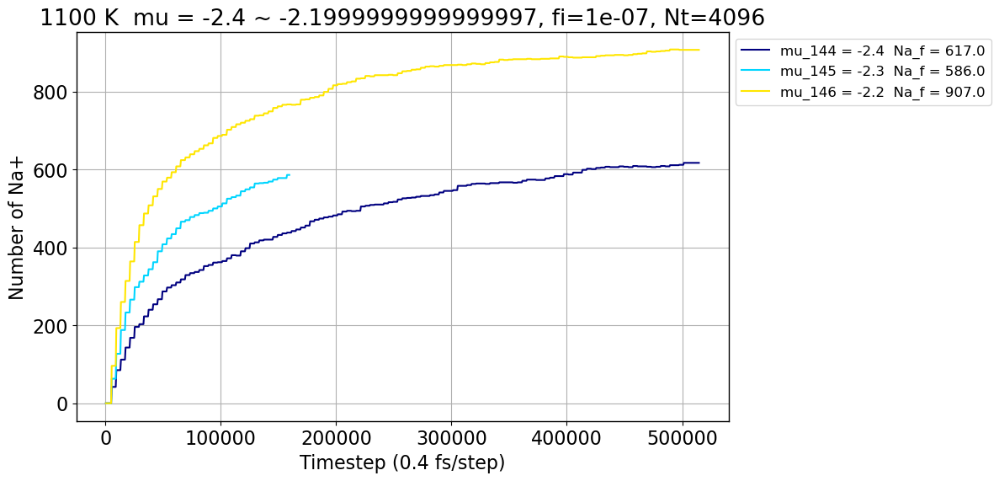

In [49]:
#%matplotlib inline
plot_Na_profile_bias(1100, 143, 146, -2.4, 0.1, 0.0000001, 4096)

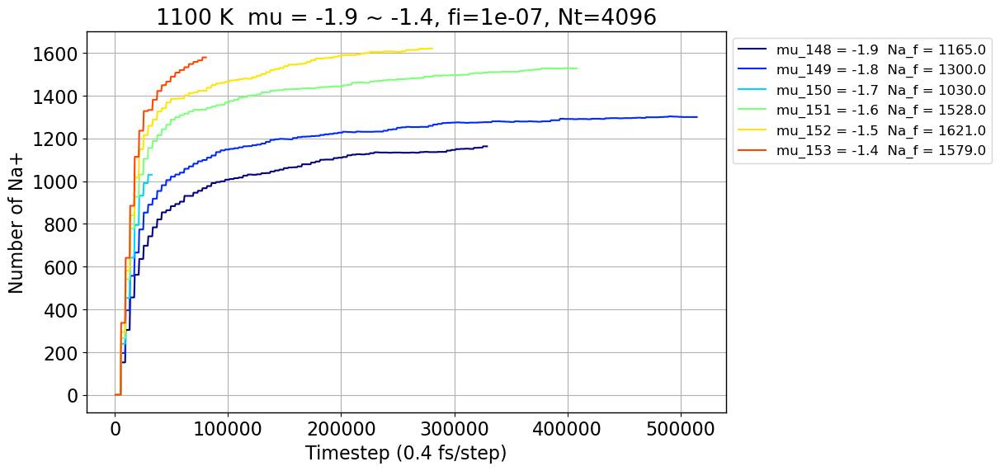

In [47]:
#%matplotlib inline
plot_Na_profile_bias(1100, 147, 153, -1.9, 0.1, 0.0000001, 4096)

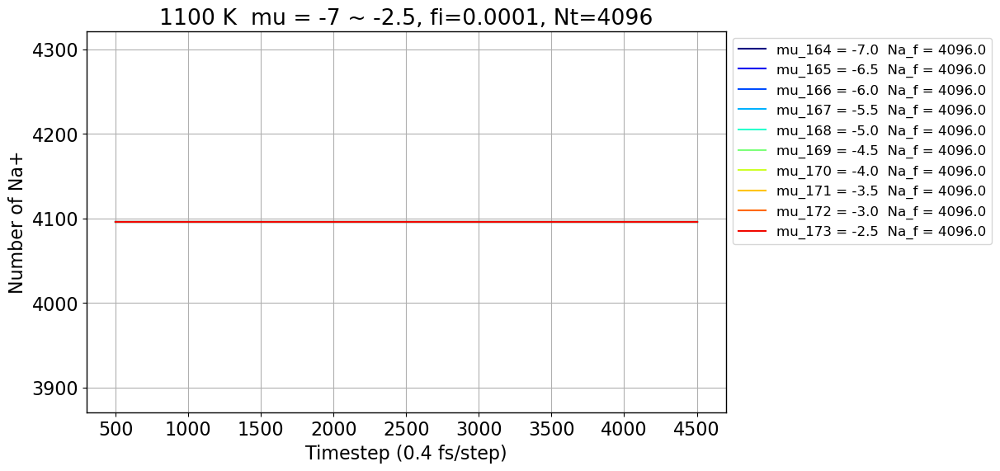

In [50]:
plot_Na_profile_bias(1100, 163, 173, -7, 0.5, 0.0001, 4096)

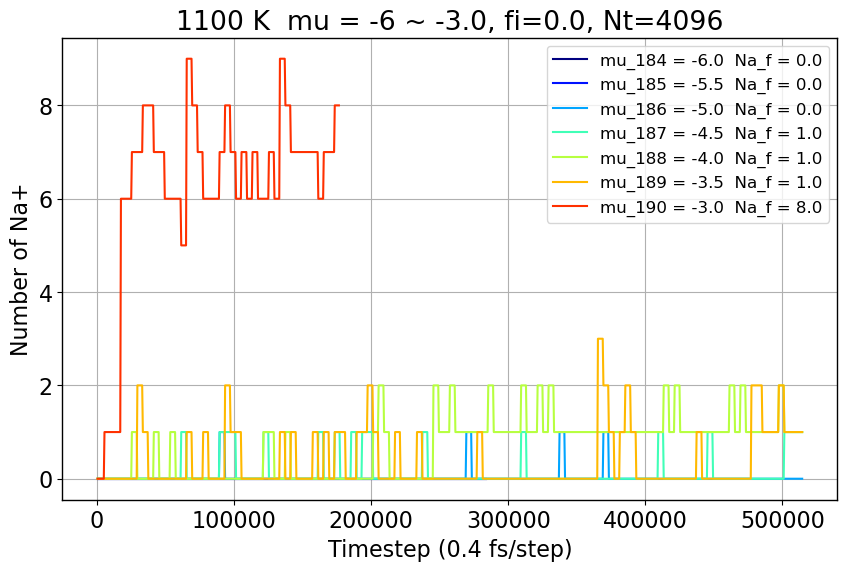

In [65]:
plot_Na_profile_bias(1100, 183, 190, -6, 0.5, 0.000, 4096)

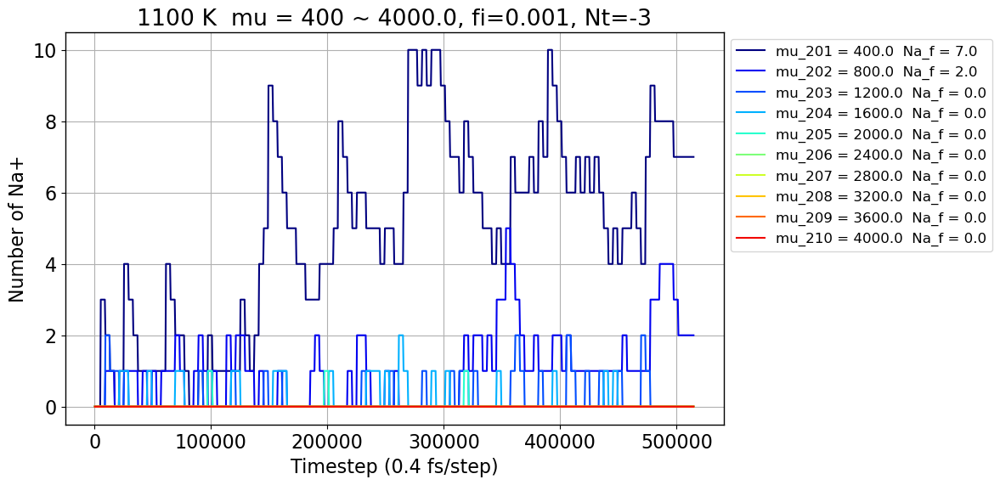

In [13]:
plot_Na_profile_bias(1100, 200, 210, 400, 400, 0.001, -3)

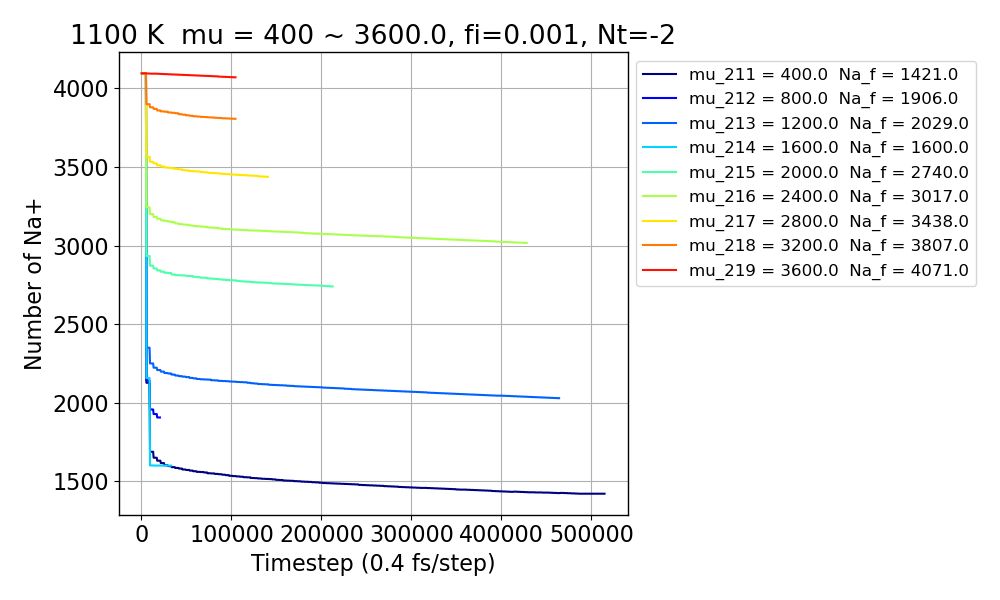

In [113]:
plot_Na_profile_bias(1100, 210, 219, 400, 400, 0.001, -2)

IndexError: index -1 is out of bounds for axis 0 with size 0

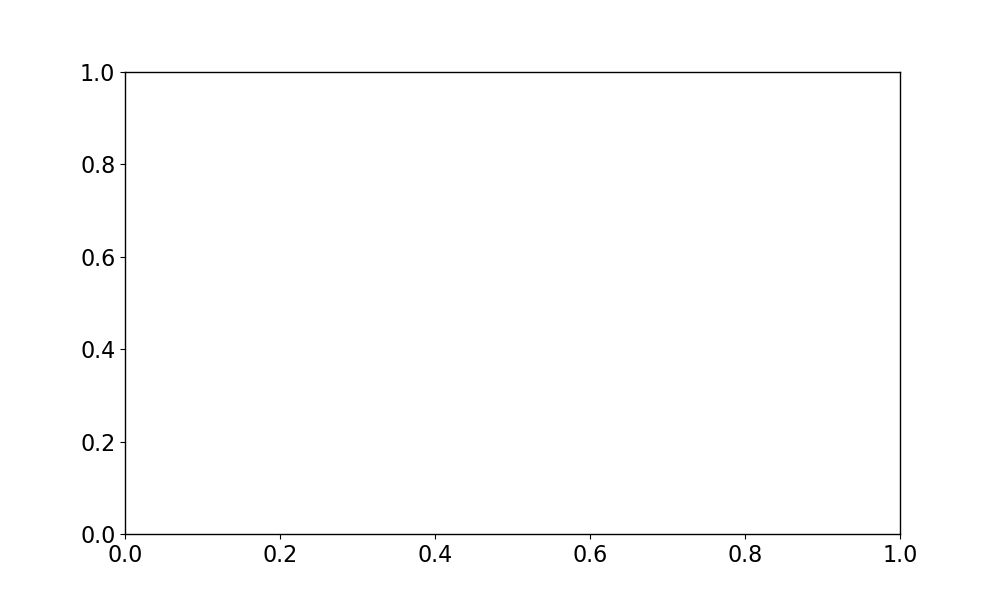

In [112]:
plot_Na_profile_bias(1100, 220, 230, 400, 400, 0.001, -3)


### Scan Nt

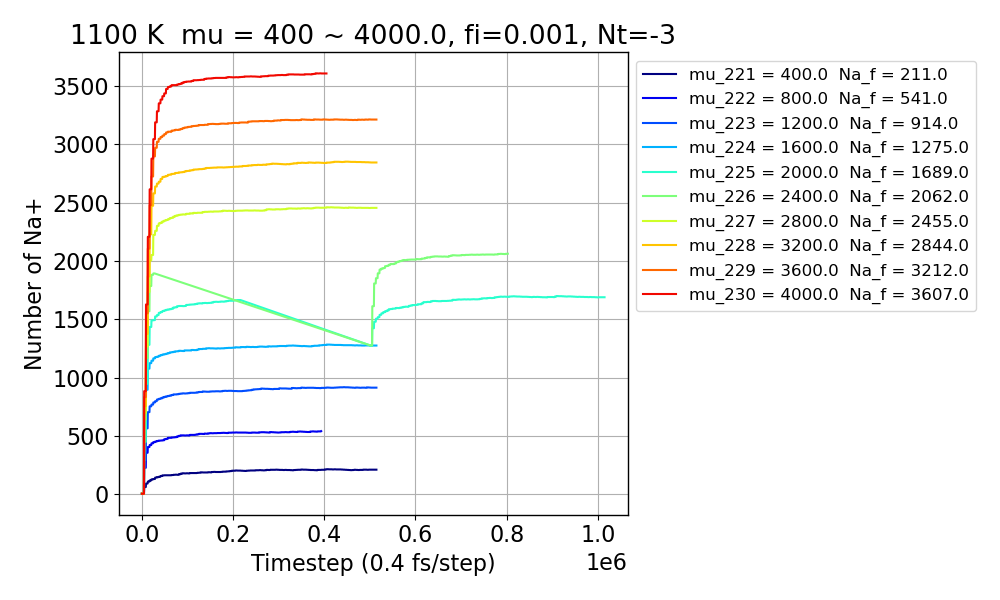

In [25]:
%matplotlib widget
plot_Na_profile_bias(1100, 220, 230, 400, 400, 0.001, -3)

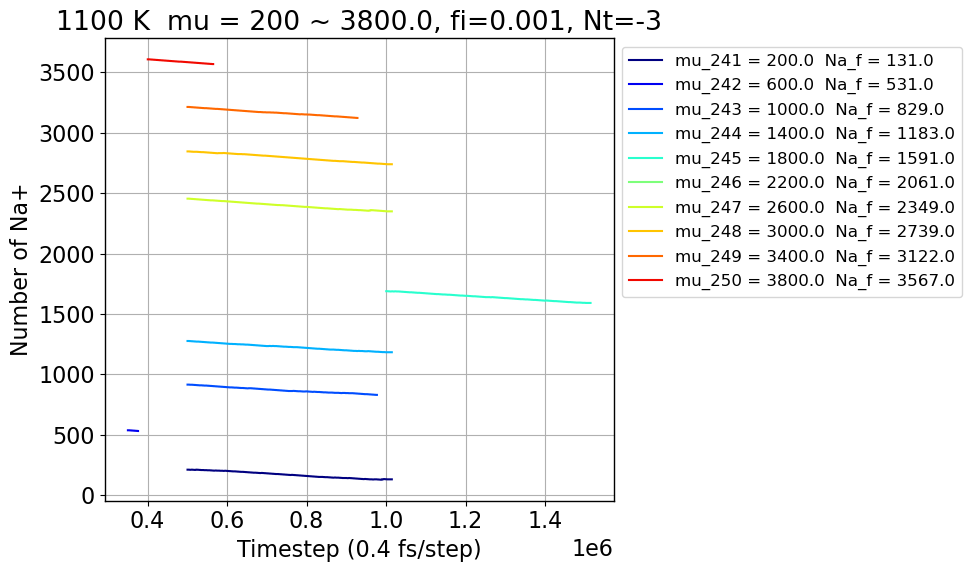

In [38]:
#%matplotlib widget
plot_Na_profile_bias(1100, 240, 250, 200, 400, 0.001, -3,0)

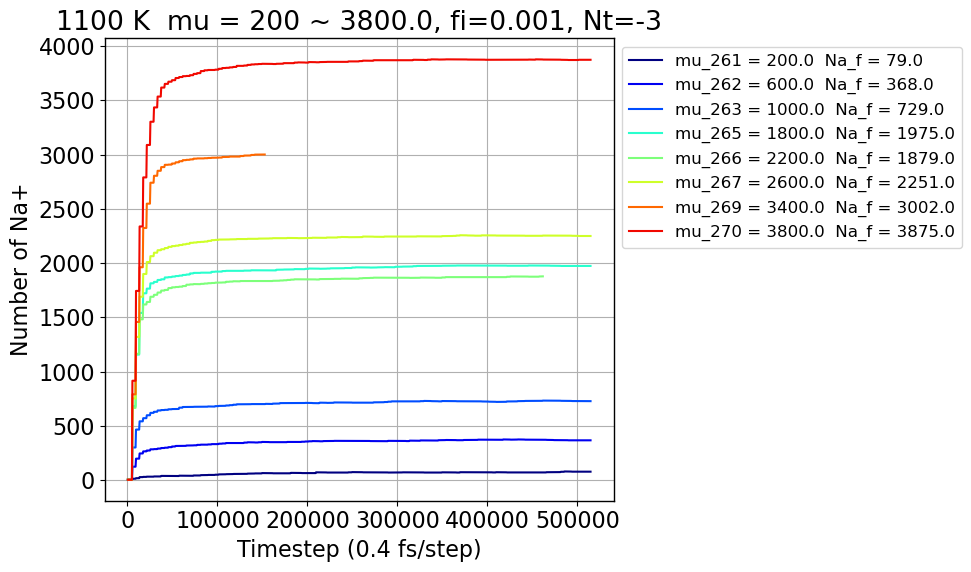

In [24]:
#%matplotlib widget
plot_Na_profile_bias(1100, 260, 270, 200, 400, 0.001, -3, 0)

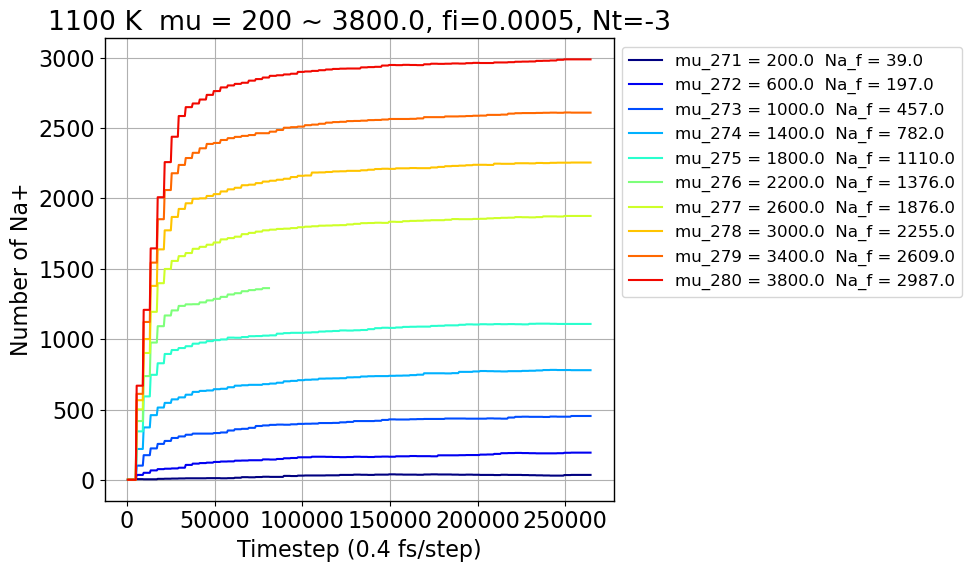

In [19]:
#%matplotlib widget
plot_Na_profile_bias(1100, 270, 280, 200, 400, 0.0005, -3,0)

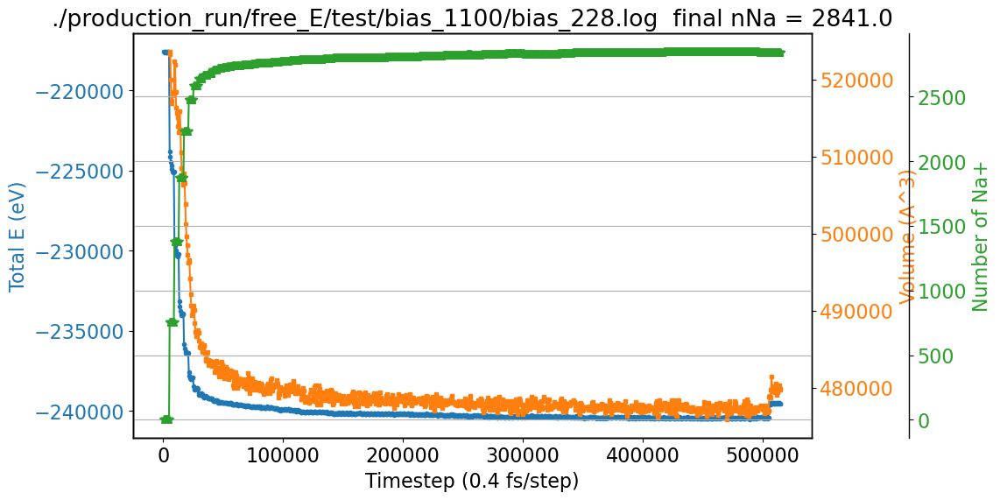

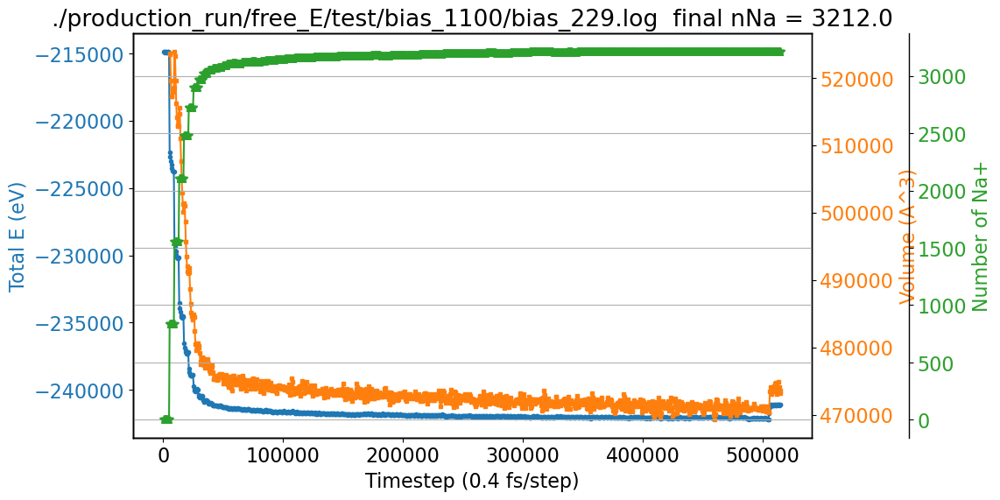

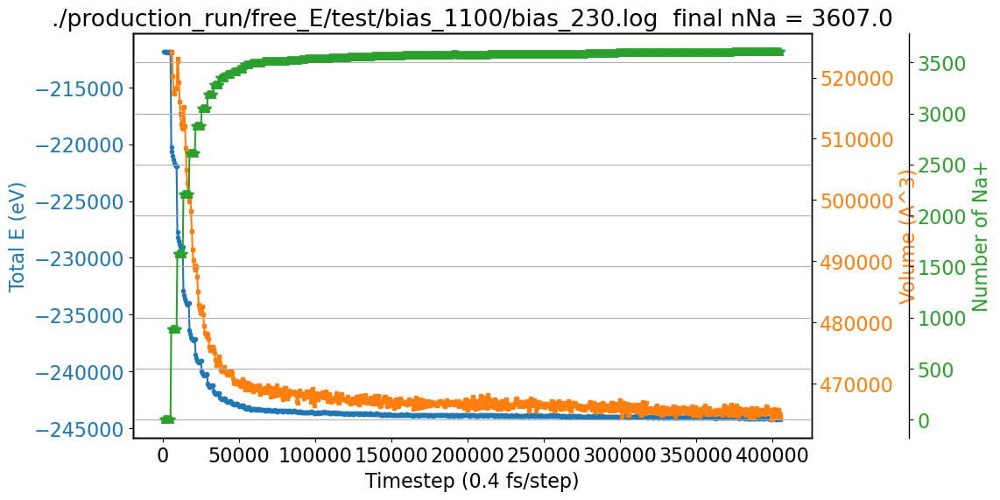

In [37]:
temp=1100
for i in range(228,231):
    file = f'./production_run/free_E/test/bias_{temp}/bias_{i}.log'
    plot_log_free(file)

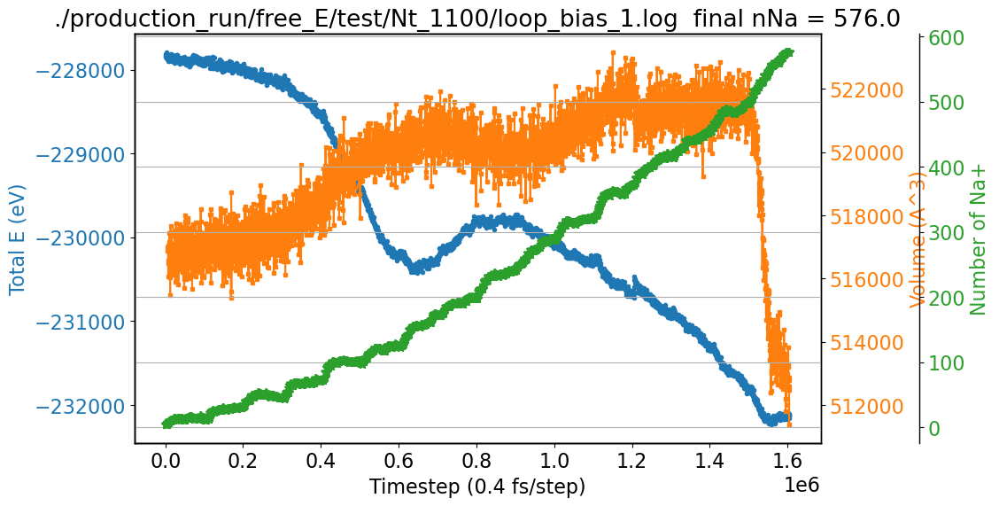

In [18]:
temp=1100

file = f'./production_run/free_E/test/Nt_{temp}/loop_bias_1.log'
plot_log_free(file)

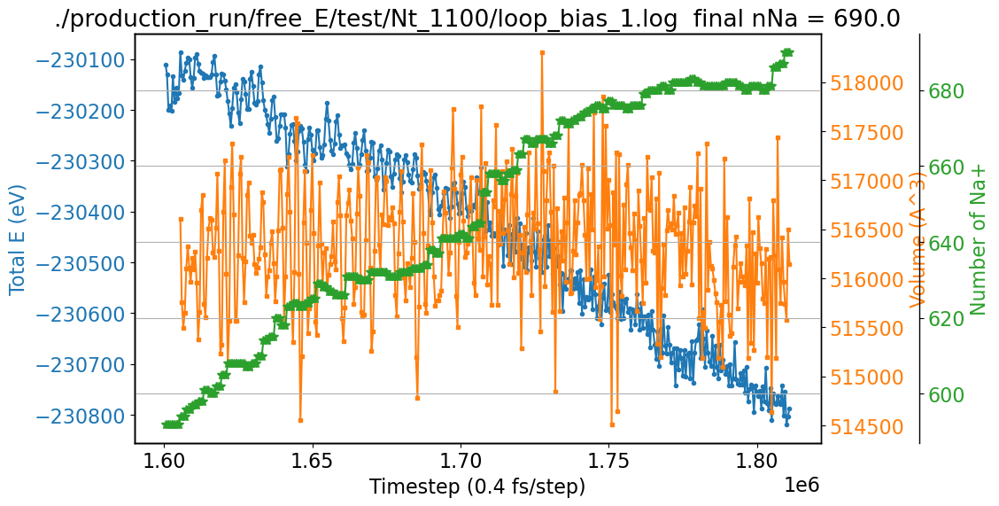

In [20]:
temp=1100

file = f'./production_run/free_E/test/Nt_{temp}/loop_bias_1.log'
plot_log_free(file)

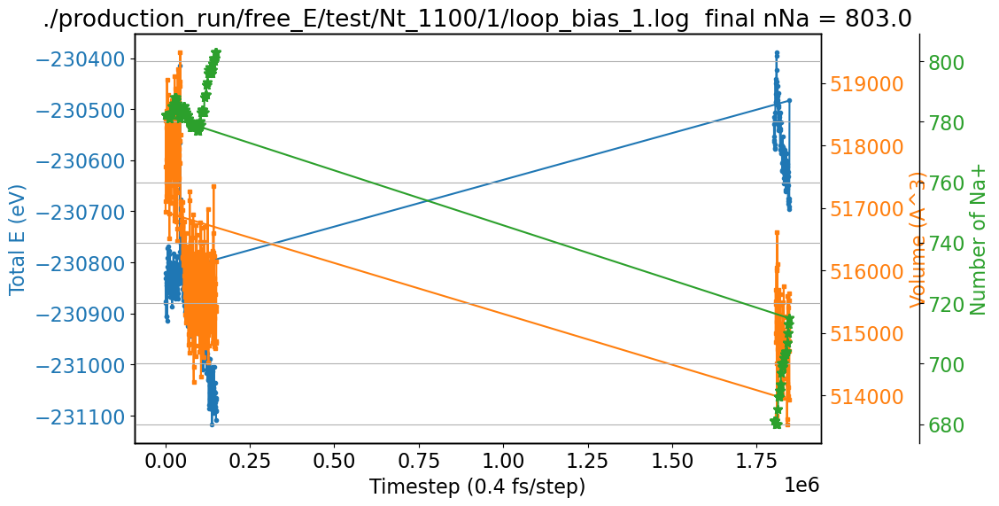

In [29]:
temp=1100

file = f'./production_run/free_E/test/Nt_{temp}/1/loop_bias_1.log'
plot_log_free(file)

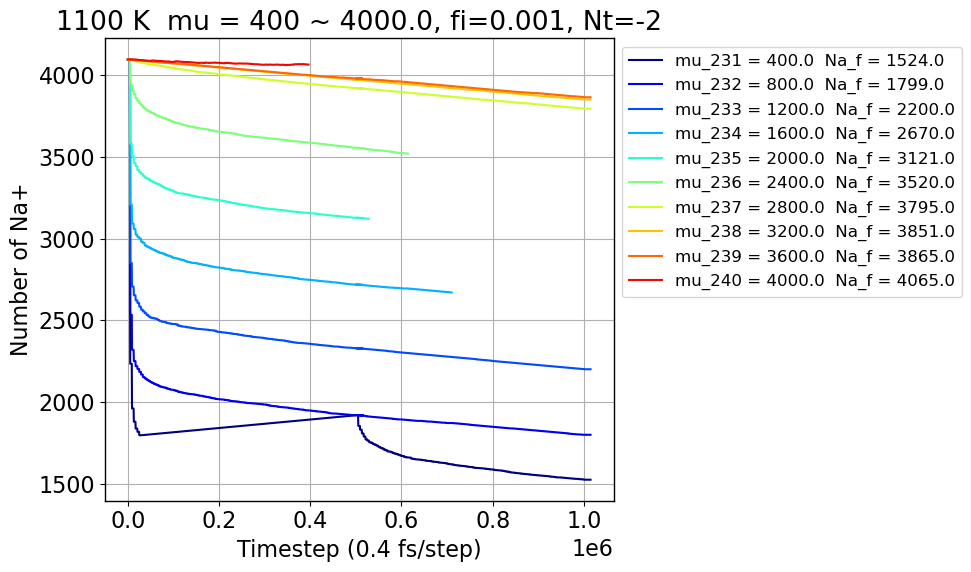

In [19]:
plot_Na_profile_bias(1100, 230, 240, 400, 400, 0.001, -2)

Text(0, 0.5, 'delta E (eV)')

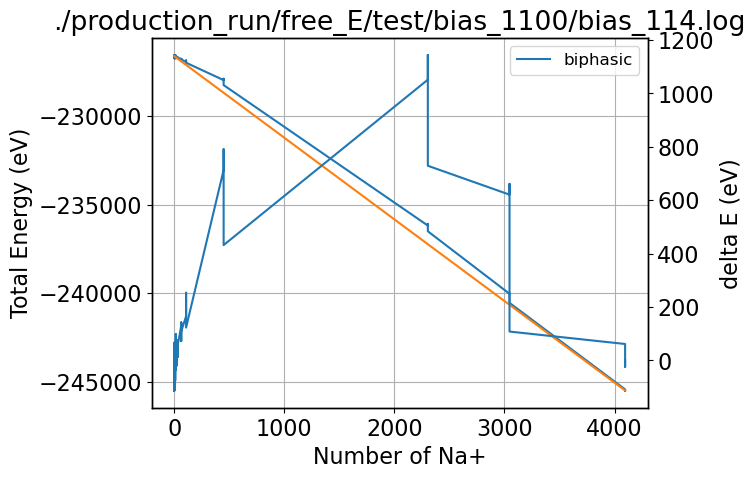

In [39]:
temp=1100
i=114
file = f'./production_run/free_E/test/bias_{temp}/bias_{i}.log'
log_data = parse_lammps_free(file)

i=-100
x0 = log_data['v_nNa'][0]
x1 = log_data['v_nNa'][i]
y0 = log_data['TotEng'][0]
y1 = log_data['TotEng'][i]

slope = (y1 - y0) / (x1 - x0)
intercept = y0 - slope * x0

x = np.array(log_data['v_nNa'][:i])
y = np.array(log_data['TotEng'][:i])

y_linear = slope * x + intercept
difference = y - y_linear

plt.plot(log_data['v_nNa'][:i],log_data['TotEng'][:i],label='biphasic')
plt.plot([log_data['v_nNa'][0],log_data['v_nNa'][i]], [log_data['TotEng'][0],log_data['TotEng'][i]])
plt.legend()
plt.grid()
plt.xlabel('Number of Na+')
plt.ylabel('Total Energy (eV)')
plt.title(f'{file}')
plt2=plt.twinx()

plt2.plot(log_data['v_nNa'][:i],difference)
plt2.set_ylabel('delta E (eV)')

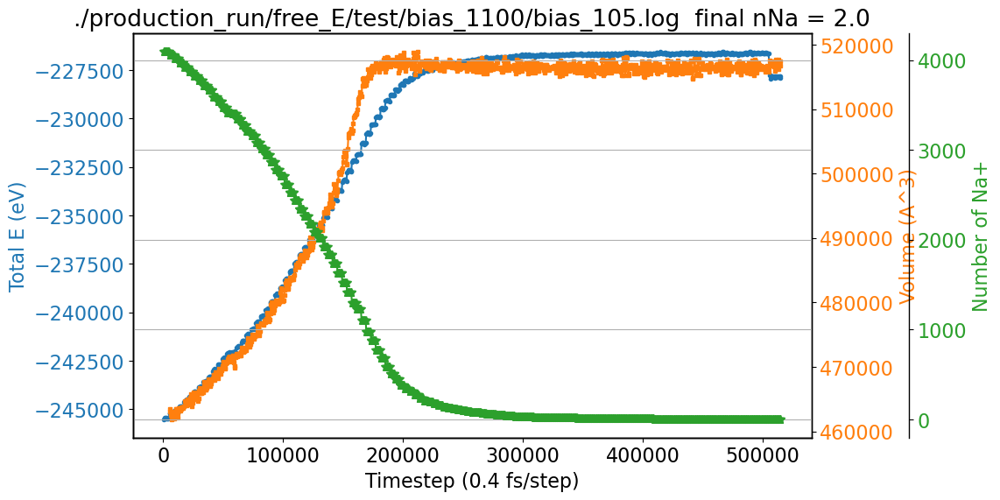

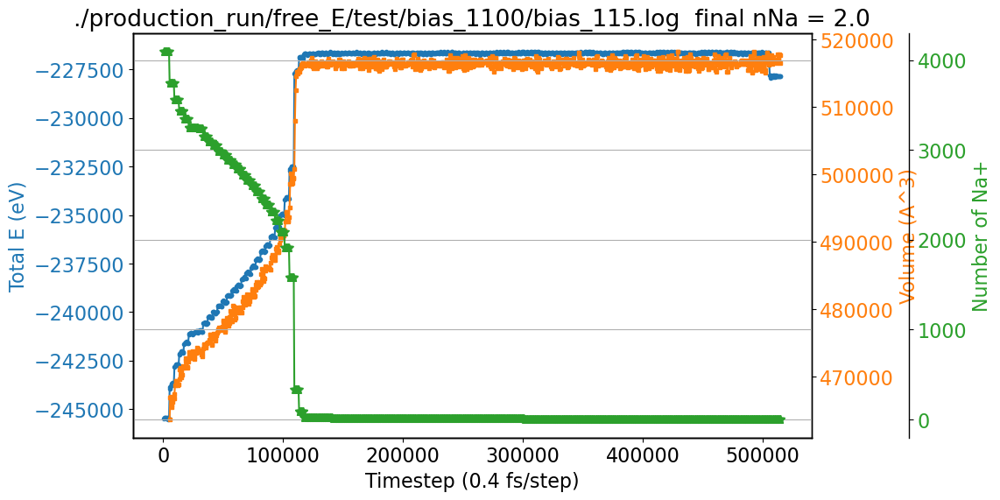

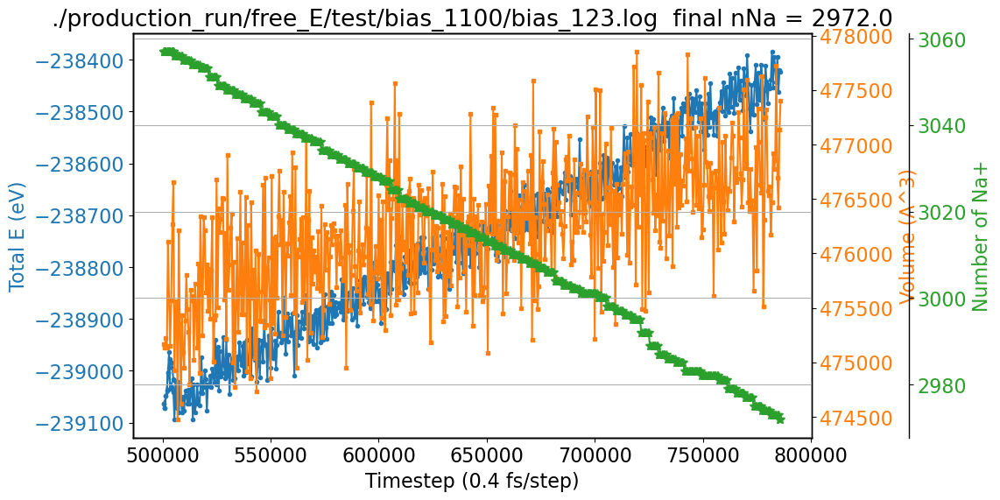

In [37]:
temp=1100
for i in [105,115,123]:
    file = f'./production_run/free_E/test/bias_{temp}/bias_{i}.log'
    plot_log_free(file)

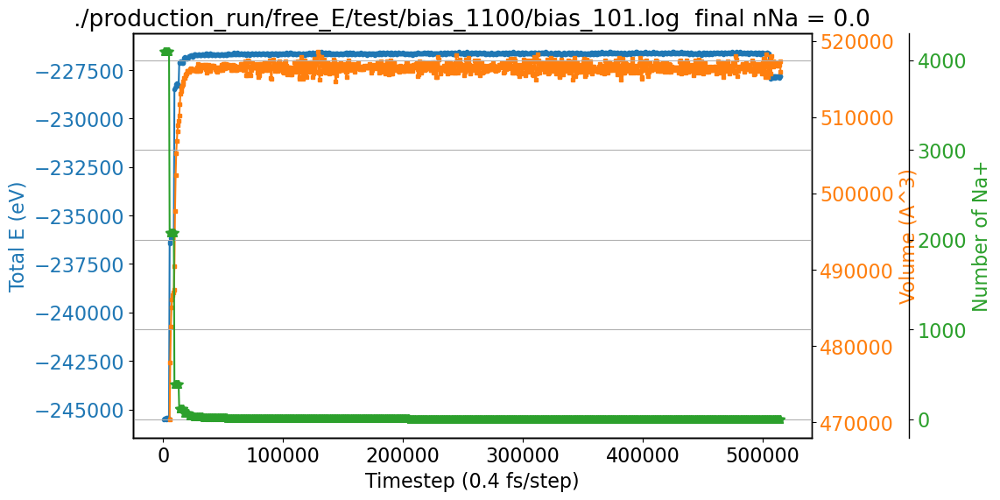

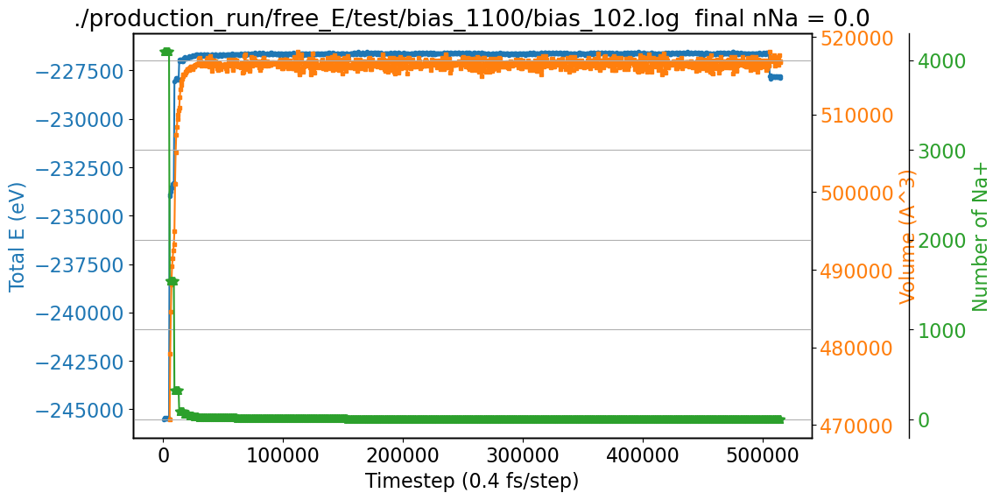

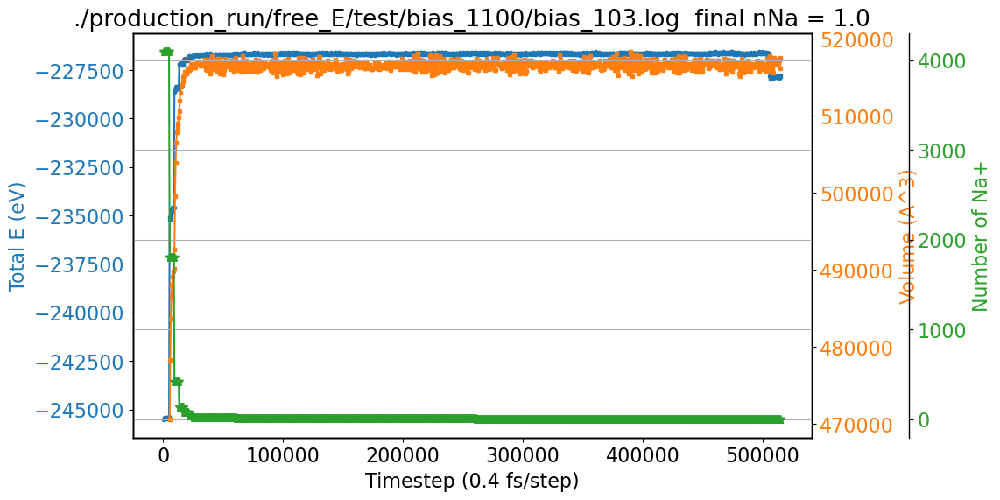

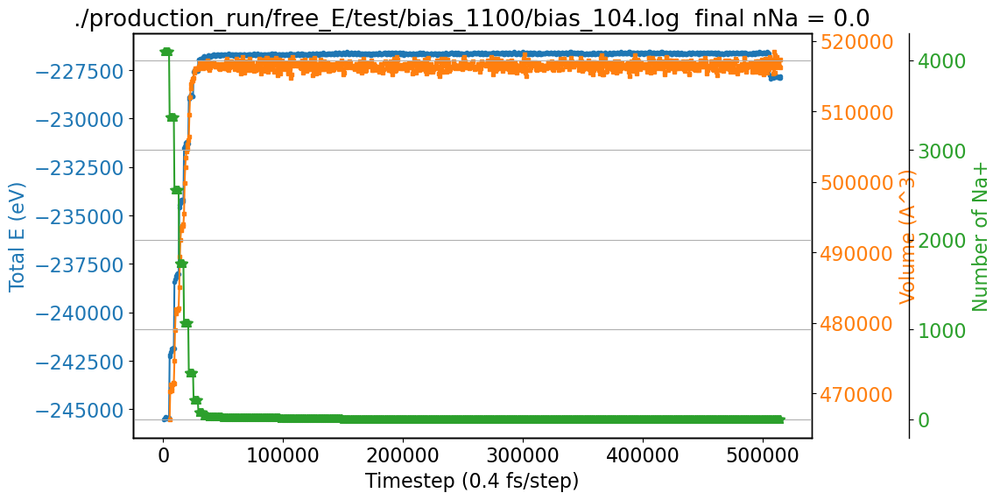

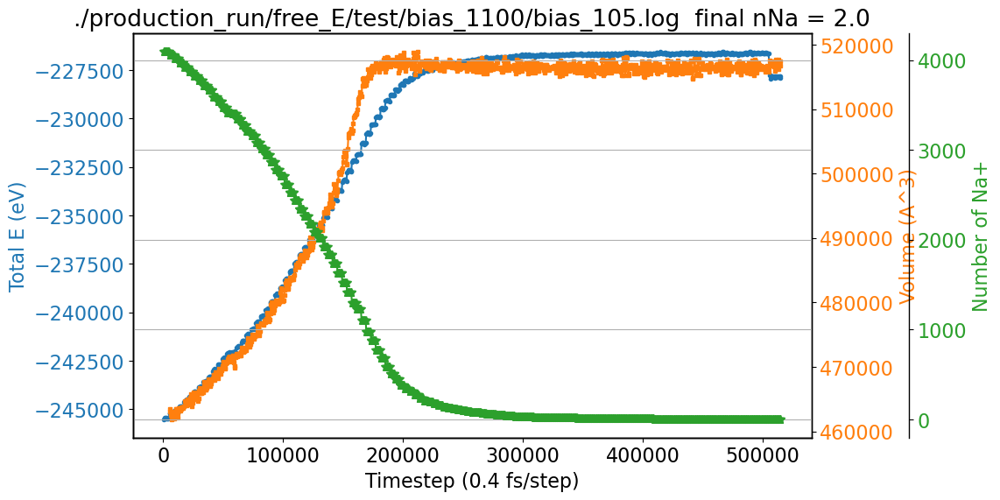

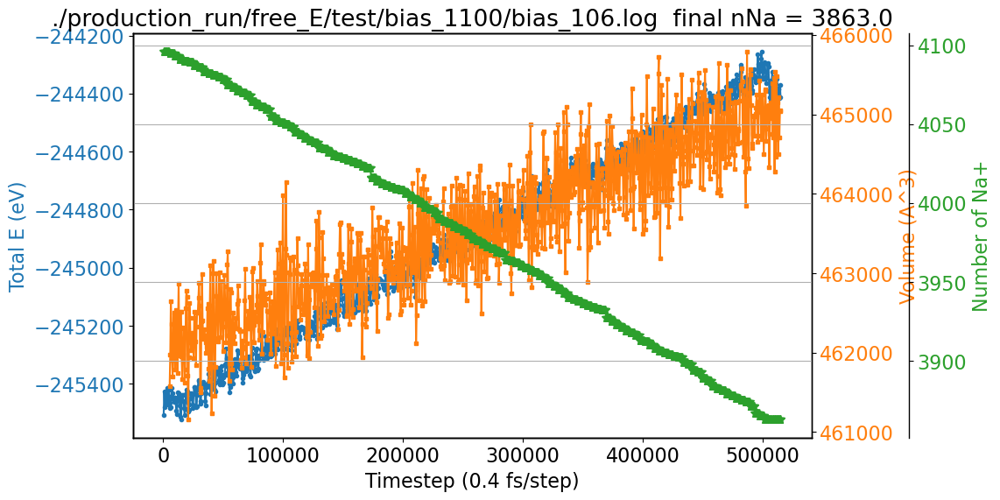

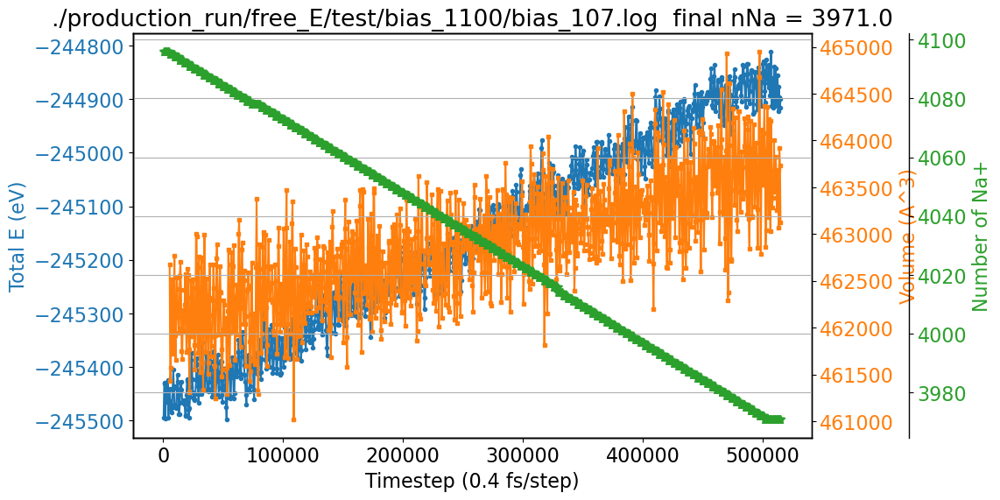

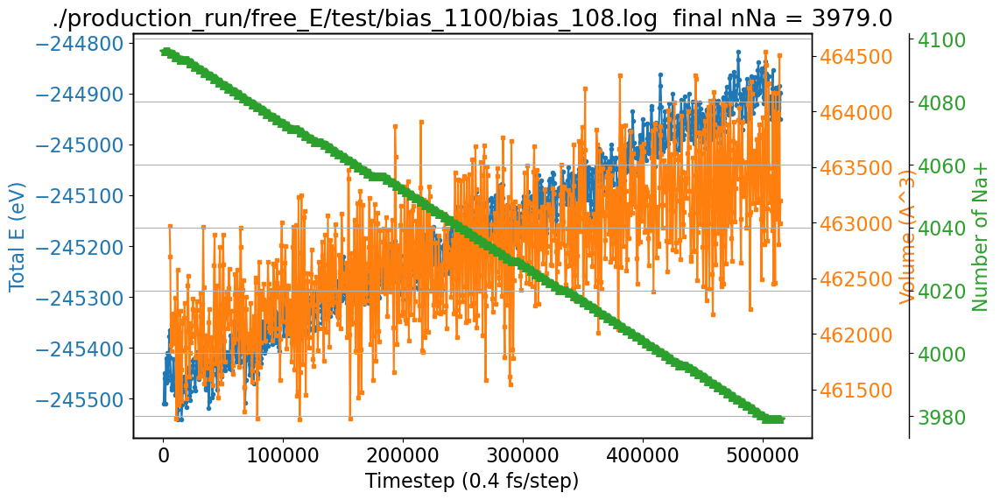

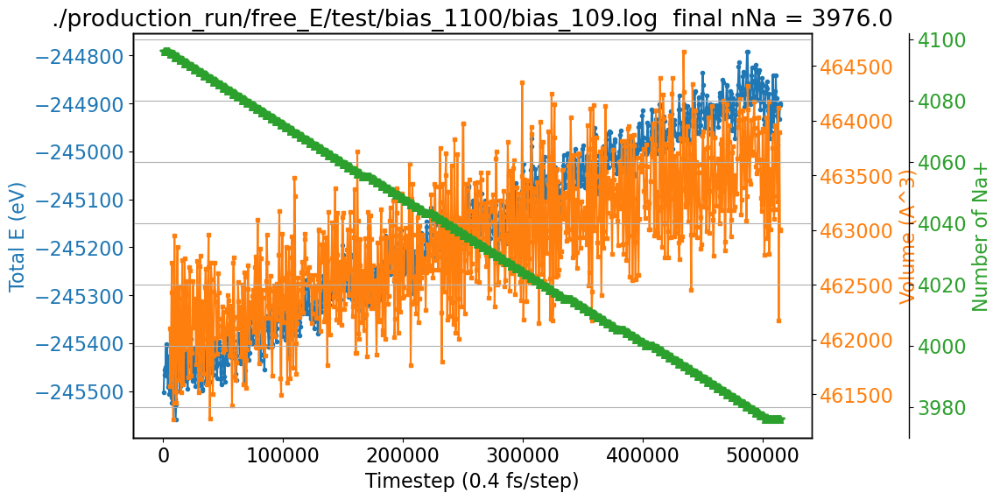

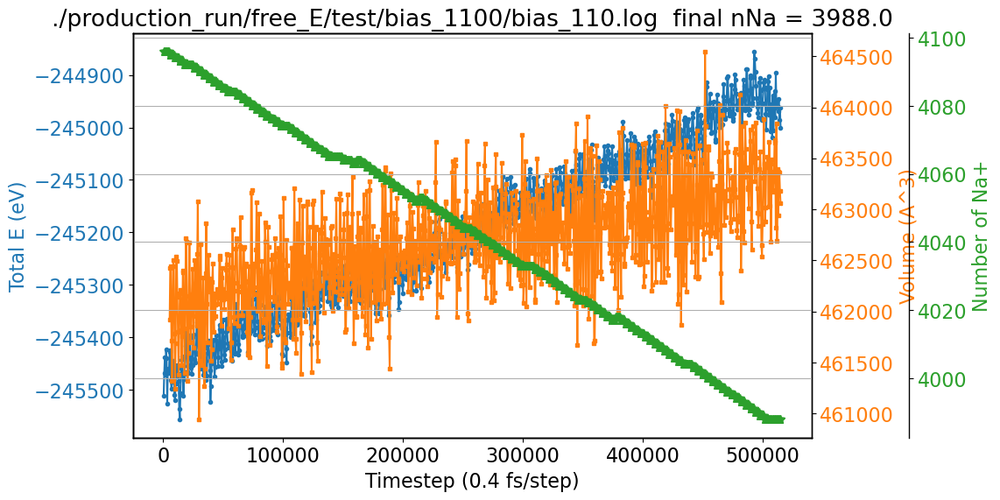

In [29]:
temp=1100
for i in range(101,111):
    file = f'./production_run/free_E/test/bias_{temp}/bias_{i}.log'
    plot_log_free(file)

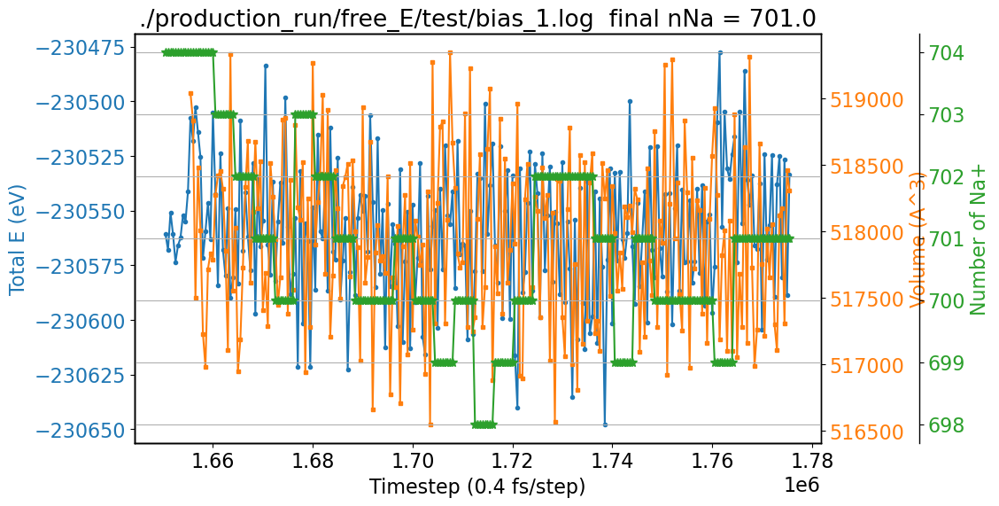

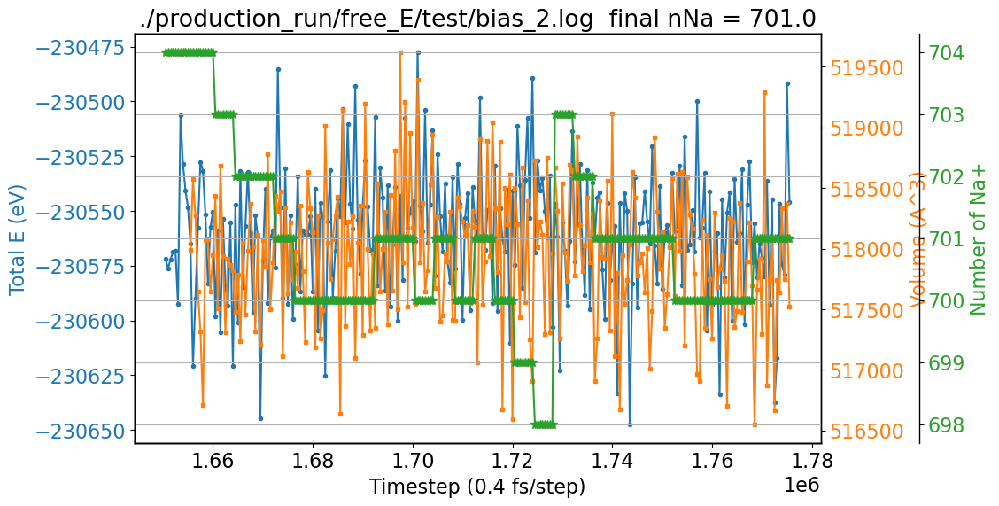

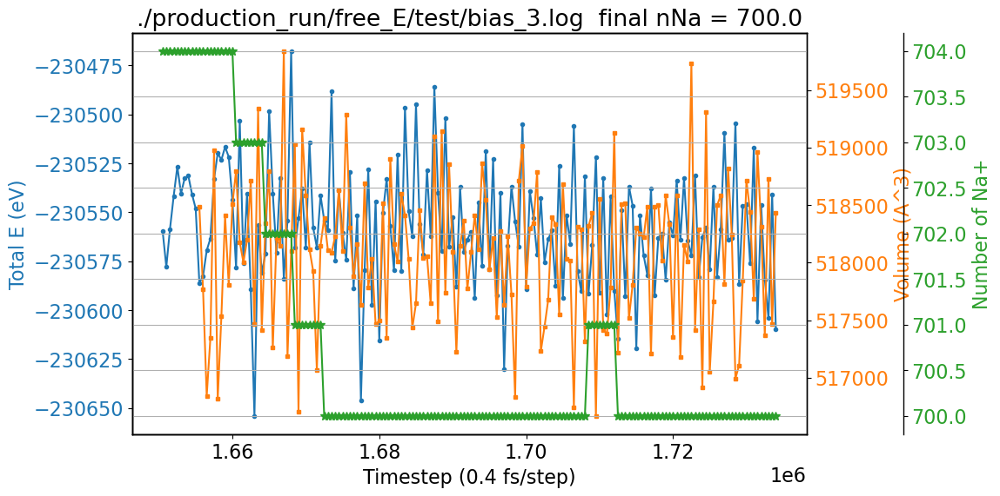

In [37]:
for i in [1,2,3]:
    file = f'./production_run/free_E/test/bias_{i}.log'
    plot_log_free(file)

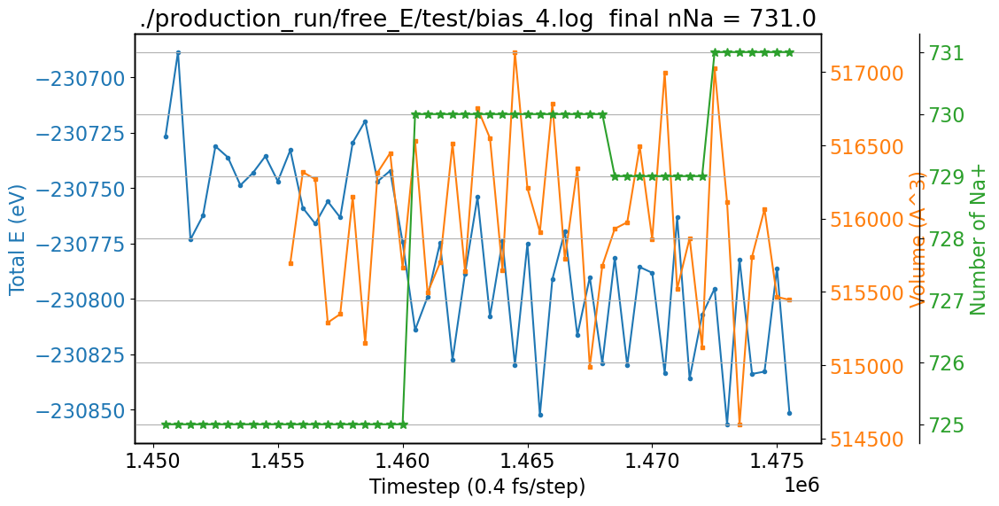

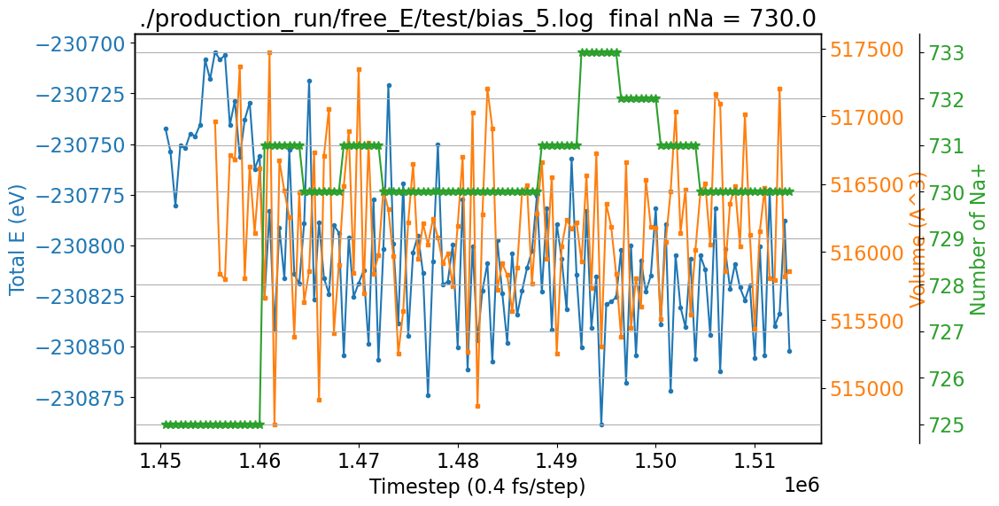

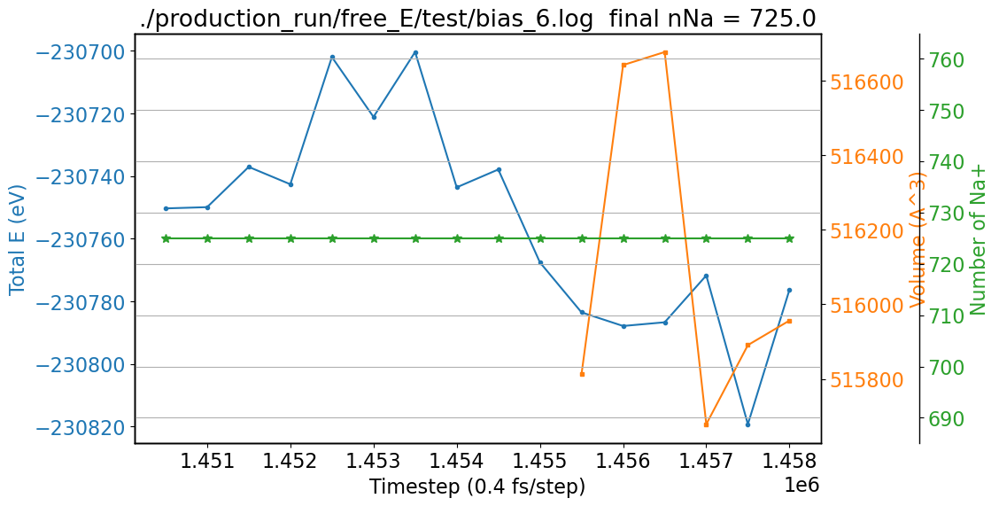

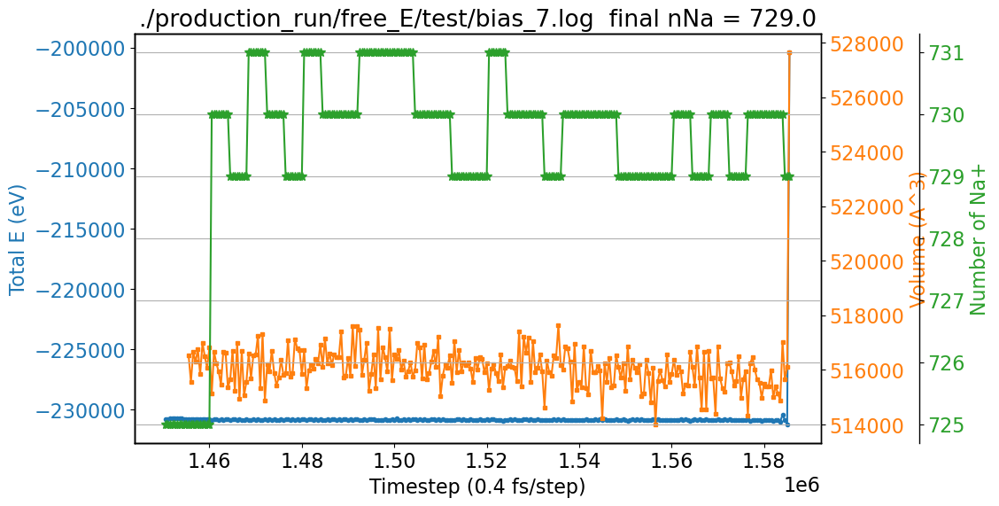

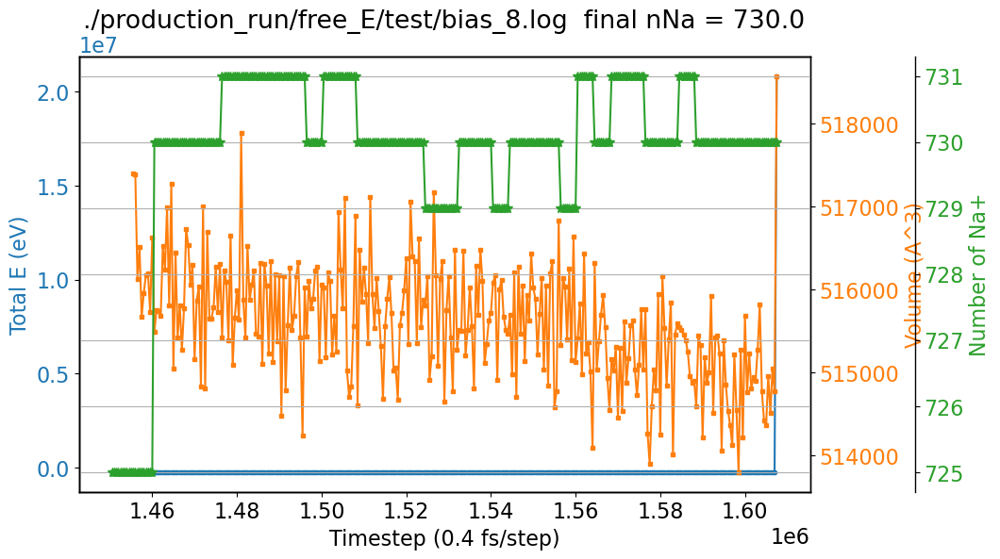

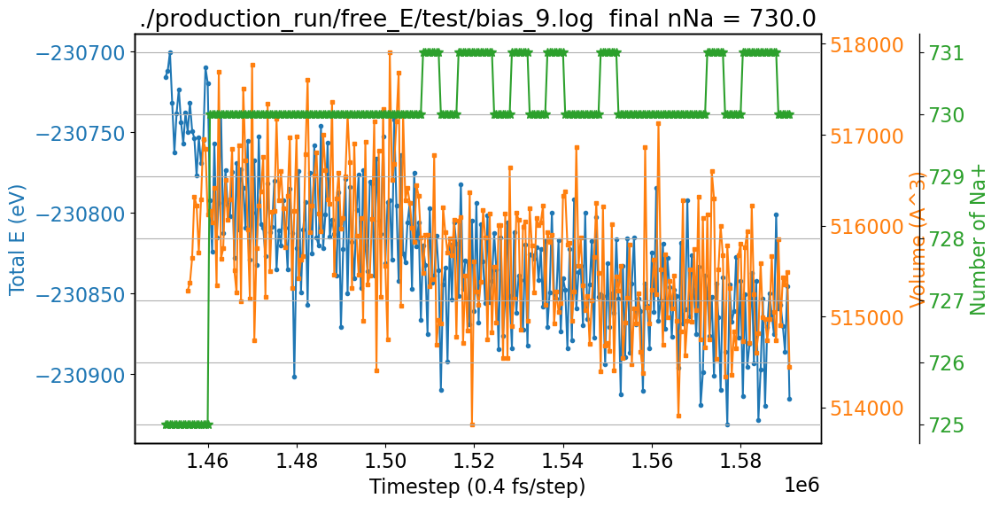

In [38]:
for i in [4,5,6,7,8,9]:
    file = f'./production_run/free_E/test/bias_{i}.log'
    plot_log_free(file)

In [ ]:
for i in [47,48]:
    file = f'./production_run/free_E/test/bias_1100/bias_{i}.log'
    plot_log_free(file)

### Convergence test

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

class ATATEquilibrationDetector:
    def __init__(self, trajectory):
        """
        Initialize ATAT-inspired equilibration time detector.
        
        Parameters:
        -----------
        trajectory : array-like
            Time series data of the property of interest
        """
        self.trajectory = np.array(trajectory)
        self.num_steps = len(trajectory)
    
    def calculate_block_averages(self, max_block_size=None):
        """
        Calculate block averages to estimate equilibration time.
        
        Parameters:
        -----------
        max_block_size : int, optional
            Maximum block size to consider. If None, defaults to 1/4 of trajectory length
        
        Returns:
        --------
        dict
            Block average analysis results
        """
        if max_block_size is None:
            max_block_size = self.num_steps // 4
        
        block_variances = []
        block_sizes = []
        
        for block_size in range(1, max_block_size + 1):
            # Number of non-overlapping blocks
            num_blocks = self.num_steps // block_size
            
            # Truncate trajectory to full blocks
            truncated_traj = self.trajectory[:num_blocks * block_size]
            
            # Reshape into blocks
            blocks = truncated_traj.reshape((num_blocks, block_size))
            
            # Calculate block means
            block_means = np.mean(blocks, axis=1)
            
            # Calculate variance of block means
            block_mean_variance = np.var(block_means)
            
            block_variances.append(block_mean_variance)
            block_sizes.append(block_size)
        
        return {
            'block_sizes': block_sizes,
            'block_variances': block_variances
        }
    
    def estimate_equilibration_time(self, method='variance_plateau', threshold=0.05):
        """
        Estimate equilibration time using different methods.
        
        Parameters:
        -----------
        method : str, optional
            Method for equilibration detection
            - 'variance_plateau': Detect when block variance stabilizes
            - 'relative_variance': Use relative variance change
        threshold : float, optional
            Threshold for detecting equilibration
        
        Returns:
        --------
        dict
            Equilibration time estimation results
        """
        # Calculate block averages
        block_analysis = self.calculate_block_averages()
        block_sizes = block_analysis['block_sizes']
        block_variances = block_analysis['block_variances']
        
        if method == 'variance_plateau':
            # Find where variance stabilizes (minimal change)
            variance_changes = np.diff(block_variances)
            
            # Find where variance changes become minimal
            equilibration_index = np.argmin(np.abs(variance_changes)) + 1
            equilibration_time = block_sizes[equilibration_index]
        
        elif method == 'relative_variance':
            # Normalize variances
            normalized_variances = np.array(block_variances) / block_variances[0]
            
            # Find where relative variance change is below threshold
            equilibration_indices = np.where(normalized_variances < (1 + threshold))[0]
            
            # Take the first point where variance stabilizes
            equilibration_index = equilibration_indices[0] if len(equilibration_indices) > 0 else 0
            equilibration_time = block_sizes[equilibration_index]
        
        else:
            raise ValueError("Invalid method. Choose 'variance_plateau' or 'relative_variance'")
        
        return {
            'equilibration_time': equilibration_time,
            'block_sizes': block_sizes,
            'block_variances': block_variances,
            'method': method
        }
    
    def plot_block_analysis(self, block_analysis):
        """
        Visualize block analysis results.
        
        Parameters:
        -----------
        block_analysis : dict
            Results from estimate_equilibration_time method
        """
        plt.figure(figsize=(12, 6))
        
        # Plot block variances
        plt.subplot(2, 1, 1)
        plt.plot(block_analysis['block_sizes'], block_analysis['block_variances'], 'b-')
        plt.title('Block Variance Analysis')
        plt.xlabel('Block Size')
        plt.ylabel('Block Variance')
        
        # Highlight equilibration time
        plt.axvline(x=block_analysis['equilibration_time'], color='r', linestyle='--', 
                    label=f"Equilibration Time: {block_analysis['equilibration_time']}")
        plt.legend()
        
        # Plot original trajectory
        plt.subplot(2, 1, 2)
        plt.plot(self.trajectory)
        plt.title('Original Trajectory')
        plt.xlabel('Step')
        plt.ylabel('Value')
        plt.axvline(x=block_analysis['equilibration_time'], color='r', linestyle='--')
        
        plt.tight_layout()
        plt.show()

def analyze_equilibration(trajectory, methods=None):
    """
    Comprehensive equilibration analysis using ATAT-inspired methods.
    
    Parameters:
    -----------
    trajectory : array-like
        Time series data to analyze
    methods : list, optional
        Methods to use for equilibration detection
    
    Returns:
    --------
    dict
        Equilibration analysis results
    """
    # Create detector
    detector = ATATEquilibrationDetector(trajectory)
    
    # Default methods if not specified
    if methods is None:
        methods = ['variance_plateau', 'relative_variance']
    
    # Store results
    results = {}
    
    # Analyze using different methods
    for method in methods:
        try:
            block_analysis = detector.estimate_equilibration_time(method=method)
            results[method] = block_analysis
            
            # Visualize results
            detector.plot_block_analysis(block_analysis)
        except Exception as e:
            print(f"Error with method {method}: {e}")
    
    return results

# Example usage function
def main():
    # Example: Replace with your actual trajectory data
    import numpy as np
    
    # Simulate a trajectory with equilibration
    np.random.seed(42)
    initial_fluctuation = np.random.normal(10, 2, 200)
    equilibrated_region = np.random.normal(10, 0.5, 800)
    trajectory = np.concatenate([initial_fluctuation, equilibrated_region])
    
    # Perform equilibration analysis
    results = analyze_equilibration(trajectory)
    
    # Print detailed results
    for method, analysis in results.items():
        print(f"\nMethod: {method}")
        print(f"Estimated Equilibration Time: {analysis['equilibration_time']} steps")

# Uncomment to run in script
# if __name__ == '__main__':
#     main()

In [ ]:
temp, i = 1100, 8
file = f'./production_run/free_E/test/{temp}/free_{i}.log'

parsed_data = parse_lammps_free(file)
atoms_trajectory = parsed_data['atoms']

results = analyze_equilibration(atoms_trajectory)

# Print detailed results
for method, analysis in results.items():
    print(f"\nMethod: {method}")
    print(f"Estimated Equilibration Time: {analysis['equilibration_time']} steps")

### Convergence test 2

In [50]:
step_2,window_size

(289, 27)

0 12
12 24
24 36
36 48
48 60


Text(0.5, 1.0, './production_run/free_E/test/Nt_1100/3/atoms_log_1.txt')

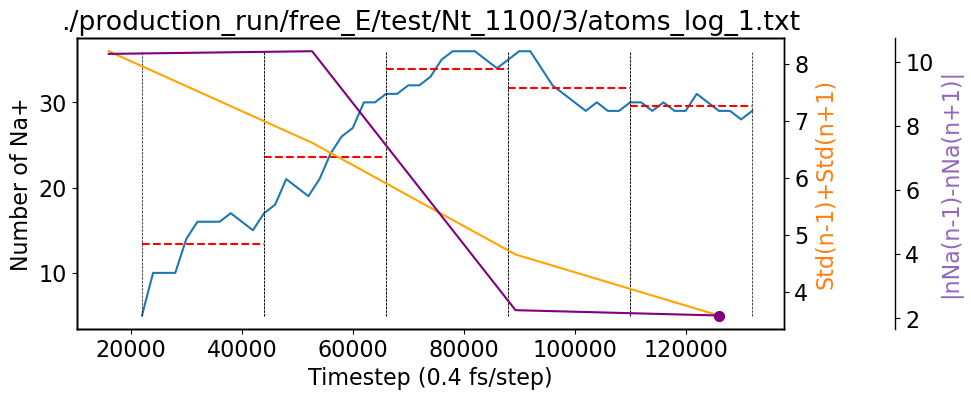

In [41]:
i=1
file = f'./production_run/free_E/test/Nt_1100/3/atoms_log_{i}.txt'
window_fraction=0.2
f=1

if f == 0:
    log_data = parse_lammps_free(file)
    precision=0.005*4096
    window_fraction=window_fraction
    step = np.array(log_data['Step'])
    if log_data['Step'][-1] > 5e5:
        window_size = int((step.shape[0]-30) * window_fraction)
    else:
        window_size = int((step.shape[0]-10) * window_fraction)
    n_Na = np.array(log_data['atoms'])-28672
    
elif f != 0:
    log_data = parse_print_file(file)
    precision=0.005*4096
    window_fraction=window_fraction
    step = np.array(log_data['Step'])
    window_size = int(int(step.shape[0]) * window_fraction)
    n_Na = np.array(log_data['atoms'])-28672
    
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(log_data['Step'],n_Na)    

Q_mean_ls=[]
Q_std_ls=[]
for i in range(int(1/window_fraction)):
    # Initial window
    if f == 0:
        step_1 = 9+window_size*(i+0)
        step_2 = 9+window_size*(i+1)
    elif f != 0:
        step_1 = window_size*(i+0)
        step_2 = window_size*(i+1)
    print(step_1,step_2)
    Q_mean = np.mean(n_Na[step_1:step_2])
    Q_mean_ls.append(Q_mean)
    Q_std = np.std(n_Na[step_1:step_2])
    Q_std_ls.append(Q_std)
    if step_2 >= len(log_data['Step']):
        ax1.hlines(Q_mean, log_data['Step'][step_1], log_data['Step'][-1], color='r', linestyles='--')
        ax1.vlines(log_data['Step'][-1], n_Na.min(), n_Na.max(), color='black', linestyles='--', linewidth=0.5)
    elif step_2 < len(log_data['Step']):
        ax1.hlines(Q_mean, log_data['Step'][step_1], log_data['Step'][step_2], color='r', linestyles='--')
        ax1.vlines(log_data['Step'][step_2], n_Na.min(), n_Na.max(), color='black', linestyles='--', linewidth=0.5)
    ax1.vlines(log_data['Step'][step_1], n_Na.min(), n_Na.max(), color='black', linestyles='--', linewidth=0.5)


ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')
Q_mean_ls=np.array(Q_mean_ls)
Q_std_ls=np.array(Q_std_ls)

Q_std_B1_B2_ls = []
for i in range(len(Q_std_ls)-1):
    Q_std_B1_B2_ls.append(Q_std_ls[i]+Q_std_ls[i+1])
Q_std_B1_B2_ls=np.array(Q_std_B1_B2_ls)
ax2=ax1.twinx()
color = 'tab:orange'
x=np.linspace(10000+window_size*500,log_data['Step'][-1]-window_size*500,len(Q_std_B1_B2_ls))
ax2.plot(x, Q_std_B1_B2_ls, color='orange')
ax2.scatter(x[Q_std_B1_B2_ls.argmin()], Q_std_B1_B2_ls.min(), color='orange')
ax2.set_ylabel('Std(n-1)+Std(n+1)', color=color)

Q_diff_ls = []
for i in range(len(Q_mean_ls)-1):
    Q_diff_ls.append(abs(Q_mean_ls[i+1]-Q_mean_ls[i]))

ax3 = ax1.twinx()
color = 'tab:purple'
ax3.spines['right'].set_position(('outward', 80)) 
ax3.set_ylabel('|nNa(n-1)-nNa(n+1)|', color=color)
Q_diff_ls=np.array(Q_diff_ls)
x=np.linspace(10000+window_size*500,log_data['Step'][-1] -window_size*500,len(Q_diff_ls))
ax3.plot(x, Q_diff_ls, color='purple')
ax3.scatter(x[Q_diff_ls.argmin()], Q_diff_ls.min(), color='purple')
plt.tight_layout()
plt.title(f'{file}')

In [64]:
Q_std_B1_B2_ls

array([12.02412951, 11.3806802 ,  8.86227154,  5.50727756])

In [65]:
Q_mean_ls

array([513.5, 532.3, 549.6, 561.2, 573.9])

In [66]:
np.std(n_Na)

21.859780419757193

In [32]:
def plot_convergence(file, window_fraction=0.1, f=0):

    if f == 0:
        log_data = parse_lammps_free(file)
        precision=0.005*4096
        window_fraction=window_fraction
        step = np.array(log_data['Step'])
        if log_data['Step'][-1] > 5e5:
            window_size = int((step.shape[0]-30) * window_fraction)
        else:
            window_size = int((step.shape[0]-10) * window_fraction)
        n_Na = np.array(log_data['atoms'])-28672
        
    elif f != 0:
        log_data = parse_print_file(file)
        precision=0.005*4096
        window_fraction=window_fraction
        step = np.array(log_data['Step'])
        window_size = int(int(step.shape[0]) * window_fraction)
        n_Na = np.array(log_data['atoms'])-28672
        
    fig, ax1 = plt.subplots(figsize=(10, 4))
    ax1.plot(log_data['Step'],n_Na)    
    
    Q_mean_ls=[]
    Q_std_ls=[]
    for i in range(int(1/window_fraction)):
        # Initial window
        if f == 0:
            step_1 = 9+window_size*(i+0)
            step_2 = 9+window_size*(i+1)
        elif f != 0:
            step_1 = window_size*(i+0)
            step_2 = window_size*(i+1)
        Q_mean = np.mean(n_Na[step_1:step_2])
        Q_mean_ls.append(Q_mean)
        Q_std = np.std(n_Na[step_1:step_2])
        Q_std_ls.append(Q_std)
        if step_2 >= len(log_data['Step']):
            ax1.hlines(Q_mean, log_data['Step'][step_1], log_data['Step'][-1], color='r', linestyles='--')
            ax1.vlines(log_data['Step'][-1], n_Na.min(), n_Na.max(), color='black', linestyles='--', linewidth=0.5)
        elif step_2 < len(log_data['Step']):
            ax1.hlines(Q_mean, log_data['Step'][step_1], log_data['Step'][step_2], color='r', linestyles='--')
            ax1.vlines(log_data['Step'][step_2], n_Na.min(), n_Na.max(), color='black', linestyles='--', linewidth=0.5)
        ax1.vlines(log_data['Step'][step_1], n_Na.min(), n_Na.max(), color='black', linestyles='--', linewidth=0.5)
    
    
    ax1.set_xlabel('Timestep (0.4 fs/step)')
    ax1.set_ylabel('Number of Na+')
    Q_mean_ls=np.array(Q_mean_ls)
    Q_std_ls=np.array(Q_std_ls)
    
    Q_std_B1_B2_ls = []
    for i in range(len(Q_std_ls)-1):
        Q_std_B1_B2_ls.append(Q_std_ls[i]+Q_std_ls[i+1])
    Q_std_B1_B2_ls=np.array(Q_std_B1_B2_ls)
    ax2=ax1.twinx()
    color = 'tab:orange'
    x=np.linspace(log_data['Step'][0]+window_size*500,log_data['Step'][-1]-window_size*500,len(Q_std_B1_B2_ls))
    ax2.plot(x, Q_std_B1_B2_ls, color='orange')
    ax2.scatter(x[Q_std_B1_B2_ls.argmin()], Q_std_B1_B2_ls.min(), color='orange')
    ax2.set_ylabel('Std(n-1)+Std(n+1)', color=color)
    
    Q_diff_ls = []
    for i in range(len(Q_mean_ls)-1):
        Q_diff_ls.append(abs(Q_mean_ls[i+1]-Q_mean_ls[i]))
    
    ax3 = ax1.twinx()
    color = 'tab:purple'
    ax3.spines['right'].set_position(('outward', 80)) 
    ax3.set_ylabel('|nNa(n-1)-nNa(n+1)|', color=color)
    Q_diff_ls=np.array(Q_diff_ls)
    x=np.linspace(log_data['Step'][0]+window_size*500,log_data['Step'][-1] -window_size*500,len(Q_diff_ls))
    ax3.plot(x, Q_diff_ls, color='purple')
    ax3.scatter(x[Q_diff_ls.argmin()], Q_diff_ls.min(), color='purple')
    plt.tight_layout()
    plt.title(f'{file}')

In [60]:
np.std(n_Na)

4.9145091311340545

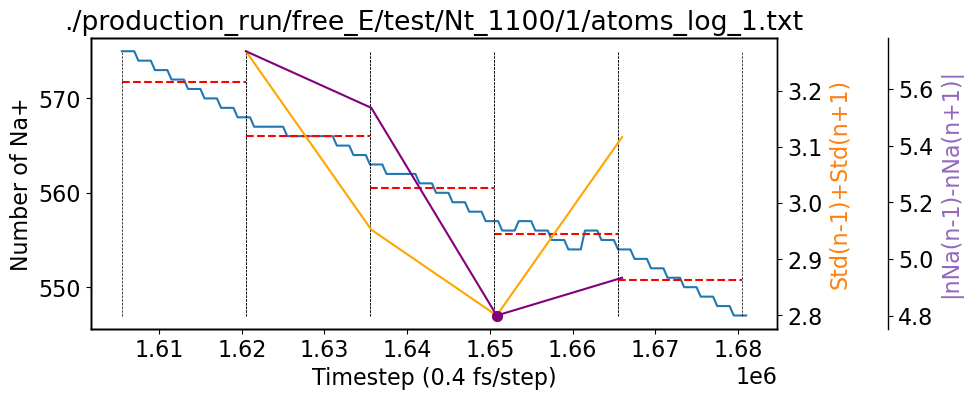

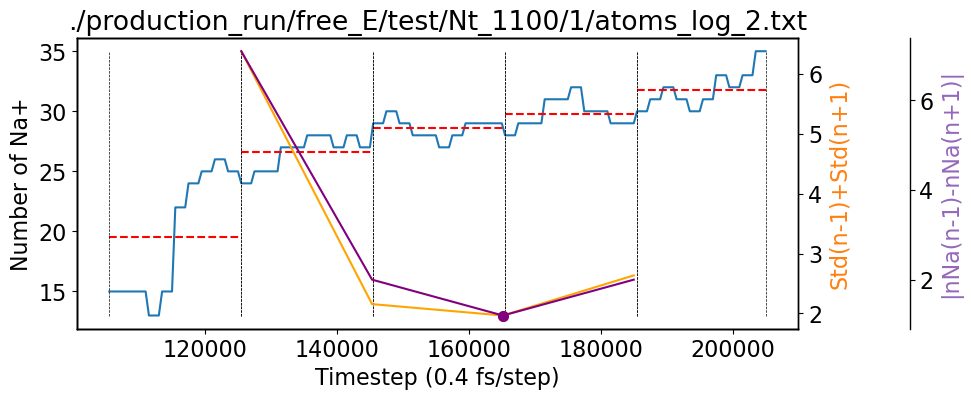

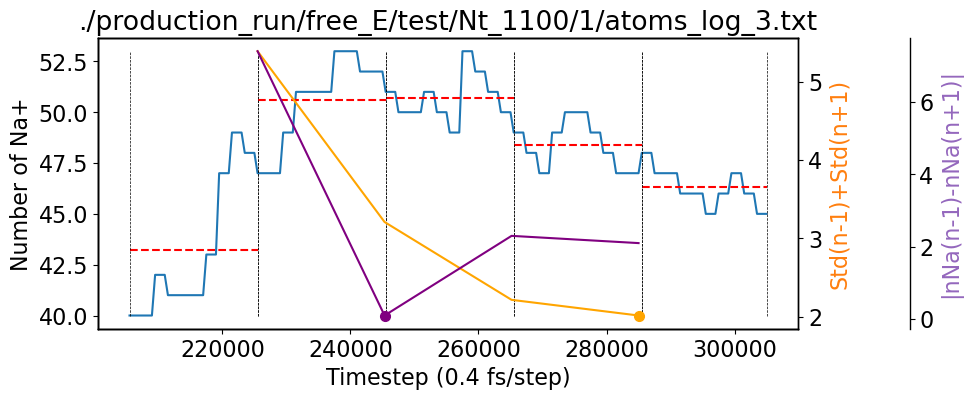

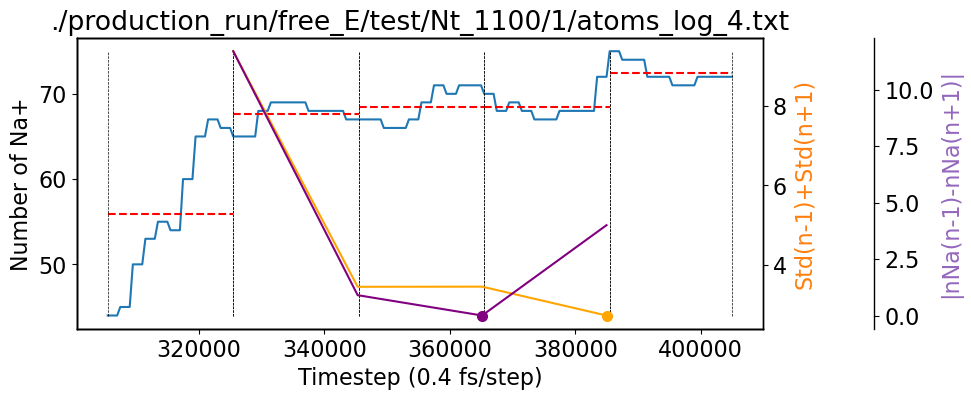

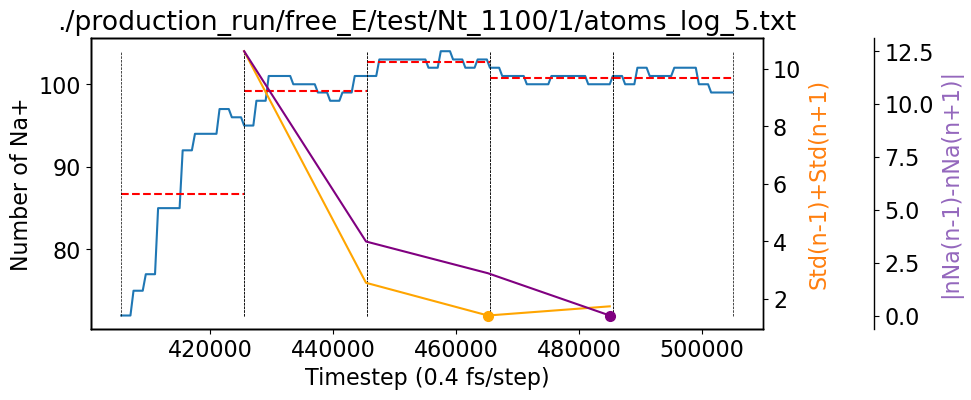

...

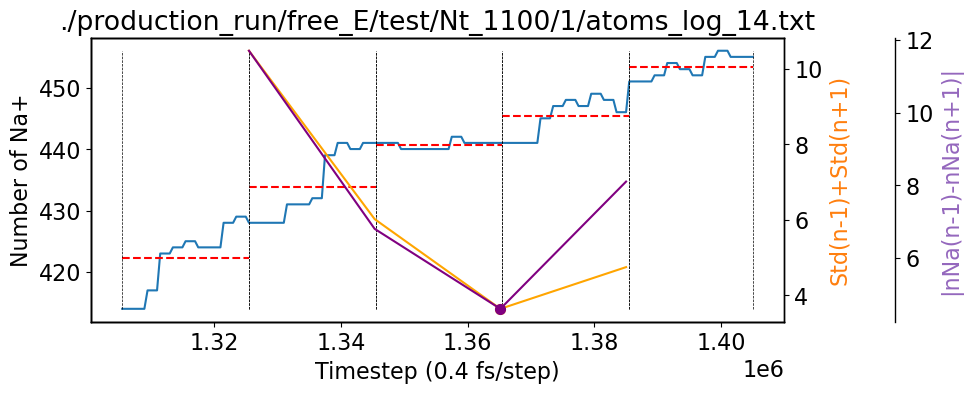

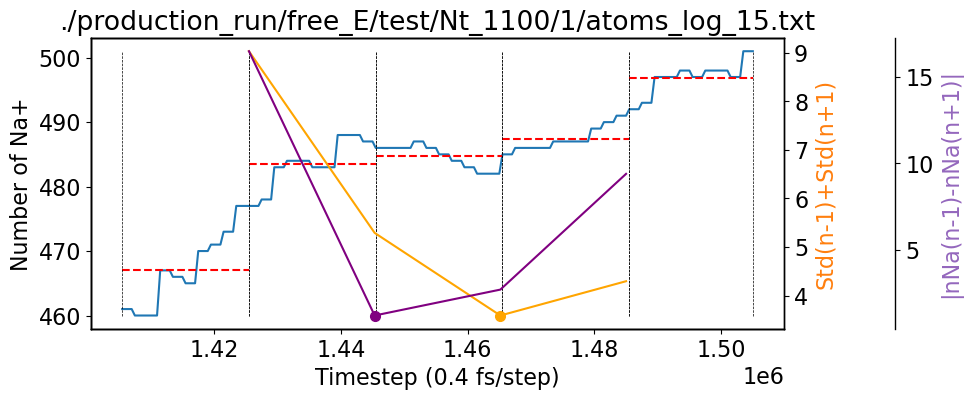

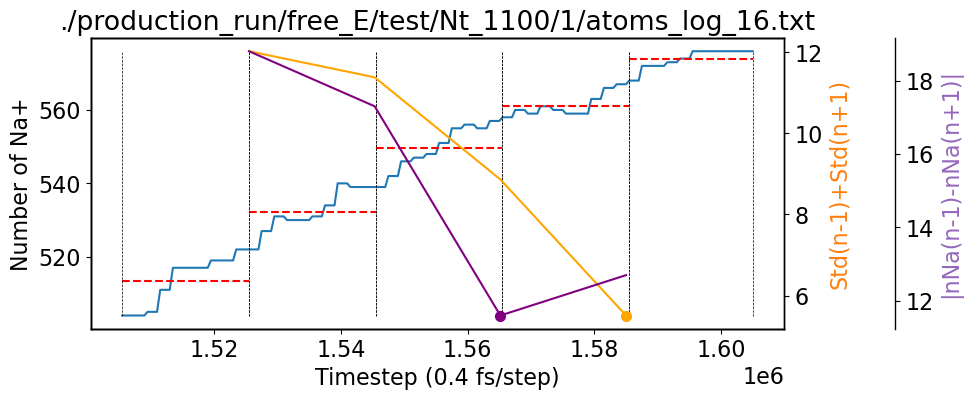

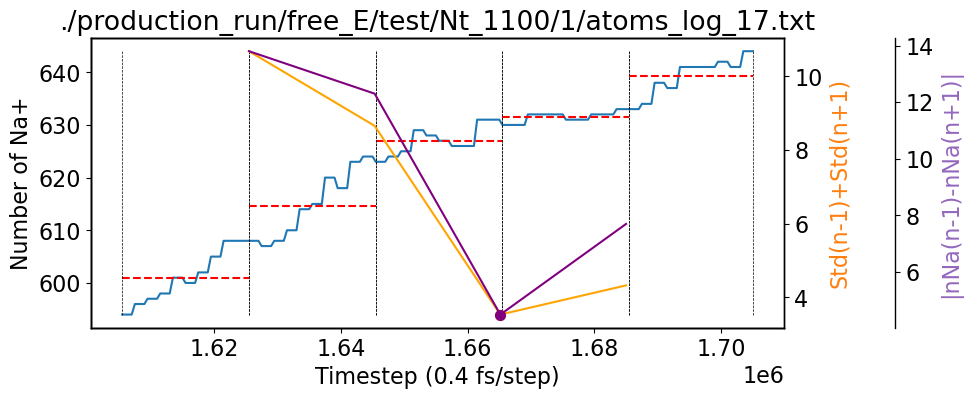

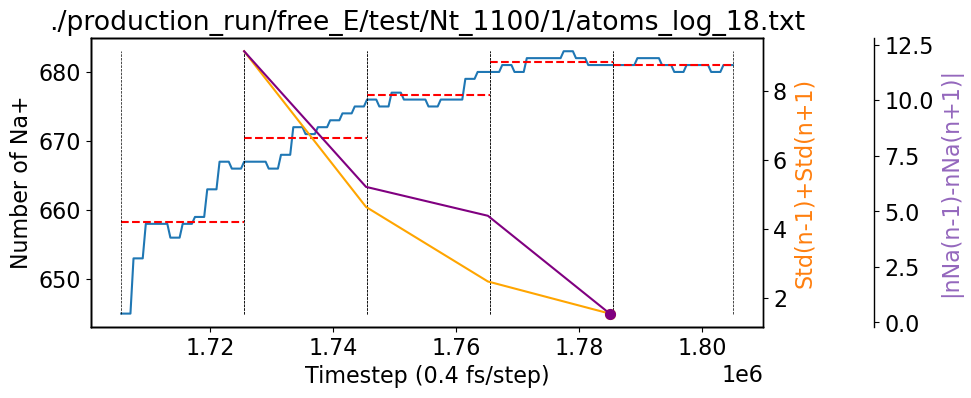

In [35]:
i=18
for i in range(18):
    file = f'./production_run/free_E/test/Nt_1100/1/atoms_log_{i+1}.txt'
    plot_convergence(file, window_fraction=0.2, f=1)

In [66]:
int(3.5)

3

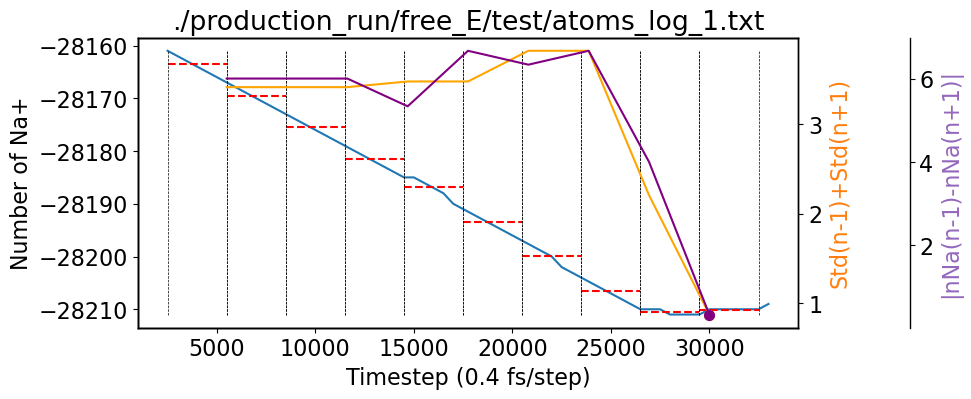

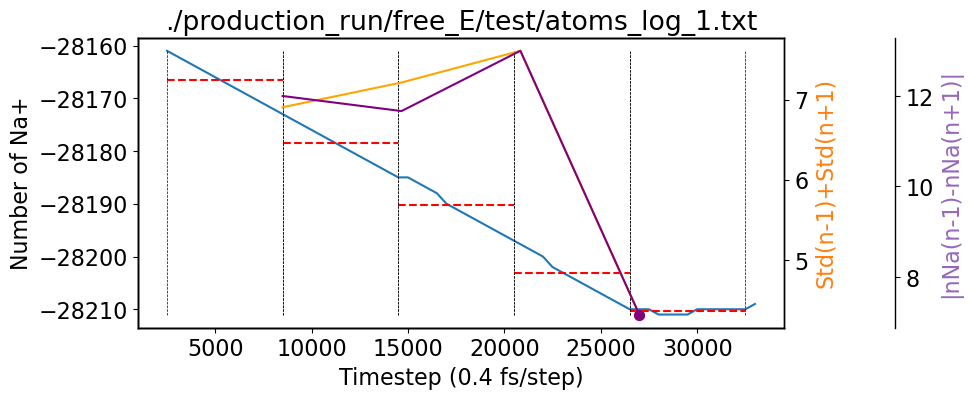

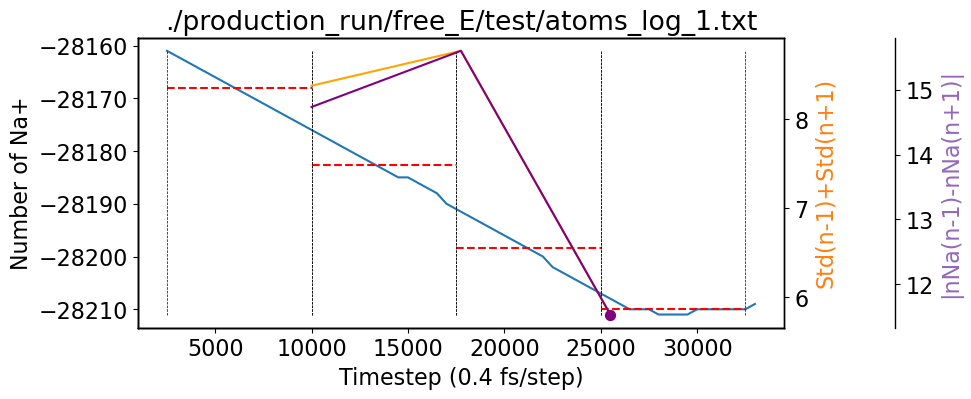

In [48]:
i=1
file = f'./production_run/free_E/test/atoms_log_{i}.txt'
for i in [0.1,0.2,0.25]:
    plot_convergence(file, window_fraction=i, f=1)

In [18]:
def parse_print_file(file_path):
    data = {'Step': [], 'atoms': []}

    with open(file_path, 'r') as file:
        for line in file:
            if re.match(r"^\s*Step\s+Atoms", line):
                next(file)
                for data_line in file:
                    if re.match(r"^\s*\d+", data_line) and len(data_line.split()) == 2:
                        values = data_line.split()
                        data['Step'].append(int(values[0]))
                        data['atoms'].append(float(values[1]))
                    else:
                        break

In [25]:
log_data

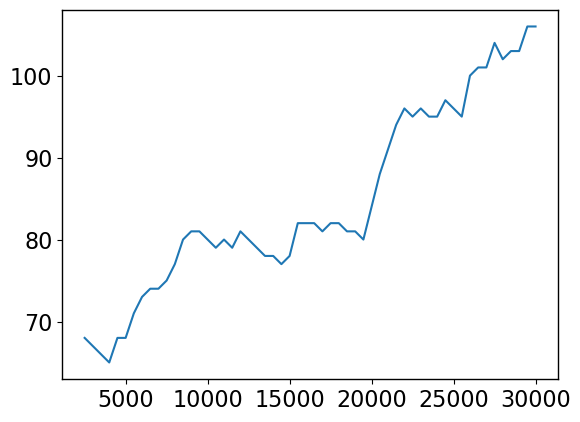

In [28]:
fig = plt.figure()
i=1
file = f'./production_run/free_E/test/atoms_log_{i}.txt'
log_data = parse_print_file(file)
step = np.array(log_data['Step'])
n_Na = np.array(log_data['atoms']) - 3584 # Adjust baseline as needed
plt.plot(step, n_Na, label=f'Nf_{i}={n_Na[-1]}, Nt={Nt}')
#plt.plot([step[0],step[-1]], [Nt, Nt], color='black')

### LOOP

In [18]:
import re
import numpy as np
from lammps import lammps

def parse_print_file(file_path):
    data = {'Step': [], 'atoms': []}

    with open(file_path, 'r') as file:
        for line in file:
            if re.match(r"^\s*Step\s+Atoms", line):
                next(file)
                for data_line in file:
                    if re.match(r"^\s*\d+", data_line) and len(data_line.split()) == 2:
                        values = data_line.split()
                        data['Step'].append(int(values[0]))
                        data['atoms'].append(float(values[1]))
                    else:
                        break

In [11]:
def parse_print_file(file_path):
    """
    Parse a LAMMPS print file with Step and Atoms columns.
    
    Args:
        file_path (str): Path to the LAMMPS output file
        
    Returns:
        dict: Dictionary with 'Step' and 'atoms' arrays
    """
    data = {'Step': [], 'atoms': []}
    try:
        with open(file_path, 'r') as file:
            # Skip lines until we find the header
            for line in file:
                if re.match(r"^\s*Step\s+Atoms", line):
                    # Try to skip the next line if it's a separator
                    next_line = next(file, '').strip()
                    if not re.match(r"^\s*\d+", next_line) and len(next_line.split()) != 2:
                        continue
                    else:
                        # If it's a data line, process it
                        values = next_line.split()
                        data['Step'].append(int(values[0]))
                        data['atoms'].append(float(values[1]))
                    
                    # Process remaining data lines
                    for data_line in file:
                        data_line = data_line.strip()
                        if re.match(r"^\s*\d+", data_line) and len(data_line.split()) == 2:
                            values = data_line.split()
                            data['Step'].append(int(values[0]))
                            data['atoms'].append(float(values[1]))
                        else:
                            break
    except Exception as e:
        print(f"Error parsing file {file_path}: {e}")
    
    # Convert lists to numpy arrays for easier manipulation
    data['Step'] = np.array(data['Step'])
    data['atoms'] = np.array(data['atoms'])
    
    return data

### 300K test

Text(0.5, 1.0, '300 K, mu_bias = -3, fi=0.01')

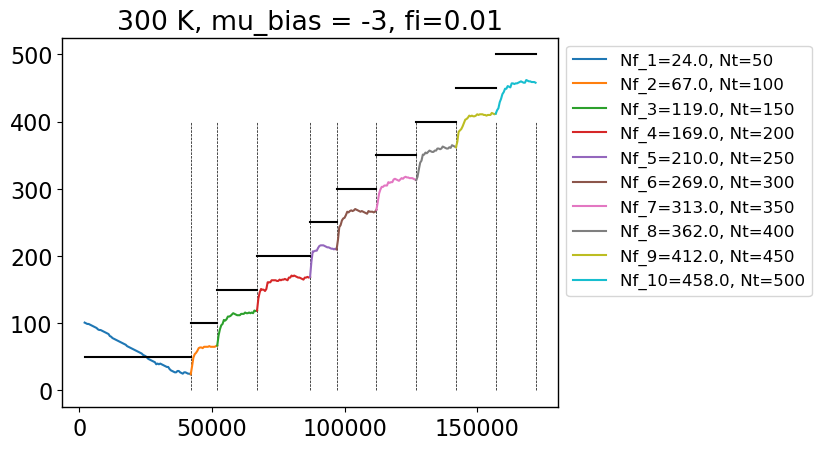

In [50]:
fig = plt.figure()
for i in range(1,11):
    Nt = 50+(i-1)*50
    file = f'./production_run/free_E/test/atoms_log_{i}.txt'
    log_data = parse_print_file(file)
    step = np.array(log_data['Step'])
    n_Na = np.array(log_data['atoms'])-3584  # Adjust baseline as needed
    plt.plot(step, n_Na, label=f'Nf_{i}={n_Na[-1]}, Nt={Nt}')
    plt.plot([step[0],step[-1]], [Nt, Nt], color='black')
    plt.vlines(step[-1], 0, 400, color='black', linestyles='--', linewidth=0.5)
plt.legend(bbox_to_anchor=(1, 1))
plt.title('300 K, mu_bias = -3, fi=0.01')
#plt.grid()

In [48]:
temp =1100
i=1
file = f'./production_run/free_E/test/Nt_{temp}/2/{temp}_converge_{i}.txt'
data = np.loadtxt(file, skiprows=2) 
data[-1,-1]

32729.0

### 1100K

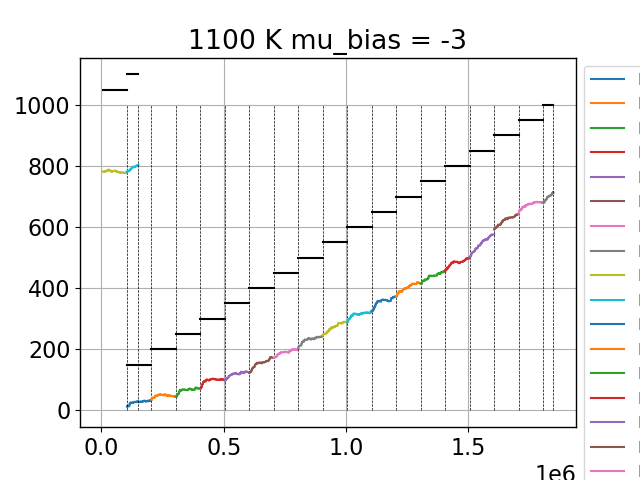

In [42]:
%matplotlib widget
fig = plt.figure()
for i in range(2,22):
    Nt = 100+(i-1)*50
    file = f'./production_run/free_E/test/Nt_1100/1/atoms_log_{i}.txt'
    log_data = parse_print_file(file)
    step = np.array(log_data['Step'])
    n_Na = np.array(log_data['atoms']) - 28672  # Adjust baseline as needed
    plt.plot(step, n_Na, label=f'Nf_{i}={n_Na[-1]}, Nt={Nt}')
    plt.plot([step[0],step[-1]], [Nt, Nt], color='black')
    plt.vlines(step[-1], 0, 1000, color='black', linestyles='--', linewidth=0.5)
plt.legend(bbox_to_anchor=(1, 1))
plt.title('1100 K mu_bias = -3')
plt.grid()

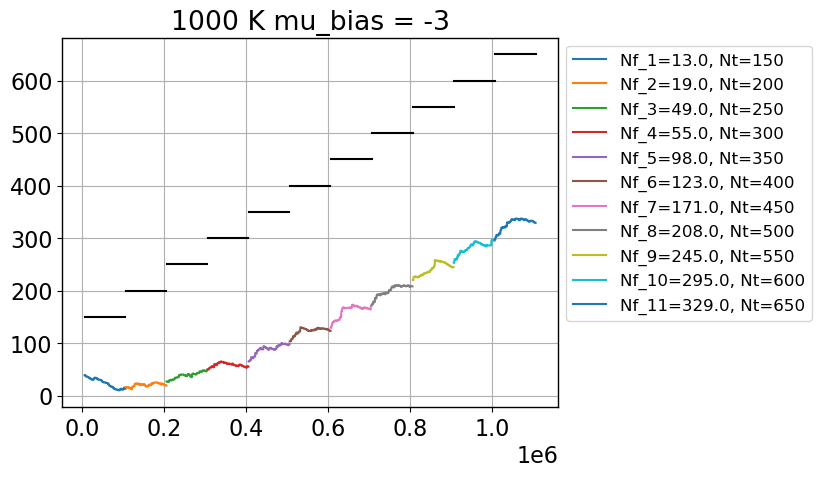

In [22]:
fig = plt.figure()
for i in range(1,12):
    Nt = 150+(i-1)*50
    file = f'./production_run/free_E/test/Nt_1000/1/atoms_log_{i}.txt'
    log_data = parse_print_file(file)
    step = np.array(log_data['Step'])
    n_Na = np.array(log_data['atoms']) - 28672  # Adjust baseline as needed
    plt.plot(step, n_Na, label=f'Nf_{i}={n_Na[-1]}, Nt={Nt}')
    plt.plot([step[0],step[-1]], [Nt, Nt], color='black')
    #plt.vlines(step[-1], 0, 1000, color='black', linestyles='--', linewidth=0.5)
plt.legend(bbox_to_anchor=(1, 1))
plt.title('1000 K mu_bias = -3')
plt.grid()

Error parsing file ./production_run/free_E/test/Nt_1100/2/atoms_log_14.txt: [Errno 2] No such file or directory: './production_run/free_E/test/Nt_1100/2/atoms_log_14.txt'


IndexError: index -1 is out of bounds for axis 0 with size 0

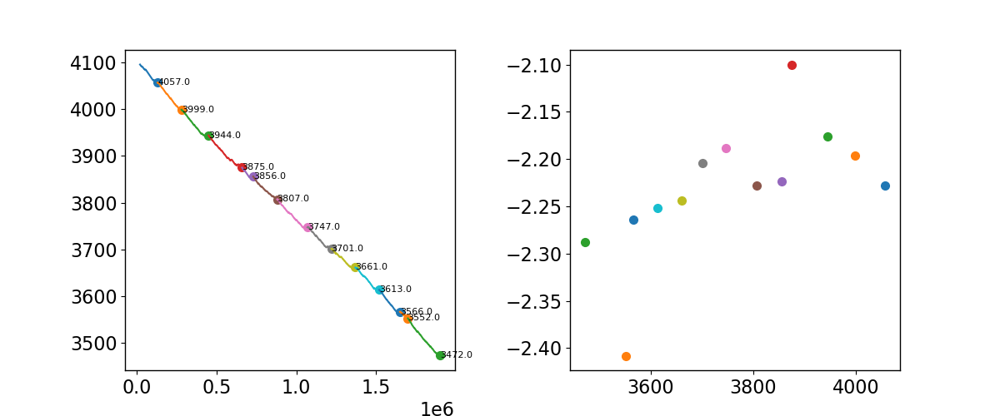

In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,5))
plt.subplots_adjust(wspace=0.35)
temp = 1100
fi = 0.002
for i in range(1,15):
    Nt = 4000-(i-1)*50
    file = f'./production_run/free_E/test/Nt_{temp}/2/atoms_log_{i}.txt'
    log_data = parse_print_file(file)
    step = np.array(log_data['Step'])
    n_Na = np.array(log_data['atoms']) - 28672  # Adjust baseline as needed
    ax1.plot(step, n_Na, label=f'Nf_{i}={n_Na[-1]}, Nt={Nt}')
    #ax1.plot([step[0],step[-1]], [Nt, Nt], color='black')
    #plt.vlines(step[-1], 0, 1000, color='black', linestyles='--', linewidth=0.5)
    
    file = f'./production_run/free_E/test/Nt_{temp}/2/{temp}_converge_{i}.txt'
    data = np.loadtxt(file, skiprows=2) 
    ts = data[-1,0] 
    Nf = data[-1,-1] - 28672
    mu = -2-2*fi*(Nf-Nt)
    ax1.scatter(ts,Nf)
    ax1.text(ts,Nf-5,s=f'{Nf}',fontsize=8)
    ax2.scatter(Nf,mu)
    
ax1.legend(bbox_to_anchor=(0,1))
plt.title(f'{temp} K mu_bias = -3')
ax1.grid()
ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')
ax2.set_xlabel('Number of Na+')
ax2.set_ylabel('Chemical potential (eV)')


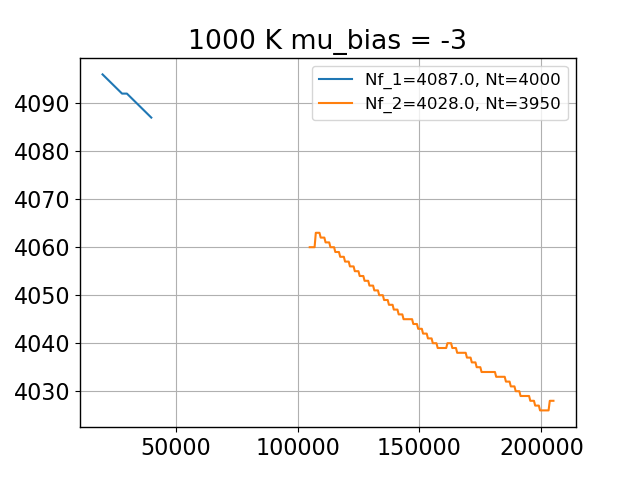

In [65]:
fig = plt.figure()
for i in range(1,3):
    Nt = 4000-(i-1)*50
    file = f'./production_run/free_E/test/Nt_1000/2/atoms_log_{i}.txt'
    log_data = parse_print_file(file)
    step = np.array(log_data['Step'])
    n_Na = np.array(log_data['atoms']) - 28672  # Adjust baseline as needed
    plt.plot(step, n_Na, label=f'Nf_{i}={n_Na[-1]}, Nt={Nt}')
    #plt.plot([step[0],step[-1]], [Nt, Nt], color='black')
    #plt.vlines(step[-1], 0, 1000, color='black', linestyles='--', linewidth=0.5)
plt.legend(bbox_to_anchor=(1, 1))
plt.title('1000 K mu_bias = -3')
plt.grid()

In [30]:
temp,serie,i=900,1,61
file = f'./production_run/free_E/test/Nt_{temp}/{serie}/{temp}_converge_{i}.txt'
data = np.loadtxt(file, skiprows=2) 
data.shape

(2,)

In [12]:
def plot_loop(temp, Nt0, mu_b, fi, serie, curr_N):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,5))
    plt.subplots_adjust(wspace=0.35)
    temp = temp
    fi = fi
    Nf_ls = []
    mu_ls = []
    for i in range(1,curr_N):
        Nt = Nt0+(i-1)*50
        file = f'./production_run/free_E/test/Nt_{temp}/{serie}/atoms_log_{i}.txt'
        log_data = parse_print_file(file)
        step = np.array(log_data['Step'])
        n_Na = np.array(log_data['atoms']) - 28672  # Adjust baseline as needed
        ax1.plot(step, n_Na, label=f'Nf_{i}={n_Na[-1]}, Nt={Nt}')
        #ax1.plot([step[0],step[-1]], [Nt, Nt], color='black')
        #plt.vlines(step[-1], 0, 1000, color='black', linestyles='--', linewidth=0.5)
        
        file = f'./production_run/free_E/test/Nt_{temp}/{serie}/{temp}_converge_{i}.txt'
        data = np.loadtxt(file, skiprows=2) 
        if data.ndim == 1:
            # Handle 1D case - adjust indexing as needed
            ts = data[0] if len(data) > 0 else 0
            Nf = data[-1] - 28672 if len(data) > 0 else 0
        else:
            # Handle 2D case as before
            ts = data[-1,0] 
            Nf = data[-1,-1] - 28672
        mu = mu_b-2*fi*(Nf-Nt)
        Nf_ls.append(Nf)
        mu_ls.append(mu)
        ax1.scatter(ts,Nf)
        ax1.text(ts,Nf-5,s=f'{Nf}',fontsize=8)
        ax2.scatter(Nf,mu)
    ax2.plot(Nf_ls,mu_ls)
        
    #ax1.legend(bbox_to_anchor=(0,1))
    plt.title(f'{temp} K mu_bias = -3')
    ax1.grid()
    ax1.set_xlabel('Timestep (0.4 fs/step)')
    ax1.set_ylabel('Number of Na+')
    ax2.set_xlabel('Number of Na+')
    ax2.set_ylabel('Chemical potential (eV)')
    plt.tight_layout()
    plt.savefig(f'./production_run/free_E/test/loop_{temp}.png')
    return Nf_ls, mu_ls

### 1100K

/tmp/ipykernel_420/3364523823.py:19: UserWarning: loadtxt: input contained no data: "./production_run/free_E/test/Nt_1100/3/1100_converge_1.txt"
  data = np.loadtxt(file, skiprows=2)


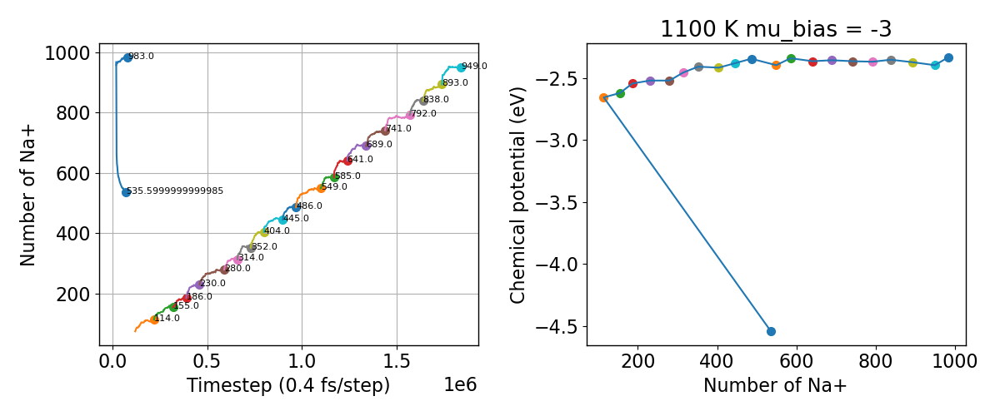

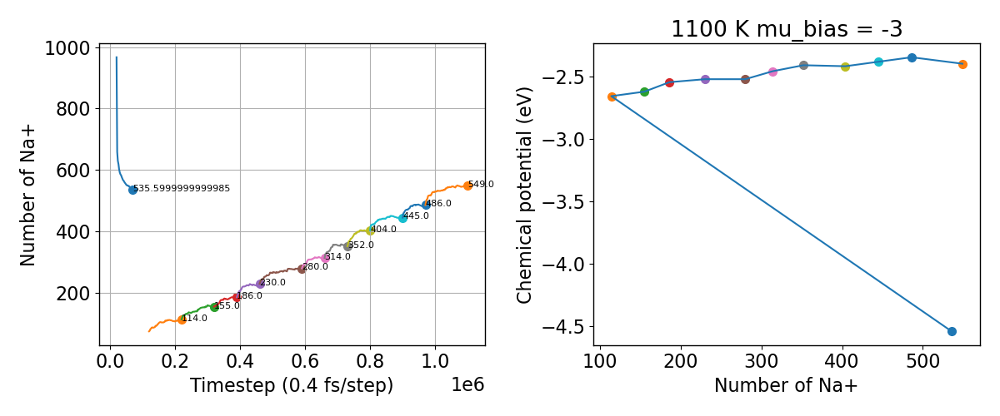

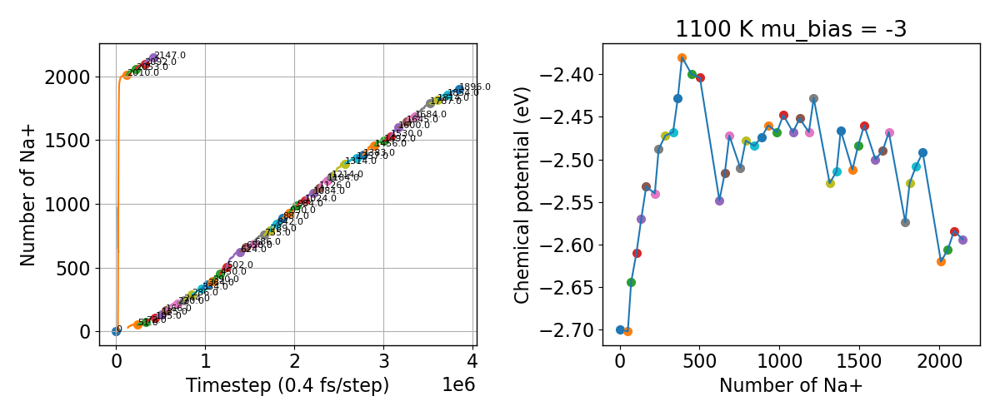

In [13]:
%matplotlib widget
Nf_ls_1100, mu_ls_1100 = plot_loop(1100, 150, -3, 0.002, 1, 22)
Nf_ls_1100_2, mu_ls_1100_2 = plot_loop(1100, 150, -3, 0.002, 1, 13)
Nf_ls_1100_3, mu_ls_1100_3 = plot_loop(1100, 150, -3, 0.001, 3, 46)

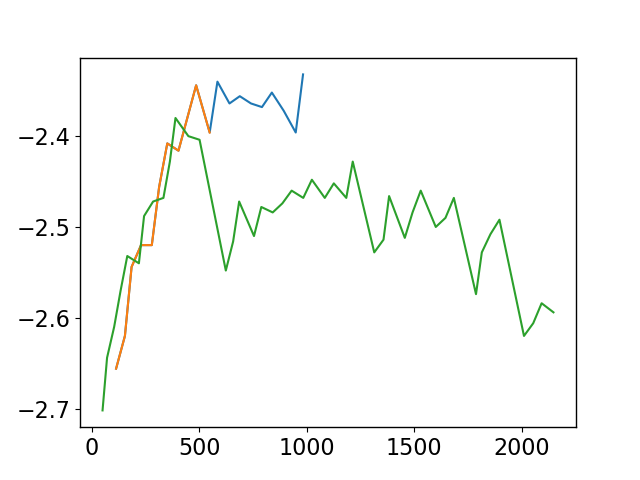

In [15]:
plt.figure()
plt.plot(Nf_ls_1100[1:], mu_ls_1100[1:])
plt.plot(Nf_ls_1100_2[1:], mu_ls_1100_2[1:])
plt.plot(Nf_ls_1100_3[1:], mu_ls_1100_3[1:])

### 1000K

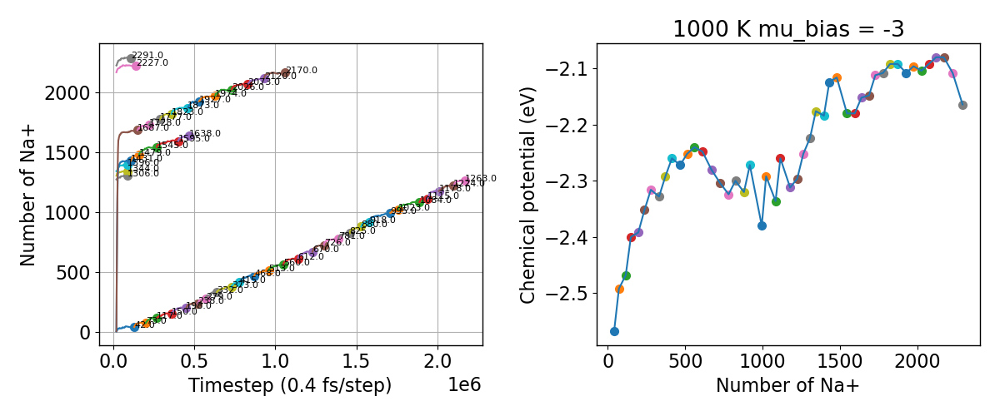

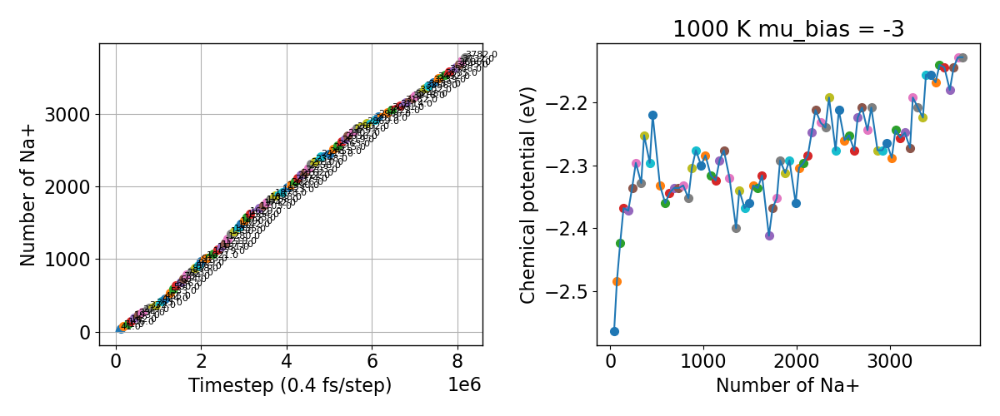

In [16]:
Nf_ls_1000, mu_ls_1000 = plot_loop(1000, 150,-3, 0.002, 3, 49)
Nf_ls_1000_2, mu_ls_1000_2 = plot_loop(1000, 150,-3, 0.002, 1, 79)

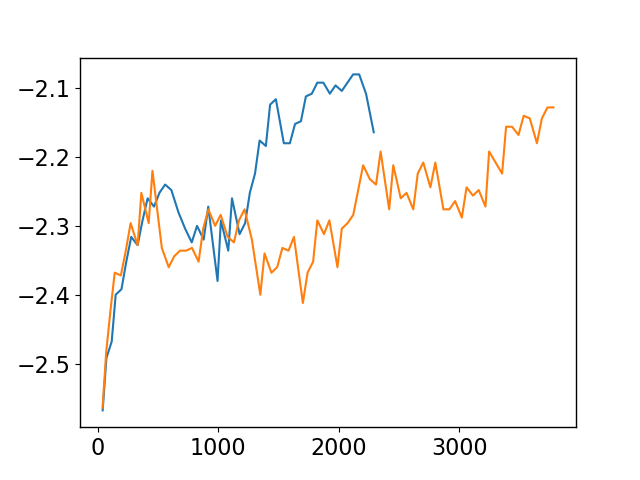

In [17]:
plt.figure()
plt.plot(Nf_ls_1000, mu_ls_1000)
plt.plot(Nf_ls_1000_2, mu_ls_1000_2)

### 900K

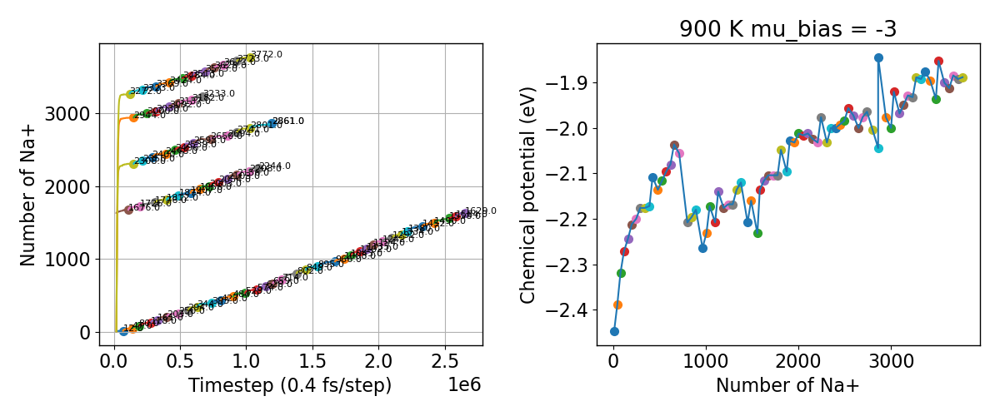

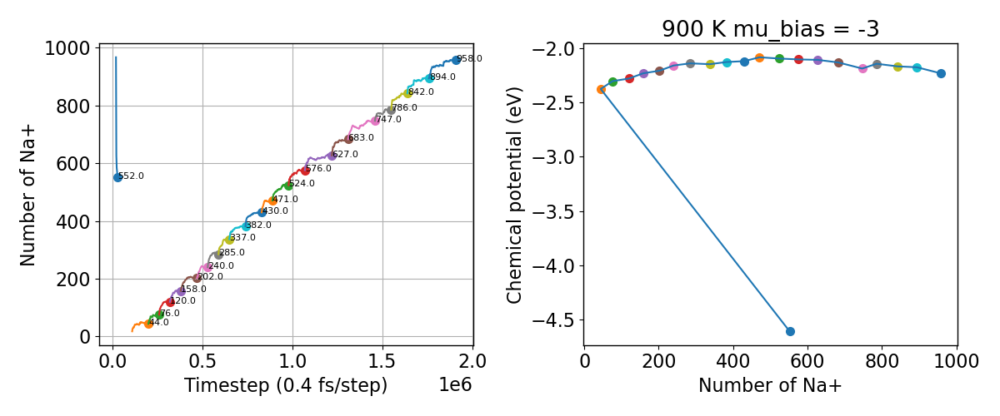

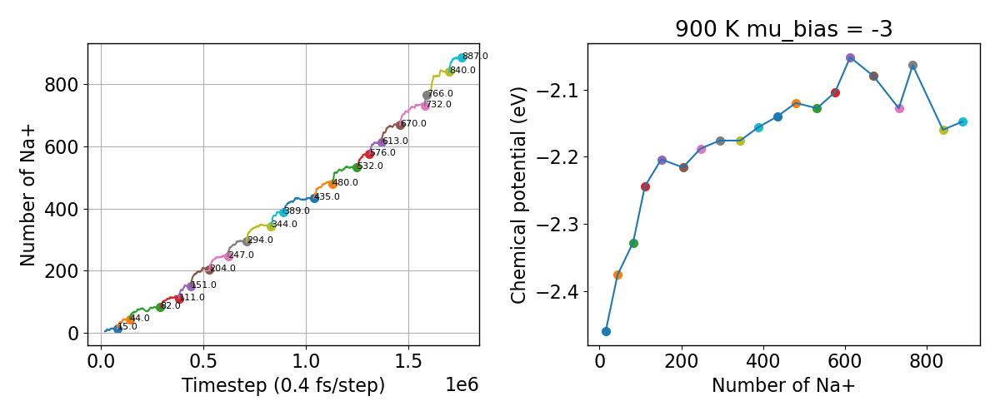

In [41]:
Nf_ls_900, mu_ls_900 = plot_loop(900, 150,-3, 0.002, 1, 80)
Nf_ls_900_2, mu_ls_900_2 = plot_loop(900, 150,-3, 0.002, 2, 22)
Nf_ls_900_3, mu_ls_900_3 = plot_loop(900, 150,-3, 0.002, 3, 21)

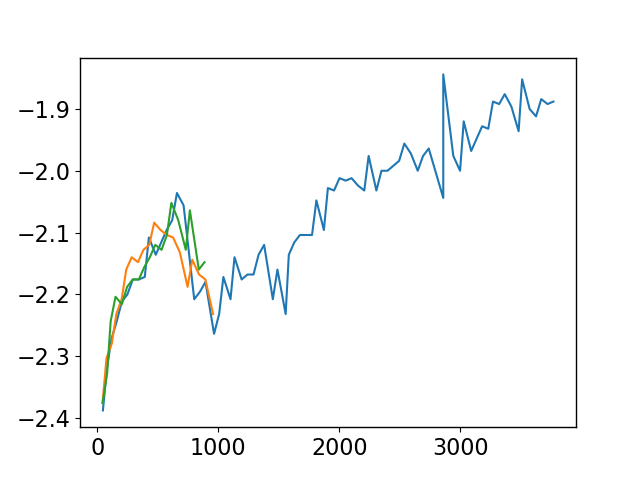

In [42]:
plt.figure()
plt.plot(Nf_ls_900[1:], mu_ls_900[1:])
plt.plot(Nf_ls_900_2[1:], mu_ls_900_2[1:])
plt.plot(Nf_ls_900_3[1:], mu_ls_900_3[1:])

### 800K

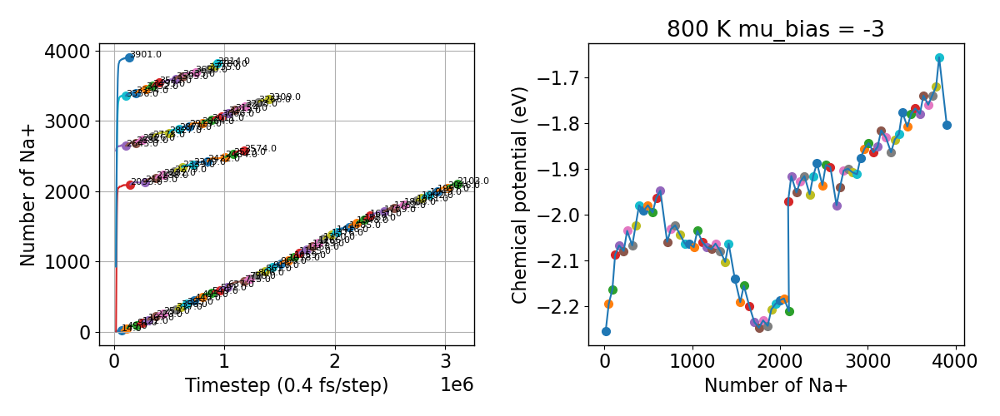

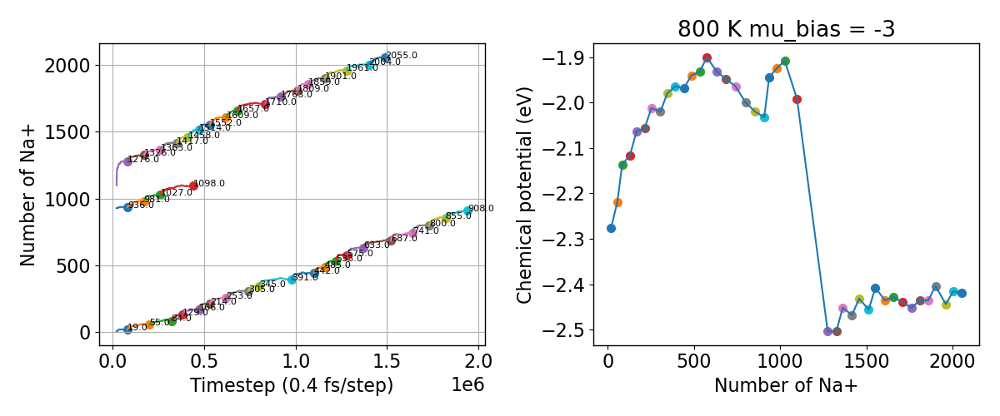

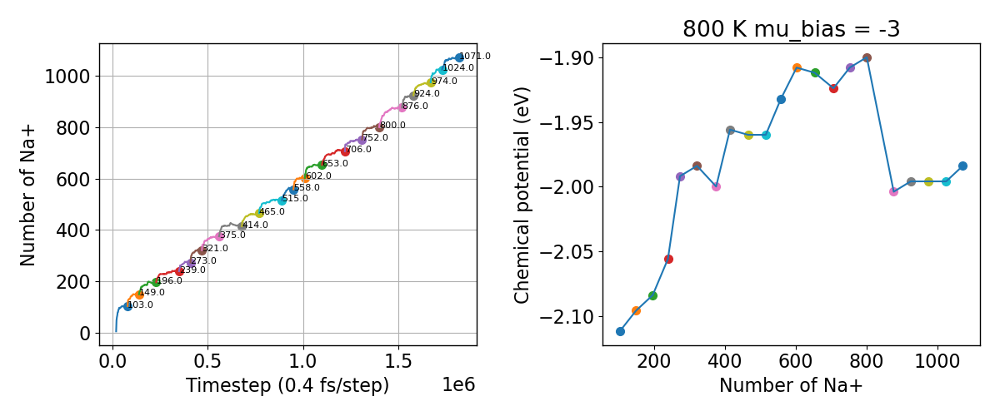

In [14]:
Nf_ls_800, mu_ls_800 = plot_loop(800, 200, -3, 0.002, 1, 82)
Nf_ls_800_2, mu_ls_800_2 = plot_loop(800, 200, -3, 0.002, 2, 42)
Nf_ls_800_3, mu_ls_800_3 = plot_loop(800, 200, -2.5, 0.002, 3, 22)

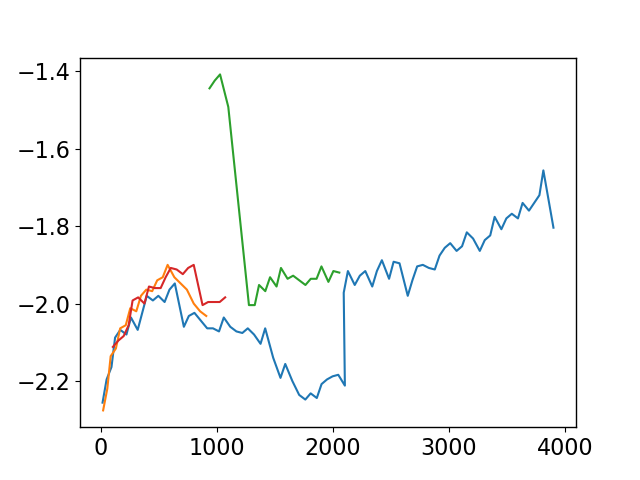

In [15]:
plt.figure()
plt.plot(Nf_ls_800, mu_ls_800)
Nf_ls_800 = np.array(Nf_ls_800)
mu_ls_800 = np.array(mu_ls_800)
plt.plot(Nf_ls_800_2[:20], mu_ls_800_2[:20])
plt.plot(Nf_ls_800_2[20:], np.array(mu_ls_800_2[20:])+0.5)
plt.plot(Nf_ls_800_3, mu_ls_800_3)

In [56]:
mu_ls_800_2[22:]

[-1.908,
 -1.992,
 -2.504,
 -2.504,
 -2.452,
 -2.468,
 -2.432,
 -2.456,
 -2.408,
 -2.436,
 -2.428,
 -2.44,
 -2.452,
 -2.436,
 -2.436]

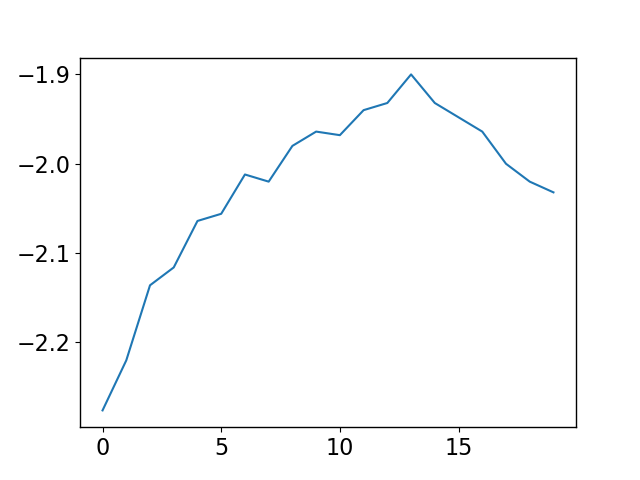

In [61]:
plt.figure()
plt.plot(mu_ls_800_2[:20])

### 700K

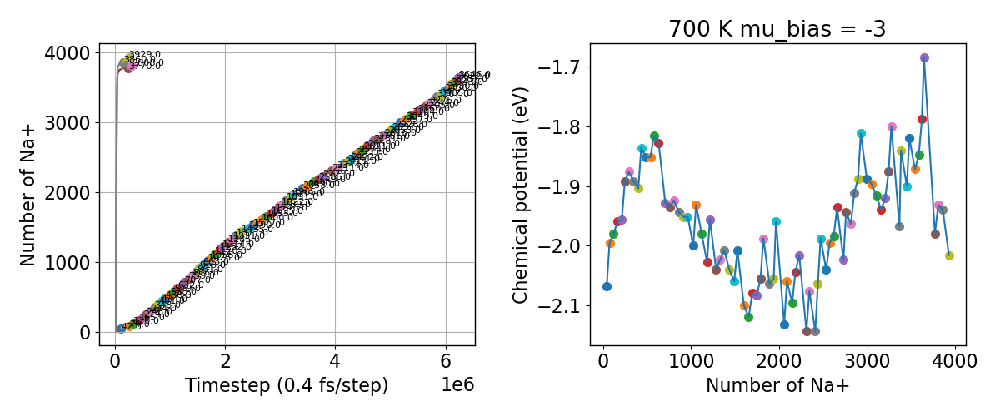

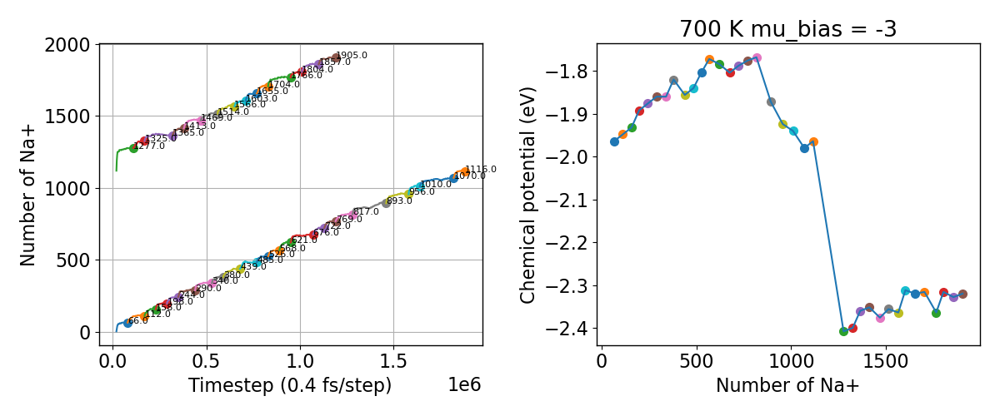

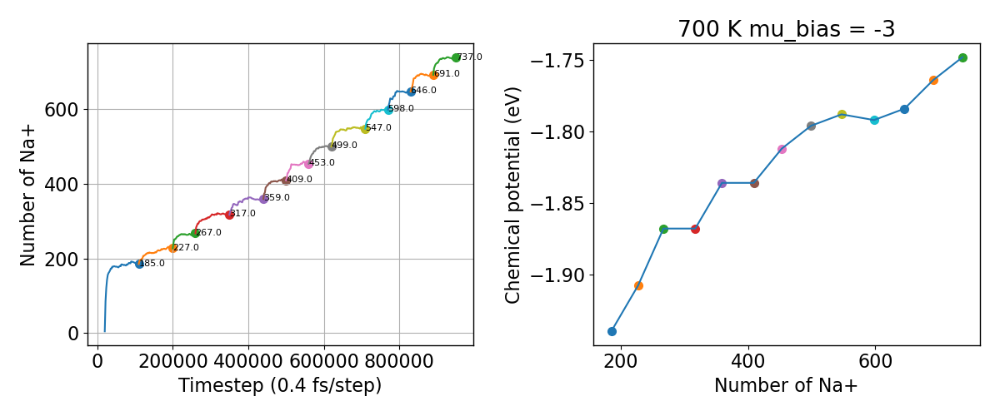

In [20]:
Nf_ls_700, mu_ls_700 = plot_loop(700, 150, -2.5, 0.002, 1, 80)
Nf_ls_700_2, mu_ls_700_2 = plot_loop(700, 200, -2.5, 0.002, 2, 37)
Nf_ls_700_3, mu_ls_700_3 = plot_loop(700, 200, -2, 0.002, 3, 14)

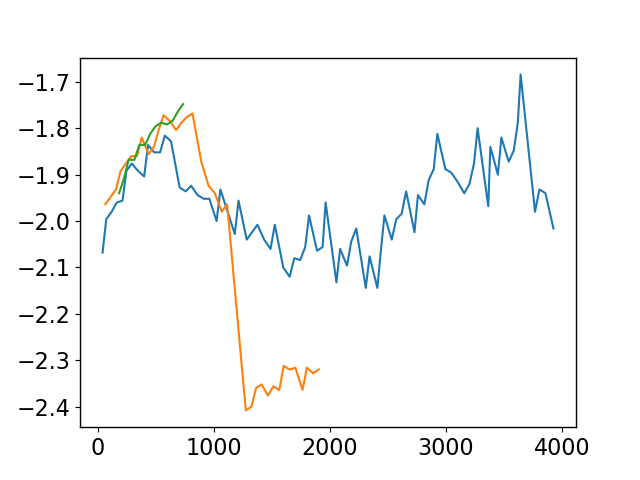

In [21]:
plt.figure()
plt.plot(Nf_ls_700, mu_ls_700)
plt.plot(Nf_ls_700_2, mu_ls_700_2)
plt.plot(Nf_ls_700_3, mu_ls_700_3)

### 600K

/tmp/ipykernel_420/3364523823.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,5))


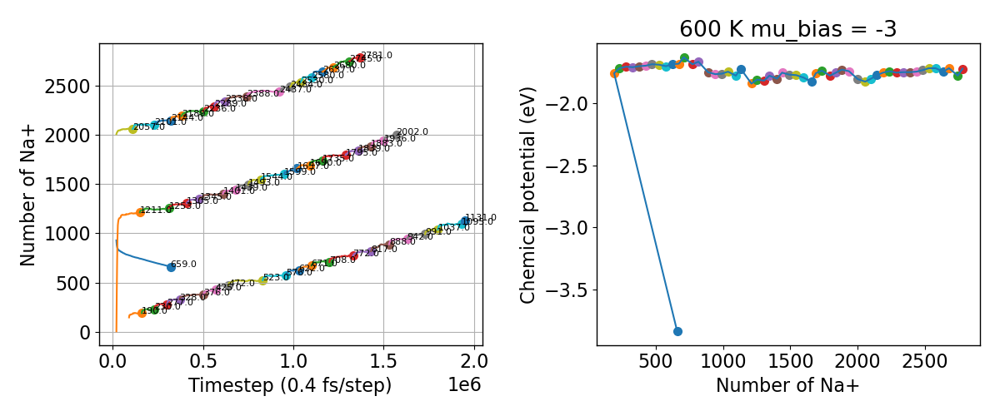

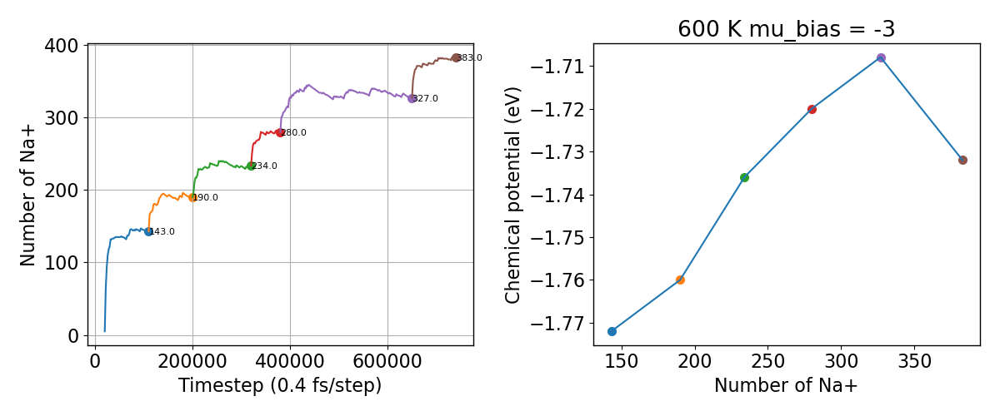

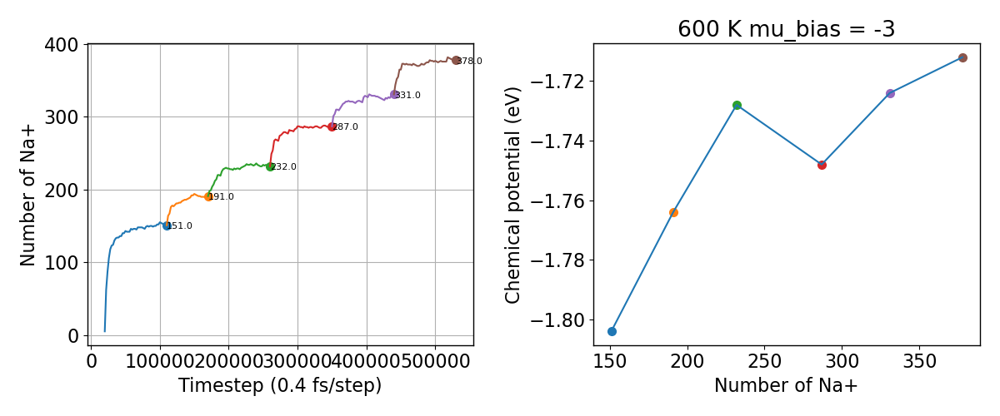

In [22]:
Nf_ls_600, mu_ls_600 = plot_loop(600, 200, -2, 0.002, 1, 55)
Nf_ls_600_2, mu_ls_600_2 = plot_loop(600, 200, -2, 0.002, 2, 7)
Nf_ls_600_3, mu_ls_600_3 = plot_loop(600, 200, -2, 0.002, 3, 7)

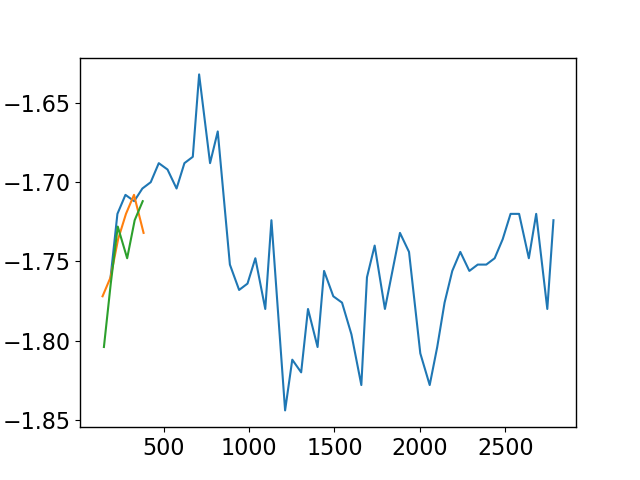

In [24]:
plt.figure()
plt.plot(Nf_ls_600[1:], mu_ls_600[1:])
plt.plot(Nf_ls_600_2, mu_ls_600_2)
plt.plot(Nf_ls_600_3, mu_ls_600_3)

/tmp/ipykernel_7463/3364523823.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,5))


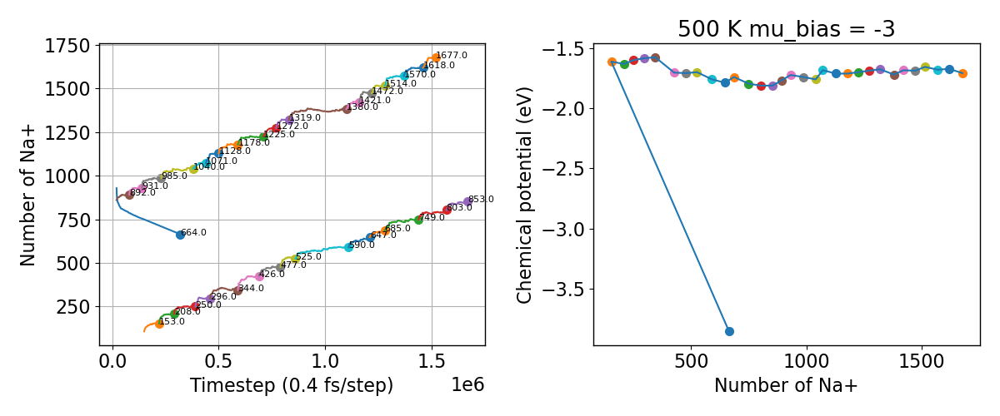

In [26]:
Nf_ls_500, mu_ls_500 = plot_loop(500, 200, -2, 0.002, 1, 33)

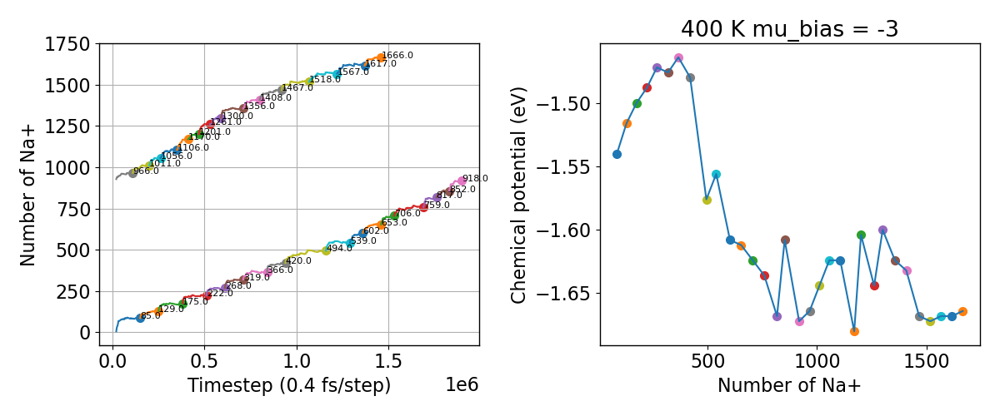

In [27]:
Nf_ls_400, mu_ls_400 = plot_loop(400, 200, -2, 0.002, 1, 33)

/tmp/ipykernel_7463/3364523823.py:19: UserWarning: loadtxt: input contained no data: "./production_run/free_E/test/Nt_300/1/300_converge_3.txt"
  data = np.loadtxt(file, skiprows=2)


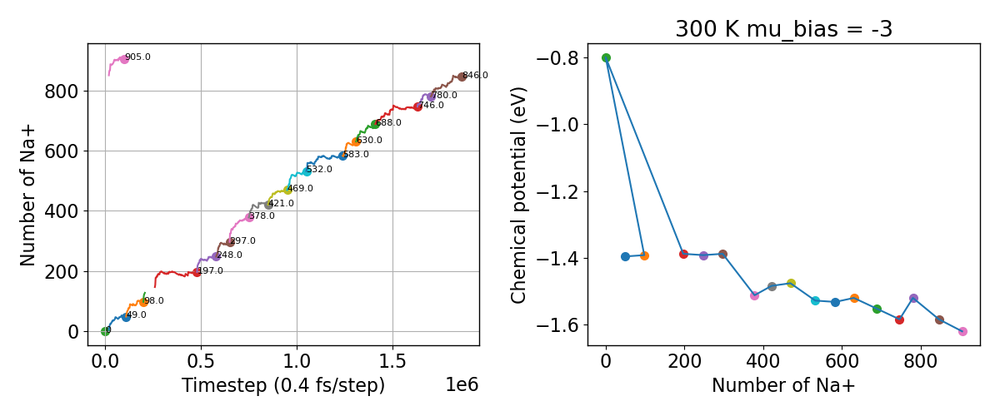

In [63]:
Nf_ls_300, mu_ls_300 = plot_loop(300, 200, -2, 0.002, 1, 18)

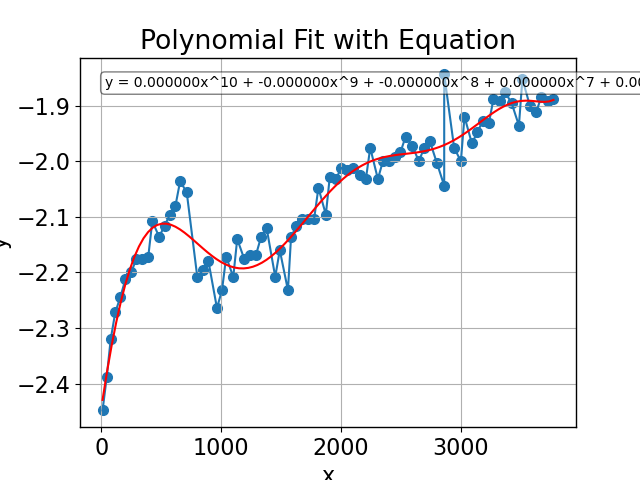

In [33]:
degree = 10
x, y = Nf_ls_900, mu_ls_900
coefficients = np.polyfit(x, y, degree)
poly_func = np.poly1d(coefficients)

# Generate fitted values
x_fit = np.linspace(min(x), max(x), 100)
y_fit = poly_func(x_fit)

# Generate the equation string
equation = "y = "
for i, c in enumerate(coefficients):
    power = degree - i
    if power == 0:
        equation += f"{c:.6f}"
    elif power == 1:
        equation += f"{c:.6f}x + "
    else:
        equation += f"{c:.6f}x^{power} + "

plt.figure()
# Plot
plt.scatter(x, y, label='Data')
plt.plot(x, y)
plt.plot(x_fit, y_fit, 'r-', label='Polynomial Fit')
plt.text(0.05, 0.95, equation, transform=plt.gca().transAxes,
         fontsize=10, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
#plt.legend()
plt.xlabel('x')
plt.ylabel('y')
plt.title('Polynomial Fit with Equation')
plt.grid(True)

NameError: name 'Nf_ls_700' is not defined

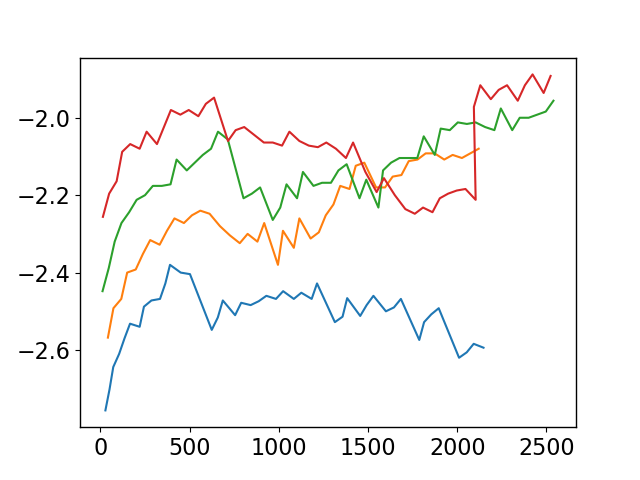

In [26]:
plt.figure()
plt.plot(Nf_ls_1100, mu_ls_1100, label='1100K')
plt.plot(Nf_ls_1000, mu_ls_1000, label='1000K')
plt.plot(Nf_ls_900, mu_ls_900, label='900K')
plt.plot(Nf_ls_800, mu_ls_800, label='800K')
plt.plot(Nf_ls_700, mu_ls_700, label='700K')
plt.legend()
#plt.xlim(0,1300)
plt.xlabel('Number of Na+')
plt.ylabel('Chemical potential (eV)')
plt.tight_layout()

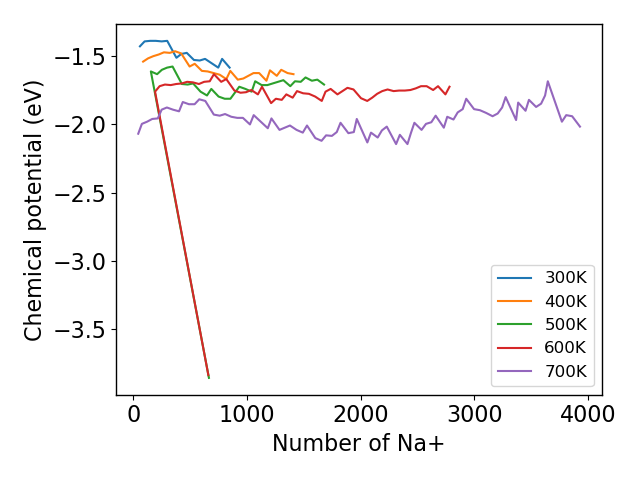

In [45]:
plt.figure()
plt.plot(Nf_ls_300, mu_ls_300, label='300K')
plt.plot(Nf_ls_400, mu_ls_400, label='400K')
plt.plot(Nf_ls_500, mu_ls_500, label='500K')
plt.plot(Nf_ls_600, mu_ls_600, label='600K')
plt.plot(Nf_ls_700, mu_ls_700, label='700K')
plt.legend()
#plt.xlim(0,1300)
plt.xlabel('Number of Na+')
plt.ylabel('Chemical potential (eV)')
plt.tight_layout()

Text(0, 0.5, 'Chemical potential (eV)')

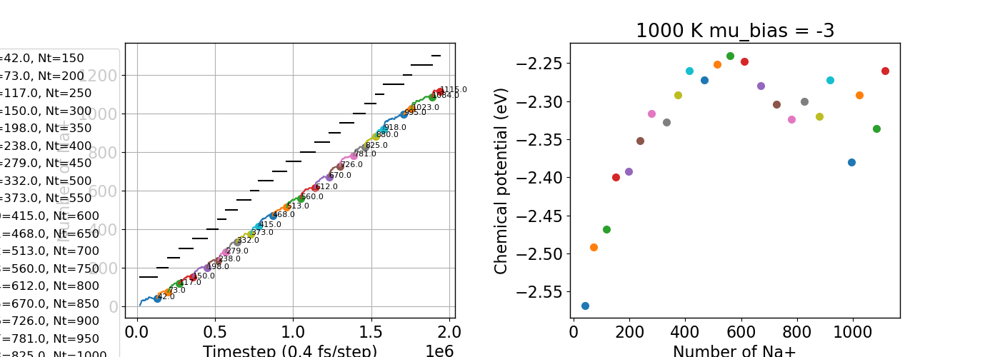

In [29]:
%matplotlib widget
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14,5))
plt.subplots_adjust(wspace=0.35)
temp = 1000
fi = 0.002
for i in range(1,25):
    Nt = 150+(i-1)*50
    file = f'./production_run/free_E/test/Nt_{temp}/3/atoms_log_{i}.txt'
    log_data = parse_print_file(file)
    step = np.array(log_data['Step'])
    n_Na = np.array(log_data['atoms']) - 28672  # Adjust baseline as needed
    ax1.plot(step, n_Na, label=f'Nf_{i}={n_Na[-1]}, Nt={Nt}')
    ax1.plot([step[0],step[-1]], [Nt, Nt], color='black')
    #plt.vlines(step[-1], 0, 1000, color='black', linestyles='--', linewidth=0.5)
    file = f'./production_run/free_E/test/Nt_{temp}/3/{temp}_converge_{i}.txt'
    data = np.loadtxt(file, skiprows=2) 
    ts = data[-1,0] 
    Nf = data[-1,-1] - 28672
    mu = -3-2*fi*(Nf-Nt)
    ax1.scatter(ts,Nf)
    ax1.text(ts,Nf-5,s=f'{Nf}',fontsize=8)
    ax2.scatter(Nf,mu)
    
ax1.legend(bbox_to_anchor=(0,1))
plt.title(f'{temp} K mu_bias = -3')
ax1.grid()
ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')
ax2.set_xlabel('Number of Na+')
ax2.set_ylabel('Chemical potential (eV)')

Text(0, 0.5, 'Chemical potential (eV)')

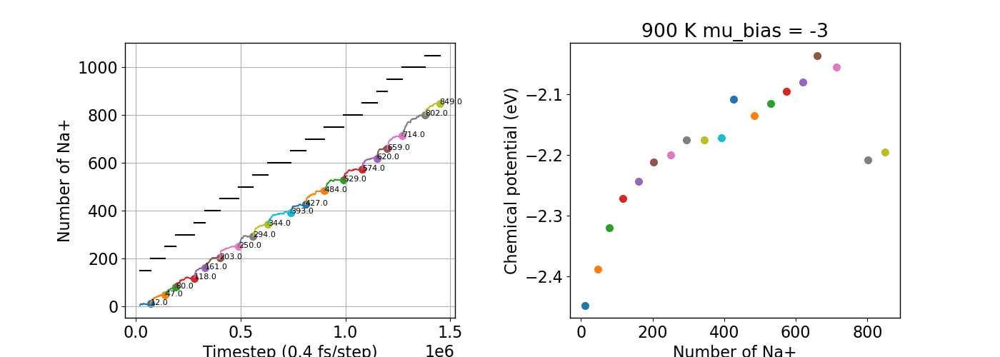

In [27]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14,5))
plt.subplots_adjust(wspace=0.35)
temp = 900
fi = 0.002
for i in range(1,20):
    Nt = 150+(i-1)*50
    file = f'./production_run/free_E/test/Nt_{temp}/1/atoms_log_{i}.txt'
    log_data = parse_print_file(file)
    step = np.array(log_data['Step'])
    n_Na = np.array(log_data['atoms']) - 28672  # Adjust baseline as needed
    ax1.plot(step, n_Na, label=f'Nf_{i}={n_Na[-1]}, Nt={Nt}')
    ax1.plot([step[0],step[-1]], [Nt, Nt], color='black')
    #plt.vlines(step[-1], 0, 1000, color='black', linestyles='--', linewidth=0.5)
    file = f'./production_run/free_E/test/Nt_{temp}/1/{temp}_converge_{i}.txt'
    data = np.loadtxt(file, skiprows=2) 
    ts = data[-1,0] 
    Nf = data[-1,-1] - 28672
    mu = -3-2*fi*(Nf-Nt)
    ax1.scatter(ts,Nf)
    ax1.text(ts,Nf-5,s=f'{Nf}',fontsize=8)
    ax2.scatter(Nf,mu)
    
#ax1.legend(bbox_to_anchor=(0,1))
plt.title(f'{temp} K mu_bias = -3')
ax1.grid()
ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')
ax2.set_xlabel('Number of Na+')
ax2.set_ylabel('Chemical potential (eV)')

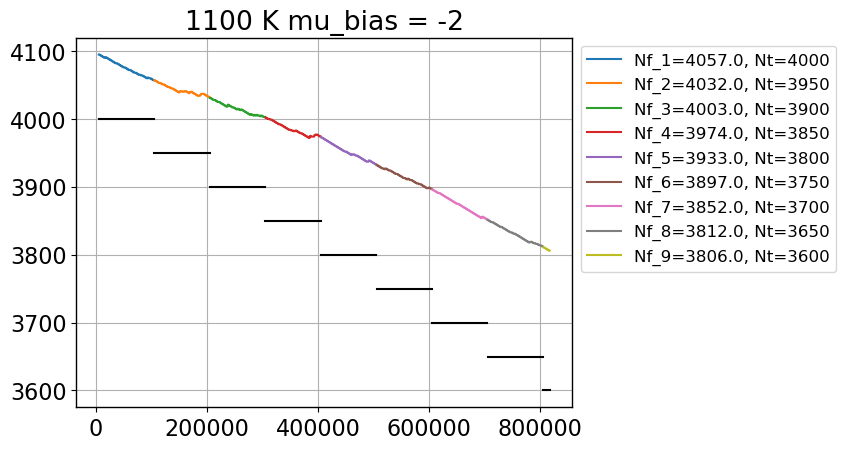

In [38]:
%matplotlib inline
fig = plt.figure()
for i in range(1,10):
    Nt = 4000-(i-1)*50
    file = f'./production_run/free_E/test/Nt_1100/2/atoms_log_{i}.txt'
    log_data = parse_print_file(file)
    step = np.array(log_data['Step'])
    n_Na = np.array(log_data['atoms']) - 28672  # Adjust baseline as needed
    plt.plot(step, n_Na, label=f'Nf_{i}={n_Na[-1]}, Nt={Nt}')
    plt.plot([step[0],step[-1]], [Nt, Nt], color='black')
    #plt.vlines(step[-1], 4000, 3000, color='black', linestyles='--', linewidth=0.5)
plt.legend(bbox_to_anchor=(1, 1))
plt.title('1100 K mu_bias = -2')
plt.grid()

In [24]:
%matplotlib inline
fig = plt.figure()
for i in range(1,10):
    Nt = 4000-(i-1)*50
    file = f'./production_run/free_E/test/Nt_1000/2/atoms_log_{i}.txt'
    log_data = parse_print_file(file)
    step = np.array(log_data['Step'])
    n_Na = np.array(log_data['atoms']) - 28672  # Adjust baseline as needed
    plt.plot(step, n_Na, label=f'Nf_{i}={n_Na[-1]}, Nt={Nt}')
    plt.plot([step[0],step[-1]], [Nt, Nt], color='black')
    #plt.vlines(step[-1], 0, 1000, color='black', linestyles='--', linewidth=0.5)
plt.legend(bbox_to_anchor=(1, 1))
plt.title('1000 K mu_bias = -2')
plt.grid()

TypeError: 'NoneType' object is not subscriptable

<Figure size 640x480 with 0 Axes>

In [51]:
import re
import numpy as np
from lammps import lammps

def parse_print_file(file_path):
    data = {'Step': [], 'atoms': []}

    with open(file_path, 'r') as file:
        for line in file:
            if re.match(r"^\s*Step\s+Atoms", line):
                next(file)
                for data_line in file:
                    if re.match(r"^\s*\d+", data_line) and len(data_line.split()) == 2:
                        values = data_line.split()
                        data['Step'].append(int(values[0]))
                        data['atoms'].append(float(values[1]))
                    else:
                        break
    return data

def detect_equilibration_time(file, precision=10, window_fraction=0.2):
    log_data = parse_print_file(file)
    if len(log_data['Step']) < 50:
        print(f"[Equilibrium] Not enough data yet in {file}, skipping check.")
        return False, None, None, None

    step = np.array(log_data['Step'])
    window_size = int((step.shape[0]) * window_fraction)
    n_Na = np.array(log_data['atoms']) - 28672  # Adjust baseline as needed

    Q_mean_ls = []
    Q_std_ls = []
    for i in range(int(1 / window_fraction)):
        start = window_size * i
        end = window_size * (i + 1)
        if end > len(n_Na): break  # Avoid overrun
        Q_mean_ls.append(np.mean(n_Na[start:end]))
        Q_std_ls.append(np.std(n_Na[start:end]))

    Q_mean_ls = np.array(Q_mean_ls)
    Q_std_ls = np.array(Q_std_ls)

    Q_std_B1_B2_ls = Q_std_ls[:-1] + Q_std_ls[1:]
    Q_diff_ls = np.abs(Q_mean_ls[1:] - Q_mean_ls[:-1])

    precon_1 = np.std(n_Na)>5
    precon_2 = Q_diff_ls[-1]>5
    ## the CHNAGE of number of Na in the lAST block < 8
    con_1 = Q_diff_ls[-1] < precision
    ## the FLUCTUATION of number of Na in the lAST block < 15
    con_2 = Q_std_B1_B2_ls[-1] < 5
    ## the CHNAGE of number of Na in the lAST block is the smallest
    con_3 = Q_diff_ls.argmin() == Q_diff_ls.shape[0]-1
    ## the FLUCTUATION of number of Na in the lAST block is the smallest
    con_4 = Q_std_B1_B2_ls.argmin() == Q_std_B1_B2_ls.shape[0]-1

    ##### if Na profile is NOT FLAT & the last block has delta(Na) > 8  #####
    if precon_1 and precon_2:
        if con_1 and con_2 and con_3 and con_4:
            print('The simulation HAS reached equilibrium. type 1.')
            return True, Q_mean_ls, Q_diff_ls, Q_std_B1_B2_ls
        else:
            print('The simulation HAS NOT reached equilibrium. Run for another 10000 steps.')
            return False,Q_mean_ls, Q_diff_ls, Q_std_B1_B2_ls
    ##### if last block has delta(Na) < 8 #####
    else:
        print('The simulation HAS reached equilibrium. type 2.')
        return True, Q_mean_ls, Q_diff_ls, Q_std_B1_B2_ls

def check_equilibrium_lmp(lmp):
    step = lmp.get_thermo("step")
    if step < 30000:
        print(f"[Python/Invoke] Step {step} < 30000: skipping equilibrium check.")
        return

    try:
        N = lmp.extract_variable("N", None, 0)
        log_filename = f"atoms_log_{int(N)}.txt"
        print(f"[Python/Invoke] Checking equilibrium from: {log_filename} at {step} steps")

        reached, Q_mean, Q_diff, Q_std = detect_equilibration_time(log_filename)

        if reached:
            print(f"[Python/Invoke] Equilibrium reached at loop {N} at {step} steps. Unfixing fgcmc and pycheck.")
            lmp.command("unfix fgcmc")
            lmp.command("unfix pycheck")
            lmp.command("variable skip_loop equal 1")
        else:
            print(f"[Python/Invoke] Not yet equilibrated at loop {N} at {step} steps. Continuing simulation.")

    except Exception as e:
        print(f"[Python/Invoke] Error reading or processing file: {e}")


In [22]:
import re
import numpy as np
from lammps import lammps

def parse_print_file(file_path):
    data = {'Step': [], 'atoms': []}

    with open(file_path, 'r') as file:
        for line in file:
            if re.match(r"^\s*Step\s+Atoms", line):
                next(file)
                for data_line in file:
                    if re.match(r"^\s*\d+", data_line) and len(data_line.split()) == 2:
                        values = data_line.split()
                        data['Step'].append(int(values[0]))
                        data['atoms'].append(float(values[1]))
                    else:
                        break
    return data

def detect_equilibration_time(file, precision=10, window_fraction=0.2):
    log_data = parse_print_file(file)
    if len(log_data['Step']) < 50:
        print(f"[Equilibrium] Not enough data yet in {file}, skipping check.")
        return False, None, None, None

    step = np.array(log_data['Step'])
    window_size = int((step.shape[0]) * window_fraction)
    n_Na = np.array(log_data['atoms']) - 28672  # Adjust baseline as needed

    Q_mean_ls = []
    Q_std_ls = []
    for i in range(int(1 / window_fraction)):
        start = window_size * i
        end = window_size * (i + 1)
        if end > len(n_Na): break  # Avoid overrun
        Q_mean_ls.append(np.mean(n_Na[start:end]))
        Q_std_ls.append(np.std(n_Na[start:end]))

    Q_mean_ls = np.array(Q_mean_ls)
    Q_std_ls = np.array(Q_std_ls)

    Q_std_B1_B2_ls = Q_std_ls[:-1] + Q_std_ls[1:]
    Q_diff_ls = np.abs(Q_mean_ls[1:] - Q_mean_ls[:-1])

    precon_1 = np.std(n_Na)>5
    precon_2 = Q_diff_ls[-1]>5
    ## the CHNAGE of number of Na in the lAST block < 8
    con_1 = Q_diff_ls[-1] < precision
    ## the FLUCTUATION of number of Na in the lAST block < 15
    con_2 = Q_std_B1_B2_ls[-1] < 15
    ## the CHNAGE of number of Na in the lAST block is the smallest
    con_3 = Q_diff_ls.argmin() == Q_diff_ls.shape[0]-1
    ## the FLUCTUATION of number of Na in the lAST block is the smallest
    con_4 = Q_std_B1_B2_ls.argmin() == Q_std_B1_B2_ls.shape[0]-1

    ##### if Na profile is NOT FLAT & the last block has delta(Na) > 8  #####
    if precon_1 and precon_2:
        if con_1 and con_2 and con_3 and con_4:
            print('The simulation HAS reached equilibrium. type 1.')
            return True, Q_mean_ls, Q_diff_ls, Q_std_B1_B2_ls
        else:
            print('The simulation HAS NOT reached equilibrium. Run for another 10000 steps.')
            return False,Q_mean_ls, Q_diff_ls, Q_std_B1_B2_ls
    ##### if last block has delta(Na) < 8 #####
    else:
        print('The simulation HAS reached equilibrium. type 2.')
        return True, Q_mean_ls, Q_diff_ls, Q_std_B1_B2_ls
        

def check_equilibrium_lmp(lmp):
    step = lmp.get_thermo("step")
    if step < 30000:
        print(f"[Python/Invoke] Step {step} < 30000: skipping equilibrium check.")
        return

    try:
        N = lmp.extract_variable("N", None, 0)
        log_filename = f"atoms_log_{int(N)}.txt"
        print(f"[Python/Invoke] Checking equilibrium from: {log_filename} at {step} steps")

        reached, Q_mean, Q_diff, Q_std = detect_equilibration_time(log_filename)

        if reached:
            print(f"[Python/Invoke] Equilibrium reached at loop {N} at {step} steps. Unfixing fgcmc and pycheck.")
            lmp.command("unfix fgcmc")
            lmp.command("unfix pycheck")
            lmp.command("variable skip_loop equal 1")
        else:
            print(f"[Python/Invoke] Not yet equilibrated at loop {N} at {step} steps. Continuing simulation.")

    except Exception as e:
        print(f"[Python/Invoke] Error reading or processing file: {e}")

if __name__ == "__main__":
    # Access the current LAMMPS instance that's calling this script
    check_equilibrium_lmp(lmp)



NameError: name 'lmp' is not defined

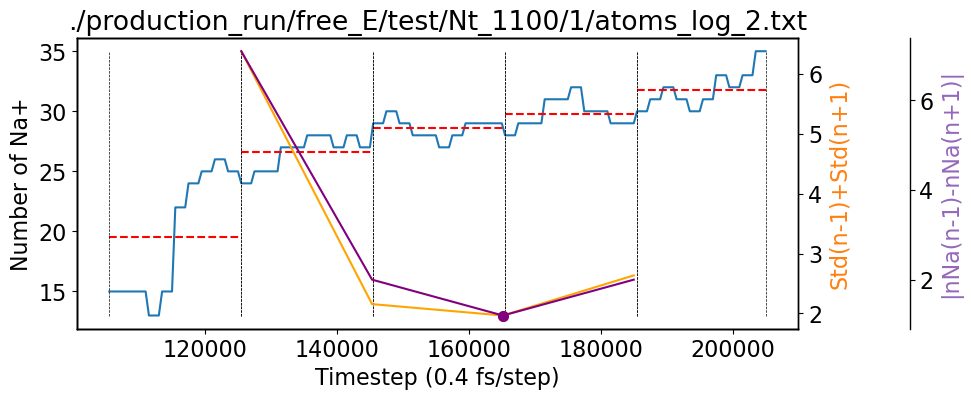

In [54]:
i=2
file = f'./production_run/free_E/test/Nt_1100/1/atoms_log_{i}.txt'
plot_convergence(file, window_fraction=0.2, f=1)

In [55]:
i=2
file = f'./production_run/free_E/test/Nt_1100/1/atoms_log_{i}.txt'

reached,Q_mean_ls, Q_diff_ls, Q_std_B1_B2_ls = detect_equilibration_time(file, precision=10, window_fraction=0.2)

The simulation HAS reached equilibrium. type 2.


In [56]:
Q_mean_ls, Q_diff_ls, Q_std_B1_B2_ls

(array([19.5, 26.6, 28.6, 29.8, 31.8]),
 array([7.1, 2. , 1.2, 2. ]),
 array([6.38140381, 2.156466  , 1.96619038, 2.63588422]))

In [53]:
file = f'./production_run/free_E/test/bias_1100/bias_279.log'

reached,Q_mean_ls, Q_diff_ls, Q_std_B1_B2_ls = detect_equilibration_time(file, precision=10, window_fraction=0.1)

The simulation HAS NOT reached equilibrium. Run for another 10000 steps.


In [34]:
file = f'./production_run/free_E/test/bias_1100/bias_261.log'

reached,Q_mean_ls, Q_diff_ls, Q_std_B1_B2_ls = detect_equilibration_time(file, precision=8, window_fraction=0.2)

The simulation HAS reached equilibrium. type 2.


/opt/softs/python/anaconda-3.11/lib/python3.11/site-packages/numpy/core/fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/softs/python/anaconda-3.11/lib/python3.11/site-packages/numpy/core/_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/opt/softs/python/anaconda-3.11/lib/python3.11/site-packages/numpy/core/_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/softs/python/anaconda-3.11/lib/python3.11/site-packages/numpy/core/_methods.py:226: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/opt/softs/python/anaconda-3.11/lib/python3.11/site-packages/numpy/core/_methods.py:261: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [36]:
file = f'./production_run/free_E/test/bias_1100/bias_232.log'

reached,Q_mean_ls, Q_diff_ls, Q_std_B1_B2_ls = detect_equilibration_time(file, precision=8, window_fraction=0.2)

The simulation HAS reached equilibrium. type 2.


In [ ]:
file = f'./production_run/free_E/test/1100/free_55.log'
log_data = parse_lammps_free(file)

n_Na = np.array(log_data['atoms']) - 28672

np.std(n_Na)>5


In [ ]:
Q_std_B1_B2_ls[-1]<15

In [ ]:
Q_diff_ls.argmin()==Q_diff_ls.shape[0]-1

In [ ]:
Q_std_B1_B2_ls.argmin()==Q_std_B1_B2_ls.shape[0]-1

In [ ]:
import math

def estimate_required_steps(sigma, rho, epsilon, confidence=0.99):
    """
    Estimate the number of Markov-chain steps (L) needed so that
    the statistical error in the mean of Q is <= epsilon with the
    given confidence level.

    Parameters
    ----------
    sigma : float
        Standard deviation of the observable Q (assumed known or estimated).
    rho : float
        Autocorrelation parameter (0 <= rho < 1).
        The correlation time is taken as tau = 1 / (1 - rho).
    epsilon : float
        Desired absolute error tolerance for the estimate of Q.
    confidence : float
        Confidence level in decimal form (e.g. 0.99 for 99% confidence).

    Returns
    -------
    L : int
        Estimated minimal number of steps in the Markov chain.
    """

    # Compute the correlation time tau ~ 1/(1 - rho).
    # This assumes a geometric decay of correlations.
    if not (0 <= rho < 1):
        raise ValueError("rho must be between 0 and 1 (not including 1).")
    tau = 1.0 / (1.0 - rho)  # approximate correlation time

    # Determine the Z-value from the confidence level.
    # For 99% confidence, Z ~ 2.576
    # For 95% confidence, Z ~ 1.96, etc.
    # Here we just handle the 99% case by default; otherwise you could
    # look up or compute Z via inverse error functions.
    if abs(confidence - 0.99) < 1e-6:
        z_value = 2.576
    else:
        # A simple fallback using the inverse CDF of the normal distribution.
        # from math import erf, sqrt
        # def inv_erf(x): ...  # or use scipy.special.erfinv
        # But for brevity, let us do a common approximation for 95%.
        if abs(confidence - 0.95) < 1e-6:
            z_value = 1.96
        else:
            raise ValueError("This example code only demonstrates 99% or 95% confidence.")

    # Apply the approximate formula:
    #    L >= Z^2 * (2 * sigma^2 * tau) / epsilon^2
    numerator = z_value**2 * 2.0 * (sigma**2) * tau
    L_float = numerator / (epsilon**2)

    # Round up, because you can't run a fractional number of steps
    L = math.ceil(L_float)
    return L

# ---------------------------------------------------------------------------
# Example usage:
if __name__ == "__main__":
    # Suppose we have estimated:
    # - sigma = 1.0 (std dev of Q)
    # - rho = 0.9 (autocorrelation parameter)
    # - epsilon = 0.01 (we want the mean of Q to be accurate within ±0.01)
    # - 99% confidence

    required_L = estimate_required_steps(sigma=3.0, rho=0.9, epsilon=0.03, confidence=0.95)
    print("Estimated number of steps L:", required_L)


In [ ]:
for i in range(len(Q_std_ls)-1):
    step_1 = 20+window_size*(i+0)
    step_2 = 20+window_size*(i+2)

In [ ]:
np.var(n_Na)/n_Na.shape[0]

In [ ]:
from scipy import special
p=0.001
alpha=0.99
z_a = np.sqrt(2)*special.erfinv(alpha)
np.square((p/z_a))

In [ ]:
temp, i = 1100, 8
file = f'./production_run/free_E/test/{temp}/free_{i}.log'
log_data = parse_lammps_free(file)
precision=0.005
window_fraction=0.1
step = np.array(log_data['Step'])
window_size = int((step.shape[0]-40) * window_fraction)
n_Na = np.array(log_data['atoms'])-28672

plt.figure(figsize=(10, 6))
plt.plot(log_data['Step'], -28672+natom)
plt.scatter(log_data['Step'][19],-28672+natom[19], color='r')
plt.scatter(log_data['Step'][-21],-28672+natom[-21], color='r')

Q_mean_ls=[]
Q_std_ls=[]
for i in range(int(1/window_fraction)-1):
    # Initial window
    step_1 = 20+window_size*(i+1)
    step_2 = 20+window_size*(i+2)
    Q_mean = np.mean(n_Na[step_1:step_2])
    Q_mean_ls.append(Q_mean)
    Q_std = np.std(n_Na[step_1:step_2])
    Q_std_ls.append(Q_std)
    plt.hlines(Q_mean, log_data['Step'][step_1],log_data['Step'][step_2], color='r', linestyles='--')
    plt.text(log_data['Step'][step_1], Q_mean+2, f'{round(Q_mean,0)}', color='r', size=10)
    plt.text(log_data['Step'][step_1], Q_mean-5, f'std={round(Q_std,2)}', color='r', size=10)
    plt.vlines(log_data['Step'][step_1], n_Na.min(), n_Na.max(), color='black', linestyles='--', linewidth=0.5)
    
plt.xlabel('Timestep (0.4 fs/step)')
plt.ylabel('Number of Na+')
plt.title(f'{file}')


In [ ]:
len(log_data['Step'])

In [ ]:
Q_std_ls, Q_diff_ls = detect_equilibration_time(file)

In [ ]:
import re
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

class EquilibrationTimeDetector:
    def __init__(self, atoms_data):
        """
        Initialize the equilibration time detector with atoms trajectory.
        
        Parameters:
        -----------
        atoms_data : list or numpy.ndarray
            Trajectory of atom numbers
        """
        self.atoms_trajectory = np.array(atoms_data)
        self.num_steps = len(self.atoms_trajectory)
    
    def detect_equilibration_time(self, confidence=0.90, window_fraction=0.2):
        """
        Detect equilibration time for the atoms trajectory.
        
        Parameters:
        -----------
        confidence : float, optional
            Confidence level for statistical tests
        window_fraction : float, optional
            Fraction of trajectory to use for initial and comparison windows
        
        Returns:
        --------
        dict
            Equilibration time and analysis details
        """
        # Calculate window sizes
        window_size = int(self.num_steps * window_fraction)
        
        # Initialize variables
        best_equilibration_time = 0
        max_consistency_score = 0
        
        # Slide windows across trajectory
        for start in range(self.num_steps - 2 * window_size-20):
            # Initial window
            initial_window = self.atoms_trajectory[start+20:start+window_size]
            
            # Comparison window
            comp_window = self.atoms_trajectory[start+20+window_size:start+2*window_size]
            
            # Perform statistical tests
            Q_initial, Q_compared = np.mean(initial_window), np.mean(comp_window)
            
            # Check if windows are statistically similar
            Q_diff = 
            
            # Update best equilibration time
            if consistency_score > max_consistency_score:
                max_consistency_score = consistency_score
                best_equilibration_time = start + window_size
        
        return {
            'equilibration_time': best_equilibration_time,
            'consistency_score': max_consistency_score,
            'mean_before': np.mean(self.atoms_trajectory[:best_equilibration_time]),
            'mean_after': np.mean(self.atoms_trajectory[best_equilibration_time:]),
            'std_before': np.std(self.atoms_trajectory[:best_equilibration_time]),
            'std_after': np.std(self.atoms_trajectory[best_equilibration_time:]),
            'total_steps': self.num_steps
        }
    
    def plot_trajectory(self, equilibration_time=None, save_path=None):
        """
        Plot trajectory for visual equilibration analysis.
        
        Parameters:
        -----------
        equilibration_time : int, optional
            Equilibration time to highlight on the plot
        save_path : str, optional
            Path to save the plot
        """
        plt.figure(figsize=(12, 6))
        plt.plot(self.atoms_trajectory, label='Atoms Trajectory')
        
        if equilibration_time is not None:
            plt.axvline(x=equilibration_time, color='r', linestyle='--', 
                        label=f'Equilibration Time ({equilibration_time})')
            
            # Highlight before and after regions
            plt.axvspan(0, equilibration_time, alpha=0.2, color='green', 
                        label='Pre-Equilibration')
            plt.axvspan(equilibration_time, self.num_steps, alpha=0.2, color='blue', 
                        label='Post-Equilibration')
        
        plt.title('Number of Atoms Trajectory')
        plt.xlabel('Step')
        plt.ylabel('Number of Atoms')
        plt.legend()
        plt.tight_layout()
        
        if save_path:
            plt.savefig(save_path)
        else:
            plt.show()

# Function to perform complete analysis
def analyze_atoms_equilibration(log_file_path):
    """
    Perform complete equilibration analysis for atoms trajectory.
    
    Parameters:
    -----------
    log_file_path : str
        Path to the LAMMPS log file
    
    Returns:
    --------
    tuple
        Parsed data and equilibration results
    """
    # Parse log file
    parsed_data = parse_lammps_free(log_file_path)
    
    # Create equilibration detector
    detector = EquilibrationTimeDetector(parsed_data['atoms'])
    
    # Detect equilibration time
    equilibration_results = detector.detect_equilibration_time()
    
    # Print detailed results
    print("Equilibration Analysis for Number of Atoms:")
    print(f"Equilibration Time: {equilibration_results['equilibration_time']} steps")
    print(f"Consistency Score: {equilibration_results['consistency_score']:.4f}")
    print("\nStatistical Summary:")
    print(f"Mean (Before Equilibration): {equilibration_results['mean_before']:.2f}")
    print(f"Mean (After Equilibration): {equilibration_results['mean_after']:.2f}")
    print(f"Std Dev (Before Equilibration): {equilibration_results['std_before']:.2f}")
    print(f"Std Dev (After Equilibration): {equilibration_results['std_after']:.2f}")
    print(f"Total Simulation Steps: {equilibration_results['total_steps']}")
    
    # Plot trajectory
    detector.plot_trajectory(
        equilibration_time=equilibration_results['equilibration_time']
    )
    
    return parsed_data, equilibration_results

In [ ]:
# Replace with the path to your LAMMPS log file
temp, i = 1100, 7
file = f'./production_run/free_E/test/{temp}/free_{i+1}.log'

# Run the analysis
parsed_data, equilibration_results = analyze_atoms_equilibration(file)

In [ ]:
L=1e6
window_fraction=0.1
window_size = int(L*window_fraction/500)

averaged_Q = []
for i in range(int(1/window_fraction)):
    

In [ ]:
log_data['Step'][19], log_data['Step'][-21]

## 600K

In [ ]:
plot_Na_profile_from_dump(600, 0, 29, -1.96, 0.0025)

In [ ]:
plot_Na_profile(600, 0, 11, -1.92, 0.005)

In [ ]:
plot_Na_profile(600, 22,33, -1.98, 0.005)

In [ ]:
plot_Na_profile(600, 12, 22, -1.95, 0.005)

In [ ]:
plot_Na_profile(600, 33, 44, -1.85, 0.005)

In [ ]:
plot_Na_profile_from_dump(600, 14, 29, -1.925, 0.0025)

## 300K

In [ ]:
plot_Na_profile(300, 0, 11, -1.86, 0.005)

In [ ]:
plot_Na_profile(300, 22,33, -1.87, 0.005)

In [ ]:
plot_Na_profile(300, 11, 22, -1.86, 0.005)

In [ ]:
plot_Na_profile(300, 33, 44, -1.80, 0.005)

In [ ]:
plot_Na_profile_from_dump(600, 0, 11, -1.92, 0.005)

In [ ]:
plot_Na_profile_from_dump(600, 11, 22, -1.91, 0.005)

In [ ]:
plot_Na_profile(600, 0, 29, -1.96, 0.0025)

In [ ]:
plot_Na_profile(600, 14, 29, -1.925, 0.0025)

In [ ]:
plot_Na_profile(300, 0, 11, -1.86, 0.005)

In [ ]:
plot_Na_profile(300, 1, 13, -1.89, 0.0025)

### 300K

In [ ]:
temp, n_1, n_2, mu_1, mu_2, step = 300,  0, 21, -2, -1.95, 0.0025

timestep_ls = []
num_atoms_ls = []
for i in range(n_1, n_2):
    trj_filename = f'./production_run/free_E/test/dump.gcmc_{i+1}.trj'  # Replace with your actual file name
    timestep, num_atoms = extract_timestep_and_atom_count(trj_filename)
    timestep_ls.append(timestep)
    num_atoms_ls.append(num_atoms)
    
fig, ax1 = plt.subplots(figsize=(10, 6))
for i in range(n_1, n_2):
    nNa=-3584+num_atoms_ls[i][-1]
    ax1.plot(timestep_ls[i], -3584+num_atoms_ls[i], color=cm.jet((i-n_1)/(n_2-n_1)),
             label=f'mu_{i+1} = {round(np.arange(mu_1, mu_2+step, step)[i-n_1],4)}  Na_f = {nNa}')#  V = {round(V_ave,2)}')#, marker='*')
plt.title(f'{temp} K  mu = {mu_1} ~ {mu_2}')   
plt.legend(bbox_to_anchor=(1, 1))
plt.grid()
ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')

In [ ]:
temp, n_1, n_2, mu_1, mu_2, step = 300,  21, 40, -1.9, -1, 0.05

timestep_ls = []
num_atoms_ls = []
for i in range(n_1, n_2):
    trj_filename = f'./production_run/free_E/test/300/dump.gcmc_{i+1}.trj'  # Replace with your actual file name
    timestep, num_atoms = extract_timestep_and_atom_count(trj_filename)
    timestep_ls.append(timestep)
    num_atoms_ls.append(num_atoms)
    
fig, ax1 = plt.subplots(figsize=(10, 6))
for i in range(n_1, n_2):
    nNa=-3584+num_atoms_ls[i-n_1][-1]
    ax1.plot(timestep_ls[i-n_1], -3584+num_atoms_ls[i-n_1], color=cm.jet((i-n_1)/(n_2-n_1)),
             label=f'mu_{i+1} = {round(np.arange(mu_1, mu_2+step, step)[i-n_1],4)}  Na_f = {nNa}')#  V = {round(V_ave,2)}')#, marker='*')
plt.title(f'{temp} K  mu = {mu_1} ~ {mu_2}')   
plt.legend(bbox_to_anchor=(1, 1))
plt.grid()
ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')

In [ ]:
temp, n_1, n_2, mu_1, mu_2, step = 300,  41, 52, -1.975, -1.95, 0.05

timestep_ls = []
num_atoms_ls = []
for i in range(n_1, n_2):
    trj_filename = f'./production_run/free_E/test/dump.gcmc_{i+1}.trj'  # Replace with your actual file name
    timestep, num_atoms = extract_timestep_and_atom_count(trj_filename)
    timestep_ls.append(timestep)
    num_atoms_ls.append(num_atoms)
    
fig, ax1 = plt.subplots(figsize=(10, 6))
for i in range(n_1, n_2):
    nNa=-3584+num_atoms_ls[i-n_1][-1]
    ax1.plot(timestep_ls[i-n_1], -3584+num_atoms_ls[i-n_1], color=cm.jet((i-n_1)/(n_2-n_1)),
             label=f'mu_{i+1} = {round(np.arange(mu_1, mu_2+step, step)[i-n_1],4)}  Na_f = {nNa}')#  V = {round(V_ave,2)}')#, marker='*')
plt.title(f'{temp} K  mu = {mu_1} ~ {mu_2}')   
plt.legend(bbox_to_anchor=(1, 1))
plt.grid()
ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')

In [ ]:
plot_Na_profile(300, 9, 21, -1.9775, -1.95, 0.0025)

In [ ]:
for i in range(18,22):
    file = f'./production_run/free_E/test/600/free_{i+1}.log'
    plot_log_free(file)

## LV20 scale by force

In [ ]:
for i in [1,2,5]:
    file = f'./test_almtp_lv20/gcmc_{i}.log'
    plot_log(file)

In [ ]:
for i in [3,4,6]:
    file = f'./test_almtp_lv20/gcmc_{i}.log'
    plot_log(file)

## NBH

In [ ]:
for i in range(2):
    file = f'./test_almtp_nbh/gcmc_{i+1}.log'
    plot_log_no_V(file)

## compare training set

In [ ]:
for i in range(7):
    file = f'./test_training_set/gcmc_{i+1}.log'
    plot_log(file)

In [ ]:
for i in range(7,11):
    file = f'./test_training_set/gcmc_{i+1}.log'
    plot_log(file)

In [ ]:
for i in range(11,14):
    file = f'./test_training_set/gcmc_{i+1}.log'
    plot_log(file)

In [ ]:
for i in range(14,21):
    file = f'./test_training_set/gcmc_{i+1}.log'
    plot_log(file)

In [ ]:
for i in range(21,27):
    file = f'./test_training_set/gcmc_{i+1}.log'
    plot_log(file)

In [ ]:
for i in range(27,33):
    file = f'./test_training_set/gcmc_{i+1}.log'
    plot_log(file)

## Make_cfg

In [ ]:
for i in range(10):
    file = f'./test_training_set/make_cfg_{i+1}.log'
    plot_log(file)

# Diffusion

### 400K

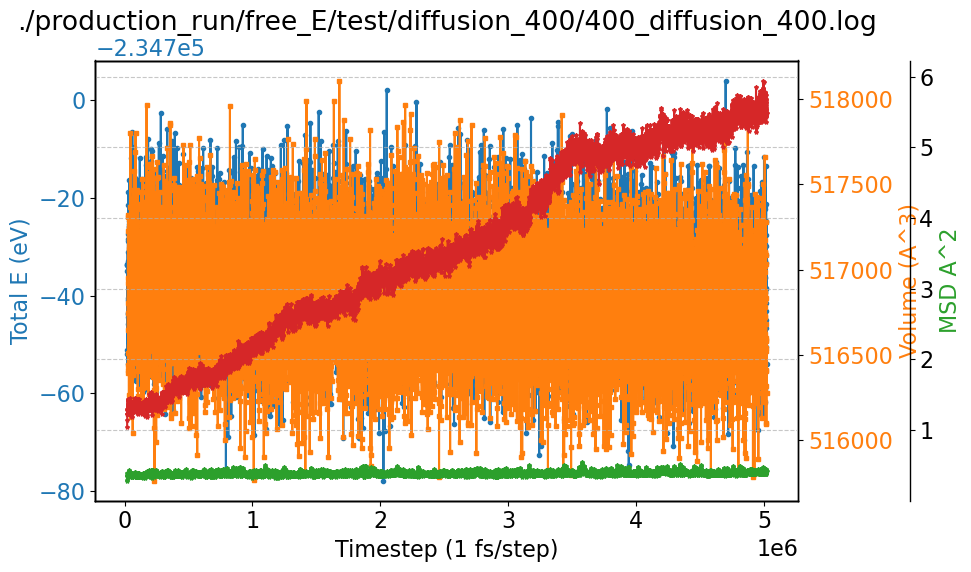

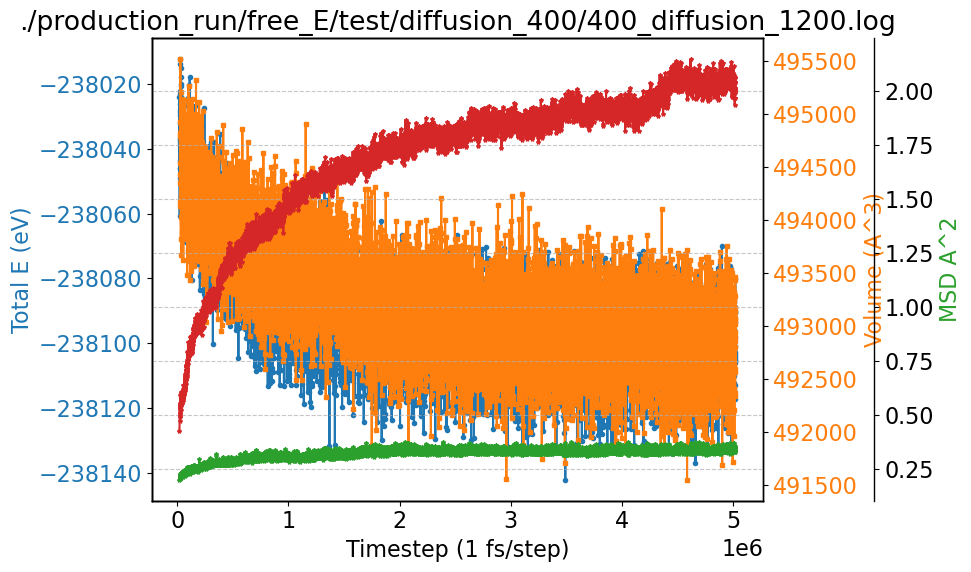

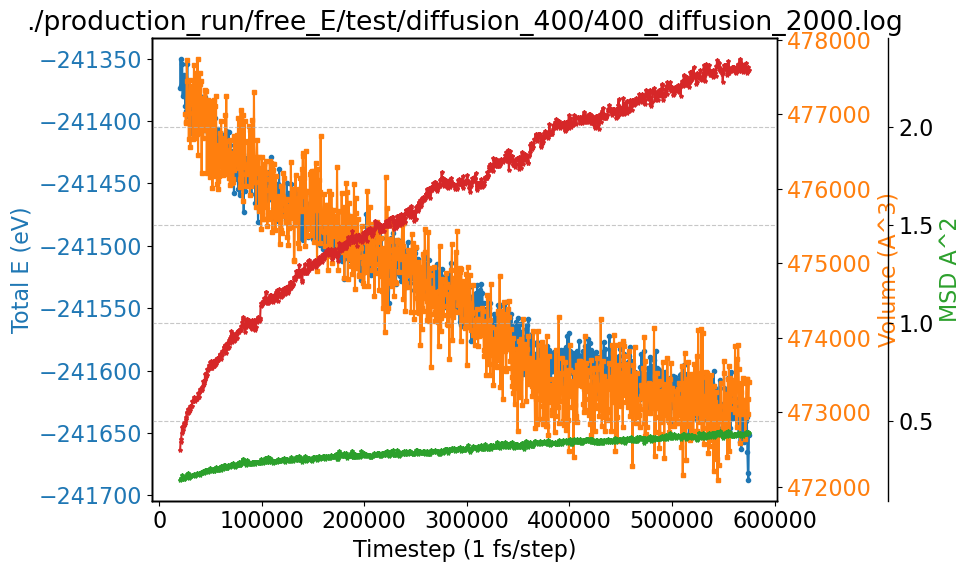

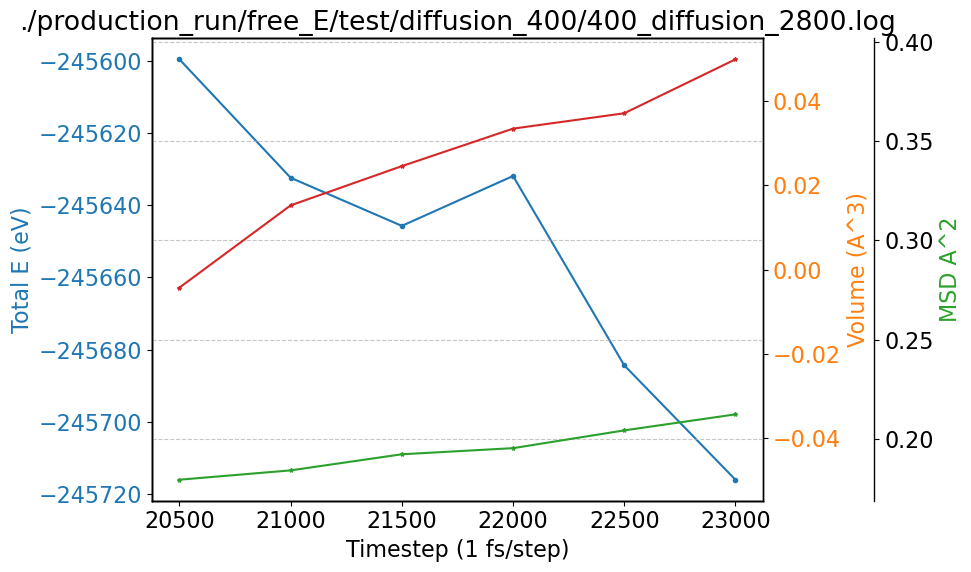

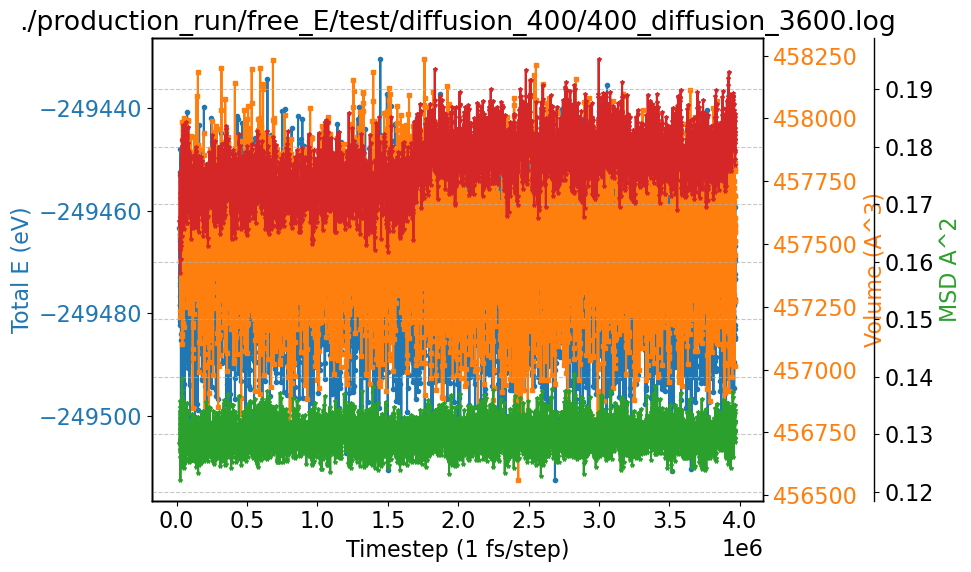

In [12]:
for i in [400,1200,2000,2800,3600]:
    file = f'./production_run/free_E/test/diffusion_400/400_diffusion_{i}.log'
    plot_log_diff(file)

### 500K

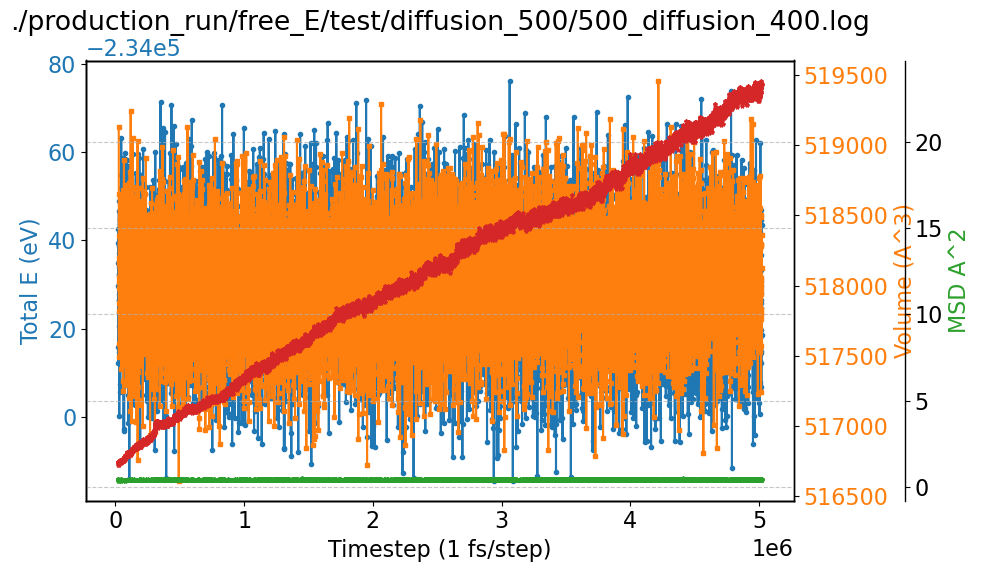

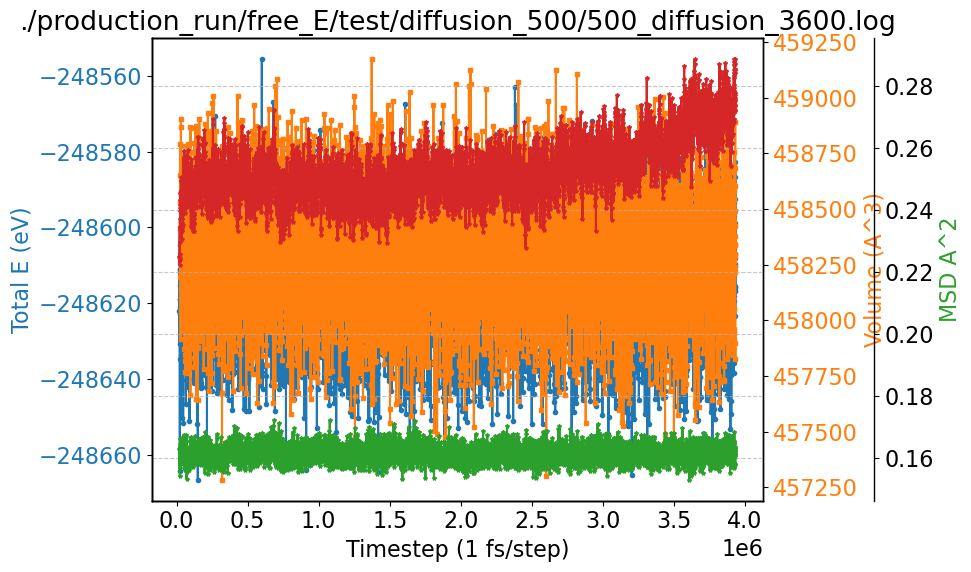

In [63]:
for i in [400,3600]:
    file = f'./production_run/free_E/test/diffusion_500/500_diffusion_{i}.log'
    plot_log_diff(file)

### 600K

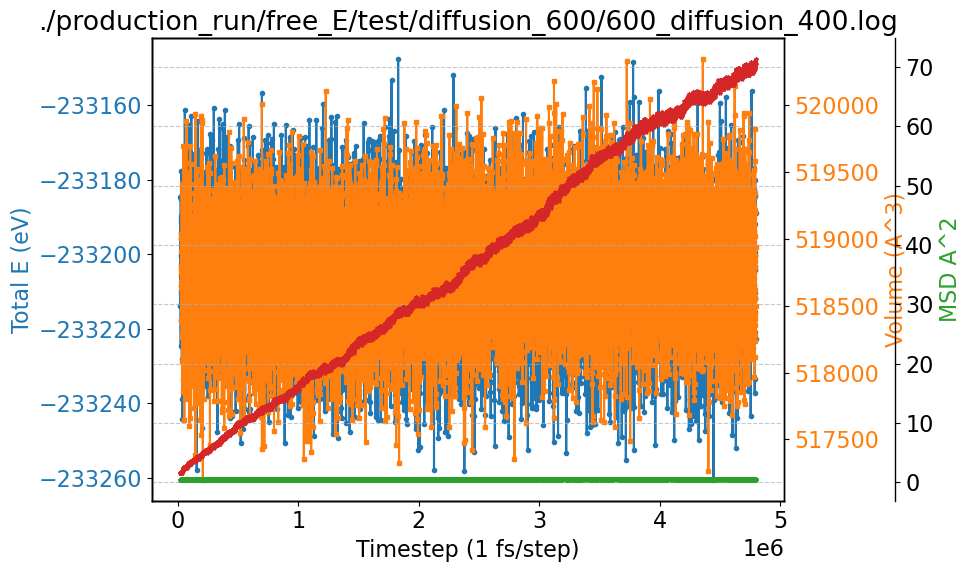

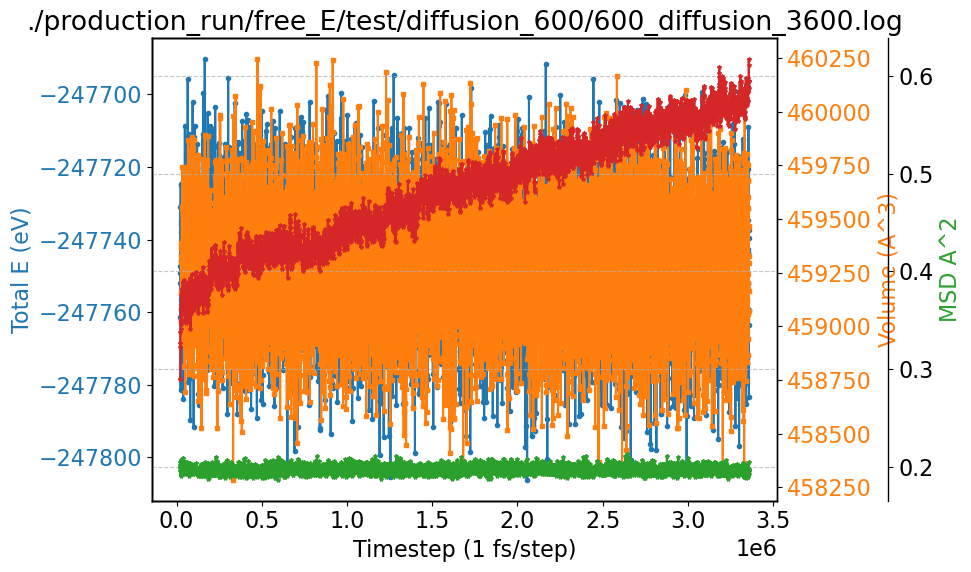

In [13]:
for i in [400,3600]:
    file = f'./production_run/free_E/test/diffusion_600/600_diffusion_{i}.log'
    plot_log_diff(file)

### 700K

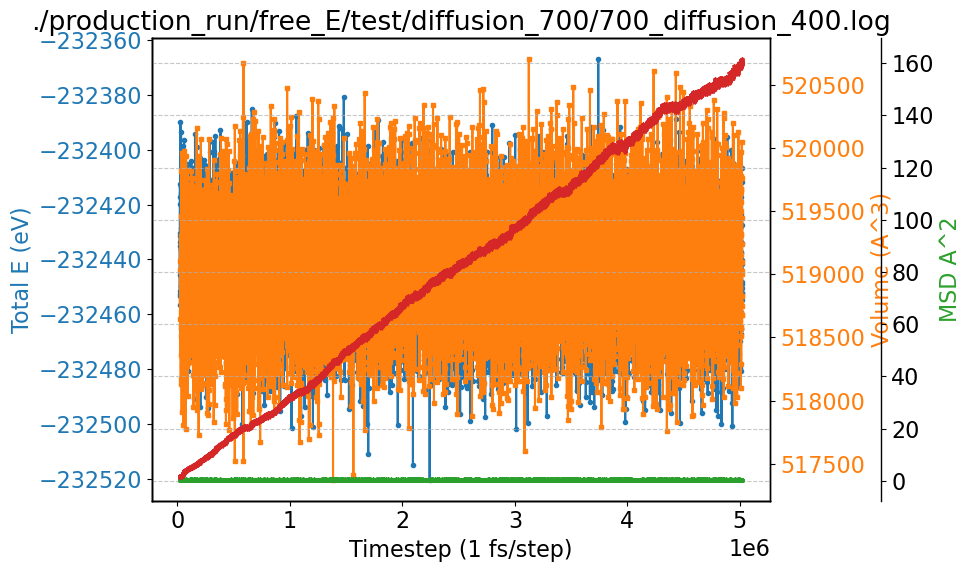

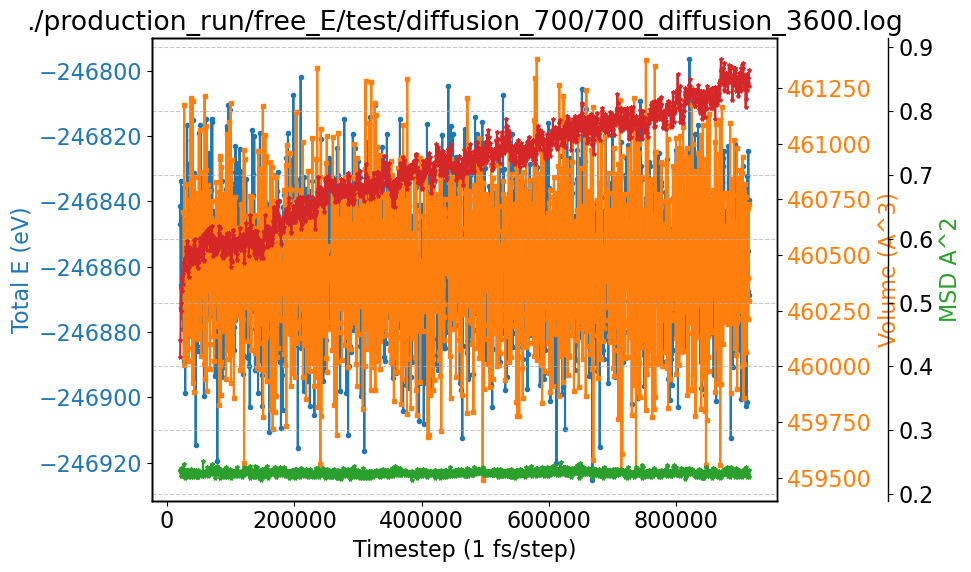

In [41]:
for i in [400,3600]:
    file = f'./production_run/free_E/test/diffusion_700/700_diffusion_{i}.log'
    plot_log_diff(file)

### 800K

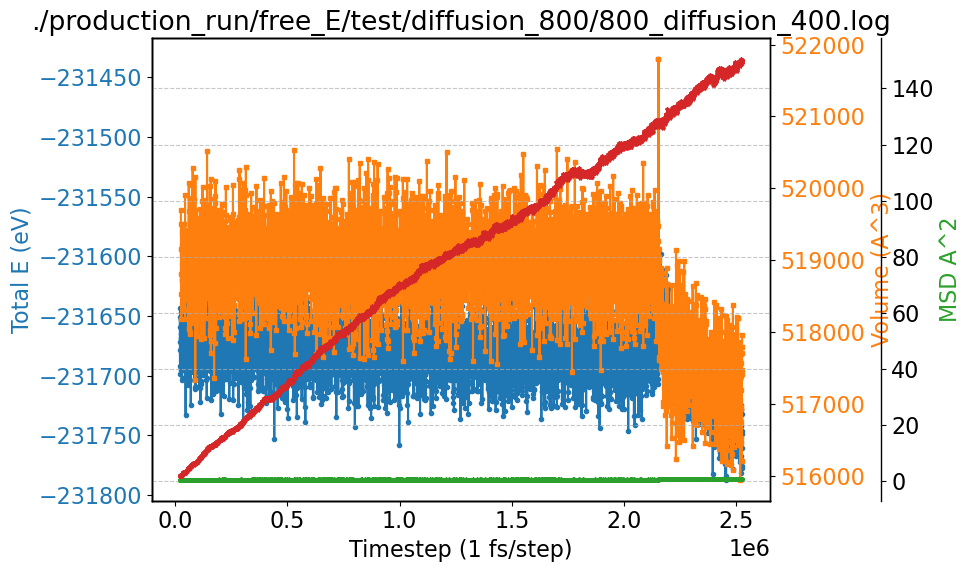

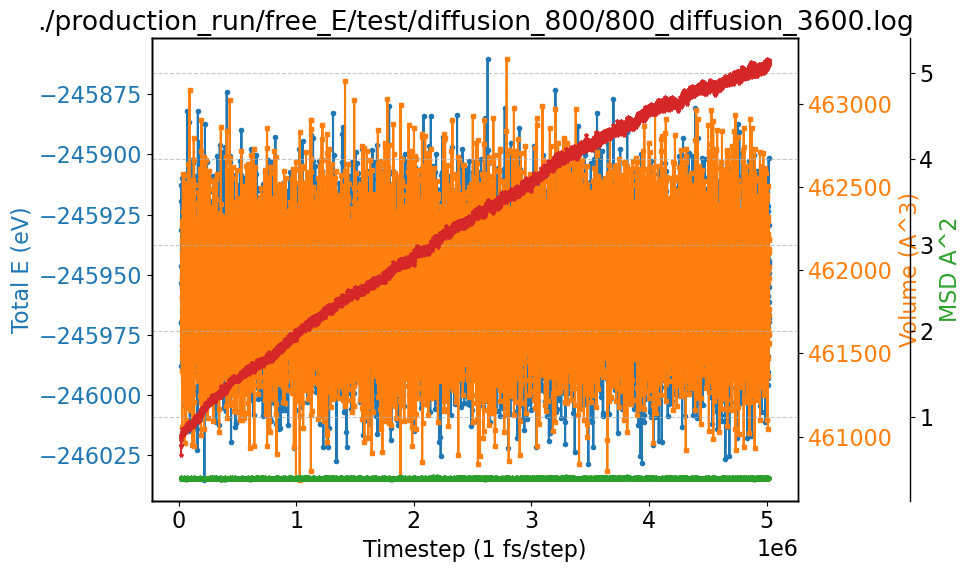

In [16]:
for i in [400,3600]:
    file = f'./production_run/free_E/test/diffusion_800/800_diffusion_{i}.log'
    plot_log_diff(file)

### 900K

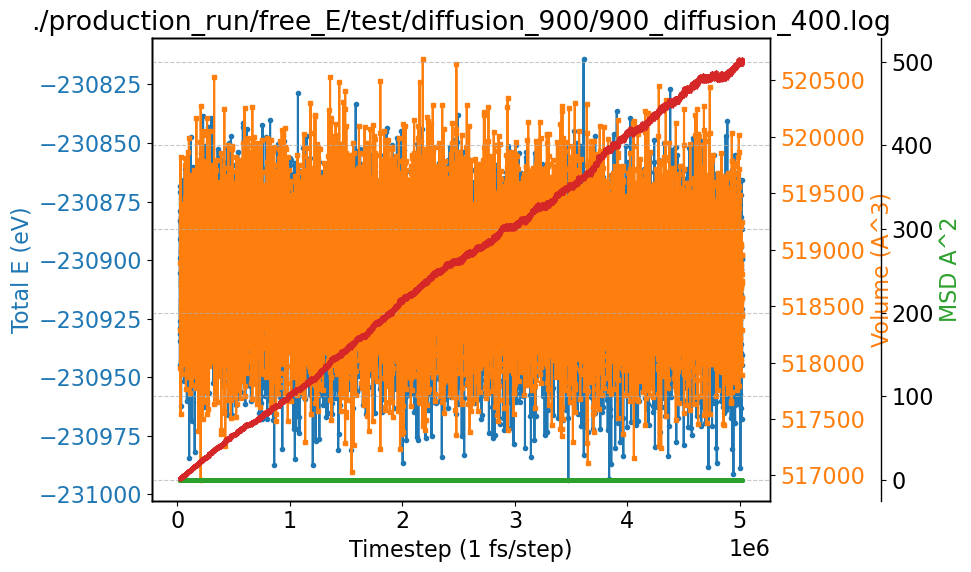

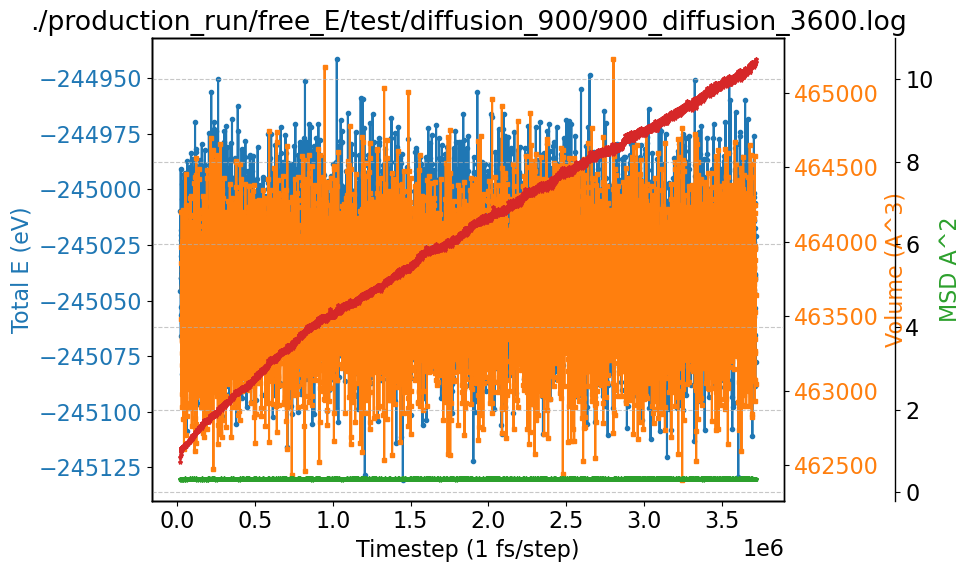

In [14]:
for i in [400,3600]:
    file = f'./production_run/free_E/test/diffusion_900/900_diffusion_{i}.log'
    plot_log_diff(file)

### 1000K

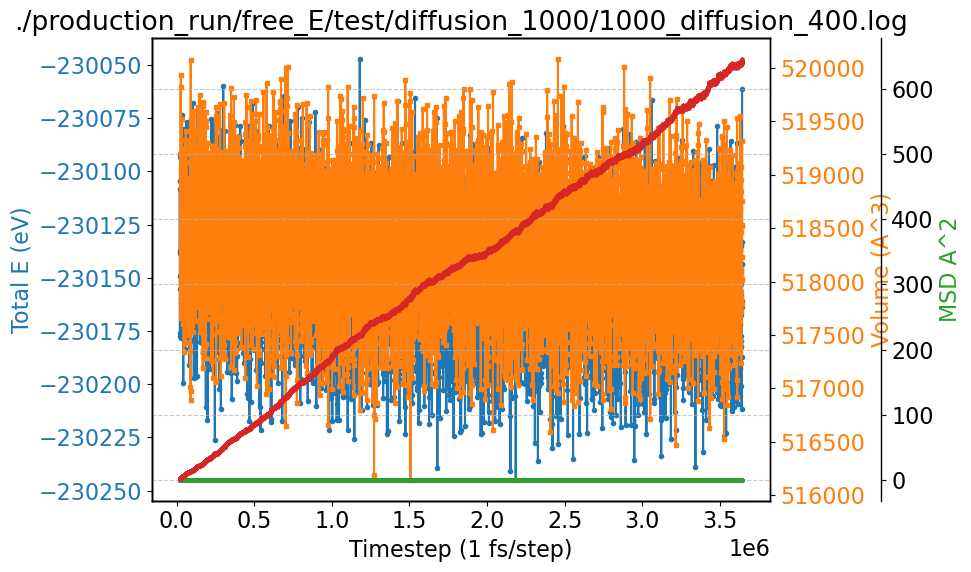

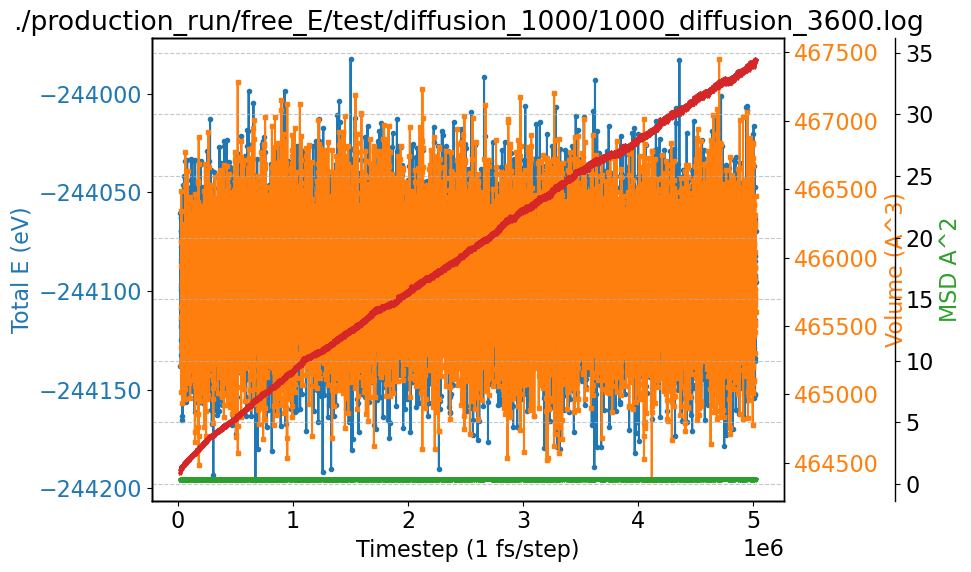

In [15]:
for i in [400,3600]:
    file = f'./production_run/free_E/test/diffusion_1000/1000_diffusion_{i}.log'
    plot_log_diff(file)

### Raise Temperature

In [ ]:
file = f'raise_temp.log'
path = './test_training_set/phase_diagram/'
log_data = parse_lammps_log_diff(path+file)
log_data_2 = parse_lammps_log(path+file)

In [ ]:
file = f'raise_temp.log'
path = './test_training_set/phase_diagram/'
log_data = parse_lammps_log_diff(path+file)
log_data_2 = parse_lammps_log(path+file)
num_Na = int(log_data['v_nNa'][0])

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (1 fs/step)')
ax1.set_ylabel('Volume (A^3)', color=color)
ax1.plot(log_data['Step'], log_data['Volume'], color=color, marker='o', markersize=3)
ax1.plot(log_data_2['Step'], log_data_2['Volume'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Temperature (K) (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Temp'][10:], color=color, marker='s', markersize=3)
ax2.plot(log_data_2['Step'][10:], log_data_2['Temp'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

# MSD(PB) (Third y-axis, second right)
ax3 = ax1.twinx()
color3 = 'tab:green'
ax3.spines['right'].set_position(('outward', 80))
ax3.set_ylabel('PB MSD A^2', color=color3)
ax3.plot(log_data['Step'], log_data['MSD(PB)'], color=color3, marker='*', markersize=3)
ax3.hlines(3,log_data['Step'][0],log_data['Step'][-1], color='r')
ax3.tick_params(axis='y')
ax3.grid(True, linestyle='--', alpha=0.7)

ax4 = ax1.twinx()
color4 = 'tab:purple'
ax4.spines['left'].set_position(('outward', 80))
ax4.set_ylabel('Na MSD A^2', color=color3)
ax4.plot(log_data['Step'], log_data['MSD(Na)'], color=color4, marker='*', markersize=3)
#ax4.tick_params(axis='y')

plt.title(file + f'    Number of Na = {num_Na}')
plt.tight_layout()
#plt.savefig(log_file_path+'.jpg', dpi=300, bbox_inches='tight')

In [ ]:
plt.plot(log_data['Step'], log_data['Temp'], label='Temperature')
plt2=plt.twinx()
plt2.plot(log_data['Step'], log_data['Volume'],color='orange', label'Volume')

In [ ]:
plt.plot(log_data['Step'], log_data['Temp'])
plt2=plt.twinx()
plt2.plot(log_data['Step'], log_data['MSD(Na)'],color='orange')

In [ ]:
filename = f'dump_raise_temp_Na.dat'
path = './test_training_set/diffusion/'
data_Na = pd.read_csv(path + filename, delim_whitespace=True, comment='#', header=None)
data_Na.columns = ['TimeStep', 'c_msd_Na[1]', 'c_msd_Na[2]', 'c_msd_Na[3]', 'c_msd_Na[4]']

filename = f'dump_raise_temp_PB.dat'
path = './test_training_set/diffusion/'
data_PB = pd.read_csv(path + filename, delim_whitespace=True, comment='#', header=None)
data_PB.columns = ['TimeStep', 'c_msd_PB[1]', 'c_msd_PB[2]', 'c_msd_PB[3]', 'c_msd_PB[4]']

In [ ]:
time = range(0, data_PB['TimeStep'].iloc[-1]+40000,40000)
temp = range(800,1600,50)
len(time),len(temp)

In [ ]:
plt.figure(figsize=(8,5))
#plt.plot(data_Na['TimeStep'], data_Na['c_msd_Na[1]'], label='MSD(x)')
#plt.plot(data_Na['TimeStep'], data_Na['c_msd_Na[2]'], label='MSD(y)')
#plt.plot(data_Na['TimeStep'], data_Na['c_msd_Na[3]'], label='MSD(z)')
plt.plot(data_Na['TimeStep'], data_Na['c_msd_Na[4]'], label='TMSD_Na')
#plt.plot(data_PB['TimeStep'], data_PB['c_msd_PB[1]'], label='MSD(x)')
#plt.plot(data_PB['TimeStep'], data_PB['c_msd_PB[2]'], label='MSD(y)')
#plt.plot(data_PB['TimeStep'], data_PB['c_msd_PB[3]'], label='MSD(z)')
plt.plot(data_PB['TimeStep'], data_PB['c_msd_PB[4]'], label='TMSD_PB')
plt.xlabel('Timestep (1 fs/step)')
plt.grid()
plt.ylabel('MSD (A^2)')

plt2 = plt.twinx()
plt2.scatter(time, temp)
plt.legend()


## MSD Analysis

In [ ]:
#data = {'Step': [], 'Temp': [], 'TotEng': [], 'Press': [], 'Volume': [], 'v_nNa': [], 'MSD(PB)' : [], 'MSD(Na)' : []}

In [18]:
i=400
file = f'./production_run/free_E/test/diffusion_1000/1000_diffusion_{i}.log'
data = parse_lammps_log(file)


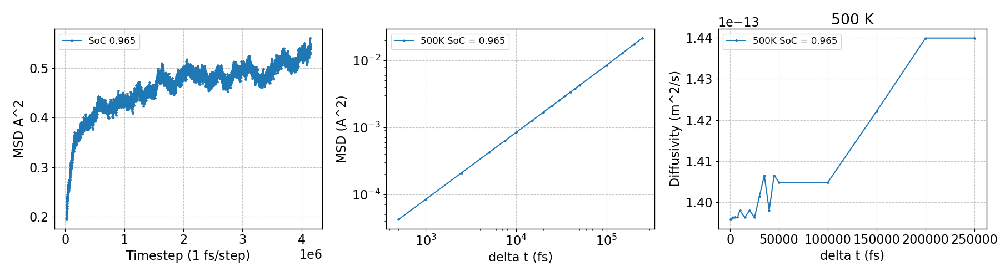

In [46]:
#%matplotlib widget

delta_t_ls = np.array([1, 2, 5, 10,15, 20,30,40, 50,60,70,80,90, 100, 200,300,400, 500])#,2000,5000]) #1, 2.5, 10, 25, 100, 250 ps

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18,5))
plt.subplots_adjust(wspace=1)

temp = 500
Na_list = [3952]#,1144,1944,3280,3600,3952]

diffusivity_list = []
num_Na_list = []
k=0
for index in Na_list:
    file = f'./production_run/free_E/test/diffusion_{temp}/{temp}_diffusion_{index}.log'
    log_data = parse_lammps_log_diff(file)
    MSD_Na = np.array(log_data['MSD(Na)'])
    timestep = np.array(log_data['Step'])
    num_Na = int(log_data['v_nNa'][0])-28672
    num_Na_list.append(num_Na)
    t_intival = []
    MSD_intival = []
    for i in range(delta_t_ls.shape[0]):
        #print(i, delta_t_ls[i]*0.5)
        t_intival.append(np.arange(timestep[0], timestep[-1], int(delta_t_ls[i])*500, dtype='int'))
        MSD_intival.append(np.linspace(MSD_Na[0], MSD_Na[-1], t_intival[i].shape[0]))

    delta_t_all = []
    delta_MSD_all = []
    for i in range(delta_t_ls.shape[0]):
        delta_t = []
        delta_MSD = []
        for j in range(t_intival[i].shape[0]-1):
            delta_t.append(t_intival[i][j+1] - t_intival[i][j])
            delta_MSD.append(MSD_intival[i][j+1] - MSD_intival[i][j])
        delta_t_all.append(delta_t)
        delta_MSD_all.append(delta_MSD)

    final_MSD = []
    final_t = []
    diffusivity = []
    for i in range(delta_t_ls.shape[0]):
        final_t.append(sum(delta_t_all[i])/len(delta_t_all[i]))
        final_MSD.append(sum(delta_MSD_all[i])/len(delta_MSD_all[i]))
        
    final_MSD = np.array(final_MSD)
    final_t = np.array(final_t)
    diffusivity_list.append(final_MSD/final_t/6*1e-5)
    
    ax2.plot(final_t, final_MSD, marker='*', markersize=3, label=f'{temp}K SoC = {round(Na_list[k]/4096,3)}')
    ax1.set_xlabel('Timestep (1 fs/step)')
    ax1.set_ylabel('MSD A^2')
    ax1.plot(log_data['Step'], log_data['MSD(Na)'],  marker='*', markersize=3, label=f'SoC {round(Na_list[k]/4096,3)}')
    k+=1
    
ax1.grid(True, linestyle='--', alpha=0.7)
ax2.grid(True, linestyle='--', alpha=0.7)
ax2.legend()
ax1.legend()
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_xlabel('delta t (fs)')
ax2.set_ylabel('MSD (A^2)')
plt.title(f'{temp} K')

for i in range(len(diffusivity_list)):
    ax3.plot(final_t, diffusivity_list[i], marker='*', markersize=3, label=f'{temp}K SoC = {round(Na_list[i]/4096,3)}')

ax3.grid(True, linestyle='--', alpha=0.7)
ax3.legend()
#ax3.set_xscale('log')
#ax3.set_yscale('log')
ax3.set_xlabel('delta t (fs)')
ax3.set_ylabel('Diffusivity (m^2/s)')

plt.tight_layout()
plt.savefig(f'./production_run/free_E/test/diffusion_{temp}K'+'.png', bbox_inches='tight')


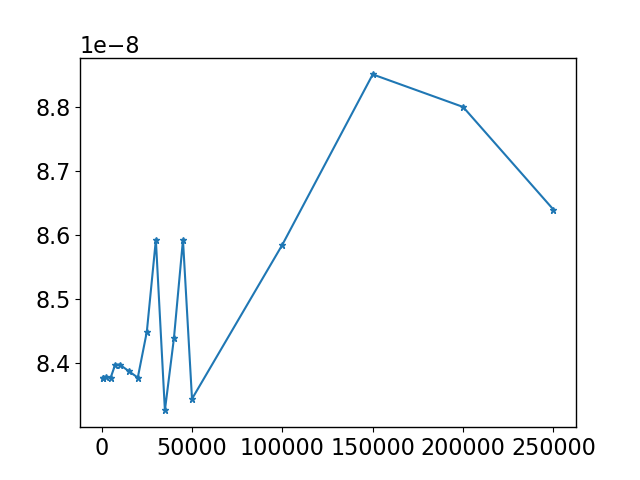

In [47]:
dMSD_dt = np.gradient(final_MSD, final_t)
plt.figure()
plt.plot(final_t, dMSD_dt, marker='*', markersize=5)

In [23]:
#%matplotlib widget
def MSD_analysis(temp, Na_list):
    delta_t_ls = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000,2000])#,2000,5000]) #1, 2.5, 10, 25, 100, 250 ps

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18,5))
    plt.subplots_adjust(wspace=1)
    
    temp = temp
    
    diffusivity_list = []
    num_Na_list = []
    k=0
    for index in Na_list:
        file = f'./production_run/free_E/test/diffusion_{temp}/{temp}_diffusion_{index}.log'
        log_data = parse_lammps_log_diff(file)
        MSD_Na = np.array(log_data['MSD(Na)'])
        timestep = np.array(log_data['Step'])
        num_Na = int(log_data['v_nNa'][0])-28672
        num_Na_list.append(num_Na)
        t_intival = []
        MSD_intival = []
        for i in range(delta_t_ls.shape[0]):
            #print(i, delta_t_ls[i]*0.5)
            t_intival.append(np.arange(timestep[0], timestep[-1], int(delta_t_ls[i])*500, dtype='int'))
            MSD_intival.append(np.linspace(MSD_Na[0], MSD_Na[-1], t_intival[i].shape[0]))
    
        delta_t_all = []
        delta_MSD_all = []
        for i in range(delta_t_ls.shape[0]):
            delta_t = []
            delta_MSD = []
            for j in range(t_intival[i].shape[0]-1):
                delta_t.append(t_intival[i][j+1] - t_intival[i][j])
                delta_MSD.append(MSD_intival[i][j+1] - MSD_intival[i][j])
            delta_t_all.append(delta_t)
            delta_MSD_all.append(delta_MSD)
    
        final_MSD = []
        final_t = []
        diffusivity = []
        for i in range(delta_t_ls.shape[0]):
            final_t.append(sum(delta_t_all[i])/len(delta_t_all[i]))
            final_MSD.append(sum(delta_MSD_all[i])/len(delta_MSD_all[i]))
            
        final_MSD = np.array(final_MSD)
        final_t = np.array(final_t)
        diffusivity_list.append(final_MSD/final_t/6*1e-5)
        
        ax2.plot(final_t, final_MSD, marker='*', markersize=3, label=f'{temp}K SoC = {round(Na_list[k]/4096,3)}')
        ax1.set_xlabel('Timestep (1 fs/step)')
        ax1.set_ylabel('MSD A^2')
        ax1.plot(log_data['Step'], log_data['MSD(Na)'],  marker='*', markersize=3, label=f'SoC {round(Na_list[k]/4096,3)}')
        k+=1
        
    ax1.grid(True, linestyle='--', alpha=0.7)
    ax2.grid(True, linestyle='--', alpha=0.7)
    ax2.legend()
    ax1.legend()
    ax2.set_xscale('log')
    ax2.set_yscale('log')
    ax2.set_xlabel('delta t (fs)')
    ax2.set_ylabel('MSD (A^2)')
    plt.title(f'{temp} K')
    
    for i in range(len(diffusivity_list)):
        ax3.plot(final_t, diffusivity_list[i], marker='*', markersize=3, label=f'{temp}K SoC = {round(Na_list[i]/4096,3)}')
    
    ax3.grid(True, linestyle='--', alpha=0.7)
    ax3.legend()
    #ax3.set_xscale('log')
    #ax3.set_yscale('log')
    ax3.set_xlabel('delta t (fs)')
    ax3.set_ylabel('Diffusivity (m^2/s)')
    
    plt.tight_layout()
    plt.savefig(f'./production_run/free_E/test/diffusion_{temp}K'+'.png', bbox_inches='tight')
    return diffusivity_list

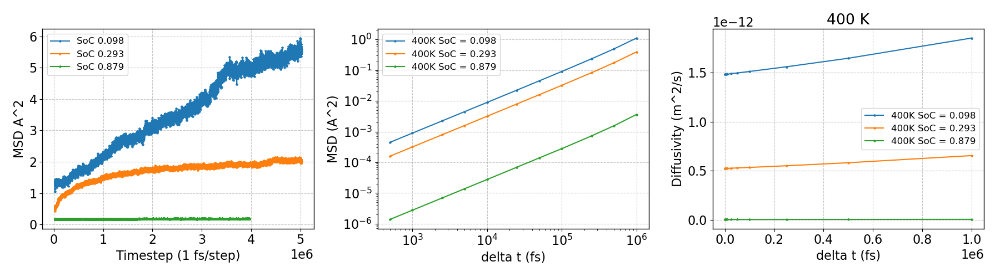

In [52]:
diff_400=MSD_analysis(400,[400,1200,3600])

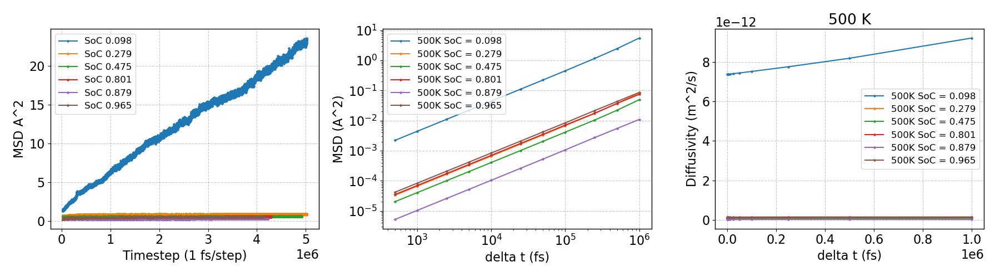

In [24]:
diff_500=MSD_analysis(500,[400,1144,1944,3280,3600,3952])

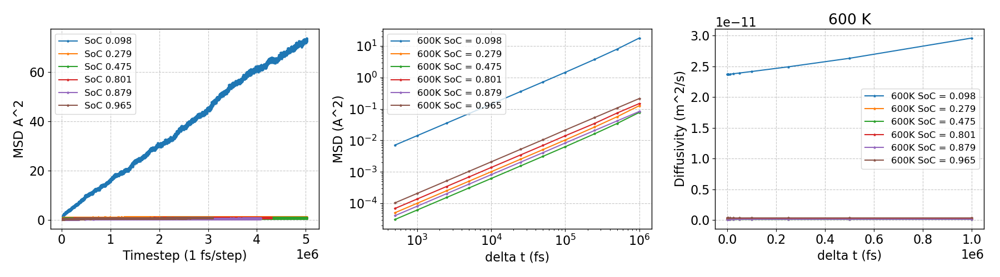

In [25]:
diff_600=MSD_analysis(600,[400,1144,1944,3280,3600,3952])

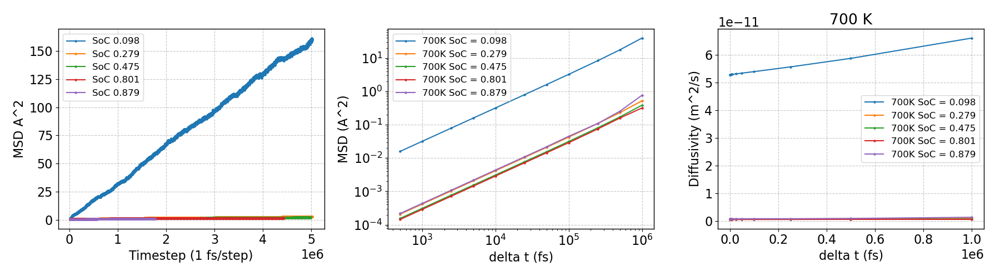

In [27]:
diff_700=MSD_analysis(700,[400,1144,1944,3280,3600])

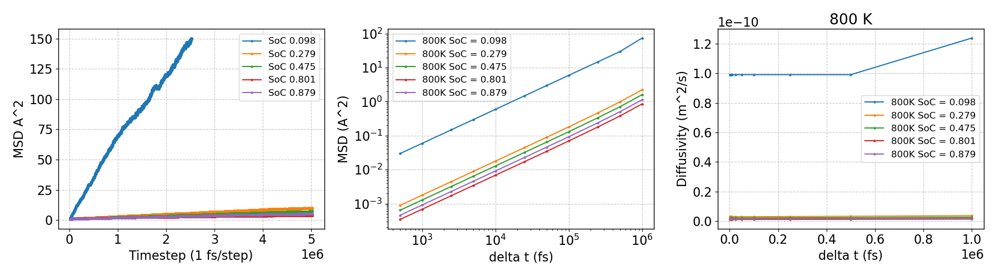

In [28]:
diff_800=MSD_analysis(800,[400,1144,1944,3280,3600])

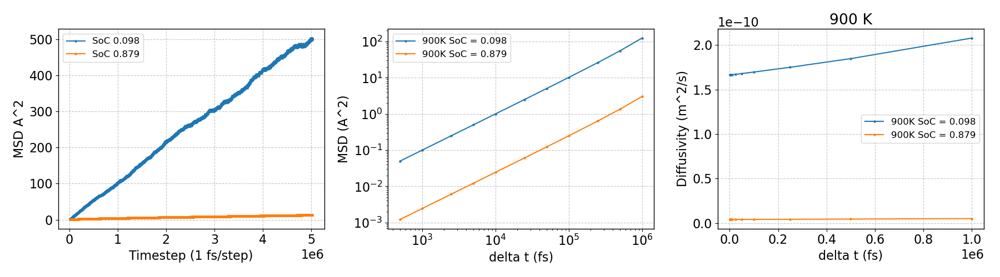

In [53]:
diff_900=MSD_analysis(900,[400,3600])

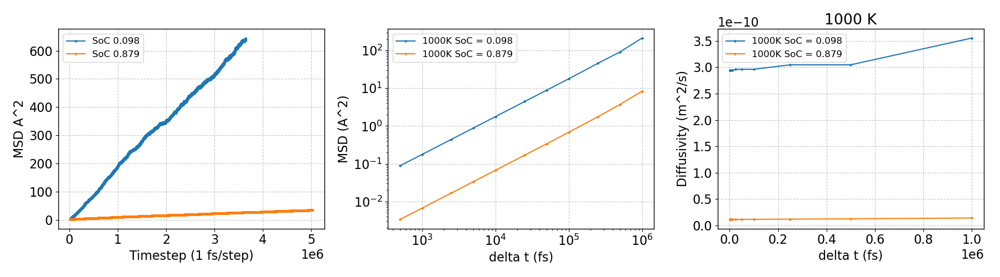

In [54]:
diff_1000=MSD_analysis(1000,[400,3600])

In [ ]:
delta_t_ls = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000,2000,5000]) #1, 2.5, 10, 25, 100, 250 ps

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18,5))
plt.subplots_adjust(wspace=1)

temp = 800

diffusivity_list = []
num_Na_list = []
for index in [2, 4, 6]:
    file = f'./test_training_set/diffusion/{temp}_diffuse_{index}.log'
    log_data = parse_lammps_log_diff(file)
    MSD_Na = np.array(log_data['MSD(Na)'])
    timestep = np.array(log_data['Step'])
    num_Na = int(log_data['v_nNa'][0])
    num_Na_list.append(num_Na)
    t_intival = []
    MSD_intival = []
    for i in range(delta_t_ls.shape[0]):
        #print(i, delta_t_ls[i]*0.5)
        t_intival.append(np.arange(timestep[0], timestep[-1], int(delta_t_ls[i])*500, dtype='int'))
        MSD_intival.append(np.linspace(MSD_Na[0], MSD_Na[-1], t_intival[i].shape[0]))

    delta_t_all = []
    delta_MSD_all = []
    for i in range(delta_t_ls.shape[0]):
        delta_t = []
        delta_MSD = []
        for j in range(t_intival[i].shape[0]-1):
            delta_t.append(t_intival[i][j+1] - t_intival[i][j])
            delta_MSD.append(MSD_intival[i][j+1] - MSD_intival[i][j])
        delta_t_all.append(delta_t)
        delta_MSD_all.append(delta_MSD)

    final_MSD = []
    final_t = []
    diffusivity = []
    for i in range(delta_t_ls.shape[0]):
        final_t.append(sum(delta_t_all[i])/len(delta_t_all[i]))
        final_MSD.append(sum(delta_MSD_all[i])/len(delta_MSD_all[i]))
        
    final_MSD = np.array(final_MSD)
    final_t = np.array(final_t)
    diffusivity_list.append(final_MSD/final_t/6*1e-5)
    
    ax2.plot(final_t, final_MSD, marker='*', markersize=3, label=f'{temp}K SoC = {round(num_Na/4096,3)}')
    ax1.set_xlabel('Timestep (1 fs/step)')
    ax1.set_ylabel('MSD A^2')
    ax1.plot(log_data['Step'], log_data['MSD(Na)'],  marker='*', markersize=3, label=f'SoC {round(num_Na/4096,3)}')
    
ax1.grid(True, linestyle='--', alpha=0.7)
ax2.grid(True, linestyle='--', alpha=0.7)
ax2.legend()
ax1.legend()
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_xlabel('delta t (fs)')
ax2.set_ylabel('MSD (A^2)')

for i in range(len(diffusivity_list)):
    ax3.plot(final_t, diffusivity_list[i], marker='*', markersize=3, label=f'{temp}K SoC = {round(num_Na_list[i]/4096,3)}')

ax3.grid(True, linestyle='--', alpha=0.7)
ax3.legend()
#ax3.set_xscale('log')
#ax3.set_yscale('log')
ax3.set_xlabel('delta t (fs)')
ax3.set_ylabel('Diffusivity (m^2/s)')
diffusivity_list_800K = diffusivity_list
plt.tight_layout()

In [40]:
Na_90_diff_ls=[diff_400[-1][i], diff_500[-2][i], diff_600[-2][i], diff_700[-1][i], diff_800[-1][i], diff_900[-1][i], diff_1000[-1][i]]
Na_90_diff_ls

[4.81524000000001e-15,
 1.7487323076923085e-14,
 1.3805165833333336e-13,
 1.0403952e-12,
 1.5943653192982458e-12,
 4.647411552380952e-12,
 1.1746909585964911e-11]

In [ ]:
big_diff = [diff_4000, diff_600, diff_800, diff_1000]
diffusivity_1 = []
diffusivity_2 = []
diffusivity_3 = []
diffusivity_4 = []
temp = np.array([400, 600, 800, 1000])

for i in range(temp.shape[0]):
    diffusivity_1.append(big_diff[i][0][9])
    diffusivity_2.append(big_diff[i][1][9])
    diffusivity_3.append(big_diff[i][2][9])
    diffusivity_4.append(big_diff[i][2][9])


Text(0, 0.5, 'Diffusivity (m^2/s)')

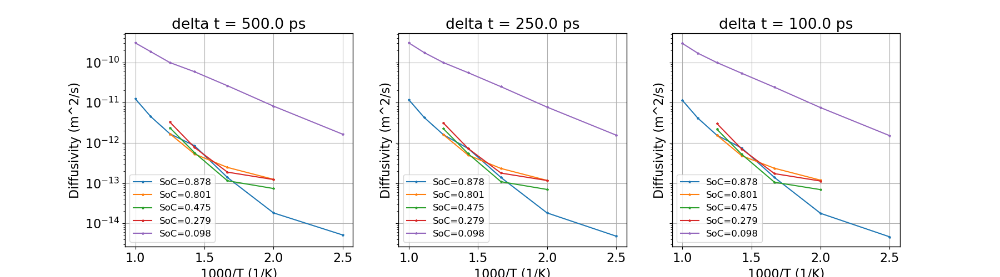

In [55]:
temp_1 = np.array([400, 500, 600, 700, 800, 900, 1000])
temp_2 = np.array([500, 600, 700, 800])
delta_t_ls = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000,2000,5000])
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18,5), sharey=True)

i=9
Na_90_diff_ls=[diff_400[-1][i], diff_500[-2][i], diff_600[-2][i], diff_700[-1][i], diff_800[-1][i], diff_900[-1][i], diff_1000[-1][i]]
Na_80_diff_ls=[diff_500[-3][i], diff_600[-3][i],diff_700[-2][i],diff_800[-1][i]]
Na_50_diff_ls=[diff_500[2][i], diff_600[2][i],diff_700[2][i],diff_800[2][i]]
Na_30_diff_ls=[diff_500[1][i], diff_600[1][i],diff_700[1][i],diff_800[1][i]]
Na_10_diff_ls=[diff_400[0][i], diff_500[0][i],diff_600[0][i],diff_700[0][i],diff_800[0][i],diff_900[0][i],diff_1000[0][i]]

ax1.plot(1/temp_1*1000, Na_90_diff_ls, marker='*', markersize=3, label='SoC=0.878')
ax1.plot(1/temp_2*1000, Na_80_diff_ls, marker='*', markersize=3, label='SoC=0.801')
ax1.plot(1/temp_2*1000, Na_50_diff_ls, marker='*', markersize=3, label='SoC=0.475')
ax1.plot(1/temp_2*1000, Na_30_diff_ls, marker='*', markersize=3, label='SoC=0.279')
ax1.plot(1/temp_1*1000, Na_10_diff_ls, marker='*', markersize=3, label='SoC=0.098')
ax1.legend()
ax1.grid()
ax1.set_title(f'delta t = {delta_t_ls[i]*0.5} ps')
#ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_xlabel('1000/T (1/K)')
ax1.set_ylabel('Diffusivity (m^2/s)')

i=8
Na_90_diff_ls=[diff_400[-1][i], diff_500[-2][i], diff_600[-2][i], diff_700[-1][i], diff_800[-1][i], diff_900[-1][i], diff_1000[-1][i]]
Na_80_diff_ls=[diff_500[-3][i], diff_600[-3][i],diff_700[-2][i],diff_800[-1][i]]
Na_50_diff_ls=[diff_500[2][i], diff_600[2][i],diff_700[2][i],diff_800[2][i]]
Na_30_diff_ls=[diff_500[1][i], diff_600[1][i],diff_700[1][i],diff_800[1][i]]
Na_10_diff_ls=[diff_400[0][i], diff_500[0][i],diff_600[0][i],diff_700[0][i],diff_800[0][i],diff_900[0][i],diff_1000[0][i]]

ax2.plot(1/temp_1*1000, Na_90_diff_ls, marker='*', markersize=3, label='SoC=0.878')
ax2.plot(1/temp_2*1000, Na_80_diff_ls, marker='*', markersize=3, label='SoC=0.801')
ax2.plot(1/temp_2*1000, Na_50_diff_ls, marker='*', markersize=3, label='SoC=0.475')
ax2.plot(1/temp_2*1000, Na_30_diff_ls, marker='*', markersize=3, label='SoC=0.279')
ax2.plot(1/temp_1*1000, Na_10_diff_ls, marker='*', markersize=3, label='SoC=0.098')
ax2.legend()
ax2.grid()
ax2.set_title(f'delta t = {delta_t_ls[i]*0.5} ps')
#ax1.set_xscale('log')
ax2.set_yscale('log')
ax2.set_xlabel('1000/T (1/K)')
ax2.set_ylabel('Diffusivity (m^2/s)')

i=7
Na_90_diff_ls=[diff_400[-1][i], diff_500[-2][i], diff_600[-2][i], diff_700[-1][i], diff_800[-1][i], diff_900[-1][i], diff_1000[-1][i]]
Na_80_diff_ls=[diff_500[-3][i], diff_600[-3][i],diff_700[-2][i],diff_800[-1][i]]
Na_50_diff_ls=[diff_500[2][i], diff_600[2][i],diff_700[2][i],diff_800[2][i]]
Na_30_diff_ls=[diff_500[1][i], diff_600[1][i],diff_700[1][i],diff_800[1][i]]
Na_10_diff_ls=[diff_400[0][i], diff_500[0][i],diff_600[0][i],diff_700[0][i],diff_800[0][i],diff_900[0][i],diff_1000[0][i]]

ax3.plot(1/temp_1*1000, Na_90_diff_ls, marker='*', markersize=3, label='SoC=0.878')
ax3.plot(1/temp_2*1000, Na_80_diff_ls, marker='*', markersize=3, label='SoC=0.801')
ax3.plot(1/temp_2*1000, Na_50_diff_ls, marker='*', markersize=3, label='SoC=0.475')
ax3.plot(1/temp_2*1000, Na_30_diff_ls, marker='*', markersize=3, label='SoC=0.279')
ax3.plot(1/temp_1*1000, Na_10_diff_ls, marker='*', markersize=3, label='SoC=0.098')
ax3.legend()
ax3.grid()
ax3.set_title(f'delta t = {delta_t_ls[i]*0.5} ps')
#ax1.set_xscale('log')
ax3.set_yscale('log')
ax3.set_xlabel('1000/T (1/K)')
ax3.set_ylabel('Diffusivity (m^2/s)')

In [107]:
i=9
Na_90_diff_ls=[diff_400[-1][i], diff_500[-2][i], diff_600[-2][i], diff_700[-1][i], diff_800[-1][i], diff_900[-1][i], diff_1000[-1][i]]
Na_80_diff_ls=[diff_500[-3][i], diff_600[-3][i],diff_700[-2][i],diff_800[-1][i]]
Na_50_diff_ls=[diff_500[2][i], diff_600[2][i],diff_700[2][i],diff_800[2][i]]
Na_30_diff_ls=[diff_500[1][i], diff_600[1][i],diff_700[1][i],diff_800[1][i]]
Na_10_diff_ls=[diff_400[0][i], diff_500[0][i],diff_600[0][i],diff_700[0][i],diff_800[0][i],diff_900[0][i],diff_1000[0][i]]

In [73]:
Na_90_diff_ls, np.log10(Na_90_diff_ls)

([4.583032994923868e-15,
  1.633155172413794e-14,
  1.36347316872428e-13,
  7.963857465277777e-13,
  1.517682418169673e-12,
  4.408113938572719e-12,
  1.118192796259185e-11],
 array([-14.33884702, -13.78697255, -12.8653534 , -12.09887652,
        -11.8188191 , -11.35574719, -10.95148331]))

In [56]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def fit_diff(temp_ls, Na_diff_ls, SoC):

    # Define the exponential function
    def exp_func(x, a, b):
        return a + b * x
    
    # Prepare your data
    x_data = 1/temp_ls  # Reciprocal of temperature
    y_data = np.log(Na_diff_ls)  # Diffusivity values
    
    # Perform curve fitting
    popt, pcov = curve_fit(exp_func, x_data, y_data, p0=(1, 1))
    a_fit, b_fit = popt
    
    # Calculate standard errors
    perr = np.sqrt(np.diag(pcov))
    a_err, b_err = perr
    
    # Print fitted parameters with their uncertainties
    print(f"Fitted Parameters:")
    print(f"a = {a_fit} ± {a_err}")
    print(f"b = {b_fit:.5f} ± {b_err:.5f}")
    
    # Calculate R-squared to assess goodness of fit
    residuals = y_data - exp_func(x_data, a_fit, b_fit)
    ss_res = np.sum(residuals**2)
    ss_tot = np.sum((y_data - np.mean(y_data))**2)
    r_squared = 1 - (ss_res / ss_tot)
    print(f"R-squared: {r_squared:.5f}")
    
    # Plotting
    plt.figure(figsize=(6, 6))
    plt.scatter(1000*x_data, y_data, label='Experimental Data')
    x_fit = np.linspace(x_data.min(), x_data.max(), 100)
    y_fit = exp_func(x_fit, a_fit, b_fit)
    D_300K = exp_func(1/300, a_fit, b_fit)
    print(f'(D(300K)) = {np.exp(D_300K)*10000} cm^2/s')
    plt.plot(1000*x_fit, y_fit, 'r-', label='Fitted Curve')
    plt.scatter(1000/300, D_300K)
    plt.xlabel('1000/T')
    plt.ylabel('log(Diffusivity)')
    plt.title(f'Diffusivity Exponential Fit at SoC={SoC}')
    plt.legend()
    plt.savefig(f'./production_run/free_E/test/diffusion_fit_{SoC}'+'.png', bbox_inches='tight')
    #plt.xscale('log')
    #plt.yscale('log')
    plt.grid(True)
    plt.show()
    return a_fit, b_fit, b_err

Fitted Parameters:
a = -18.628621121611857 ± 0.11774230284699816
b = -3467.81698 ± 71.72087
R-squared: 0.99787
(D(300K)) = 7.75377841895047e-10 cm^2/s


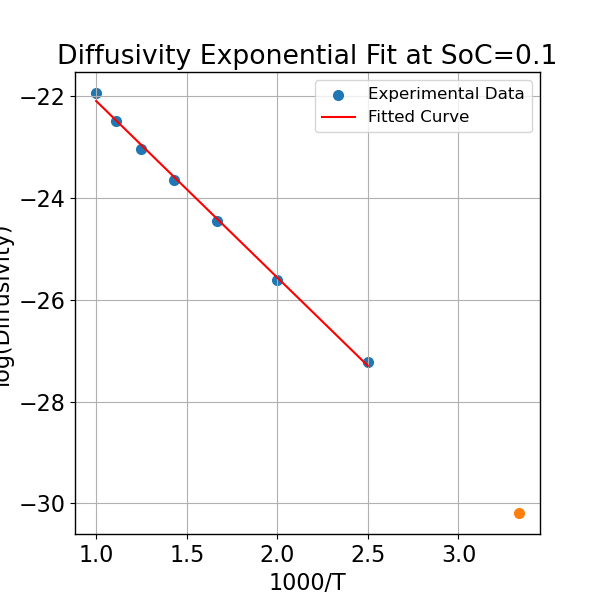

Fitted Parameters:
a = -19.104991512979044 ± 0.31761696735900863
b = -6287.36937 ± 219.04043
R-squared: 0.99517
(D(300K)) = 3.989405648753982e-14 cm^2/s


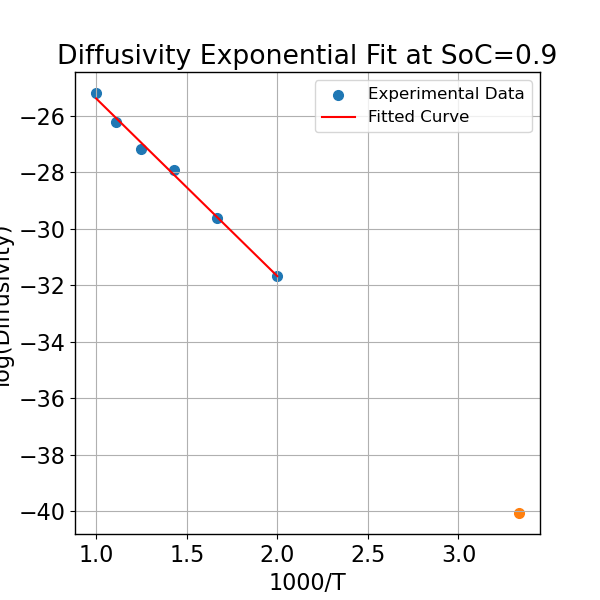

In [57]:
a_fit_10, b_fit_10, b_err_10 = fit_diff(temp_1, Na_10_diff_ls, 0.1)
a_fit_90, b_fit_90, b_err_90 = fit_diff(np.array([500, 600, 700, 800, 900, 1000]), [diff_500[-2][i], diff_600[-2][i], diff_700[-1][i], diff_800[-1][i], diff_900[-1][i], diff_1000[-1][i]], 0.9)

In [97]:
from mpi4py import MPI

ModuleNotFoundError: No module named 'mpi4py'

Fitted Parameters:
a = -18.088174107215842 ± 0.9038525870342424
b = -6819.74190 ± 619.74160
R-squared: 0.99181
(D(300K)) = 1.8698992903366578e-14 cm^2/s


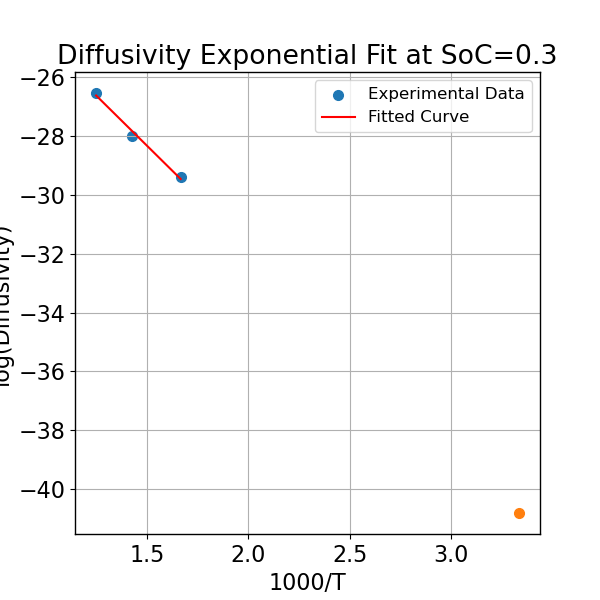

Fitted Parameters:
a = -17.851973248509054 ± 0.5072015247698312
b = -7240.27695 ± 347.77120
R-squared: 0.99770
(D(300K)) = 5.82924232621806e-15 cm^2/s


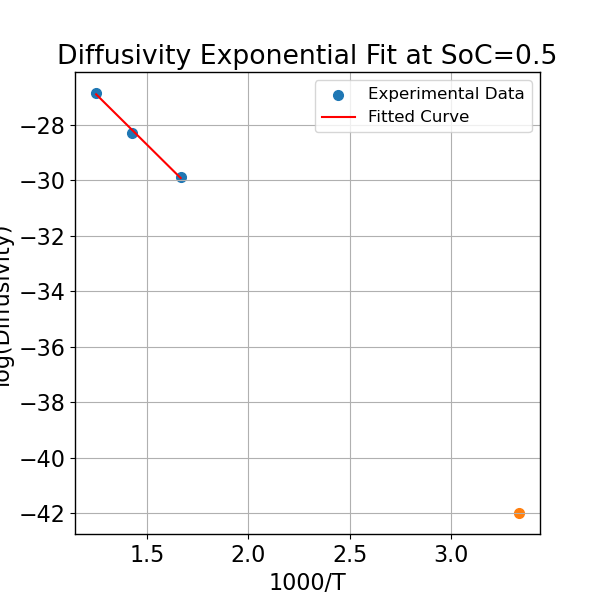

Fitted Parameters:
a = -21.771659905749527 ± 1.4423991514983325
b = -4447.94322 ± 989.00505
R-squared: 0.95289
(D(300K)) = 1.275354501991703e-12 cm^2/s


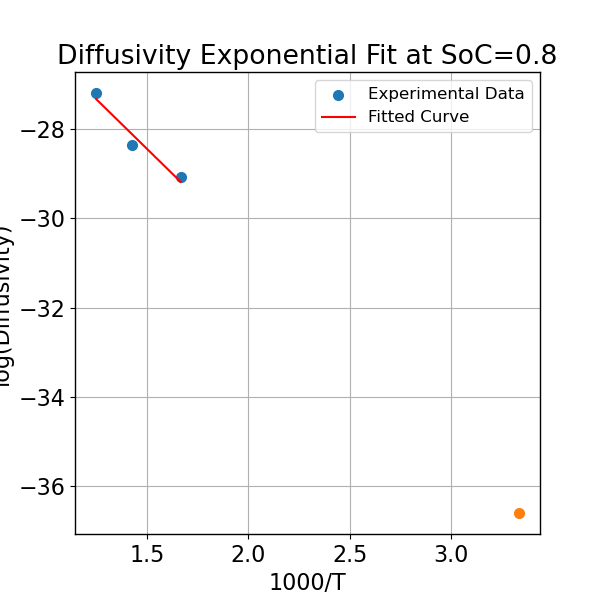

In [58]:
temp_2 = np.array([600, 700, 800])
Na_80_diff_ls=[diff_600[-3][i],diff_700[-2][i],diff_800[-1][i]]
Na_50_diff_ls=[diff_600[2][i],diff_700[2][i],diff_800[2][i]]
Na_30_diff_ls=[diff_600[1][i],diff_700[1][i],diff_800[1][i]]
a_fit_30, b_fit_30, b_err_30 = fit_diff(temp_2, Na_30_diff_ls, 0.3)
a_fit_50, b_fit_50, b_err_50 = fit_diff(temp_2, Na_50_diff_ls, 0.5)
a_fit_80, b_fit_80, b_err_80 = fit_diff(temp_2, Na_80_diff_ls, 0.8)

In [110]:
-b_fit_10*8.617e-5, -b_fit_90*8.617e-5

(0.2958580622647323, 0.5483317355466188)

In [111]:
-b_fit_30*8.617e-5, -b_fit_50*8.617e-5, -b_fit_80*8.617e-5

(0.5876571553121461, 0.6238946652534206, 0.39130391454519803)

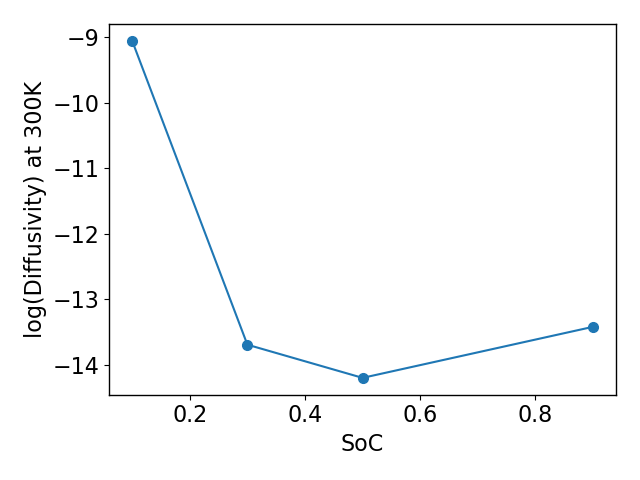

In [61]:
plt.figure()
x = [0.1,0.3,0.5,0.9]
y= np.log10([8.792024598867522e-10, 2.036112737882432e-14, 6.347397086378334e-15, 3.8131251496869285e-14])
plt.plot(x,y, marker='o')
plt.xlabel('SoC')
plt.ylabel('log(Diffusivity) at 300K')
plt.tight_layout()

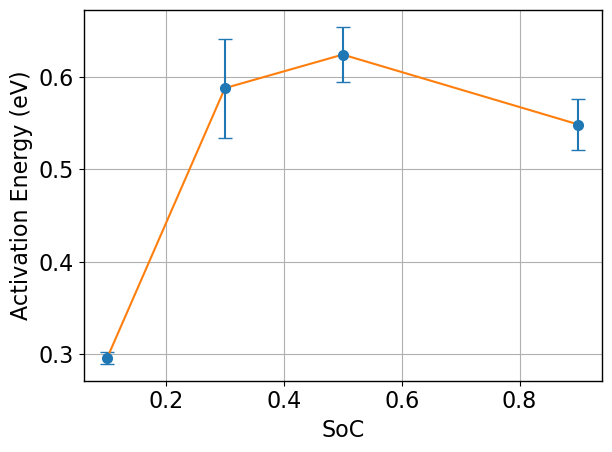

In [113]:
plt.figure()
x = [0.1,0.3,0.5,0.9]
y = np.array([-b_fit_10, -b_fit_30, -b_fit_50, -b_fit_90])*8.617e-5
yerr = np.array([b_err_10, b_err_30, b_err_50, b_err_90])*8.617e-5
plt.errorbar(x, y, yerr=yerr, fmt='o', capsize=5)
plt.plot(x,y)
plt.xlabel('SoC')
plt.ylabel('Activation Energy (eV)')
plt.grid()
plt.tight_layout()

Fitted Parameters:
a = 0.00000 ± 0.00000
b = -4108.63083 ± 159.79730
R-squared: 0.99927


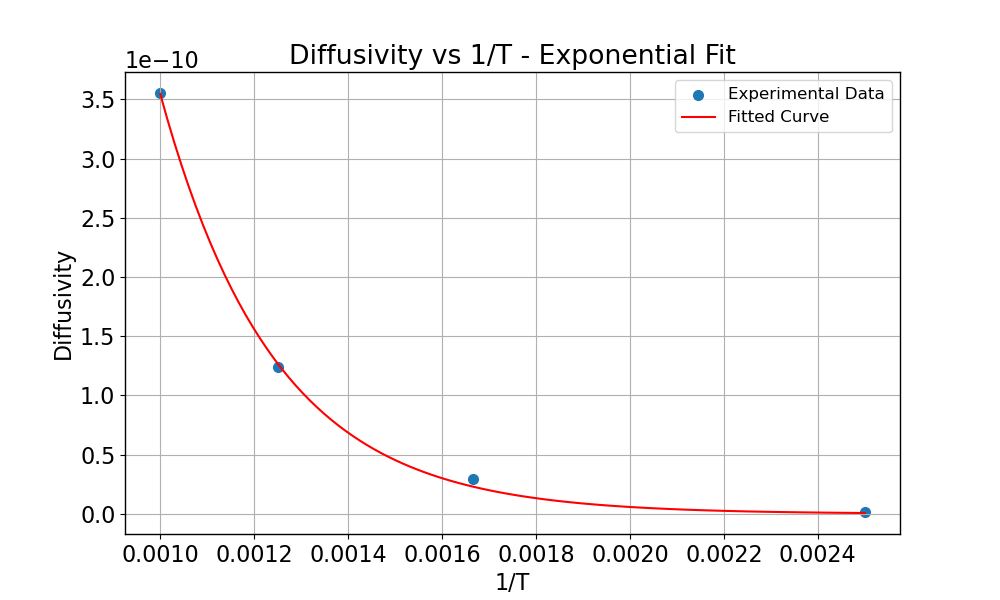

In [102]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Define the exponential function
def exp_func(x, a, b):
    return a * np.exp(b * x)

# Prepare your data
x_data = 1/temp_1  # Reciprocal of temperature
y_data = Na_10_diff_ls  # Diffusivity values

# Perform curve fitting
popt, pcov = curve_fit(exp_func, x_data, y_data, p0=(1, 1))
a_fit, b_fit = popt

# Calculate standard errors
perr = np.sqrt(np.diag(pcov))
a_err, b_err = perr

# Print fitted parameters with their uncertainties
print(f"Fitted Parameters:")
print(f"a = {a_fit:.5f} ± {a_err:.5f}")
print(f"b = {b_fit:.5f} ± {b_err:.5f}")

# Calculate R-squared to assess goodness of fit
residuals = y_data - exp_func(x_data, a_fit, b_fit)
ss_res = np.sum(residuals**2)
ss_tot = np.sum((y_data - np.mean(y_data))**2)
r_squared = 1 - (ss_res / ss_tot)
print(f"R-squared: {r_squared:.5f}")

# Plotting
plt.figure(figsize=(10, 6))
plt.scatter(x_data, y_data, label='Experimental Data')
x_fit = np.linspace(x_data.min(), x_data.max(), 100)
y_fit = exp_func(x_fit, a_fit, b_fit)
plt.plot(x_fit, y_fit, 'r-', label='Fitted Curve')
plt.xlabel('1/T')
plt.ylabel('Diffusivity')
plt.title('Diffusivity vs 1/T - Exponential Fit')
plt.legend()
#plt.xscale('log')
#plt.yscale('log')
plt.grid(True)
plt.show()

In [ ]:
-b_fit*8.617e-5


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Define the exponential function
def exp_func(x, a, b):
    return a * np.exp(b * x)

# Prepare your data
x_data = 1/temp[1:]  # Reciprocal of temperature
y_data = diffusivity_3[:-1]  # Diffusivity values

# Perform curve fitting
popt, pcov = curve_fit(exp_func, x_data, y_data, p0=(1, 1))
a_fit, b_fit = popt

# Calculate standard errors
perr = np.sqrt(np.diag(pcov))
a_err, b_err = perr

# Print fitted parameters with their uncertainties
print(f"Fitted Parameters:")
print(f"a = {a_fit:.5f} ± {a_err:.5f}")
print(f"b = {b_fit:.5f} ± {b_err:.5f}")

# Calculate R-squared to assess goodness of fit
residuals = y_data - exp_func(x_data, a_fit, b_fit)
ss_res = np.sum(residuals**2)
ss_tot = np.sum((y_data - np.mean(y_data))**2)
r_squared = 1 - (ss_res / ss_tot)
print(f"R-squared: {r_squared:.5f}")

# Plotting
plt.figure(figsize=(10, 6))
plt.scatter(x_data, y_data, label='Experimental Data')
x_fit = np.linspace(x_data.min(), x_data.max(), 100)
y_fit = exp_func(x_fit, a_fit, b_fit)
plt.plot(x_fit, y_fit, 'r-', label='Fitted Curve')
plt.xlabel('1/T')
plt.ylabel('Diffusivity')
plt.title('Diffusivity vs 1/T - Exponential Fit')
plt.legend()
plt.xscale('log')
plt.yscale('log')
plt.grid(True)
plt.show()

In [ ]:
Ea = -b_fit*8.617e-5
Ea

In [ ]:
y_fit = exp_func(x_data, *popt)

plt.scatter(x_data, y_data, label="Data", color="blue")
plt.plot(x_data, y_fit, label="Exponential Fit", color="red")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Exponential Fit")
plt.show()

In [ ]:
delta_t_ls = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000,2000,5000]) #1, 2.5, 10, 25, 100, 250 ps

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18,8))
plt.subplots_adjust(wspace=3)

temp = 700

diffusivity_list = []
num_Na_list = []
for index in [2, 4, 6]:
    file = f'./test_training_set/diffusion/{temp}K_in_diffuse_{index}.log'
    log_data = parse_lammps_log_diff(file)
    MSD_Na = np.array(log_data['MSD(Na)'])
    timestep = np.array(log_data['Step'])
    num_Na = int(log_data['v_nNa'][0])
    num_Na_list.append(num_Na)
    t_intival = []
    MSD_intival = []
    for i in range(delta_t_ls.shape[0]):
        #print(i, delta_t_ls[i]*0.5)
        t_intival.append(np.arange(timestep[0], timestep[-1], int(delta_t_ls[i])*500, dtype='int'))
        MSD_intival.append(np.linspace(MSD_Na[0], MSD_Na[-1], t_intival[i].shape[0]))

    delta_t_all = []
    delta_MSD_all = []
    for i in range(delta_t_ls.shape[0]):
        delta_t = []
        delta_MSD = []
        for j in range(t_intival[i].shape[0]-1):
            delta_t.append(t_intival[i][j+1] - t_intival[i][j])
            delta_MSD.append(MSD_intival[i][j+1] - MSD_intival[i][j])
        delta_t_all.append(delta_t)
        delta_MSD_all.append(delta_MSD)

    final_MSD = []
    final_t = []
    diffusivity = []
    for i in range(delta_t_ls.shape[0]):
        final_t.append(sum(delta_t_all[i])/len(delta_t_all[i]))
        final_MSD.append(sum(delta_MSD_all[i])/len(delta_MSD_all[i]))
        
    final_MSD = np.array(final_MSD)
    final_t = np.array(final_t)
    diffusivity_list.append(final_MSD/final_t/6*1e-5)
    
    ax1.plot(final_t, final_MSD, marker='*', markersize=3, label=f'{temp}K SoC = {round(num_Na/4096,3)}')
    
ax1.grid(True, linestyle='--', alpha=0.7)
ax1.legend()
ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_xlabel('delta t (fs)')
ax1.set_ylabel('MSD (A^2)')

for i in range(len(diffusivity_list)):
    plt.plot(final_t, diffusivity_list[i], marker='*', markersize=3, label=f'{temp}K SoC = {round(num_Na_list[i]/4096,3)}')

ax2.grid(True, linestyle='--', alpha=0.7)
ax2.legend()
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_xlabel('delta t (fs)')
ax2.set_ylabel('Diffusivity (m^2/s)')

plt.tight_layout()

In [ ]:
final_t

In [ ]:
for i in range(len(diffusivity_list)):
    plt.plot(diffusivity_list[i], )

In [ ]:
delta_t_ls = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000,2000,5000]) #1, 2.5, 10, 25, 100, 250 ps
fig, ax1 = plt.subplots(figsize=(8, 6))
temp = 600
for index in [2, 4, 6, 8]:
    file = f'./test_training_set/diffusion/{temp}_diffuse_{index}.log'
    log_data = parse_lammps_log_diff(file)
    MSD_Na = np.array(log_data['MSD(Na)'])
    timestep = np.array(log_data['Step'])
    num_Na = int(log_data['v_nNa'][0])
    t_intival = []
    MSD_intival = []
    for i in range(delta_t_ls.shape[0]):
        #print(i, delta_t_ls[i]*0.5)
        t_intival.append(np.arange(timestep[0], timestep[-1], int(delta_t_ls[i])*500, dtype='int'))
        MSD_intival.append(np.linspace(MSD_Na[0], MSD_Na[-1], t_intival[i].shape[0]))

    delta_t_all = []
    delta_MSD_all = []
    for i in range(delta_t_ls.shape[0]):
        delta_t = []
        delta_MSD = []
        for j in range(t_intival[i].shape[0]-1):
            delta_t.append(t_intival[i][j+1] - t_intival[i][j])
            delta_MSD.append(MSD_intival[i][j+1] - MSD_intival[i][j])
        delta_t_all.append(delta_t)
        delta_MSD_all.append(delta_MSD)

    final_MSD = []
    final_t = []
    for i in range(delta_t_ls.shape[0]):
        final_t.append(sum(delta_t_all[i])/len(delta_t_all[i]))
        final_MSD.append(sum(delta_MSD_all[i])/len(delta_MSD_all[i]))
        
    ax1.plot(final_t, final_MSD, marker='*', markersize=3, label=f'{temp}K SoC = {round(num_Na/4096,3)}')
    
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
ax1.legend()
ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_xlabel('delta t (fs)')
ax1.set_ylabel('MSD (A^2)')

In [ ]:
delta_t_ls = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000,2000,5000]) #1, 2.5, 10, 25, 100, 250 ps
fig, ax1 = plt.subplots(figsize=(8, 6))
temp = 700
for index in [2, 4, 6]:
    file = f'./test_training_set/diffusion/{temp}_diffuse_{index}.log'
    log_data = parse_lammps_log_diff(file)
    MSD_Na = np.array(log_data['MSD(Na)'])
    timestep = np.array(log_data['Step'])
    num_Na = int(log_data['v_nNa'][0])
    t_intival = []
    MSD_intival = []
    for i in range(delta_t_ls.shape[0]):
        #print(i, delta_t_ls[i]*0.5)
        t_intival.append(np.arange(timestep[0], timestep[-1], int(delta_t_ls[i])*500, dtype='int'))
        MSD_intival.append(np.linspace(MSD_Na[0], MSD_Na[-1], t_intival[i].shape[0]))

    delta_t_all = []
    delta_MSD_all = []
    for i in range(delta_t_ls.shape[0]):
        delta_t = []
        delta_MSD = []
        for j in range(t_intival[i].shape[0]-1):
            delta_t.append(t_intival[i][j+1] - t_intival[i][j])
            delta_MSD.append(MSD_intival[i][j+1] - MSD_intival[i][j])
        delta_t_all.append(delta_t)
        delta_MSD_all.append(delta_MSD)

    final_MSD = []
    final_t = []
    for i in range(delta_t_ls.shape[0]):
        final_t.append(sum(delta_t_all[i])/len(delta_t_all[i]))
        final_MSD.append(sum(delta_MSD_all[i])/len(delta_MSD_all[i]))
        
    ax1.plot(final_t, final_MSD, marker='*', markersize=3, label=f'{temp}K SoC = {round(num_Na/4096,3)}')
    
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
ax1.legend()
ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_xlabel('delta t (fs)')
ax1.set_ylabel('MSD (A^2)')

In [ ]:
delta_t_ls = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000,2000]) #1, 2.5, 10, 25, 100, 250 ps
fig, ax1 = plt.subplots(figsize=(8, 6))
temp = 800
for index in [2, 4, 6]:
    file = f'./test_training_set/diffusion/{temp}_diffuse_{index}.log'
    log_data = parse_lammps_log_diff(file)
    MSD_Na = np.array(log_data['MSD(Na)'])
    timestep = np.array(log_data['Step'])
    num_Na = int(log_data['v_nNa'][0])
    t_intival = []
    MSD_intival = []
    for i in range(delta_t_ls.shape[0]):
        #print(i, delta_t_ls[i]*0.5)
        t_intival.append(np.arange(timestep[0], timestep[-1], int(delta_t_ls[i])*500, dtype='int'))
        MSD_intival.append(np.linspace(MSD_Na[0], MSD_Na[-1], t_intival[i].shape[0]))

    delta_t_all = []
    delta_MSD_all = []
    for i in range(delta_t_ls.shape[0]):
        delta_t = []
        delta_MSD = []
        for j in range(t_intival[i].shape[0]-1):
            delta_t.append(t_intival[i][j+1] - t_intival[i][j])
            delta_MSD.append(MSD_intival[i][j+1] - MSD_intival[i][j])
        delta_t_all.append(delta_t)
        delta_MSD_all.append(delta_MSD)

    final_MSD = []
    final_t = []
    for i in range(delta_t_ls.shape[0]):
        final_t.append(sum(delta_t_all[i])/len(delta_t_all[i]))
        final_MSD.append(sum(delta_MSD_all[i])/len(delta_MSD_all[i]))
        
    ax1.plot(final_t, final_MSD, marker='*', markersize=3, label=f'{temp}K SoC = {round(num_Na/4096,3)}')
    
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
ax1.legend()
ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_xlabel('delta t (fs)')
ax1.set_ylabel('MSD (A^2)')

In [ ]:
final_t

In [ ]:
delta_t_ls = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]) #1, 2.5, 10, 25, 100, 250 ps
i=6
file = f'./test_training_set/diffusion/600_diffuse_{i}.log'
log_data = parse_lammps_log_diff(file)
MSD_Na = np.array(log_data['MSD(Na)'])
timestep = np.array(log_data['Step'])

In [ ]:
t_intival = []
MSD_intival = []
for i in range(delta_t_ls.shape[0]):
    print(i, delta_t_ls[i]*0.5)
    t_intival.append(np.arange(timestep[0], timestep[-1], int(delta_t_ls[i])*500, dtype='int'))
    MSD_intival.append(np.linspace(MSD_Na[0], MSD_Na[-1], t_intival[i].shape[0]))


In [ ]:
i=0
delta_t_ls.shape[0], t_intival[i].shape[0]-1

In [ ]:
delta_t_all = []
delta_MSD_all = []
for i in range(delta_t_ls.shape[0]):
    delta_t = []
    delta_MSD = []
    for j in range(t_intival[i].shape[0]-1):
        delta_t.append(t_intival[i][j+1] - t_intival[i][j])
        delta_MSD.append(MSD_intival[i][j+1] - MSD_intival[i][j])
    delta_t_all.append(delta_t)
    delta_MSD_all.append(delta_MSD)

In [ ]:
final_MSD = []
final_t = []
for i in range(delta_t_ls.shape[0]):
    final_t.append(sum(delta_t_all[i])/len(delta_t_all[i]))
    final_MSD.append(sum(delta_MSD_all[i])/len(delta_MSD_all[i]))

In [ ]:
fig, ax1 = plt.subplots(figsize=(8, 6))

ax1.plot(final_t, final_MSD,  marker='*', markersize=5)
ax1.set_xlabel('delta t (ps)')
ax1.set_ylabel('MSD (A^2)')
ax1.set_xscale('log')
ax1.set_yscale('log')

# Phase diagrame

## 300K

In [ ]:
for i in range(11):
    file = f'./test_training_set/phase_diagram/300_phase_{i+1}.log'
    plot_log_no_V(file)

## 400K

In [ ]:
for i in range(11):
    file = f'./test_training_set/phase_diagram/400_phase_{i+1}.log'
    plot_log(file)

## 500K

In [ ]:
for i in range(11):
    file = f'./test_training_set/phase_diagram/500_phase_{i+1}.log'
    plot_log(file)

## 600K

In [ ]:
for i in range(11):
    file = f'./test_training_set/phase_diagram/600_phase_{i+1}.log'
    plot_log(file)

## 700K

In [ ]:
for i in range(19):
    file = f'./test_training_set/phase_diagram/700_phase_{i+1}.log'
    plot_log(file)

## 800K

In [ ]:
for i in range(19):
    file = f'./test_training_set/phase_diagram/800_phase_{i+1}.log'
    plot_log(file)

## 900K

In [ ]:
for i in range(19):
    file = f'./test_training_set/phase_diagram/900_phase_{i+1}.log'
    plot_log(file)

## 1000K

In [ ]:
for i in range(19):
    file = f'./test_training_set/phase_diagram/1000_phase_{i+1}.log'
    plot_log(file)

## 1100K

In [ ]:
for i in range(8,19):
    file = f'./test_training_set/phase_diagram/1100_phase_{i+1}.log'
    plot_log(file)

## 1200K

In [ ]:
for i in range(8,19):
    file = f'./test_training_set/phase_diagram/1200_phase_{i+1}.log'
    plot_log(file)

## 1300K

In [ ]:
for i in range(8,19):
    file = f'./test_training_set/phase_diagram/1300_phase_{i+1}.log'
    plot_log(file)

## Na profiles

In [ ]:
def plot_Na_profile(temp, n_1, n_2, mu_1, mu_2):
    fig, ax1 = plt.subplots(figsize=(10, 6))
    temp=temp
    mu_1, mu_2, step = mu_1, mu_2, 0.05
    for i in range(n_1, n_2):
        file = f'./test_training_set/phase_diagram/{temp}_phase_{i+1}.log'
        log_data = parse_lammps_log(file)
     
        E_Na = -.14023100E+01
        my_list = log_data['TotEng'][20:40]
        E_i = sum(my_list) / len(my_list)
        my_list = log_data['TotEng'][-20:]
        E_f = sum(my_list) / len(my_list)
        my_list = log_data['v_nNa'][20:40]
        n_Na_i = sum(my_list) / len(my_list)
        my_list = log_data['v_nNa'][-20:]
        n_Na_f = sum(my_list) / len(my_list)   
        n_Na = n_Na_i-n_Na_f
        V_ave = -(E_i-E_f-n_Na*E_Na)/n_Na
        
        ax1.plot(log_data['Step'], log_data['v_nNa'], color=cm.jet((i-n_1)/n_2), label=f'mu_{i+1} = {round(np.arange(mu_1, mu_2+step, step)[i],2)}  V = {round(V_ave,2)}')#, marker='*')
    
    
    #ax1.hlines(512,0,3e6, linestyle='--', color='black')
    #ax1.hlines(0,0,3e6, linestyle='--', color='black')
    
    ax1.set_xlabel('Timestep (0.4 fs/step)')
    ax1.set_ylabel('Number of Na+')
    #ax1.set_xlim(0,3e6)
    plt.title(f'{temp} K  mu = {mu_1} ~ {mu_2}')
    #ax1.tick_params(axis='y', labelcolor=color)
    #ax1.set_ylim(-5,515)
    ax1.legend()
    plt.grid()

In [ ]:
plot_Na_profile(300)

In [ ]:
plot_Na_profile(400)

In [ ]:
plot_Na_profile(500)

In [ ]:
plot_Na_profile(600)

In [ ]:
plot_Na_profile(700, 0, 19, -2.2, -1.3)

In [ ]:
plot_Na_profile(800, 0, 19, -2.2, -1.3)

In [ ]:
plot_Na_profile(900, 0, 19, -2.2, -1.3)

In [ ]:
plot_Na_profile(1000, 0, 19, -2.2, -1.3)

In [ ]:
plot_Na_profile(1100, 0, 19, -2.2, -1.3)

In [ ]:
plot_Na_profile(1200, 8, 19, -2.2, -1.3)

In [ ]:
plot_Na_profile(1300, 8, 19, -2.2, -1.3)

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 6))
temp=300
mu_1, mu_2, step = -2.2, -1.7, 0.05
for i in range(11):
    file = f'./test_training_set/phase_diagram/{temp}_phase_{i+1}.log'
    log_data = parse_lammps_log(file)
 
    E_Na = -.14023100E+01
    my_list = log_data['TotEng'][20:40]
    E_i = sum(my_list) / len(my_list)
    my_list = log_data['TotEng'][-20:]
    E_f = sum(my_list) / len(my_list)
    my_list = log_data['v_nNa'][20:40]
    n_Na_i = sum(my_list) / len(my_list)
    my_list = log_data['v_nNa'][-20:]
    n_Na_f = sum(my_list) / len(my_list)   
    n_Na = n_Na_i-n_Na_f
    V_ave = -(E_i-E_f-n_Na*E_Na)/n_Na
    
    ax1.plot(log_data['Step'], log_data['v_nNa'], color=cm.jet(i/11), label=f'mu_{i+1} = {round(np.arange(mu_1, mu_2+step, step)[i],2)}  V = {round(V_ave,2)}')#, marker='*')


#ax1.hlines(512,0,3e6, linestyle='--', color='black')
#ax1.hlines(0,0,3e6, linestyle='--', color='black')

ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')
#ax1.set_xlim(0,3e6)
plt.title(f'{temp} K  mu = {mu_1} ~ {mu_2}')
#ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(-5,515)
ax1.legend()
plt.grid()

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 6))
temp=400
mu_1, mu_2, step = -2.2, -1.7, 0.05
for i in range(11):
    file = f'./test_training_set/phase_diagram/{temp}_phase_{i+1}.log'
    log_data = parse_lammps_log(file)
 
    E_Na = -.14023100E+01
    my_list = log_data['TotEng'][20:40]
    E_i = sum(my_list) / len(my_list)
    my_list = log_data['TotEng'][-20:]
    E_f = sum(my_list) / len(my_list)
    my_list = log_data['v_nNa'][20:40]
    n_Na_i = sum(my_list) / len(my_list)
    my_list = log_data['v_nNa'][-20:]
    n_Na_f = sum(my_list) / len(my_list)   
    n_Na = n_Na_i-n_Na_f
    V_ave = -(E_i-E_f-n_Na*E_Na)/n_Na
    
    ax1.plot(log_data['Step'], log_data['v_nNa'], color=cm.jet(i/11), label=f'mu_{i+1} = {round(np.arange(mu_1, mu_2+step, step)[i],2)}  V = {round(V_ave,2)}')#, marker='*')


#ax1.hlines(512,0,3e6, linestyle='--', color='black')
#ax1.hlines(0,0,3e6, linestyle='--', color='black')

ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')
#ax1.set_xlim(0,3e6)
plt.title(f'{temp} K  mu = {mu_1} ~ {mu_2}')
#ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(-5,515)
ax1.legend()
plt.grid()

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 6))
temp=500
mu_1, mu_2, step = -2.2, -1.7, 0.05
for i in range(11):
    file = f'./test_training_set/phase_diagram/{temp}_phase_{i+1}.log'
    log_data = parse_lammps_log(file)
 
    E_Na = -.14023100E+01
    my_list = log_data['TotEng'][20:40]
    E_i = sum(my_list) / len(my_list)
    my_list = log_data['TotEng'][-20:]
    E_f = sum(my_list) / len(my_list)
    my_list = log_data['v_nNa'][20:40]
    n_Na_i = sum(my_list) / len(my_list)
    my_list = log_data['v_nNa'][-20:]
    n_Na_f = sum(my_list) / len(my_list)   
    n_Na = n_Na_i-n_Na_f
    V_ave = -(E_i-E_f-n_Na*E_Na)/n_Na
    
    ax1.plot(log_data['Step'], log_data['v_nNa'], color=cm.jet(i/11), label=f'mu_{i+1} = {round(np.arange(mu_1, mu_2+step, step)[i],2)}  V = {round(V_ave,2)}')#, marker='*')


ax1.hlines(512,0,3e6, linestyle='--', color='black')
ax1.hlines(0,0,3e6, linestyle='--', color='black')

ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')
ax1.set_xlim(0,3e6)
plt.title(f'{temp} K  mu = {mu_1} ~ {mu_2}')
#ax1.tick_params(axis='y', labelcolor=color)
#ax1.set_xlim(0,1e6)
ax1.legend()
plt.grid()

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 6))
temp=600
mu_1, mu_2, step = -2.2, -1.7, 0.05
for i in range(11):
    file = f'./test_training_set/phase_diagram/{temp}_phase_{i+1}.log'
    log_data = parse_lammps_log(file)
 
    E_Na = -.14023100E+01
    my_list = log_data['TotEng'][20:40]
    E_i = sum(my_list) / len(my_list)
    my_list = log_data['TotEng'][-20:]
    E_f = sum(my_list) / len(my_list)
    my_list = log_data['v_nNa'][20:40]
    n_Na_i = sum(my_list) / len(my_list)
    my_list = log_data['v_nNa'][-20:]
    n_Na_f = sum(my_list) / len(my_list)   
    n_Na = n_Na_i-n_Na_f
    V_ave = -(E_i-E_f-n_Na*E_Na)/n_Na
    
    ax1.plot(log_data['Step'], log_data['v_nNa'], color=cm.jet(i/11), label=f'mu_{i+1} = {round(np.arange(mu_1, mu_2+step, step)[i],2)}  V = {round(V_ave,2)}')#, marker='*')


#ax1.hlines(512,0,3e6, linestyle='--', color='black')
#ax1.hlines(0,0,3e6, linestyle='--', color='black')

ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')
#ax1.set_xlim(0,3e6)
plt.title(f'{temp} K  mu = {mu_1} ~ {mu_2}')
#ax1.tick_params(axis='y', labelcolor=color)
#ax1.set_xlim(0,1e6)
ax1.legend()
plt.grid()

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 6))
temp=400
mu_1, mu_2, step = -2.2, -1.7, 0.05
for i in range(11):
    file = f'./test_training_set/phase_diagram/{temp}_phase_{i+1}.log'
    log_data_nbh = parse_lammps_log(file)
    ax1.plot(log_data_nbh['Step'], log_data_nbh['v_nNa'], color=cm.jet(i/11), label=f'mu = {round(np.arange(mu_1, mu_2+step, step)[i],2)}')#, marker='*')

#ax1.hlines(512,0,3e6, linestyle='--', color='black')
#ax1.hlines(0,0,3e6, linestyle='--', color='black')

ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')
#ax1.set_xlim(0,3e6)
plt.title(f'{temp} K  mu = {mu_1} ~ {mu_2}')
#ax1.tick_params(axis='y', labelcolor=color)
#ax1.set_xlim(0,1e6)
ax1.legend()
plt.grid()

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 6))
temp=500
mu_1, mu_2, step = -2.2, -1.7, 0.05
for i in range(11):
    file = f'./test_training_set/phase_diagram/{temp}_phase_{i+1}.log'
    log_data_nbh = parse_lammps_log(file)
    ax1.plot(log_data_nbh['Step'], log_data_nbh['v_nNa'], color=cm.jet(i/11), label=f'mu = {round(np.arange(mu_1, mu_2+step, step)[i],2)}')#, marker='*')

#ax1.hlines(512,0,3e6, linestyle='--', color='black')
#ax1.hlines(0,0,3e6, linestyle='--', color='black')

ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')
#ax1.set_xlim(0,3e6)
plt.title(f'{temp} K  mu = {mu_1} ~ {mu_2}')
#ax1.tick_params(axis='y', labelcolor=color)
#ax1.set_xlim(0,1e6)
ax1.legend()
plt.grid()

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 6))
temp=600
mu_1, mu_2, step = -2.2, -1.7, 0.05
for i in range(7):
    file = f'./test_training_set/phase_diagram/{temp}_phase_{i+1}.log'
    log_data_nbh = parse_lammps_log(file)
    ax1.plot(log_data_nbh['Step'], log_data_nbh['v_nNa'], color=cm.jet(i/11), label=f'mu = {round(np.arange(mu_1, mu_2+step, step)[i],2)}')#, marker='*')

#ax1.hlines(512,0,3e6, linestyle='--', color='black')
#ax1.hlines(0,0,3e6, linestyle='--', color='black')

ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')
#ax1.set_xlim(0,3e6)
plt.title(f'{temp} K  mu = {mu_1} ~ {mu_2}')
#ax1.tick_params(axis='y', labelcolor=color)
#ax1.set_xlim(0,1e6)
ax1.legend()
plt.grid()

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 6))
temp=700
mu_1, mu_2, step = -2.2, -1.7, 0.05
for i in range(11):
    file = f'./test_training_set/phase_diagram/{temp}_phase_{i+1}.log'
    log_data_nbh = parse_lammps_log(file)
    ax1.plot(log_data_nbh['Step'], log_data_nbh['v_nNa'], color=cm.jet(i/11), label=f'mu = {round(np.arange(mu_1, mu_2+step, step)[i],2)}')#, marker='*')

#ax1.hlines(512,0,3e6, linestyle='--', color='black')
#ax1.hlines(0,0,3e6, linestyle='--', color='black')

ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')
#ax1.set_xlim(0,3e6)
plt.title(f'{temp} K  mu = {mu_1} ~ {mu_2}')
#ax1.tick_params(axis='y', labelcolor=color)
#ax1.set_xlim(0,1e6)
ax1.legend()
plt.grid()

In [ ]:
np.arange(mu_2-2*step, mu_2, step)

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 6))
temp=300
mu_1, mu_2, step = -2, -1, 0.1
for i in range(11,22):
    file = f'./test_training_set/phase_diagram/{temp}_phase_{i+1}.log'
    log_data_nbh = parse_lammps_log(file)
    ax1.plot(log_data_nbh['Step'], log_data_nbh['v_nNa'], color=cm.jet((i-11)/11), label=f'mu = {round(np.arange(mu_1, mu_2+step, step)[i-11],2)}')#, marker='*')

ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')
plt.title(f'{temp} K  mu = {mu_1} ~ {mu_2}')
#ax1.tick_params(axis='y', labelcolor=color)
#ax1.set_xlim(0,1e6)
ax1.legend()
plt.grid()

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 6))
temp=350
mu_1, mu_2, step = -3, -2, 0.1
for i in range(11):
    file = f'./test_training_set/phase_diagram/{temp}_phase_{i+1}.log'
    log_data_nbh = parse_lammps_log(file)
    ax1.plot(log_data_nbh['Step'], log_data_nbh['v_nNa'], color=cm.jet(i/11), label=f'mu = {round(np.arange(mu_1, mu_2+step, step)[i],2)}')#, marker='*')

ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')
plt.title(f'{temp} K  mu = {mu_1} ~ {mu_2}')
#ax1.tick_params(axis='y', labelcolor=color)
#ax1.set_xlim(0,1e6)
ax1.legend()
plt.grid()

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 6))
temp=400
mu_1, mu_2, step = -3, -2, 0.1
for i in range(11):
    file = f'./test_training_set/phase_diagram/{temp}_phase_{i+1}.log'
    log_data_nbh = parse_lammps_log(file)
    ax1.plot(log_data_nbh['Step'], log_data_nbh['v_nNa'], color=cm.jet(i/11), label=f'mu = {round(np.arange(mu_1, mu_2+step, step)[i],2)}')#, marker='*')

ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')
plt.title(f'{temp} K  mu = {mu_1} ~ {mu_2}')
#ax1.tick_params(axis='y', labelcolor=color)
#ax1.set_xlim(0,1e6)
ax1.legend()
plt.grid()

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 6))
temp=450
mu_1, mu_2, step = -3, -2, 0.1
for i in range(11):
    file = f'./test_training_set/phase_diagram/{temp}_phase_{i+1}.log'
    log_data_nbh = parse_lammps_log(file)
    ax1.plot(log_data_nbh['Step'], log_data_nbh['v_nNa'], color=cm.jet(i/11), label=f'mu = {round(np.arange(mu_1, mu_2+step, step)[i],2)}')#, marker='*')

ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')
plt.title(f'{temp} K  mu = {mu_1} ~ {mu_2}')
#ax1.tick_params(axis='y', labelcolor=color)
#ax1.set_xlim(0,1e6)
ax1.legend()
plt.grid()

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 6))
temp=500
mu_1, mu_2, step = -3, -2, 0.1
for i in range(11):
    file = f'./test_training_set/phase_diagram/{temp}_phase_{i+1}.log'
    log_data_nbh = parse_lammps_log(file)
    ax1.plot(log_data_nbh['Step'], log_data_nbh['v_nNa'], color=cm.jet(i/11), label=f'mu = {round(np.arange(mu_1, mu_2+step, step)[i],2)}')#, marker='*')

ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Number of Na+')
plt.title(f'{temp} K  mu = {mu_1} ~ {mu_2}')
#ax1.tick_params(axis='y', labelcolor=color)
#ax1.set_xlim(0,1e6)
ax1.legend()
plt.grid()

In [ ]:
for i in range(len(data)-1):
    delta_r_square_1.append(abs(data['c_msd_Na[4]'].iloc[i+1]-data['c_msd_Na[4]'].iloc[i]))
for i in range(0, len(data)-1, 2):
    delta_r_square_2.append(abs(data['c_msd_Na[4]'].iloc[i+1]-data['c_msd_Na[4]'].iloc[i]))
for i in range(0, len(data)-1, 100):
    delta_r_square_5.append(abs(data['c_msd_Na[4]'].iloc[i+1]-data['c_msd_Na[4]'].iloc[i]))

In [ ]:
for i in range(8,16):
    file = f'./test_training_set/in_diffuse_{i+1}.log'
    plot_log_diff(file)

In [ ]:
num_Na_ls/512

In [ ]:
num_Na_ls = np.array([101.0, 143.0, 194.0, 243.0, 284.0, 410.0, 449.0, 494.0])*8
p1, p2 = 4,8
for i in range(p1, p2):
    filename = f'600K_msd_Na_{i+1}.dat'
    path = './test_training_set/'
    data = pd.read_csv(path + filename, delim_whitespace=True, comment='#', header=None)
    data.columns = ['TimeStep', 'c_msd_Na[1]', 'c_msd_Na[2]', 'c_msd_Na[3]', 'c_msd_Na[4]']
    plt.figure(figsize=(8,5))
    plt.plot(data['TimeStep'], data['c_msd_Na[1]']*num_Na_ls[i-p1], label='MSD(x)')
    plt.plot(data['TimeStep'], data['c_msd_Na[2]']*num_Na_ls[i-p1], label='MSD(y)')
    plt.plot(data['TimeStep'], data['c_msd_Na[3]']*num_Na_ls[i-p1], label='MSD(z)')
    plt.plot(data['TimeStep'], data['c_msd_Na[4]']*num_Na_ls[i-p1], label='TMSD')
    plt.legend()
    plt.xlabel('Timestep (1 fs/step)')
    plt.ylabel('MSD (A^2)')
    plt.title(filename+ f'  {int(num_Na_ls[i-p1])} Na+')


In [ ]:
# Path to your LAMMPS log file
i=4
log_file_path = f'./test_almtp_lv20/gcmc_{i}.log'
#log_file_path = 'gcmc_3.log'
log_data = parse_lammps_log(log_file_path)

#E_Na = -.13023100E+01
#V_ave = -(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.4 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 80)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
#plt.title(log_file_path+f'    Average V = {round(V_ave,3)}')
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


In [ ]:
i=5
file = f'./test_almtp_lv20/gcmc_{i}.log'
plot_log(file)

In [ ]:
for i in range(4):
    file = f'./test_almtp_stress/gcmc_{i+1}.log'
    plot_log(file)

In [ ]:
plot_log('gcmc_3.log')

In [ ]:
plot_log('gcmc_2.log')

In [ ]:
plot_log('gcmc_2.log')

In [ ]:
plot_log('gcmc_2.log')

In [ ]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_6_497.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)
E_Na = -.13023100E+01
V_ave = -(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])
V_ave

In [ ]:
log_data['TotEng'][-1],log_data['v_nNa'][-1],log_data['Volume'][-1]

In [ ]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_3_488.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)
E_Na = -.13023100E+01
V_ave = -(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])
V_ave

In [ ]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_2_466.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)
E_Na = -.13023100E+01
V_ave = -(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])
V_ave

In [ ]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_4_468.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


In [ ]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_235.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


In [ ]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_257.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


In [ ]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_274.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


In [ ]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_279.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


In [ ]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_288.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


In [ ]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_321.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


In [ ]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_331.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


In [ ]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_332.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)


In [ ]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_340.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)


E_Na = -.13023100E+01
V_ave = -(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])
V_ave

In [ ]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_356.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)

E_Na = -.13023100E+01
V_ave = -(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])
V_ave

In [ ]:
# Path to your LAMMPS log file
log_file_path = './pot_save/gcmc_419.log'
log_data = parse_lammps_log(log_file_path)

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot RMS(E/atom) on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Timestep (0.1 fs/step)')
ax1.set_ylabel('Total E (eV)', color=color)
ax1.plot(log_data['Step'], log_data['TotEng'], color=color, marker='o', markersize=3)
ax1.tick_params(axis='y', labelcolor=color)

# Create the second y-axis and plot RMS(f)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Volume (A^3)', color=color)
ax2.plot(log_data['Step'][10:], log_data['Volume'][10:], color=color, marker='s', markersize=3)
ax2.tick_params(axis='y', labelcolor=color)

ax3 = ax1.twinx()
color = 'tab:green'
ax3.spines['right'].set_position(('outward', 60)) 
ax3.set_ylabel('Number of Na+', color=color)
ax3.plot(log_data['Step'], log_data['v_nNa'], color=color, marker='*')
ax3.tick_params(axis='y', labelcolor=color)
plt.grid()
plt.title(log_file_path)
#plt.xlim(10000,30000)
#ax1.set_ylim(-31500, -31000)
#ax2.set_ylim(54000,59000)

E_Na = -.13023100E+01
V_ave = -(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])
V_ave



In [ ]:
E_Na = -0.14023
V_ave = -(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])
V_ave

In [ ]:
E_Na = -0.14023
V_ave = -(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])
V_ave

In [ ]:
E_Na = -0.14023
V_ave = -(log_data['TotEng'][20]-log_data['TotEng'][-1]-(log_data['v_nNa'][20]-log_data['v_nNa'][-1])*E_Na)/(log_data['v_nNa'][20]-log_data['v_nNa'][-1])
V_ave

In [ ]:
log_data['v_nNa'][-1]

In [ ]:
x = int((log_data['Step'][-1]-5000)/4000)
a = range(0,x*20,20)

In [ ]:
len(a)

In [ ]:
i=1
log_data['Step'][a[i]-1], log_data['Step'][a[i+1]-1]

In [ ]:
i
log_data['v_nNa'][a[i]] - log_data['v_nNa'][a[i+1]]

In [ ]:
x = int((log_data['Step'][-1]-5000)/4000)
a = range(0,x*20,20)
V = []
E_Na = -.13023100E+01

for i in range(len(a)-1):
    delta_Na = log_data['v_nNa'][a[i]] - log_data['v_nNa'][a[i+1]]
    delta_E =  log_data['TotEng'][a[i]-1] - log_data['TotEng'][a[i+1]-1]
    V.append(-(delta_E-delta_Na*E_Na)/delta_Na)

In [ ]:
V

In [ ]:
fig = plt.figure(figsize=(10, 6))

plt.plot(range(len(V)-1), V[1:])
#plt.xlim(40,300)
plt.ylabel('Voltage')
plt.xlabel('Number of Na (512 Na originally)')
plt.title('')
plt.grid()
#plt.text(50,5, f'Average V = {round(np.mean(V[5:50]),3)}')
#plt.xlim(512,480)
#plt.savefig('desodiation_V.png', dpi=300, bbox_inches='tight')

In [ ]:
np.mean(V[1:])

In [ ]:
log_data['TotEng'][20],log_data['TotEng'][-1],log_data['v_nNa'][20],log_data['v_nNa'][-1]